# Exploratory comparison between semantic embeddings and TF-IDF
## Alignment profiles with the Smart City dimensions — Municipality of Porto

**Author:** Fatima Zahra Rbaibi

This notebook implements an exploratory and reproducible analysis of the alignment between the metadata of municipal datasets and six Smart City dimensions defined *a priori* by anchor texts. It compares a semantic representation based on *sentence embeddings* with a lexical TF-IDF representation, assesses sensitivity to four versions of the anchors and explores the structure of the corpus through clustering.

> **Scope of the conclusions.** In the absence of a reference set annotated by human experts (gold standard), the metrics in this notebook assess coverage, separation of the scores, agreement between methods and stability across versions. They do not, by themselves, measure accuracy, substantive validity or the probability of a classification being correct. The terms “confidence” and “robustness” are used only as internal and relative descriptors.

### Structure of the notebook and correspondence with the dissertation

| Notebook section | Content | Dissertation |
|---|---|---|
| 1. Configuration (1.1 spaCy; 1.2 recording the environment) | Libraries, paths, parameters, versions used | 3.1, 3.6 |
| 2. Helper functions | Text pipelines, classification, relative delta bands | 3.3, 3.4 |
| 3. Validation of the input files | Existence and structure of the files | 3.3 |
| 4. Pre-processing (4.2 anchors) | Texts of the datasets and of the four anchor versions | 3.2, 3.3.1 |
| 5. Embedding model (5.1 token limit) | Loading the model; truncation check | 3.3.2 |
| 6. Classification | Scores, top-1, top-2, delta, bands, agreement between methods | 3.4, 3.4.1 · 4.2, 4.3 (RQ1, RQ2) |
| 7.1–7.9 Analysis by version | Results by version, stability across versions, distributions, delta bands, agreement matrices, score profiles, entropy, extreme cases, TF-IDF without classification | 3.4.2, 3.4.3 · 4.3, 4.4, 4.5 (RQ2–RQ4) |
| 7.10 Post-argmax rule (four versions) | States, automatic triage for future review, sensitivity to the parameters | 3.5.1 · 4.5 (RQ4) |
| 8. Instability across versions | Datasets that change dimension | 3.4.2 · 4.4 (RQ3) |
| 9. Semantic clustering | Most similar pairs, choice of k, clusters, terms, PCA | 3.5.2 · 4.6 (RQ5) |
| 10. Clusters × dimensions (four versions) | Contingency tables and modal dimensions | 3.5.2 · 4.6 (RQ5) |
| 11. Export | Results Excel file | 3.6 |
| 12–13. Conclusion and references | — | — |

All analyses that depend on the anchors are carried out for the four versions (original, 50, 100 and 150 words). The comparison between Águeda and Porto (RQ6, Section 4.7) is made from the files exported by the two notebooks, which have the same structure.
> **Historical reading.** This run uses direct encoding and may truncate texts above 128 tokens. It serves as a reference for quantifying the effect of the correction applied in notebook 03; it is not the main result.

> **Terminology.** The matrices cross the results of two methods without reference labels. The review lists are produced automatically as candidates for future work; no human validation was carried out in this dissertation.


## 1. Imports, general configuration and thread control

This section loads the libraries and defines the global parameters. On Windows with Conda/Miniforge environments, NumPy/scikit-learn and PyTorch may load different OpenMP runtimes. To avoid the KMeans memory leak warning with MKL and reduce the risk of conflict, the notebook limits the numerical libraries to one thread **before any scientific import**.

> After changing or updating this cell, it is mandatory to run **Kernel → Restart & Run All**. Running it in a kernel where NumPy, scikit-learn or PyTorch have already been imported does not unload the OpenMP libraries loaded previously.

In [1]:
# ── Imports and parallelism control ─────────────────────────────────────────
import os

# Mitigation for Windows + MKL/OpenMP. These variables must be set
# BEFORE importing NumPy, scikit-learn, PyTorch or Sentence Transformers.
# They avoid the known KMeans memory problem with MKL and reduce the risk
# of conflict when libiomp and libomp coexist in the same Conda environment.
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
os.environ["LOKY_MAX_CPU_COUNT"] = "1"

import re
import unicodedata
import warnings
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    cohen_kappa_score,
    confusion_matrix,
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from scipy.stats import entropy as scipy_entropy

from sentence_transformers import SentenceTransformer

import spacy

warnings.filterwarnings("default")
# The warning about duplicate OpenMP runtimes is environmental. The filter is limited
# to the RuntimeWarning issued by threadpoolctl; all other warnings are kept.
warnings.filterwarnings(
    "ignore",
    category=RuntimeWarning,
    module=r"threadpoolctl(?:\..*)?",
)
warnings.filterwarnings(
    "ignore",
    message=r".*KMeans is known to have a memory leak on Windows with MKL.*",
    category=UserWarning,
    module=r"sklearn\.cluster\._kmeans",
)
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.max_columns", 200)

print("Libraries imported successfully.")

C:\Users\paulo\.conda\envs\dissertacao_fr\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Libraries imported successfully.


> **Single editing point.** Change only this cell to adapt the notebook to new data or to a new municipality.

In [2]:
# ── General settings ─────────────────────────────────────────────────────────

# Reprodutibilidade 
SEED = 42
np.random.seed(SEED)

# ── Paths ───────────────────────────────────────────────────────────────────
PROJECT_DIR = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / "environment.yaml").is_file()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Open the project from the repository root or from the notebooks/porto/ folder.")
import sys
sys.path.insert(0, str(PROJECT_DIR))
from scripts.reproducibility import save_manifest, validate_comparison
# Looks first for a data/ subfolder; if the files have been placed
# next to the notebook, the current working folder is used.
DATA_DIR = PROJECT_DIR / "data"
if not DATA_DIR.exists():
    DATA_DIR = PROJECT_DIR

def resolve_input(filename: str) -> Path:
    """Resolves the canonical name or the variant with the suffix (1)."""
    canonical = DATA_DIR / filename
    duplicate = DATA_DIR / f"{Path(filename).stem}(1){Path(filename).suffix}"
    if canonical.exists():
        return canonical
    if duplicate.exists():
        return duplicate
    return canonical  # the validation cell will show the missing path

OUTPUT_DIR  = PROJECT_DIR / "outputs/porto/01_pre_chunking"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Input files ──────────────────────────────────────────────────────────────
DATASETS_CSV = resolve_input("porto_tabela_mae_datasets.csv")

ANCHOR_FILES = {
    "original"    : resolve_input("texto_base.csv"),
    "50_words" : resolve_input("ancoras_v1_50_palavras.csv"),
    "100_words": resolve_input("ancoras_v2_100_palavras.csv"),
    "150_words": resolve_input("ancoras_v3_150_palavras.csv"),
}

# ── Outputs ───────────────────────────────────────────────────────────────────
OUT_EXCEL = OUTPUT_DIR / "results_smart_cities_porto.xlsx"

# ── Embedding model ───────────────────────────────────────────────────────────
MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
MODEL_REVISION = "e8f8c211226b894fcb81acc59f3b34ba3efd5f42"  # immutable revision on Hugging Face
MODEL_DEVICE = "cpu"  # reference for numerical reproduction

# ── spaCy model for lemmatisation (TF-IDF pipeline) ───────────────────────────
# Change here if you have another model installed (e.g. "pt_core_news_md", "pt_core_news_lg").
# Larger models (md/lg) have richer word vectors and slightly better
# morphological disambiguation, but lemmatisation itself — which is what
# matters for TF-IDF — is similar across the three sizes.
SPACY_MODEL_NAME = "pt_core_news_sm"

# ── Dimension labels ─────────────────────────────────────────────────────────
# The anchor files name the six dimensions in Portuguese; the names are mapped to
# English labels when the anchors are loaded (Section 3). DIMENSION_SORT_ORDER keeps
# the column order of the original analysis (alphabetical order of the Portuguese
# names), so that the results, including any ties in the argmax, are identical.
DIM_EN = {
    "Governança Inteligente"       : "Smart Governance",
    "Sociedade Inteligente"        : "Smart Society",
    "Mobilidade Inteligente"       : "Smart Mobility",
    "Ambiente Inteligente"         : "Smart Environment",
    "Qualidade De Vida Inteligente": "Smart Quality of Life",
    "Economia Inteligente"         : "Smart Economy",
}
DIMENSION_SORT_ORDER = ["Smart Environment", "Smart Economy", "Smart Governance",
                        "Smart Mobility", "Smart Quality of Life", "Smart Society"]

def dim_sort_key(dim):
    """Position of a dimension label in DIMENSION_SORT_ORDER."""
    return DIMENSION_SORT_ORDER.index(dim) if dim in DIMENSION_SORT_ORDER else len(DIMENSION_SORT_ORDER)

def dim_col_key(col):
    """Sort key for score columns such as 'score_emb_Smart Economy'."""
    pos = next((i for i, d in enumerate(DIMENSION_SORT_ORDER) if col.endswith(d)), len(DIMENSION_SORT_ORDER))
    return (pos, col)

# ── Relative delta bands (percentiles; they are not probabilities) ────────────
# Computed automatically after classification — see cell 10 (confidence_label)
# Percentile 66 → "high" threshold; Percentile 33 → "medium" threshold
DELTA_PERCENTILE_HIGH  = 66   # delta percentile for the "high" confidence level
DELTA_PERCENTILE_MEDIUM = 33   # delta percentile for the "medium" confidence level

# ── TF-IDF parameters for classification ─────────────────────────────────────
TFIDF_VECTORIZER_PARAMS = {
    "max_features" : 5000,
    "min_df"       : 1,
    "max_df"       : 0.90,
    "ngram_range"  : (1, 2),
    "sublinear_tf" : True,
    "token_pattern": r"(?u)\b[a-zA-ZÀ-ÿ]{3,}\b",
}

# ── TF-IDF parameters for interpreting the clusters ──────────────────────────
TFIDF_CLUSTER_PARAMS = {
    "max_features" : 1000,
    "min_df"       : 1,
    "max_df"       : 0.80,
    "ngram_range"  : (1, 2),
    "sublinear_tf" : True,
    "token_pattern": r"(?u)\b[a-zA-ZÀ-ÿ]{3,}\b",
}

# ── Clustering ────────────────────────────────────────────────────────────────
MAX_K_CLUSTERS = 10          # maximum value to explore
K_CLUSTERS     = None        # None → automatic choice by silhouette

# ── Anchor versions ──────────────────────────────────────────────────────────
# All analyses that depend on the anchors (classification, score profiles,
# post-argmax rule and cluster-dimension relationship) are carried out for the FOUR versions
# defined in ANCHOR_FILES. There is no reference version: the versions are
# alternative operationalisations used to assess the sensitivity of the
# results, not candidates for a "better" version.

# ── Technical checks (environment and truncation) ────────────────────────────
VERIF_DIR = OUTPUT_DIR / "checks"
VERIF_DIR.mkdir(parents=True, exist_ok=True)
SUFFIX = OUT_EXCEL.stem.replace("results_smart_cities_", "")   # "agueda" / "porto"

# ── Exploratory post-argmax rule ─────────────────────────────────────────────
MIN_WORDS = 8
PERCENTILE_WEAK_SCORE = 5
PERCENTILE_CLOSE_MARGIN = 25
PERCENTILE_DIFFUSE_RANGE = 25

# ── Plot style (uniform across all plots) ────────────────────────────────────
# Sober palette, checked for readability by people with colour blindness (fixed order:
# the colour follows the category, never the position). The methods always have the same colour;
# the anchor versions use grey (original) + a ramp of purples (50→150).
# PORTO PALETTE: purple/orange, distinct from Águeda's (blue/green), so that the
# figures of the two municipalities can be told apart in the dissertation. The six dimensions
# keep the same colours in both notebooks, so that they are comparable.
from cycler import cycler
import textwrap

EMB_COLOUR      = "#6A4C9C"   # Embeddings (purple)
TFIDF_COLOUR    = "#C47A3A"   # TF-IDF (soft orange)
REF_COLOUR      = "#3D3D3D"   # reference lines: thresholds, percentiles, means
NEUTRAL_COLOUR   = "#8A8F98"   # grey: neutral categories / unclassified
HIGHLIGHT_COLOUR = "#B5545C"   # soft pinkish red: flagged cases / outlines
from matplotlib.colors import LinearSegmentedColormap
# Softened orange ramp (matplotlib's "Oranges" is too bright in the middle tones)
CMAP_EMB = "Purples"
CMAP_TFIDF = LinearSegmentedColormap.from_list(
    "soft_oranges", ["#FBF5EF", "#EBC9A8", "#D49A66", "#B06A30", "#6E3F17"])
CATEGORICAL_PALETTE = ["#2F6DB0", "#C0714F", "#2A9A7E", "#7C5CB8", "#C2577F", "#7D8A3C"]
VERSION_COLOURS = {
    "original"    : "#8A8F98",
    "50_words" : "#B39AE0",
    "100_words": "#8E6CC8",
    "150_words": "#5E3C99",
}
CONFIDENCE_COLOURS = {"Null": "#C9CCD1", "Low": "#B39AE0", "Medium": "#8E6CC8", "High": "#5E3C99"}
MARKERS = ["o", "s", "^", "D", "v", "P"]
LABEL_WIDTH = 14   # maximum number of characters per line in the horizontal-axis labels

def format_x_labels(ax, width_chars=LABEL_WIDTH):
    """Categorical labels of the horizontal axis set horizontally (0°), centred;
    long labels are split over several lines so that they do not overlap."""
    tick_labels = [textwrap.fill(t.get_text(), width_chars) for t in ax.get_xticklabels()]
    ax.set_xticks(ax.get_xticks())
    ax.set_xticklabels(tick_labels, rotation=0, ha="center")

def horizontal_y_labels(ax):
    for tick_label in ax.get_yticklabels():
        tick_label.set_rotation(0)

plt.rcParams.update({
    "axes.prop_cycle"   : cycler(color=CATEGORICAL_PALETTE),
    "axes.spines.top"   : False,
    "axes.spines.right" : False,
    "axes.titleweight"  : "bold",
    "axes.edgecolor"    : "#6B6B6B",
    "grid.color"        : "#D9D9D9",
    "legend.frameon"    : False,
})

print("Configuration loaded.")
print(f"  Model  : {MODEL_NAME}")
print(f"  Dataset: {DATASETS_CSV}")
print(f"  Anchors: {list(ANCHOR_FILES.keys())}")
print(f"  Outputs: {OUTPUT_DIR}")

Configuration loaded.
  Model  : sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
  Dataset: C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\data\porto_tabela_mae_datasets.csv
  Anchors: ['original', '50_words', '100_words', '150_words']
  Outputs: C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\outputs\porto\01_pre_chunking


### 1.1 Loading the spaCy model (lemmatisation for TF-IDF)

The TF-IDF pre-processing pipeline includes **lemmatisation** with spaCy, as a complement
to (not a replacement for) the domain stopwords defined in section 2.2.

**Why lemmatisation and not just stopwords?** The manual stopwords solve the problem of
generic terms with no discriminative value (articles, prepositions, technical terms such as "csv",
"shapefile", etc.), but they do not solve a different problem: morphological variation of the same
word. Without lemmatisation, `"transportes"`, `"transporte"` and `"transportar"` are three distinct tokens
for TF-IDF - even though they carry the same core meaning, they do not count as the
same "evidence" of lexical overlap between a dataset and an anchor. Lemmatisation reduces
each word to its base form (lemma), increasing the probability of the exact match
required by TF-IDF. This is precisely the limitation identified in section 7.9 as one of the
causes of TF-IDF scores equal to zero - vocabulary that is present but in an inflected form
different from the one used in the anchors.

The spaCy pipeline is loaded with the `parser` and `ner` components disabled
(`disable=["parser", "ner"]`) because the notebook only uses lemmatisation and PoS tagging - syntactic
analysis (parser) and named entity recognition (ner) are not needed for this task, and
disabling them speeds up processing substantially, without any loss of quality in the
final result.

In [3]:
# ── Loading the spaCy model ───────────────────────────────────────────────────
# disable=["parser","ner"]: we disable pipeline components that are not
# used (syntactic parsing and named entities), which speeds up
# processing. We keep the tagger (needed for accurate lemmatisation,
# since the lemma of a word may depend on its part of speech —
# e.g. "como" may be the verb "comer" or a conjunction, depending on the context).
try:
    nlp_pt = spacy.load(SPACY_MODEL_NAME, disable=["parser", "ner"])
    print(f"spaCy model loaded: {SPACY_MODEL_NAME}")
    print(f"  Active pipeline: {nlp_pt.pipe_names}")
except OSError:
    raise OSError(
        f"spaCy model '{SPACY_MODEL_NAME}' not found. Install it with:\n"
        f"    python -m spacy download {SPACY_MODEL_NAME}\n"
        f"Or change SPACY_MODEL_NAME in the configuration cell (section 1)\n"
        f"to the model you have installed (check with: python -m spacy validate)."
    )


spaCy model loaded: pt_core_news_sm
  Active pipeline: ['tok2vec', 'morphologizer', 'lemmatizer', 'attribute_ruler']


### 1.2 Recording the execution environment

Records the date of the run, the Python version and the versions of the libraries and models used (Section 3.6 of the dissertation). The file `outputs/porto/01_pre_chunking/checks/execution_environment_<municipality>.csv` accompanies the exported results and makes it possible to identify the origin of any differences in a new run.

In [4]:
# ── 1.2 Recording the execution environment ─────────────────────────────────
import sys, platform, importlib, datetime

packages = ["pandas", "numpy", "scipy", "sklearn", "spacy", "sentence_transformers",
           "torch", "transformers", "matplotlib", "seaborn", "openpyxl"]
env = [("run_date", datetime.datetime.now().isoformat(timespec="seconds")),
       ("python", sys.version.split()[0]),
       ("system", platform.platform()),
       ("embedding_model", MODEL_NAME),
       ("spacy_model", SPACY_MODEL_NAME),
       ("spacy_model_version", nlp_pt.meta.get("version", "?"))]
for p in packages:
    try:
        env.append((p, getattr(importlib.import_module(p), "__version__", "?")))
    except ImportError:
        env.append((p, "not installed"))
env_df = pd.DataFrame(env, columns=["component", "version"])
display(env_df)
env_df.to_csv(VERIF_DIR / f"execution_environment_{SUFFIX}.csv", index=False, encoding="utf-8-sig")
print(f"Saved: {VERIF_DIR / f'execution_environment_{SUFFIX}.csv'}")

,component,version
0,run_date,2026-10-30T00:50:05
1,python,3.13.16
2,system,Windows-11-10.0.26300-SP0
3,embedding_model,sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
4,spacy_model,pt_core_news_sm
5,spacy_model_version,3.8.0
6,pandas,2.3.3
7,numpy,2.3.5
8,scipy,1.16.3
9,sklearn,1.7.2


Saved: C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\outputs\porto\01_pre_chunking\checks\execution_environment_porto.csv


## 2. Helper functions, text pipelines and classification

All the reusable functions are defined here, before any data is loaded. This organisation is intentional: it ensures that the functions can be called at any point in the notebook without the risk of errors caused by dependence on the order of execution.

The functions are divided into three groups:

1. **General helper functions** (2.1): reading CSV files with automatic detection of encoding and separator; text normalisation; column detection.
2. **Pre-processing pipelines** (2.2): two distinct functions to prepare the text for embeddings and for TF-IDF.
3. **Classification functions** (2.3): similarity computation, assignment of the dimension and confidence level.

### 2.1 General helper functions

This block defines utilities that are used at several points in the notebook:

- `safe_text`: converts any value (including `NaN`, numbers, `None`) into a safe string before any text operation. It avoids silent errors when the metadata of the datasets have empty fields.
- `normalize_spaces`: removes multiple spaces and leading/trailing spaces — a common problem in data exported from portals.
- `strip_accents_lower`: removes accents and converts to lower case. Used internally by TF-IDF to normalise the vocabulary (e.g. "município" and "municipio" become the same token).
- `read_csv_auto`: reads a CSV file automatically trying different encodings (`utf-8-sig`, `utf-8`, `latin-1`) and separators (`;`, `,`). Data from Portuguese municipal portals often use `latin-1` with the `;` separator, but the function adapts.
- `pick_col`: automatic detection of columns by normalised name. It allows the notebook to work even if the CSV file uses "Título" instead of "titulo", or "Descrição" instead of "descricao".


In [5]:
# ── Safe text and normalisation ───────────────────────────────────────────────

def safe_text(value) -> str:
    """Converts missing and non-text values into a safe string."""
    return "" if pd.isna(value) else str(value)


def normalize_spaces(text: str) -> str:
    """Removes excess whitespace."""
    return re.sub(r"\s+", " ", safe_text(text)).strip()


def strip_accents_lower(text: str) -> str:
    """Removes accents and converts to lower case (useful for comparisons)."""
    text = safe_text(text).lower()
    text = unicodedata.normalize("NFKD", text)
    return "".join(ch for ch in text if not unicodedata.combining(ch))


def word_count(text: str) -> int:
    """Counts the words in a string."""
    return len(safe_text(text).split())


# ── Reading CSV files ─────────────────────────────────────────────────────────

def read_csv_auto(path) -> pd.DataFrame:
    """Reads a CSV file, automatically trying different encodings and separators."""
    path = Path(path)
    last_err = None
    for enc in ["utf-8-sig", "utf-8", "cp1252", "latin-1"]:
        for sep in [";", ","]:
            try:
                df = pd.read_csv(path, encoding=enc, sep=sep)
                if df.shape[1] <= 1:
                    continue
                df.columns = [str(c).strip() for c in df.columns]
                if df.columns.duplicated().any():
                    raise ValueError(f"Duplicate columns in {path}: {df.columns[df.columns.duplicated()].tolist()}")
                return df
            except Exception as e:
                last_err = e
    raise ValueError(f"Could not read {path}. Last error: {last_err}")


# ── Automatic column detection ────────────────────────────────────────────────

def normalize_colname(col: str) -> str:
    """Normalises a column name for comparison without accents or special characters."""
    col = strip_accents_lower(col)
    col = re.sub(r"[^a-z0-9]+", "_", col)
    return col.strip("_")


def pick_col(df: pd.DataFrame, candidates: list[str]) -> str | None:
    """Returns the original name of the first column that matches one of the candidates."""
    normalized_map = {normalize_colname(c): c for c in df.columns}
    for candidate in candidates:
        key = normalize_colname(candidate)
        if key in normalized_map:
            return normalized_map[key]
    for candidate in candidates:
        key = normalize_colname(candidate)
        for norm_col, original_col in normalized_map.items():
            if key in norm_col:
                return original_col
    return None

print("Helper functions defined.")

Helper functions defined.


### 2.2 Separate text pipelines

This is the most important methodological decision in the notebook: the two text representation methods
require different pre-processing and **must not share the same pipeline**.

| Field created | Used in | Function applied | Objective |
|---|---|---|---|
| `doc_text_embeddings` | Embeddings | `clean_text_embeddings` | Light cleaning - preserves the semantic context |
| `doc_text_tfidf` | TF-IDF | `clean_text_tfidf` | Rich cleaning - spaCy lemmatisation + removal of stopwords, short tokens, accents |

Embeddings benefit from text close to natural language - the model takes care of the semantics.
TF-IDF depends on direct lexical overlap between datasets and anchors, and therefore requires
explicit removal of terms with no discriminative value (stopwords, generic technical terms, domain terms).

**Why does this matter methodologically?** If we used the same pipeline for both
methods, two problematic scenarios could occur:

1. **Light pipeline for both**: TF-IDF would be flooded with stopwords and metadata
   terms (`"csv"`, `"shapefile"`, `"porto"`) that appear in almost all datasets
   regardless of the Smart City dimension. This dilutes the relevant lexical signal and produces
   artificially low or undifferentiated similarity scores across dimensions.

2. **Rich pipeline for both**: removing stopwords and punctuation and normalising accents before
   passing the text to an embedding model would be counterproductive: these models were
   trained on natural text with its full grammatical structure, and the aggressive removal
   of function words (which seem "worthless" for TF-IDF but carry syntactic
   information) may degrade the quality of the learned semantic representation.

The decision to keep **two completely independent pipelines**, with their own cleaning functions
and their own text fields (`doc_text_embeddings` vs `doc_text_tfidf`), ensures that
each method is assessed under the conditions for which it was designed - a fair comparison between
the two methods requires that both receive the best possible pre-processing for their own
operation, not the same pre-processing applied indiscriminately.

#### `clean_text_embeddings` - light cleaning

Applies only: safe conversion to string, removal of URLs (they carry no useful semantic
meaning and introduce noise such as "http"/"www" tokens), removal of e-mail addresses (same reason),
and replacement of line breaks with spaces (prevents the model's tokeniser from interpreting
`\n` as part of a word). It deliberately does **not** remove stopwords, accents or punctuation,
nor does it apply lowercasing — the multilingual model was trained on complete natural text, and these
transformations would destroy information that the model uses to capture semantic nuance (e.g.
capital letters in proper names, punctuation that delimits ideas).

#### Stopwords for TF-IDF - three categories with distinct purposes

The stopwords used in TF-IDF are divided into three sets, each solving a
different problem. This separation facilitates auditing and maintenance: if a domain term
is no longer relevant to exclude (for example, when adapting the notebook to another municipality),
it is enough to edit the corresponding set without touching the others.

- **`_SW_PT_BASE`** - generic Portuguese linguistic stopwords (articles, prepositions,
  conjunctions). Removing them is standard practice in TF-IDF because they occur with very high and
  uniform frequency in any text, carrying no discriminative power between documents.

- **`_SW_TECHNICAL`** - terms related to the format and metadata of open data (csv,
  shapefile, pdf, "portal", "metadados"). They appear in almost all datasets regardless
  of their Smart City dimension - a mobility dataset and an environment dataset both refer to
  "ficheiros" (files) in "formato csv" (csv format). Without removing them, TF-IDF would give weight to words that do not
  distinguish between dimensions, going against the very principle of TF-IDF (penalising terms that are very
  frequent in the corpus).

- **`_SW_DOMAIN`** - geographic/administrative terms specific to the municipality (porto,
  aveiro, concelho). Like the technical terms, they appear transversally and do not help to
  distinguish "Mobility" from "Environment" within the same municipality.

#### `clean_text_tfidf` - rich cleaning, with spaCy lemmatisation

This pipeline includes lemmatisation with spaCy (see section 1.1) before stopword filtering. The processing order is: removal of URLs/e-mails →
lemmatisation with `lemmatise_pt` (reduces each word to its base form and filters by relevant
part of speech: nouns, proper nouns, adjectives and verbs) → normalisation of
accents and lowercasing of the lemmatised result → removal of punctuation and numbers → removal of
domain stopwords and tokens with 2 or fewer characters.

**Why combine spaCy with the manual stopwords instead of using only one of the two?**
Lemmatisation solves morphological variation (`"mobilidade"`/`"móvel"`/`"mobilidades"` → same
root), while the manual stopwords deal with domain vocabulary that is grammatically
"normal" but semantically irrelevant to the task. These are distinct problems that call for
distinct solutions: using only spaCy would let `"csv"`, `"shapefile"` and `"porto"` through as
valid nouns; using only the manual stopwords would not solve the morphological
fragmentation that lies behind many TF-IDF scores equal to zero (see section 7.9).

Lowercasing and accent removal are necessary because TF-IDF counts exact occurrences of
tokens - without normalisation, `"Porto"`, `"porto"` and `"PORTO"` would be three different tokens,
artificially fragmenting the frequency count of a single real term. Numbers and
punctuation are removed because codes, dates and IDs have no generalisable semantic value
across datasets. Tokens with 2 or fewer characters are filtered out because they are typically residual
artefacts of the previous cleaning (isolated prepositions, initials) with no useful lexical meaning.

**Known risk:** this aggressive cleaning may, in extreme cases, reduce a text to zero
valid tokens if the original dataset is very short and consists mainly of
metadata/stopwords. This scenario is explicitly detected and analysed in section 7.9; lemmatisation
should reduce (but not eliminate) the incidence of this problem, by increasing the rate of exact
matches between datasets and anchors.

> **Implementation note.** spaCy lemmatisation is done in **batch** (`nlp_pt.pipe()`) rather than text by text, which takes advantage of spaCy's internal batch processing and is considerably faster. Likewise, the embeddings of the datasets are computed **only once** (Section 6) and reused in the 4 anchor versions.


In [6]:
# ── Pipeline for embeddings ───────────────────────────────────────────────────

def clean_text_embeddings(text: str) -> str:
    """LIGHT cleaning for semantic embeddings — preserves as much context as possible."""
    text = safe_text(text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\S+@\S+",               " ", text)
    text = text.replace("\n", " ").replace("\r", " ")
    return normalize_spaces(text)


# ── Stopwords for TF-IDF (three categories — see markdown above) ──────────────

_SW_PT_BASE = {
    "a","o","as","os","de","do","da","dos","das","em","no","na","nos","nas",
    "por","para","com","sem","um","uma","uns","umas","ao","aos","à","às",
    "e","ou","mas","que","se","sua","seu","suas","seus",
    "este","esta","estes","estas","esse","essa","esses","essas",
    "aquele","aquela","aqueles","aquelas","sobre","entre","desde",
    "ate","até","tambem","também","mais","menos","como","outros","outras",
    "apenas","referem","através","partir","recorrendo","após",
    "pode","ser","sendo","foi","são","está","estão","the","pages","page",
}

_SW_TECHNICAL = {
    "dados","informacao","informação","dataset","datasets","ods",
    "ficheiro","ficheiros","formato","shapefile","kml","csv","xls","xlsx",
    "pdf","zip","html","htm","www","http","https","pt",
    "coordenadas","serie","série","pagina","página","recurso","recursos",
    "portal","aberto","abertos","metadados","tabela","registo","registos",
}

_SW_DOMAIN = {
    "porto","porto","municipio","município","municipal","cidade",
    "concelho","localizacao","localização","geografica","geográfica",
    "aveiro","vouga","principal","bairro","estrada","centro",
}

STOPWORDS_TFIDF = {
    strip_accents_lower(w)
    for w in (_SW_PT_BASE | _SW_TECHNICAL | _SW_DOMAIN)
}

print(f"TF-IDF stopwords: {len(STOPWORDS_TFIDF)} terms")


# ── Pipeline for TF-IDF (with spaCy lemmatisation) ────────────────────────────

_POS_KEEP = {"NOUN", "PROPN", "ADJ", "VERB"}


def lemmatise_pt_batch(texts: list[str], batch_size: int = 200, n_process: int = 1) -> list[str]:
    """
    Lemmatises a LIST of Portuguese texts with spaCy, in batch.

    Processing one text at a time (`nlp_pt(text)` inside a `.map()`) would ignore
    spaCy's batch processing mechanism and be considerably slower.

    `nlp_pt.pipe(texts, batch_size=...)` processes the texts in optimised internal
    batches (spaCy's internal vectorisation), which is the documented and
    recommended way of processing several strings. `n_process > 1` parallelises across
    multiple processes if CPUs are available (kept at 1 by default
    to avoid parallelism problems in notebooks/Windows).
    """
    lemmatised_texts = []
    for doc in nlp_pt.pipe(texts, batch_size=batch_size, n_process=n_process):
        lemmas = [
            tok.lemma_.lower()
            for tok in doc
            if tok.is_alpha and tok.pos_ in _POS_KEEP
        ]
        lemmatised_texts.append(" ".join(lemmas))
    return lemmatised_texts


def clean_text_tfidf_batch(texts: pd.Series) -> pd.Series:
    """
    RICH pre-processing for TF-IDF, with spaCy lemmatisation — BATCH VERSION.

    Replaces the former `clean_text_tfidf` (applied text by text via `.map()`)
    with a function that receives the whole series and lemmatises everything at once with
    `nlp_pt.pipe()`. The cleaning logic is identical to the previous one; only the
    way spaCy is invoked changes (batch instead of loop) — see the
    performance note in `lemmatise_pt_batch`.
    """
    # 1. Initial cleaning (URLs, e-mails) — light, can be vectorised with .map()
    pre_cleaned = texts.fillna("").map(lambda t: safe_text(t)) \
                       .str.replace(r"https?://\S+|www\.\S+", " ", regex=True) \
                       .str.replace(r"\S+@\S+", " ", regex=True)

    # 2. Batch lemmatisation — ONE call to spaCy.pipe() for the whole series
    lemmatised = lemmatise_pt_batch(pre_cleaned.tolist())

    # 3. Post-processing (accents, punctuation, stopwords) — vectorisable
    result = []
    for lemma_text in lemmatised:
        t = strip_accents_lower(lemma_text)
        t = re.sub(r"[^a-zà-ÿ\s]", " ", t)
        t = normalize_spaces(t)
        tokens = [tok for tok in t.split() if len(tok) > 2 and tok not in STOPWORDS_TFIDF]
        result.append(" ".join(tokens))

    return pd.Series(result, index=texts.index)


def preprocess_series(series: pd.Series, fn) -> pd.Series:
    """Applies a text-by-text pre-processing function to a whole series (used for clean_text_embeddings, which is cheap and does not go through spaCy)."""
    return series.fillna("").map(fn)

print("Text pipelines defined.")


TF-IDF stopwords: 116 terms
Text pipelines defined.


### 2.3 Classification and similarity functions

This block defines the functions that form the core of the classification system. They are functions that do not depend on global state; they receive the data as arguments and return results. This makes it easier to test each component in isolation and to reuse it in different contexts.

#### `confidence_label(delta, high, mid)`
Converts the numerical value of the delta into a qualitative label. The `high` and `mid` thresholds are passed as parameters (they are not fixed) because they are computed adaptively for each version and each method.

#### `get_classification(scores)`
The central classification function. It receives a `scores` matrix with shape `(n_datasets × n_dimensions)` and, for each dataset (row), determines:
- the **top-1 dimension** (column with the highest score);
- the **top-1 score** and the **top-2 score**;
- the **delta** = top-1 − top-2, used as a measure of confidence.

An important point: if the top-1 score is exactly 0, the dataset receives `dimension = None`. Without this treatment, `argmax` would return index 0 by default (because the max of zeros is zero, and `argmax` returns the first index in case of a tie), which would generate a spurious classification: the dataset would be assigned to the first dimension in the list because of a numerical artefact, not because of real similarity.

#### `compute_similarity_embeddings` and `compute_similarity_tfidf`
Functions that encapsulate, respectively, the encoding with the embedding model and the TF-IDF vectorisation, returning the cosine similarity matrix. They are kept separate for clarity and to make it possible to use only one of the methods if necessary.

#### `process_anchor_version(version_name, anchors, datasets)`
Orchestrating function that receives one anchor version and runs the two complete pipelines:
1. Aggregates the anchors by dimension (in case the CSV file has multiple rows per dimension);
2. Computes the similarities with embeddings and with TF-IDF;
3. Classifies each dataset in the two approaches;
4. Computes adaptive confidence thresholds;
5. Returns a dictionary with results, scores and thresholds.

The function prints automatic warnings if any dataset is not classified by TF-IDF, making it possible to diagnose problems without running additional code.


In [7]:
def confidence_label(delta: float, high: float, mid: float) -> str:
    """Classifies the delta into bands relative to the method×version distribution."""
    if delta >= high: return "high"
    if delta >= mid:  return "medium"
    return "low"


def get_classification(scores: pd.DataFrame, treat_zero_score_as_invalid: bool = True):
    """
    Returns top-1 dimension, top-1 score, top-2 dimension, top-2 score and delta.

    treat_zero_score_as_invalid: controls whether top1_score == 0 implies
    dimension=None ("no valid classification").

    Note: this function is shared by the two pipelines, but the meaning
    of "score == 0" differs in each:
      - TF-IDF : score == 0 means a TOTAL absence of lexical overlap
                 — there is no information to decide on, None is the correct reading.
      - Embeddings: the cosine similarity may be 0, close to 0, or
                 even negative (vectors pointing in different/opposite directions) without
                 this meaning "no information" — it is just low
                 semantic similarity. Treating that case as None
                 would hide a low-confidence classification as if it
                 were an absence of classification, which are two distinct
                 concepts.
    That is why process_anchor_version calls this function with
    treat_zero_score_as_invalid=False for the embeddings and =True
    (default) for TF-IDF.
    """
    if scores.columns.duplicated().any():
        scores = scores.T.groupby(level=0).mean().T

    dims   = list(scores.columns)
    values = scores.to_numpy()

    top1_idx    = values.argmax(axis=1)
    top1_scores = values[np.arange(len(values)), top1_idx]
    sorted_idx = np.argsort(-values, axis=1)
    top2_idx = sorted_idx[:, 1] if values.shape[1] > 1 else sorted_idx[:, 0]
    top2_scores = values[np.arange(len(values)), top2_idx] if values.shape[1] > 1 else np.zeros(len(values))
    top2_labels = [dims[i] for i in top2_idx]
    deltas      = top1_scores - top2_scores

    if treat_zero_score_as_invalid:
        labels = [dims[i] if top1_scores[idx] > 0 else None
                  for idx, i in enumerate(top1_idx)]
    else:
        # Always assigns the highest-scoring dimension, even if <= 0 — the
        # resulting low confidence is already captured by confidence_embeddings
        # through the delta; there is no need for an additional "None" state.
        labels = [dims[i] for i in top1_idx]

    return labels, top1_scores, top2_labels, top2_scores, deltas


def compute_similarity_embeddings(dataset_texts, anchor_texts, X_data_cache=None):
    """
    Encodes texts with the model and computes cosine similarity.

    Accepts X_data_cache (embeddings of the datasets already computed) so that
    the SAME set of datasets is not re-encoded for each of the 4 anchor versions:
    only the anchors change between versions; the datasets are always the same.
    """
    if X_data_cache is not None:
        X_data = X_data_cache
    else:
        X_data = model.encode(dataset_texts, convert_to_numpy=True,
                              normalize_embeddings=True, show_progress_bar=True)
    X_anc = model.encode(anchor_texts, convert_to_numpy=True,
                         normalize_embeddings=True, show_progress_bar=True)
    return cosine_similarity(X_data, X_anc), X_data, X_anc


def compute_similarity_tfidf(dataset_texts, anchor_texts):
    """Vectorises with TF-IDF (vocabulary = datasets + anchors) and computes the cosine similarity."""
    corpus     = list(dataset_texts) + list(anchor_texts)
    vectorizer = TfidfVectorizer(**TFIDF_VECTORIZER_PARAMS)
    vectorizer.fit(corpus)
    X_data = vectorizer.transform(dataset_texts)
    X_anc  = vectorizer.transform(anchor_texts)
    return cosine_similarity(X_data, X_anc), X_data, X_anc, vectorizer


def process_anchor_version(version_name: str, anchors: pd.DataFrame, datasets: pd.DataFrame,
                              X_data_emb_cache=None) -> dict:
    """
    Processes one anchor version with the two independent pipelines (see markdown above).

    X_data_emb_cache: embeddings of the datasets already computed (384-d), reused
    across the 4 anchor versions to avoid redundant re-encoding — see the
    performance note in compute_similarity_embeddings.
    """
    print(f"\n{'='*70}")
    print(f"  Processing version: {version_name}")
    print(f"{'='*70}")

    # Aggregate anchors by dimension
    anchors_agg = (
        anchors
        .groupby("dimension", sort=False)
        .agg(
            text_embeddings=("text_embeddings", lambda x: " ".join(x)),
            text_tfidf=("text_tfidf",      lambda x: " ".join(x)),
        )
        .reset_index()
    )
    dims = anchors_agg["dimension"].tolist()
    print(f"  Dimensions ({len(dims)}): {dims}")

    # Embeddings
    print("  → Embeddings..." + ("" if X_data_emb_cache is None else " (datasets cached)"))
    S_emb, X_data_emb, X_anc_emb = compute_similarity_embeddings(
        datasets["doc_text_embeddings"].tolist(),
        anchors_agg["text_embeddings"].tolist(),
        X_data_cache=X_data_emb_cache,
    )
    scores_emb = pd.DataFrame(S_emb, columns=dims)

    # TF-IDF
    print("  → TF-IDF...")
    S_tfidf, X_data_tfidf, X_anc_tfidf, tfidf_vectorizer = compute_similarity_tfidf(
        datasets["doc_text_tfidf"].tolist(),
        anchors_agg["text_tfidf"].tolist(),
    )
    scores_tfidf = pd.DataFrame(S_tfidf, columns=dims)

    # Classification — see the get_classification docstring for the justification
    # for using different flags per method.
    dim_emb, top1_emb, dim2_emb, top2_emb, delta_emb = get_classification(
        scores_emb, treat_zero_score_as_invalid=False)
    dim_tfidf, top1_tfidf, dim2_tfidf, top2_tfidf, delta_tfidf = get_classification(
        scores_tfidf, treat_zero_score_as_invalid=True)

    # Adaptive thresholds — see markdown above for the full justification
    # All embeddings enter the distribution: score <= 0 does not mean an absence
    # of representation. In TF-IDF, score 0 means an absence of lexical overlap.
    deltas_emb_v = delta_emb[np.isfinite(delta_emb)]
    deltas_tfidf_v = delta_tfidf[np.array(top1_tfidf) > 0]

    high_emb   = float(np.percentile(deltas_emb_v,   DELTA_PERCENTILE_HIGH))  if len(deltas_emb_v)   > 1 else 0.20
    mid_emb    = float(np.percentile(deltas_emb_v,   DELTA_PERCENTILE_MEDIUM)) if len(deltas_emb_v)   > 1 else 0.10
    high_tfidf = float(np.percentile(deltas_tfidf_v, DELTA_PERCENTILE_HIGH))  if len(deltas_tfidf_v) > 1 else 0.08
    mid_tfidf  = float(np.percentile(deltas_tfidf_v, DELTA_PERCENTILE_MEDIUM)) if len(deltas_tfidf_v) > 1 else 0.04

    print(f"  Adaptive thresholds ({version_name}):")
    print(f"    Embeddings → high: ≥{high_emb:.3f}  medium: ≥{mid_emb:.3f}")
    print(f"    TF-IDF     → high: ≥{high_tfidf:.3f}  medium: ≥{mid_tfidf:.3f}")

    # Confidence — "null" for score=0
    def apply_confidence(labels, top1_scores, deltas, high, mid):
        return [
            "null" if lbl is None
            else confidence_label(float(d), high, mid)
            for lbl, s, d in zip(labels, top1_scores, deltas)
        ]

    conf_emb   = apply_confidence(dim_emb,   top1_emb,   delta_emb,   high_emb,   mid_emb)
    conf_tfidf = apply_confidence(dim_tfidf, top1_tfidf, delta_tfidf, high_tfidf, mid_tfidf)

    n_nc_emb   = sum(1 for d in dim_emb   if d is None)
    n_nc_tfidf = sum(1 for d in dim_tfidf if d is None)
    if n_nc_emb   > 0: print(f"  ⚠️  Embeddings: {n_nc_emb} datasets unclassified (score=0)")
    if n_nc_tfidf > 0: print(f"  ⚠️  TF-IDF    : {n_nc_tfidf}/{len(datasets)} datasets unclassified ({n_nc_tfidf/len(datasets)*100:.1f}%)")


    results = pd.DataFrame({
        "anchor_version"       : version_name,
        "dataset_id"           : datasets["dataset_id"].values,
        "dataset_title"         : datasets["title"].values,
        "dataset_description"    : datasets["description"].values,
        "n_words_embeddings": datasets["n_words_embeddings"].values,
        "n_words_tfidf"     : datasets["n_words_tfidf"].values,
        "dimension_embeddings"  : dim_emb,
        "score_top1_embeddings": top1_emb,
        "dimension_top2_embeddings": dim2_emb,
        "score_top2_embeddings": top2_emb,
        "delta_embeddings"     : delta_emb,
        "confidence_embeddings" : conf_emb,
        "dimension_tfidf"       : dim_tfidf,
        "score_top1_tfidf"     : top1_tfidf,
        "dimension_top2_tfidf"  : dim2_tfidf,
        "score_top2_tfidf"     : top2_tfidf,
        "delta_tfidf"          : delta_tfidf,
        "confidence_tfidf"      : conf_tfidf,
        "methods_agree"    : [
            (e == t) if (e is not None and t is not None) else False
            for e, t in zip(dim_emb, dim_tfidf)
        ],
    })
    for dim in dims:
        results[f"score_emb_{dim}"]   = scores_emb[dim].values
        results[f"score_tfidf_{dim}"] = scores_tfidf[dim].values

    # Agreement computed only on the datasets with a valid classification in both
    # methods (datasets without a TF-IDF classification are not counted as disagreement).
    mask_valid_print = results["dimension_embeddings"].notna() & results["dimension_tfidf"].notna()
    n_valid_print     = mask_valid_print.sum()
    rate = results.loc[mask_valid_print, "methods_agree"].mean() * 100 if n_valid_print > 0 else float("nan")
    print(f"  Done. Agreement over {n_valid_print}/{len(results)} valid datasets: {rate:.1f}%")

    return {
        "version_name"         : version_name,
        "thresholds"            : {"emb_high": high_emb, "emb_medium": mid_emb,
                                 "tfidf_high": high_tfidf, "tfidf_medium": mid_tfidf},
        "anchors"             : anchors,
        "anchors_agg"         : anchors_agg,
        "results"          : results,
        "scores_embeddings"   : scores_emb,
        "scores_tfidf"        : scores_tfidf,
        "embeddings_datasets" : X_data_emb,
        "embeddings_anchors"  : X_anc_emb,
        "tfidf_vectorizer"    : tfidf_vectorizer,
        "tfidf_datasets"      : X_data_tfidf,
        "tfidf_anchors"       : X_anc_tfidf,
    }

print("Classification functions defined.")

Classification functions defined.


## 3. Validation of the input files

Before loading any data, the notebook checks whether all the configured files exist.
If any file is not found, execution is stopped with a clear message.

In [8]:
print("Checking the configured files:\n")
all_ok = True

print(f"  Dataset : {DATASETS_CSV}")
if not DATASETS_CSV.exists():
    print("    ✗ NOT FOUND")
    all_ok = False
else:
    print("    ✓ OK")

for version, path in ANCHOR_FILES.items():
    print(f"  Anchors ({version}): {path}")
    if not path.exists():
        print("    ✗ NOT FOUND")
        all_ok = False
    else:
        print("    ✓ OK")

if not all_ok:
    raise FileNotFoundError(
        "One or more input files were not found. "
        "Check the paths in 1 — Configuration."
    )
else:
    print("\nAll files found.")

Checking the configured files:

  Dataset : C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\data\porto_tabela_mae_datasets.csv
    ✓ OK
  Anchors (original): C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\data\texto_base.csv
    ✓ OK
  Anchors (50_words): C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\data\ancoras_v1_50_palavras.csv
    ✓ OK
  Anchors (100_words): C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\data\ancoras_v2_100_palavras.csv
    ✓ OK
  Anchors (150_words): C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\data\ancoras_v3_150_palavras.csv
    ✓ OK

All files found.


## 4. Pre-processing

### 4.1 Loading and pre-processing the table of datasets

The notebook automatically detects the title and description columns through normalised
matching (without accents, case-insensitive). The text of each dataset is built by
concatenating the title with the description and is processed by the two independent pipelines.

**Why concatenate title + description instead of using only one of the two?** The title is
often short and may be ambiguous on its own (e.g. "Mapa 2024"), whereas the description
contains the context needed to identify the correct Smart City dimension. Concatenating both
maximises the information available to both classification methods, at the cost of assuming
that the title does not introduce enough noise to distort the result, a reasonable assumption
given that the titles of open datasets are typically descriptive, not creative.

In [9]:
datasets_raw = read_csv_auto(DATASETS_CSV)
datasets_raw = datasets_raw.loc[:, ~datasets_raw.columns.astype(str).str.contains("^Unnamed")]

print(f"Master table loaded: {datasets_raw.shape[0]} datasets × {datasets_raw.shape[1]} columns")
display(datasets_raw.head(3))

Master table loaded: 110 datasets × 18 columns


,dataset_id,name,title,description,organization,groups,tags,license,metadata_created,metadata_modified,num_resources,resource_ids,resource_names,resource_formats,resource_urls,dataset_url,source_portal,exported_at
0,37dc9216-0b42-4eb8-9817-7d85309e6def,parques-de-estacionamento-municipais,Parques de estacionamento municipais,"Layer de geometria tipo ponto, referente à localização e caraterização dos parques de estacionamento no Município do Porto.",Câmara Municipal do Porto,NaN,Parques de estacionamento,Creative Commons CCZero,2023-01-30T03:51:33.826365,2026-06-12T14:00:11.260119,3,5157d674-2531-4faa-b0c7-5ea448f9a385; 418c7837-95ee-4943-be22-3d9d09e5b4e9; 0682c134-9d2c-4b21-b857-700765a4ba5c,Parques de estacionamento municipais; Parques de estacionamento municipais; Parques de estacionamento municipais (DatexII),CSV; GeoJSON; datexii,https://opendata.porto.digital/dataset/37dc9216-0b42-4eb8-9817-7d85309e6def/resource/5157d674-2531-4faa-b0c7-5ea448f9a385/download/ext-parques-de-estacionam...,https://opendata.porto.digital/dataset/parques-de-estacionamento-municipais,Portal de Dados Abertos do Porto,2026-06-12T15:34:32
1,d85836f9-e683-4be4-8b69-5260f5611be6,parques-privativos,Parques Privativos,"Layer de geometria tipo ponto de identificação e localização de áreas reservadas ao estacionamento em parques privativos no Município do Porto, de veículos ...",Câmara Municipal do Porto,NaN,Estacionamento; Privativos,Creative Commons CCZero,2025-04-30T03:05:36.007874,2026-06-12T14:00:10.959629,3,40bcfd05-7015-46f7-8c32-21f5dab987e6; aef6baf4-1d9a-4bb0-a981-59af1b51c051; 9bbe6f58-39e0-4eda-a691-681ec5458f95,Lugares Privativos; Lugares Privativos; Parques Privativos (DatexII),CSV; GeoJSON; datexii,https://opendata.porto.digital/dataset/d85836f9-e683-4be4-8b69-5260f5611be6/resource/40bcfd05-7015-46f7-8c32-21f5dab987e6/download/ext-parques-privativos.cs...,https://opendata.porto.digital/dataset/parques-privativos,Portal de Dados Abertos do Porto,2026-06-12T15:34:32
2,ee4a4efe-b6f9-45e7-9b7b-0aeeca689dda,condicionamentos-de-transito,Condicionamentos de trânsito,"Layer de geometria tipo polígono de identificação e localização de condicionamento programados/previstos, áreas do espaço público, excluídas, temporariamen...",Câmara Municipal do Porto,NaN,condicionamento,Creative Commons CCZero,2023-06-18T03:09:59.431135,2026-06-12T14:00:10.206220,3,e0b9c829-692e-4168-a967-12eec1697996; 405225b7-c0ba-410f-8e07-bc63939aec72; cac389c8-401b-43a7-9ff3-c4563f6084f8,Condicionamento de trânsito; Condicionamento de trânsito; Condicionamentos de trânsito (DatexII),CSV; GeoJSON; datexii,https://opendata.porto.digital/dataset/ee4a4efe-b6f9-45e7-9b7b-0aeeca689dda/resource/e0b9c829-692e-4168-a967-12eec1697996/download/ext-condicionamentos-de-t...,https://opendata.porto.digital/dataset/condicionamentos-de-transito,Portal de Dados Abertos do Porto,2026-06-12T15:34:32


**Methodological note — native categorisation of the portal.**

The Porto master table has 18 columns. Unlike Águeda, it does not include a column of thematic categories
(`theme_category`): the `groups` column is empty in the 110 records and the only native form of tagging
available is `tags` (filled in for 107 records). None of these columns is used in the classification
or as a reference for assessing the dimensions assigned by Embeddings or TF-IDF.

The portal tags are a free tagging system oriented towards search, with a granularity
and purpose different from the six-dimension taxonomy. Any comparison would first require a
validated conceptual mapping between the two vocabularies; without that mapping, the comparison would be
circular. This is recorded as future work.

In [10]:
# ── Automatic column detection ────────────────────────────────────────────────
title_col = pick_col(datasets_raw, ["titulo", "título", "title", "nome", "name"])
desc_col  = pick_col(datasets_raw, ["descricao", "descrição", "description", "conteudo", "conteúdo"])

if title_col is None or desc_col is None:
    raise ValueError(
        f"Could not identify the title and description columns. "
        f"Available columns: {list(datasets_raw.columns)}"
    )

print(f"Title column       : {title_col}")
print(f"Description column : {desc_col}")

# ── Building the working DataFrame ───────────────────────────────────────────
datasets = datasets_raw.copy()
id_col = pick_col(datasets_raw, ["dataset_id", "id", "identifier", "identificador"])
if id_col is None:
    datasets["dataset_id"] = np.arange(len(datasets)).astype(str)
    print("Warning: identifier missing; sequential IDs were generated.")
else:
    source_ids = datasets_raw[id_col].map(safe_text).str.strip()
    if (source_ids == "").any():
        raise ValueError(f"Column {id_col!r} contains empty identifiers.")
    if source_ids.duplicated().any():
        duplicated = source_ids[source_ids.duplicated(keep=False)].unique()[:5].tolist()
        raise ValueError(f"Column {id_col!r} contains duplicate identifiers: {duplicated}")
    datasets["dataset_id"] = source_ids
    print(f"Original identifier kept: {id_col}")
datasets["title"]       = datasets_raw[title_col].map(safe_text)
datasets["description"]  = datasets_raw[desc_col].map(safe_text)

base_text = datasets["title"] + " " + datasets["description"]

datasets["doc_text_embeddings"] = preprocess_series(base_text, clean_text_embeddings)

# PERFORMANCE NOTE: clean_text_tfidf_batch is used (spaCy in batch via .pipe())
# instead of applying lemmatisation text by text. For a corpus of several
# hundred datasets, this is the difference between a few seconds and several
# minutes of execution. See cell 10 for the full explanation.
print(f"Lemmatising {len(base_text)} texts with spaCy (in batch)...")
datasets["doc_text_tfidf"] = clean_text_tfidf_batch(base_text)
print("Lemmatisation completed.")

datasets["n_words_embeddings"] = datasets["doc_text_embeddings"].apply(lambda x: len(x.split()))
datasets["n_words_tfidf"]      = datasets["doc_text_tfidf"].apply(lambda x: len(x.split()))

# ── Quality control ───────────────────────────────────────────────────────────
empty_emb   = (datasets["doc_text_embeddings"].str.len() == 0).sum()
empty_tfidf = (datasets["doc_text_tfidf"].str.len()      == 0).sum()
print(f"\nEmpty texts — Embeddings: {empty_emb} | TF-IDF: {empty_tfidf}")
print(f"Mean number of words — Embeddings: {datasets['n_words_embeddings'].mean():.1f} | "
      f"TF-IDF: {datasets['n_words_tfidf'].mean():.1f}")
display(datasets[["dataset_id", "title", "doc_text_embeddings", "doc_text_tfidf",
                   "n_words_embeddings", "n_words_tfidf"]].head())

Title column       : title
Description column : description
Original identifier kept: dataset_id
Lemmatising 110 texts with spaCy (in batch)...


Lemmatisation completed.

Empty texts — Embeddings: 0 | TF-IDF: 0
Mean number of words — Embeddings: 34.1 | TF-IDF: 17.6


,dataset_id,title,doc_text_embeddings,doc_text_tfidf,n_words_embeddings,n_words_tfidf
0,37dc9216-0b42-4eb8-9817-7d85309e6def,Parques de estacionamento municipais,"Parques de estacionamento municipais Layer de geometria tipo ponto, referente à localização e caraterização dos parques de estacionamento no Município do Po...",parque estacionamento layer geometria tipo ponto caraterizacao parque estacionamento,22,9
1,d85836f9-e683-4be4-8b69-5260f5611be6,Parques Privativos,Parques Privativos Layer de geometria tipo ponto de identificação e localização de áreas reservadas ao estacionamento em parques privativos no Município do ...,parques privativos layer geometria tipo ponto identificacao area reservar estacionamento parque privativo veiculo ligeiro entidade pessoa mobilidade condici...,32,18
2,ee4a4efe-b6f9-45e7-9b7b-0aeeca689dda,Condicionamentos de trânsito,"Condicionamentos de trânsito Layer de geometria tipo polígono de identificação e localização de condicionamento programados/previstos, áreas do espaço públi...",condicionamentos transito layer geometria tipo poligono identificacao condicionamento programar previsto area espaco publico excluir circulacao viatura peao,33,17
3,cb350387-ceb0-4aac-8a27-adfcf512a456,Condicionamentos não programados,"Condicionamentos não programados Layer de geometria tipo ponto de localização e identificação dos condicionamentos não programados/previstos, no Município d...",condicionamentos programar layer geometria tipo ponto identificacao condicionamento programar previsto,20,10
4,563cc44a-a778-45ac-ae21-0a6445e10e01,Cargas e descargas,"Cargas e descargas Layer de geometria tipo linha, que localiza e carateriza as marcações de cargas e descargas no Município do Porto.",carga descarga layer geometria tipo linha localizar caraterizar marcacao carga descarga,22,11


,total_datasets,mean_words_embeddings,mean_words_tfidf
0,110,34.090909,17.581818


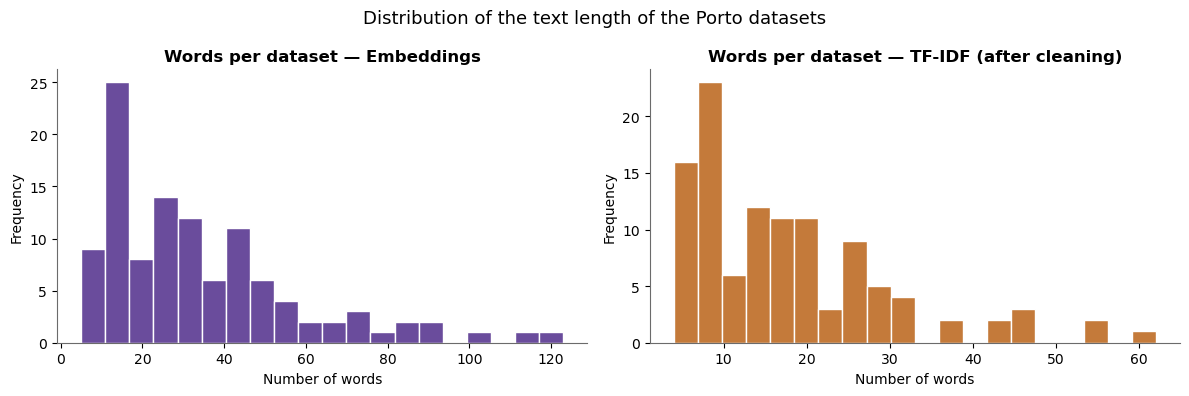

In [11]:
# ── Histogram of the text length of the datasets ────────────────────────────
qc = pd.DataFrame({
    "total_datasets"            : [len(datasets)],
    "mean_words_embeddings" : [datasets["n_words_embeddings"].mean()],
    "mean_words_tfidf"      : [datasets["n_words_tfidf"].mean()],
})
display(qc)

# Comparative histogram
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(datasets["n_words_embeddings"], bins=20, color=EMB_COLOUR, edgecolor="white")
axes[0].set_title("Words per dataset — Embeddings")
axes[0].set_xlabel("Number of words"); axes[0].set_ylabel("Frequency")

axes[1].hist(datasets["n_words_tfidf"], bins=20, color=TFIDF_COLOUR, edgecolor="white")
axes[1].set_title("Words per dataset — TF-IDF (after cleaning)")
axes[1].set_xlabel("Number of words")
axes[1].set_ylabel("Frequency")

plt.suptitle("Distribution of the text length of the Porto datasets", fontsize=13)
plt.tight_layout(); plt.show()

#### 4.1.1 Document series

Identification of the sets of records with standardised descriptions referred to in Section 4.1 and in Table 4.1 of the dissertation. The masks defined here (`DOC_SERIES` and `SERIES_BY_ID`) are reused in the counts of sections 7.4.1, 7.9.1, 9.3.2 and 11.3.

In [12]:
# ── 4.1.1 Document series (Section 4.1 and Table 4.1 of the dissertation) ─────
DISSERTATION_COUNTS = {}          # tables exported at the end (section 11.3)

_name = datasets["title"].fillna("").astype(str)
_desc = datasets["description"].fillna("").astype(str).str.strip()

if SUFFIX == "agueda":
    DOC_SERIES = {
        "Traffic counts": _name.str.contains("contagem", case=False) | _desc.str.contains("contagem", case=False),
        "PDM": _name.str.contains("PDM|plano diretor", case=False) | _desc.str.contains("PDM|plano diretor", case=False),
    }
    SERIES_DETAIL = {
        "Descriptions starting with 'Contagem de tráfego'": _desc.str.startswith("Contagem de tráfego"),
        "  … of which 'Contagem de tráfego sobre a Rua'": _desc.str.startswith("Contagem de tráfego sobre a Rua"),
    }
else:
    DOC_SERIES = {
        "Points of interest": _desc.str.lower().str.startswith("pontos de interesse"),
        "'Layer de geometria tipo…' layers": _desc.str.startswith("Layer de geometria tipo"),
        "Records with 'PDM' in the name": _name.str.contains("PDM"),
    }
    _maps = _desc.str.startswith("Esta Carta pertence")
    SERIES_DETAIL = {
        "Maps ('Esta Carta pertence à Planta de…')": _maps,
        "Maps that also have 'PDM' in the name": _maps & _name.str.contains("PDM"),
    }

_mat = pd.concat(DOC_SERIES.values(), axis=1)
assert (_mat.sum(axis=1) <= 1).all(), "There are records in more than one series."
SERIES_BY_ID = pd.Series("Outside the series", index=datasets["dataset_id"].values, name="series")
for _k, _m in DOC_SERIES.items():
    SERIES_BY_ID[_m.to_numpy()] = _k

series_tab = pd.DataFrame(
    [{"set": k, "n": int(m.sum()), "% of corpus": round(100 * m.mean(), 1)} for k, m in DOC_SERIES.items()]
    + [{"set": "Outside the series", "n": int((SERIES_BY_ID == "Outside the series").sum()),
        "% of corpus": round(100 * (SERIES_BY_ID == "Outside the series").mean(), 1)}]
    + [{"set": "  detail: " + k, "n": int(m.sum()), "% of corpus": round(100 * m.mean(), 1)} for k, m in SERIES_DETAIL.items()]
)
DISSERTATION_COUNTS["Document series"] = series_tab
print(f"Document series — {SUFFIX} (n = {len(datasets)})")
display(series_tab)

Document series — porto (n = 110)


,set,n,% of corpus
0,Points of interest,26,23.6
1,'Layer de geometria tipo…' layers,24,21.8
2,Records with 'PDM' in the name,21,19.1
3,Outside the series,39,35.5
4,detail: Maps ('Esta Carta pertence à Planta de…'),9,8.2
5,detail: Maps that also have 'PDM' in the name,9,8.2


### 4.2 Loading and pre-processing the anchor texts

The anchor texts are the central element of the classification system: they define, in natural language, what characterises each Smart City dimension. The quality and detail of these texts have a direct impact on the quality of the classification - which is precisely why four versions of increasing length are tested (original, 50, 100, 150 words).

#### Expected structure of the anchor files

Each anchor CSV file must have at least two columns:
- A column with the name of the dimension (detected automatically among variants such as `"dimensao"`, `"dimensão"`, `"dimension"`, `"categoria"`);
- A column with the descriptive text (detected among `"texto"`, `"text"`, `"descricao"`, `"descrição"`, `"anchor"`, `"ancoras"`).

The file may have multiple rows per dimension (for example, if the anchor consists of several paragraphs). In that case, the texts are concatenated before classification.

#### Application of the pipelines

The same two pre-processing pipelines are applied to the anchor texts:
- `text_embeddings`: light cleaning, to be encoded by the model;
- `text_tfidf`: rich cleaning, to be vectorised by TF-IDF in the same space as the datasets.

It is essential that **anchors and datasets use exactly the same pipeline** for each method. If the anchor text is cleaned differently from the dataset text, the comparison by cosine similarity becomes biased.

#### Consistency check across versions

The notebook automatically checks that the dimensions present in each anchor version are the same. If a version introduces or removes a dimension (for example, because of a typing error), execution is stopped to avoid inconsistent comparisons between versions.

#### Visualisation of the length of the anchors by version

A bar chart is produced with the number of words of each anchor by version and dimension. This chart serves to confirm that the versions do have increasing lengths and that no dimension was left out of any version.


In [13]:
def prepare_anchors(path, version_name: str) -> pd.DataFrame:
    """Loads, validates and pre-processes an anchor text file."""
    anchors = read_csv_auto(path)
    anchors = anchors.loc[:, ~anchors.columns.astype(str).str.contains("^Unnamed")]

    dim_col  = pick_col(anchors, ["dimensao","dimensão","dimension","categoria","classe","label"])
    text_col = pick_col(anchors, ["texto","text","anchor","ancora","âncora","descricao","descrição","description"])

    if dim_col is None or text_col is None:
        raise ValueError(
            f"Could not identify the dimension and text columns in file '{path}'. "
            f"Available columns: {list(anchors.columns)}"
        )

    anchors = anchors[[dim_col, text_col]].copy()
    anchors.columns = ["dimension", "original_text"]
    anchors["anchor_version"] = version_name

    anchors["dimension"]         = anchors["dimension"].map(lambda x: normalize_spaces(safe_text(x)).title()).replace(DIM_EN)
    anchors["text_embeddings"] = anchors["original_text"].map(clean_text_embeddings)
    # The anchors are only a few rows (one per dimension), so the cost of spaCy
    # here is irrelevant — but the same batch function is used for consistency
    # with the pre-processing of the datasets (cell 17) and to reuse the
    # same tested code.
    anchors["text_tfidf"] = clean_text_tfidf_batch(anchors["original_text"])

    anchors["n_words_embeddings"] = anchors["text_embeddings"].map(word_count)
    anchors["n_words_tfidf"]      = anchors["text_tfidf"].map(word_count)

    duplicated_cols = anchors.loc[anchors["dimension"].duplicated(), "dimension"].tolist()
    if duplicated_cols:
        print(f"  ⚠️  Duplicate dimensions in '{path}': {duplicated_cols}")
        print(f"     They will be aggregated by concatenation in process_anchor_version.")

    return anchors


anchors_by_version = {}
for version_name, path in ANCHOR_FILES.items():
    anchors_by_version[version_name] = prepare_anchors(path, version_name)
    print(f"  {version_name}: {len(anchors_by_version[version_name])} dimensions loaded")

# Consistency check across versions
dimensions_by_version = {v: set(df["dimension"].tolist()) for v, df in anchors_by_version.items()}
reference = next(iter(dimensions_by_version.values()))
for version, dims in dimensions_by_version.items():
    if set(dims) != set(reference):
        raise ValueError(
            f"The dimensions of version '{version}' do not match the reference version.\n"
            f"Missing: {reference - dims}  |  Extra: {dims - reference}"
        )

DIMENSIONS = sorted(reference, key=dim_sort_key)
print(f"\nSmart City dimensions identified ({len(DIMENSIONS)}):")
for d in DIMENSIONS:
    print(f"  — {d}")

first_version = next(iter(anchors_by_version))
display(anchors_by_version[first_version][["dimension","n_words_embeddings","n_words_tfidf"]])

  original: 6 dimensions loaded
  50_words: 6 dimensions loaded


  100_words: 6 dimensions loaded
  150_words: 6 dimensions loaded

Smart City dimensions identified (6):
  — Smart Environment
  — Smart Economy
  — Smart Governance
  — Smart Mobility
  — Smart Quality of Life
  — Smart Society


,dimension,n_words_embeddings,n_words_tfidf
0,Smart Governance,106,62
1,Smart Society,163,90
2,Smart Mobility,147,85
3,Smart Environment,363,212
4,Smart Quality of Life,312,167
5,Smart Economy,148,82


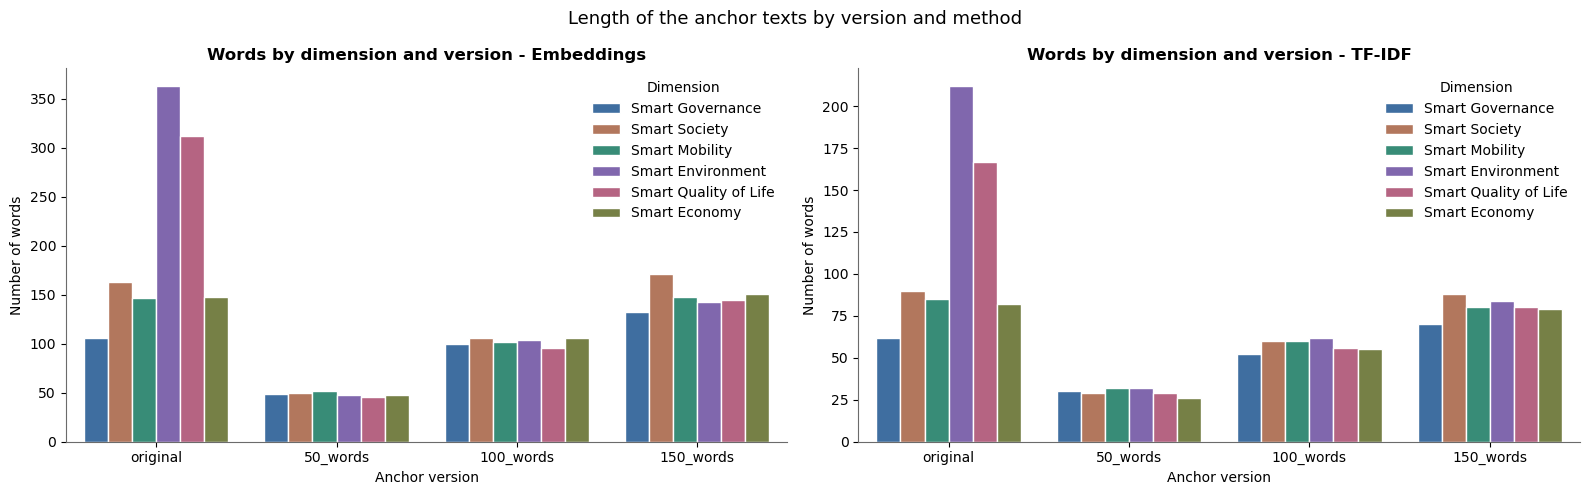

In [14]:
# ── Plot of the number of words by version and dimension ─────────────────────
# Aggregate by dimension — guarantees one row per (version, dimension)
# even if the original CSV has several rows per dimension
comparison_anchors = pd.concat(
    [
        a.groupby("dimension", sort=False)
         .agg(n_words_embeddings=("n_words_embeddings", "sum"),
              n_words_tfidf=("n_words_tfidf", "sum"))
         .reset_index()
         .assign(version=version)
        for version, a in anchors_by_version.items()
    ],
    ignore_index=True,
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(data=comparison_anchors, x="version", y="n_words_embeddings",
            hue="dimension", ax=axes[0], palette=CATEGORICAL_PALETTE, edgecolor="white")
axes[0].set_title("Words by dimension and version - Embeddings")
axes[0].set_xlabel("Anchor version")
axes[0].set_ylabel("Number of words")
axes[0].legend(title="Dimension")

sns.barplot(data=comparison_anchors, x="version", y="n_words_tfidf",
            hue="dimension", ax=axes[1], palette=CATEGORICAL_PALETTE, edgecolor="white")
axes[1].set_title("Words by dimension and version - TF-IDF")
axes[1].set_xlabel("Anchor version")
axes[1].set_ylabel("Number of words")
axes[1].legend(title="Dimension")
format_x_labels(axes[0]); format_x_labels(axes[1])

plt.suptitle("Length of the anchor texts by version and method", fontsize=13)
plt.tight_layout()
plt.show()

**Methodological note — length imbalance between dimensions ("original" version).**

The next cell explicitly quantifies something visible in the previous chart: in the "original" version,
some dimensions have considerably longer anchor texts than others. This is relevant because longer
anchors tend to have a richer vocabulary, which may give them a structural advantage in the
classification (more chances of lexical overlap in TF-IDF, and a semantically more "covered" centroid in the
embeddings) — regardless of the actual content of the dataset being classified. This asymmetry does not invalidate
the results, but it is a limitation of the original version.


In [15]:
# ── Quantifying the length imbalance between dimensions ─────────────────────
# (see note above) — computed for the "original" version, the most asymmetric one.

if "original" in anchors_by_version:
    words_original = (
        comparison_anchors[comparison_anchors["version"] == "original"]
        [["dimension", "n_words_embeddings"]]
        .sort_values("n_words_embeddings", ascending=False)
        .reset_index(drop=True)
    )
    print("Words by dimension — 'original' version (sorted, largest → smallest):")
    display(words_original)

    largest = words_original["n_words_embeddings"].max()
    smallest = words_original["n_words_embeddings"].min()
    ratio = largest / smallest if smallest > 0 else float("inf")

    print(f"\nLongest dimension  : {words_original.iloc[0]['dimension']} "
          f"({largest} words)")
    print(f"Shortest dimension : {words_original.iloc[-1]['dimension']} "
          f"({smallest} words)")
    print(f"Largest/smallest ratio: {ratio:.1f}x")
    if ratio >= 2:
        print(f"\n⚠️  Relevant imbalance (≥2x) — to be taken into account when interpreting the results: "
              f"dimensions with longer anchors have a richer vocabulary, which may "
              f"favour their assignment regardless of the actual content of the dataset.")
else:
    print("'original' version not available — check skipped.")


Words by dimension — 'original' version (sorted, largest → smallest):


,dimension,n_words_embeddings
0,Smart Environment,363
1,Smart Quality of Life,312
2,Smart Society,163
3,Smart Economy,148
4,Smart Mobility,147
5,Smart Governance,106



Longest dimension  : Smart Environment (363 words)
Shortest dimension : Smart Governance (106 words)
Largest/smallest ratio: 3.4x

⚠️  Relevant imbalance (≥2x) — to be taken into account when interpreting the results: dimensions with longer anchors have a richer vocabulary, which may favour their assignment regardless of the actual content of the dataset.


## 5. Loading the embedding model

### The chosen model: `paraphrase-multilingual-MiniLM-L12-v2`

The selected model is a *Sentence Transformer*, a BERT-based architecture that was specifically trained to generate vector representations of whole sentences (instead of individual words), so that sentences with similar meaning are close together in the vector space.

The `paraphrase-multilingual-MiniLM-L12-v2` variant was trained on more than 50 languages, including Portuguese, which makes it suitable for this corpus. It has 12 *layers* and produces embeddings of **384 dimensions**, an efficient compromise between semantic capacity and inference speed.

### Why this model and not another?

There are more powerful models available (such as `multilingual-e5-large` or `paraphrase-multilingual-mpnet-base-v2`), but `MiniLM-L12-v2` offers sufficient semantic quality for classification into broad thematic categories, with a much shorter inference time. For a corpus of tens to a few hundred datasets, the difference in quality between models is marginal, but the difference in speed is relevant when testing multiple anchor versions.

In [16]:
print(f"Loading model: {MODEL_NAME}")
model = SentenceTransformer(MODEL_NAME, revision=MODEL_REVISION, device=MODEL_DEVICE)
print("Model loaded successfully.")

Loading model: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2


C:\Users\paulo\.conda\envs\dissertacao_fr\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\paulo\.cache\huggingface\hub\models--sentence-transformers--paraphrase-multilingual-MiniLM-L12-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Model loaded successfully.


### 5.1 Check of the model's token limit

The embedding model processes at most `max_seq_length` tokens per text; the text that exceeds this limit is ignored when computing the vector. This check counts the tokens of each text exactly as it is sent to the model — metadata of the datasets (`doc_text_embeddings`) and text of each dimension in each anchor version — and indicates how many exceed the limit and what proportion of the text is left out.

The check only measures; it does not change the texts or the classification. If there is truncation, the affected cases are recorded in `outputs/porto/01_pre_chunking/checks/ML-001_truncation_<municipality>.xlsx` and discussed as a limitation, especially for the longer anchor versions.

In [17]:
# ── 5.1 Checking the token limit (truncation) ────────────────────────────────
# Read-only: uses the `model`, the `datasets` and the `anchors_by_version` already loaded.
tokeniser = model.tokenizer
TOKEN_LIMIT = int(model.max_seq_length)

def n_tokens(texts):
    """Number of tokens WITHOUT truncation, including the special tokens."""
    return np.array([len(tokeniser(str(t), add_special_tokens=True, truncation=False)["input_ids"])
                     for t in texts])

# Datasets: the exact text sent to the model
tok_ds = datasets[["dataset_id", "title"]].copy()
tok_ds["words"] = datasets["doc_text_embeddings"].fillna("").astype(str).str.split().str.len()
tok_ds["tokens"] = n_tokens(datasets["doc_text_embeddings"].fillna(""))
tok_ds["above_limit"] = tok_ds["tokens"] > TOKEN_LIMIT
tok_ds["pct_tokens_ignored"] = ((tok_ds["tokens"] - TOKEN_LIMIT).clip(lower=0) / tok_ds["tokens"] * 100).round(1)

# Anchors: text aggregated by dimension, as in the classification
rows_tok = []
for version, anc in anchors_by_version.items():
    agg = anc.groupby("dimension", sort=False)["text_embeddings"].apply(lambda s: " ".join(s.astype(str)))
    for dim, text_value in agg.items():
        n = int(n_tokens([text_value])[0])
        rows_tok.append({"version": version, "dimension": dim, "words": len(text_value.split()),
                           "tokens": n, "above_limit": n > TOKEN_LIMIT,
                           "pct_tokens_ignored": round(max(n - TOKEN_LIMIT, 0) / n * 100, 1)})
tok_anc = pd.DataFrame(rows_tok)

n_ds_above = int(tok_ds["above_limit"].sum())
n_anc_above = int(tok_anc["above_limit"].sum())
print(f"Model:              {MODEL_NAME}")
print(f"max_seq_length:     {TOKEN_LIMIT}")
print(f"N datasets:         {len(tok_ds)}")
print(f"N anchors:          {len(tok_anc)} ({tok_anc['version'].nunique()} versions x {tok_anc['dimension'].nunique()} dimensions)")
print(f"Max datasets:       {tok_ds['tokens'].max()} tokens | P95: {np.percentile(tok_ds['tokens'], 95):.0f}")
print(f"Max anchors:        {tok_anc['tokens'].max()} tokens")
print(f"N datasets above:   {n_ds_above} ({n_ds_above / len(tok_ds) * 100:.1f}%)")
print(f"N anchors above:    {n_anc_above} of {len(tok_anc)}")
print("\nTokens per anchor (dimension x version):")
display(tok_anc.pivot(index="dimension", columns="version", values="tokens")
        .reindex(columns=list(anchors_by_version.keys())))
if n_anc_above:
    print("Anchors above the limit (the model ignores the final part of the text):")
    display(tok_anc.loc[tok_anc["above_limit"]].sort_values("pct_tokens_ignored", ascending=False))
if n_ds_above:
    print("Datasets above the limit (10 longest):")
    display(tok_ds.loc[tok_ds["above_limit"]].sort_values("tokens", ascending=False).head(10))

print("\nConclusion:", "no text exceeds the model limit." if (n_ds_above + n_anc_above) == 0 else
      "there are texts above the limit — record the affected cases and versions and discuss them as a limitation.")

with pd.ExcelWriter(VERIF_DIR / f"ML-001_truncation_{SUFFIX}.xlsx") as w:
    tok_anc.to_excel(w, sheet_name="Anchors", index=False)
    tok_ds.to_excel(w, sheet_name="Datasets", index=False)
print(f"\nSaved: {VERIF_DIR / f'ML-001_truncation_{SUFFIX}.xlsx'}")

Token indices sequence length is longer than the specified maximum sequence length for this model (174 > 128). Running this sequence through the model will result in indexing errors


Model:              sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
max_seq_length:     128
N datasets:         110
N anchors:          24 (4 versions x 6 dimensions)
Max datasets:       179 tokens | P95: 129
Max anchors:        625 tokens
N datasets above:   6 (5.5%)
N anchors above:    18 of 24

Tokens per anchor (dimension x version):


version,original,50_words,100_words,150_words
dimension,,,,
Smart Economy,221,70,155,212
Smart Environment,625,80,164,222
Smart Governance,165,76,146,188
Smart Mobility,263,88,164,228
Smart Quality of Life,503,79,157,223
Smart Society,238,75,155,239


Anchors above the limit (the model ignores the final part of the text):


,version,dimension,words,tokens,above_limit,pct_tokens_ignored
3,original,Smart Environment,363,625,True,79.5
4,original,Smart Quality of Life,312,503,True,74.6
2,original,Smart Mobility,147,263,True,51.3
19,150_words,Smart Society,171,239,True,46.4
1,original,Smart Society,163,238,True,46.2
20,150_words,Smart Mobility,148,228,True,43.9
22,150_words,Smart Quality of Life,145,223,True,42.6
21,150_words,Smart Environment,143,222,True,42.3
5,original,Smart Economy,148,221,True,42.1
23,150_words,Smart Economy,151,212,True,39.6


Datasets above the limit (10 longest):


,dataset_id,title,words,tokens,above_limit,pct_tokens_ignored
78,f97f5d10-4310-47d1-be15-3112974bfabc,"Entidades reconhecidas no programa Municipal de Reconhecimento ""Confiança Porto"" - Alojamento Turístico",112,179,True,28.5
53,c527bb4f-91d1-40b7-af81-2c4cffadc217,Balanço Social,123,174,True,26.4
77,7074013f-28da-45b8-99bf-5677df9bb1ce,Entidades que aderiram ao projeto Turismo Industrial,104,138,True,7.2
98,07b0bab4-b972-449d-84d6-4068fb4f88dc,Registos de monitorização de ruído (rede sensores da Porto Digital),90,137,True,6.6
60,d3977614-54d6-4e53-99a1-75a73afd8a9a,Carta de Riscos Naturais - PDM 2021 (2ª Alteração por Adaptação),90,130,True,1.5
91,a7ddf3b0-9d5f-4fa2-96b8-22db8aad862d,Carta de Infraestruturas de Modos Suaves - PDM 2021,86,130,True,1.5



Conclusion: there are texts above the limit — record the affected cases and versions and discuss them as a limitation.



Saved: C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\outputs\porto\01_pre_chunking\checks\ML-001_truncation_porto.xlsx


## 6. Classification by anchor version

This section is the computational core of the notebook: for each of the four anchor versions, the two classification pipelines (Embeddings and TF-IDF) are run and the results are stored in a data structure indexed by version.

### What happens in each iteration

**For the Embeddings:**
1. The `doc_text_embeddings` texts of the datasets are encoded by the model, producing an `X_data` matrix with shape `(n_datasets × 384)`.
2. The `text_embeddings` texts of the anchors are likewise encoded, producing an `X_anc` matrix with shape `(n_dimensions × 384)`.
3. The cosine similarity between each dataset and each anchor is computed: `S = X_data @ X_anc.T`, producing a matrix with shape `(n_datasets × n_dimensions)`.
4. For each dataset, the dimension with the highest score is assigned, and the delta (top-1 minus top-2) is computed.

**For TF-IDF:**
1. The `doc_text_tfidf` texts of the datasets and the `text_tfidf` texts of the anchors are used to fit a single TF-IDF vectoriser on the full corpus (datasets + anchors). This decision is crucial: if the vectoriser were fitted only on the datasets, the tokens that appear exclusively in the anchors would be ignored, and vice versa.
2. The texts are transformed into the TF-IDF space and the cosine similarity is computed in the same way.

### Why test four anchor versions?

The quality of the classification depends critically on the detail and specificity of the anchor texts. A very short anchor (e.g. just the name of the dimension) may not capture the various sub-themes that the dimension encompasses. A longer anchor may be more discriminative, but it may also introduce noise if it includes very specific examples.

The original text of each ENTI dimension is the normative reference for the content. The versions of approximately 50, 100 and 150 words are alternative operationalisations, obtained by rewriting with the support of a language model, and serve to assess the sensitivity of the results to the textual representation of the dimensions. They are not progressive reductions of the same text: they differ simultaneously in length, wording, lexical selection and level of detail. By testing the four versions it is possible to:
- describe the extent to which the assigned dimension changes when the textual representation of the dimensions changes;
- identify stable datasets (same dimension in the four versions) and unstable ones (variable dimension).

The comparison does not make it possible to attribute the differences only to the length of the anchors or to choose a “better” version.

### Adaptive confidence thresholds

After classifying with each version and method, the confidence thresholds are computed adaptively from the 33rd and 66th percentiles of the observed distribution of deltas. The scales of the delta differ between Embeddings and TF-IDF (the observed values are given in the tables of Section 6), so a fixed threshold common to both methods would not be comparable. The percentile thresholds adjust to the distribution of each method and version; by construction, about one third of the valid cases falls into each band, and the bands are not probabilities or levels of accuracy.

### Structure of the results

The results of each version are stored in the dictionary `results_by_version`, in which each entry contains:
- `"results"`: DataFrame with the assigned dimension, scores, delta and confidence level for each dataset and method;
- `"scores_emb"` and `"scores_tfidf"`: full score matrices (datasets × dimensions)
- `"thresholds"`: dictionary with the values of the adaptive thresholds used.

After the main run, descriptive statistics of the distribution of the deltas are computed, together with a diagnostic of the datasets with TF-IDF score = 0, information that is important for calibrating thresholds and understanding the limitations of the lexical method.


In [18]:
# ── Running all anchor versions ──────────────────────────────────────────────
#
# The embeddings of the datasets (doc_text_embeddings) are computed ONLY ONCE
# here, before the loop, and reused in the 4 anchor versions: only the anchor
# text changes between versions; the datasets are always the same.

print("Computing the embeddings of the datasets (1x, reused in the 4 anchor versions)...")
X_data_emb_global = model.encode(
    datasets["doc_text_embeddings"].tolist(),
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=True,
)
print(f"Embeddings computed: {X_data_emb_global.shape}")

results_by_version = {}

for version, anchors in anchors_by_version.items():
    results_by_version[version] = process_anchor_version(
        version, anchors, datasets, X_data_emb_cache=X_data_emb_global
    )

# Aggregated table with the results of all versions (used in the plots)
results_all_versions = pd.concat(
    [obj["results"] for obj in results_by_version.values()],
    ignore_index=True,
)
print(f"\nAggregated table: {results_all_versions.shape[0]} rows × {results_all_versions.shape[1]} columns")
display(results_all_versions.head())

Computing the embeddings of the datasets (1x, reused in the 4 anchor versions)...


Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Batches:  25%|██▌       | 1/4 [00:14<00:42, 14.12s/it]

Batches:  50%|█████     | 2/4 [00:21<00:19,  9.98s/it]

Batches:  75%|███████▌  | 3/4 [00:26<00:07,  7.72s/it]

Batches: 100%|██████████| 4/4 [00:27<00:00,  5.11s/it]

... (15 outputs left out)

Batches: 100%|██████████| 1/1 [00:03<00:00,  3.16s/it]

Batches: 100%|██████████| 1/1 [00:03<00:00,  3.16s/it]

  → TF-IDF...
  Adaptive thresholds (150_words):
    Embeddings → high: ≥0.047  medium: ≥0.025
    TF-IDF     → high: ≥0.017  medium: ≥0.007
  ⚠️  TF-IDF    : 25/110 datasets unclassified (22.7%)
  Done. Agreement over 85/110 valid datasets: 49.4%

Aggregated table: 440 rows × 31 columns


,anchor_version,dataset_id,dataset_title,dataset_description,n_words_embeddings,n_words_tfidf,dimension_embeddings,score_top1_embeddings,dimension_top2_embeddings,score_top2_embeddings,delta_embeddings,confidence_embeddings,dimension_tfidf,score_top1_tfidf,dimension_top2_tfidf,score_top2_tfidf,delta_tfidf,confidence_tfidf,methods_agree,score_emb_Smart Governance,score_tfidf_Smart Governance,score_emb_Smart Society,score_tfidf_Smart Society,score_emb_Smart Mobility,score_tfidf_Smart Mobility,score_emb_Smart Environment,score_tfidf_Smart Environment,score_emb_Smart Quality of Life,score_tfidf_Smart Quality of Life,score_emb_Smart Economy,score_tfidf_Smart Economy
0,original,37dc9216-0b42-4eb8-9817-7d85309e6def,Parques de estacionamento municipais,"Layer de geometria tipo ponto, referente à localização e caraterização dos parques de estacionamento no Município do Porto.",22,9,Smart Environment,0.320169,Smart Economy,0.289754,0.030415,medium,Smart Environment,0.004981,Smart Governance,0.000000,0.004981,low,True,0.265748,0.000000,0.171236,0.000000,0.272193,0.000000,0.320169,0.004981,0.221790,0.000000,0.289754,0.000000
1,original,d85836f9-e683-4be4-8b69-5260f5611be6,Parques Privativos,"Layer de geometria tipo ponto de identificação e localização de áreas reservadas ao estacionamento em parques privativos no Município do Porto, de veículos ...",32,18,Smart Environment,0.385710,Smart Governance,0.384860,0.000850,low,Smart Mobility,0.045753,Smart Governance,0.013708,0.032045,high,False,0.384860,0.013708,0.273121,0.011093,0.322554,0.045753,0.385710,0.006572,0.280385,0.011679,0.326518,0.000000
2,original,ee4a4efe-b6f9-45e7-9b7b-0aeeca689dda,Condicionamentos de trânsito,"Layer de geometria tipo polígono de identificação e localização de condicionamento programados/previstos, áreas do espaço público, excluídas, temporariamen...",33,17,Smart Mobility,0.374555,Smart Governance,0.338728,0.035827,medium,Smart Mobility,0.024935,Smart Environment,0.021774,0.003161,low,True,0.338728,0.006937,0.226194,0.020736,0.374555,0.024935,0.325517,0.021774,0.272429,0.021038,0.330004,0.008068
3,original,cb350387-ceb0-4aac-8a27-adfcf512a456,Condicionamentos não programados,"Layer de geometria tipo ponto de localização e identificação dos condicionamentos não programados/previstos, no Município do Porto.",20,10,Smart Environment,0.299372,Smart Economy,0.282101,0.017271,low,Smart Environment,0.009441,Smart Governance,0.000000,0.009441,medium,True,0.270548,0.000000,0.236191,0.000000,0.239993,0.000000,0.299372,0.009441,0.259717,0.000000,0.282101,0.000000
4,original,563cc44a-a778-45ac-ae21-0a6445e10e01,Cargas e descargas,"Layer de geometria tipo linha, que localiza e carateriza as marcações de cargas e descargas no Município do Porto.",22,11,Smart Mobility,0.313240,Smart Economy,0.200345,0.112895,high,None,0.000000,Smart Society,0.000000,0.000000,null,False,0.152897,0.000000,0.056388,0.000000,0.313240,0.000000,0.164697,0.000000,0.143137,0.000000,0.200345,0.000000


In [19]:
# ── Diagnostic of the distribution of the deltas by method ───────────────────
# Run this cell after the execution (previous cell).
# Shows: descriptive statistics, histograms and percentiles of the deltas
# of Embeddings and TF-IDF across all anchor versions combined.

deltas_emb_all   = []
deltas_tfidf_all = []

for version, obj in results_by_version.items():
    res = obj["results"]
    deltas_emb_all.extend(res["delta_embeddings"].tolist())
    deltas_tfidf_all.extend(res["delta_tfidf"].tolist())

deltas_emb_all   = np.array(deltas_emb_all)
deltas_tfidf_all = np.array(deltas_tfidf_all)

In [20]:
# ── Descriptive statistics ────────────────────────────────────────────────────
print("=" * 60)
print("DISTRIBUTION OF THE DELTAS (all versions combined)")
print("=" * 60)

for name_, arr in [("Embeddings", deltas_emb_all), ("TF-IDF", deltas_tfidf_all)]:
    print(f"\n{name_}:")
    print(f"  min    : {arr.min():.4f}")
    print(f"  p10    : {np.percentile(arr, 10):.4f}")
    print(f"  p25    : {np.percentile(arr, 25):.4f}")
    print(f"  median : {np.percentile(arr, 50):.4f}")
    print(f"  p75    : {np.percentile(arr, 75):.4f}")
    print(f"  p90    : {np.percentile(arr, 90):.4f}")
    print(f"  max    : {arr.max():.4f}")
    print(f"  mean   : {arr.mean():.4f}  |  standard deviation: {arr.std():.4f}")
    print(f"\n  Suggested fixed thresholds based on the 66/33 percentiles:")
    print(f"    high   ≥ {np.percentile(arr, 66):.4f}  (p66)")
    print(f"    medium ≥ {np.percentile(arr, 33):.4f}  (p33)")



DISTRIBUTION OF THE DELTAS (all versions combined)

Embeddings:
  min    : 0.0004
  p10    : 0.0070
  p25    : 0.0178
  median : 0.0367
  p75    : 0.0672
  p90    : 0.1090
  max    : 0.2308
  mean   : 0.0476  |  standard deviation: 0.0403

  Suggested fixed thresholds based on the 66/33 percentiles:
    high   ≥ 0.0511  (p66)
    medium ≥ 0.0236  (p33)

TF-IDF:
  min    : 0.0000
  p10    : 0.0000
  p25    : 0.0005
  median : 0.0068
  p75    : 0.0172
  p90    : 0.0310
  max    : 0.1379
  mean   : 0.0125  |  standard deviation: 0.0178

  Suggested fixed thresholds based on the 66/33 percentiles:
    high   ≥ 0.0115  (p66)
    medium ≥ 0.0026  (p33)


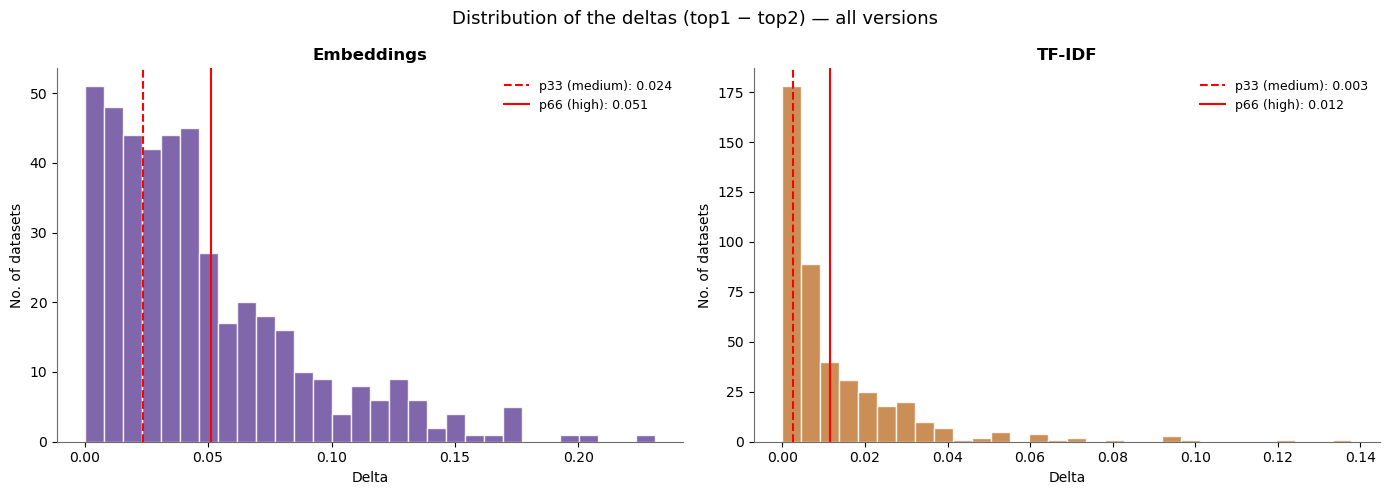

In [21]:
# ── Histogramas ───────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Distribution of the deltas (top1 − top2) — all versions", fontsize=13)

for ax, name_, arr, color in [
    (axes[0], "Embeddings", deltas_emb_all, EMB_COLOUR),
    (axes[1], "TF-IDF",     deltas_tfidf_all, TFIDF_COLOUR),
]:
    ax.hist(arr, bins=30, color=color, alpha=0.85, edgecolor="white")
    for p, label, ls in [
        (np.percentile(arr, 33), "p33 (medium)", "--"),
        (np.percentile(arr, 66), "p66 (high)",  "-"),
    ]:
        ax.axvline(p, color="red", linestyle=ls, linewidth=1.5, label=f"{label}: {p:.3f}")
    ax.set_title(name_)
    ax.set_xlabel("Delta")
    ax.set_ylabel("No. of datasets")
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()


In [22]:
# ── Table by version ──────────────────────────────────────────────────────────
print("\nDetail by anchor version:")
rows = []
for version, obj in results_by_version.items():
    res = obj["results"]
    lim = obj["thresholds"]
    for method, col_delta in [("Embeddings", "delta_embeddings"), ("TF-IDF", "delta_tfidf")]:
        if method == "TF-IDF":
            # The classification defines the TF-IDF percentiles only among cases
            # with lexical overlap and a valid dimension. The diagnostic uses
            # exactly the same population so as to be directly comparable.
            mask = res["dimension_tfidf"].notna() & np.isfinite(res[col_delta])
        else:
            mask = np.isfinite(res[col_delta])
        arr = res.loc[mask, col_delta].to_numpy(dtype=float)
        if arr.size == 0:
            raise ValueError(f"No valid deltas for {method} — {version}.")
        rows.append({
            "version"            : version,
            "method"            : method,
            "n_valid_percentiles": int(arr.size),
            "min"               : round(float(arr.min()), 4),
            "p33"               : round(float(np.percentile(arr, 33)), 4),
            "median"           : round(float(np.percentile(arr, 50)), 4),
            "p66"               : round(float(np.percentile(arr, 66)), 4),
            "max"               : round(float(arr.max()), 4),
            "high_threshold_used" : round(lim["emb_high" if method == "Embeddings" else "tfidf_high"], 4),
            "medium_threshold_used"  : round(lim["emb_medium" if method == "Embeddings" else "tfidf_medium"], 4),
        })

percentile_detail_df = pd.DataFrame(rows).set_index(["version", "method"])
display(percentile_detail_df)
print("\nThe thresholds are computed automatically by method and version.")
print("In TF-IDF, the percentiles exclude cases without lexical overlap, as in the classification.")



Detail by anchor version:


n_valid_percentiles     min     p33  median     p66  \
version   method                                                            
original  Embeddings                  110  0.0004  0.0229  0.0330  0.0463   
          TF-IDF                      106  0.0001  0.0059  0.0083  0.0122   
50_words  Embeddings                  110  0.0019  0.0298  0.0462  0.0663   
          TF-IDF                       74  0.0002  0.0069  0.0134  0.0231   
100_words Embeddings                  110  0.0006  0.0191  0.0332  0.0458   
          TF-IDF                       76  0.0000  0.0050  0.0093  0.0154   
150_words Embeddings                  110  0.0029  0.0247  0.0360  0.0469   
          TF-IDF                       85  0.0003  0.0070  0.0093  0.0171   

                         max  high_threshold_used  medium_threshold_used  
version   method                                                          
original  Embeddings  0.1762               0.0463                 0.0229  
          TF-IDF      0.1209               0.0122                 0.0059  
50_words  Embeddings  0.2308               0.0663                 0.0298  
          TF-IDF      0.1007               0.0231                 0.0069  
100_words Embeddings  0.1407               0.0458                 0.0191  
          TF-IDF      0.0964               0.0154                 0.0050  
150_words Embeddings  0.1714               0.0469                 0.0247  
          TF-IDF      0.1379               0.0171                 0.0070


The thresholds are computed automatically by method and version.
In TF-IDF, the percentiles exclude cases without lexical overlap, as in the classification.


**Analysis of the results (6 — Variation of the adaptive thresholds across versions).**

The table shows that the very thresholds that define the «high» and «medium» confidence bands vary across
anchor versions, because they are computed by percentile (33/66) over the distribution of the deltas of each
combination of method and version (see Section 2.3).

In TF-IDF, the threshold of the «high» band (`high_threshold_used`) varies between **0.0122** (original version) and
**0.0231** (50 words); in the Embeddings, between **0.0458** (100 words) and **0.0663** (50 words).
Thus, a dataset with a TF-IDF delta of 0.013 would be in the «high» band in the original version and in the «medium» band
in the 50-word version, without its text having changed.

Two consequences for interpretation:
1. The bands are relative to the version and the method and should not be compared across versions as if
   they were on the same absolute scale.
2. The confidence band is not an absolute property of the dataset-dimension pair or a probability
   of being correct; it is a relative position in the distribution of the margins of that run.

In [23]:
# ── 1. Collect zeros by version ───────────────────────────────────────────────

print("=" * 70)
print("DIAGNOSTIC: Datasets with maximum TF-IDF score = 0")
print("=" * 70)

zeros_summary = []

for version, obj in results_by_version.items():
    res        = obj["results"].copy()
    scores_tf  = obj["scores_tfidf"]          # DataFrame: datasets × dimensions

    # Maximum TF-IDF score for each dataset (row)
    max_score = scores_tf.max(axis=1).values
    res["max_score_tfidf"] = max_score

    n_total = len(res)
    n_zeros = (max_score == 0).sum()
    pct     = n_zeros / n_total * 100

    dims_spurious = res.loc[max_score == 0, "dimension_tfidf"].dropna()

    zeros_summary.append({
        "version": version,
        "total datasets": n_total,
        "scores = 0": n_zeros,
        "% affected": round(pct, 1),
        "TF-IDF dimension in the zero cases": (
            dims_spurious.value_counts().idxmax() if not dims_spurious.empty else "—"
        ),
    })

    print(f"\n  Version: {version}")
    print(f"    → {n_zeros}/{n_total} datasets ({pct:.1f}%) with max TF-IDF score = 0")

    if n_zeros > 0:
        # Which datasets are these?
        zeros_df = res.loc[max_score == 0,
                           ["dataset_id", "dataset_title",
                            "n_words_tfidf", "dimension_tfidf",
                            "dimension_embeddings"]].copy()
        zeros_df.columns = ["ID", "Name", "tokens (tfidf)", "TF-IDF dimension", "Emb dim"]
        print(zeros_df.to_string(index=False))

print("\n" + "=" * 70)
summary_df = pd.DataFrame(zeros_summary)
print("\nSummary by anchor version:")
print(summary_df.to_string(index=False))

DIAGNOSTIC: Datasets with maximum TF-IDF score = 0

  Version: original
    → 4/110 datasets (3.6%) with max TF-IDF score = 0
                                  ID                                            Name  tokens (tfidf) TF-IDF dimension        Emb dim
563cc44a-a778-45ac-ae21-0a6445e10e01                              Cargas e descargas              11             None Smart Mobility
72308d0f-f93f-4c59-bbd6-3687523b5568 Arruamentos Classificados para Condicionamentos              17             None Smart Mobility
8268905b-f234-4f74-883a-cdf049dac54e                                 Eixos Tarifados              14             None Smart Mobility
dec46a1e-3963-4d78-9ccf-68a2c4613d04         Zona de Tomada e Largada de Passageiros              13             None Smart Mobility

  Version: 50_words
    → 36/110 datasets (32.7%) with max TF-IDF score = 0
                                  ID                                                        Name  tokens (tfidf) TF-IDF dimension   

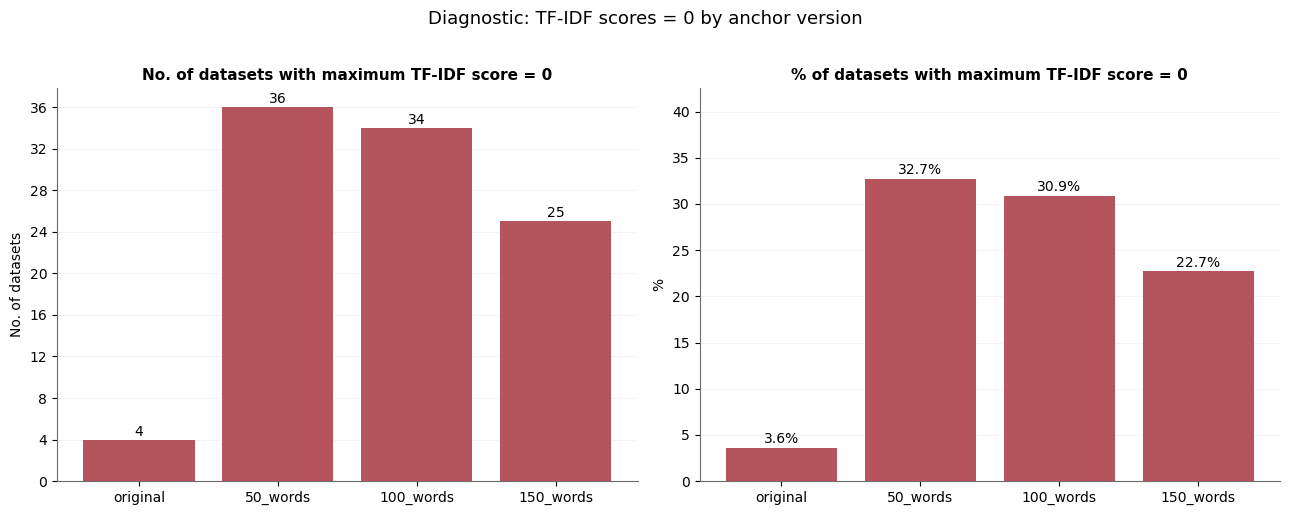

In [24]:
from matplotlib import ticker as mticker

# ── 4. Visualisation: zeros by version ────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Diagnostic: TF-IDF scores = 0 by anchor version", fontsize=13, y=1.02)

# 4a — Absolute count
ax1 = axes[0]
bars = ax1.bar(
    summary_df["version"],
    summary_df["scores = 0"],
    color=[HIGHLIGHT_COLOUR if v > 0 else NEUTRAL_COLOUR for v in summary_df["scores = 0"]],
    edgecolor="none",
    zorder=3,
)
ax1.set_title("No. of datasets with maximum TF-IDF score = 0", fontsize=11)
ax1.set_ylabel("No. of datasets")
ax1.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax1.grid(axis="y", linewidth=0.4, alpha=0.5, zorder=0)
ax1.set_axisbelow(True)
for bar, val in zip(bars, summary_df["scores = 0"]):
    if val > 0:
        ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.1,
                 str(val), ha="center", va="bottom", fontsize=10)

# 4b — Percentage
ax2 = axes[1]
bars2 = ax2.bar(
    summary_df["version"],
    summary_df["% affected"],
    color=[HIGHLIGHT_COLOUR if v > 0 else NEUTRAL_COLOUR for v in summary_df["% affected"]],
    edgecolor="none",
    zorder=3,
)
ax2.set_title("% of datasets with maximum TF-IDF score = 0", fontsize=11)
ax2.set_ylabel("%")
ax2.set_ylim(0, max(summary_df["% affected"].max() * 1.3, 5))
ax2.grid(axis="y", linewidth=0.4, alpha=0.5, zorder=0)
ax2.set_axisbelow(True)
for bar, val in zip(bars2, summary_df["% affected"]):
    if val > 0:
        ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.2,
                 f"{val:.1f}%", ha="center", va="bottom", fontsize=10)

format_x_labels(ax1); format_x_labels(ax2)
plt.tight_layout()
plt.show()


## 7. Analysis of the results

This section analyses the results produced by the classification from multiple angles. Each subsection answers a specific question:

- **7.1**: Which dimensions are assigned to each dataset, version by version?
- **7.2**: How much do the two methods agree? Is the agreement stable across versions?
- **7.3**: Does the classification change when the anchor version is changed?
- **7.4**: How are the classifications distributed across the 6 dimensions?
- **7.5**: How confident is the classification? How many datasets have a clear vs. uncertain classification?
- **7.6**: When the two methods disagree, which dimensions are confused?

### 7.1 Detailed results by version

For each anchor version, a table is presented with, for each dataset:
- The dimension assigned by Embeddings and by TF-IDF;
- The confidence level of each method;
- Whether the two methods agree.

This table is the most direct output of the analysis and serves as a reference for the manual review of doubtful cases.


In [25]:
for version_name, obj in results_by_version.items():
    print("=" * 100)
    print(f"Results: {version_name}")
    print("=" * 100)
    display(
        obj["results"][[
            "dataset_id","dataset_title",
            "dimension_embeddings","confidence_embeddings",
            "dimension_tfidf","confidence_tfidf",
            "methods_agree"
        ]].head(10)
    )

Results: original


,dataset_id,dataset_title,dimension_embeddings,confidence_embeddings,dimension_tfidf,confidence_tfidf,methods_agree
0,37dc9216-0b42-4eb8-9817-7d85309e6def,Parques de estacionamento municipais,Smart Environment,medium,Smart Environment,low,True
1,d85836f9-e683-4be4-8b69-5260f5611be6,Parques Privativos,Smart Environment,low,Smart Mobility,high,False
2,ee4a4efe-b6f9-45e7-9b7b-0aeeca689dda,Condicionamentos de trânsito,Smart Mobility,medium,Smart Mobility,low,True
3,cb350387-ceb0-4aac-8a27-adfcf512a456,Condicionamentos não programados,Smart Environment,low,Smart Environment,medium,True
4,563cc44a-a778-45ac-ae21-0a6445e10e01,Cargas e descargas,Smart Mobility,high,None,null,False
5,5275c986-592c-43f5-8f87-aabbd4e4f3a4,"Horários, paragens e rotas da STCP",Smart Mobility,medium,Smart Mobility,high,True
6,15f22603-a216-492a-ab1c-40b1d8aa2f08,"Horários, paragens e rotas da Metro do Porto",Smart Mobility,high,Smart Mobility,high,True
7,fe566a21-9165-4d0d-ace9-e2e1286c3d1d,Atendimento Telefónico,Smart Governance,high,Smart Governance,high,True
8,a6d2764b-edc4-4895-a199-ff6ae74f31c8,Atendimento Presencial,Smart Governance,high,Smart Governance,high,True
9,e27e9a1f-eed2-4988-b197-d69b5e32c965,Atendimento Online,Smart Governance,high,Smart Governance,high,True


Results: 50_words


,dataset_id,dataset_title,dimension_embeddings,confidence_embeddings,dimension_tfidf,confidence_tfidf,methods_agree
0,37dc9216-0b42-4eb8-9817-7d85309e6def,Parques de estacionamento municipais,Smart Environment,high,None,null,False
1,d85836f9-e683-4be4-8b69-5260f5611be6,Parques Privativos,Smart Environment,high,Smart Mobility,high,False
2,ee4a4efe-b6f9-45e7-9b7b-0aeeca689dda,Condicionamentos de trânsito,Smart Environment,low,Smart Environment,high,True
3,cb350387-ceb0-4aac-8a27-adfcf512a456,Condicionamentos não programados,Smart Environment,medium,None,null,False
4,563cc44a-a778-45ac-ae21-0a6445e10e01,Cargas e descargas,Smart Mobility,high,None,null,False
5,5275c986-592c-43f5-8f87-aabbd4e4f3a4,"Horários, paragens e rotas da STCP",Smart Mobility,medium,Smart Mobility,medium,True
6,15f22603-a216-492a-ab1c-40b1d8aa2f08,"Horários, paragens e rotas da Metro do Porto",Smart Mobility,high,Smart Mobility,medium,True
7,fe566a21-9165-4d0d-ace9-e2e1286c3d1d,Atendimento Telefónico,Smart Governance,high,Smart Governance,medium,True
8,a6d2764b-edc4-4895-a199-ff6ae74f31c8,Atendimento Presencial,Smart Governance,high,Smart Governance,medium,True
9,e27e9a1f-eed2-4988-b197-d69b5e32c965,Atendimento Online,Smart Governance,high,Smart Governance,high,True


Results: 100_words


,dataset_id,dataset_title,dimension_embeddings,confidence_embeddings,dimension_tfidf,confidence_tfidf,methods_agree
0,37dc9216-0b42-4eb8-9817-7d85309e6def,Parques de estacionamento municipais,Smart Environment,medium,None,null,False
1,d85836f9-e683-4be4-8b69-5260f5611be6,Parques Privativos,Smart Governance,low,Smart Mobility,medium,False
2,ee4a4efe-b6f9-45e7-9b7b-0aeeca689dda,Condicionamentos de trânsito,Smart Mobility,medium,Smart Environment,high,False
3,cb350387-ceb0-4aac-8a27-adfcf512a456,Condicionamentos não programados,Smart Quality of Life,low,None,null,False
4,563cc44a-a778-45ac-ae21-0a6445e10e01,Cargas e descargas,Smart Mobility,high,None,null,False
5,5275c986-592c-43f5-8f87-aabbd4e4f3a4,"Horários, paragens e rotas da STCP",Smart Mobility,high,Smart Mobility,high,True
6,15f22603-a216-492a-ab1c-40b1d8aa2f08,"Horários, paragens e rotas da Metro do Porto",Smart Mobility,medium,Smart Mobility,high,True
7,fe566a21-9165-4d0d-ace9-e2e1286c3d1d,Atendimento Telefónico,Smart Governance,high,Smart Governance,medium,True
8,a6d2764b-edc4-4895-a199-ff6ae74f31c8,Atendimento Presencial,Smart Governance,high,Smart Governance,medium,True
9,e27e9a1f-eed2-4988-b197-d69b5e32c965,Atendimento Online,Smart Governance,high,Smart Governance,high,True


Results: 150_words


,dataset_id,dataset_title,dimension_embeddings,confidence_embeddings,dimension_tfidf,confidence_tfidf,methods_agree
0,37dc9216-0b42-4eb8-9817-7d85309e6def,Parques de estacionamento municipais,Smart Environment,low,Smart Mobility,medium,False
1,d85836f9-e683-4be4-8b69-5260f5611be6,Parques Privativos,Smart Environment,low,Smart Mobility,high,False
2,ee4a4efe-b6f9-45e7-9b7b-0aeeca689dda,Condicionamentos de trânsito,Smart Mobility,high,Smart Environment,low,False
3,cb350387-ceb0-4aac-8a27-adfcf512a456,Condicionamentos não programados,Smart Environment,low,Smart Mobility,medium,False
4,563cc44a-a778-45ac-ae21-0a6445e10e01,Cargas e descargas,Smart Mobility,high,None,null,False
5,5275c986-592c-43f5-8f87-aabbd4e4f3a4,"Horários, paragens e rotas da STCP",Smart Mobility,high,Smart Mobility,high,True
6,15f22603-a216-492a-ab1c-40b1d8aa2f08,"Horários, paragens e rotas da Metro do Porto",Smart Mobility,high,Smart Mobility,high,True
7,fe566a21-9165-4d0d-ace9-e2e1286c3d1d,Atendimento Telefónico,Smart Governance,medium,Smart Governance,medium,True
8,a6d2764b-edc4-4895-a199-ff6ae74f31c8,Atendimento Presencial,Smart Governance,high,Smart Governance,medium,True
9,e27e9a1f-eed2-4988-b197-d69b5e32c965,Atendimento Online,Smart Governance,high,Smart Governance,high,True


**Analysis of the results (7.1 — Detailed results by version).**

The first rows illustrate different situations. In the original version, the service records
(«Atendimento Telefónico», «Atendimento Presencial», «Atendimento Online») receive Smart Governance
in both methods, with the «high» band, and the STCP and Metro do Porto timetables receive Smart Mobility
in both methods. Conversely, «Parques Privativos» is assigned to Smart Environment by the
Embeddings («low» band) and to Smart Mobility by TF-IDF («high» band), and «Cargas e descargas»
receives Smart Mobility in the Embeddings but has no TF-IDF classification (no lexical overlap).
These examples are illustrative; agreement and disagreement are quantified in aggregate form in the
following cells.

**Illustrative case of TF-IDF instability: «Carta de Áreas de Equipamentos Coletivos - PDM 2021».**

This dataset is assigned by the Embeddings to Smart Environment in the four anchor versions, but
TF-IDF assigns it a different dimension in each version: Environment (original), Economy (50 words),
Governance (100 words) and Mobility (150 words). It illustrates the type of case that contributes to the
instability of TF-IDF (47.2% of the 72 datasets valid in the four versions, Section 8): a planning
instrument with a formulaic description and no dominant thematic vocabulary, whose lexical classification
depends on the terms present in each anchor version.

### 7.2 Quantitative summary by version

The following metrics describe internal properties of the classification. Agreement and Kappa are computed only on the datasets classified by both methods; TF-IDF coverage is reported separately to make the denominator explicit. The correlation of the top-1 scores is presented as a diagnostic of the association between scales, not as a measure of agreement on the dimensions.

,anchor_version,n_datasets,n_valid_both_methods,n_zero_tfidf,tfidf_coverage_%,agreement_valid_%,cohen_kappa_valid,pearson_scores_top1,p_pearson,spearman_scores_top1,p_spearman,mean_delta_embeddings,mean_delta_tfidf_valid,pct_high_band_emb_total,pct_high_band_tfidf_total,pct_high_band_tfidf_valid
0,original,110,106,4,96.363636,45.283019,0.306721,0.376684,0.000069,0.477068,2.337866e-07,0.042317,0.013821,34.545455,32.727273,33.962264
1,50_words,110,74,36,67.272727,40.540541,0.258145,0.360918,0.001583,0.447082,6.515055e-05,0.061481,0.020182,34.545455,22.727273,33.783784
2,100_words,110,76,34,69.090909,44.736842,0.295675,0.308732,0.006658,0.342613,2.448828e-03,0.038642,0.015439,34.545455,23.636364,34.210526
3,150_words,110,85,25,77.272727,49.411765,0.344277,0.337400,0.001590,0.445204,1.960781e-05,0.048030,0.015986,34.545455,26.363636,34.117647


Note: the delta bands are percentile-based and relative; the proportion in the high band
is not an estimate of accuracy. Agreement and Kappa use only valid cases.


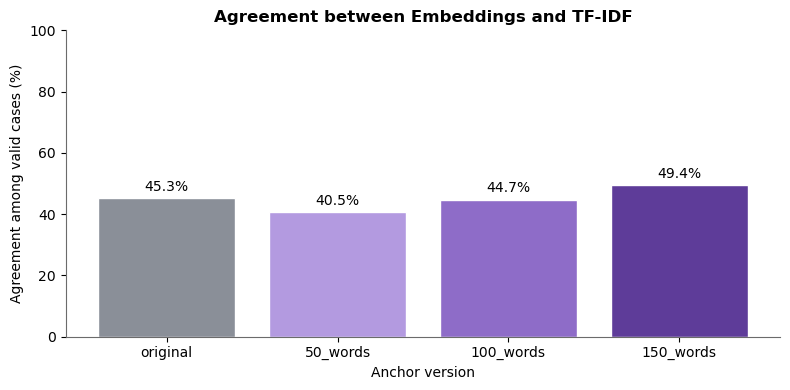

In [26]:
version_summary = []

for version_name, obj in results_by_version.items():
    res = obj["results"]
    mask_valid = res["dimension_embeddings"].notna() & res["dimension_tfidf"].notna()
    rv = res.loc[mask_valid].copy()
    n_valid = len(rv)

    agreement = rv["methods_agree"].mean() if n_valid else np.nan
    kappa = (cohen_kappa_score(rv["dimension_embeddings"], rv["dimension_tfidf"])
             if n_valid > 1 else np.nan)
    if n_valid > 2:
        pearson_r, pearson_p = pearsonr(rv["score_top1_embeddings"], rv["score_top1_tfidf"])
        spearman_r, spearman_p = spearmanr(rv["score_top1_embeddings"], rv["score_top1_tfidf"])
    else:
        pearson_r = pearson_p = spearman_r = spearman_p = np.nan

    n_tfidf_valid = int(res["dimension_tfidf"].notna().sum())
    version_summary.append({
        "anchor_version": version_name,
        "n_datasets": len(res),
        "n_valid_both_methods": n_valid,
        "n_zero_tfidf": len(res) - n_tfidf_valid,
        "tfidf_coverage_%": n_tfidf_valid / len(res) * 100,
        "agreement_valid_%": agreement * 100 if pd.notna(agreement) else np.nan,
        "cohen_kappa_valid": kappa,
        "pearson_scores_top1": pearson_r,
        "p_pearson": pearson_p,
        "spearman_scores_top1": spearman_r,
        "p_spearman": spearman_p,
        "mean_delta_embeddings": res["delta_embeddings"].mean(),
        "mean_delta_tfidf_valid": res.loc[res["dimension_tfidf"].notna(), "delta_tfidf"].mean(),
        "pct_high_band_emb_total": (res["confidence_embeddings"] == "high").mean() * 100,
        "pct_high_band_tfidf_total": (res["confidence_tfidf"] == "high").mean() * 100,
        "pct_high_band_tfidf_valid": (
            (res.loc[res["dimension_tfidf"].notna(), "confidence_tfidf"] == "high").mean() * 100
            if n_tfidf_valid else np.nan
        ),
    })

version_summary = pd.DataFrame(version_summary)
display(version_summary)
print("Note: the delta bands are percentile-based and relative; the proportion in the high band")
print("is not an estimate of accuracy. Agreement and Kappa use only valid cases.")

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(version_summary["anchor_version"], version_summary["agreement_valid_%"],
              color=[VERSION_COLOURS.get(v, NEUTRAL_COLOUR) for v in version_summary["anchor_version"]], edgecolor="white")
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_ylim(0, 100)
ax.set_xlabel("Anchor version")
ax.set_ylabel("Agreement among valid cases (%)")
ax.set_title("Agreement between Embeddings and TF-IDF")
format_x_labels(ax)
plt.tight_layout(); plt.show()

**Rigorous interpretation of the summary by version.**

The table compares agreement, Kappa, lexical coverage and deltas. The metrics do not establish which method is correct: they only measure the relationship between two automatic classifications without *ground truth*. Agreement and Kappa should be read together with `n_valid_both_methods`, while TF-IDF coverage should be analysed separately. Pearson and Spearman compare the top-1 scores on different scales and do not measure categorical agreement. The percentages in the high band are largely determined by the percentiles used to build the bands.

### 7.3 Stability across anchor versions

This analysis answers the question: **does the dimension assigned to a dataset change when the anchor version changes?**

#### Pairwise comparison

For each pair of anchor versions (e.g. "original" vs "50 words", "50 words" vs "100 words"), the percentage of datasets with the same dimension and Cohen's kappa are computed. This makes it possible to see:
- Whether the longer versions produce results more similar to each other than the shorter ones (indicating a stabilisation of the classifications as the detail of the anchors increases);
- Which pairs of versions are the most and the least similar.

#### Stability matrices

The stability matrices show, for each pair of versions, the percentage of agreement. They are computed separately for Embeddings and TF-IDF, which makes it possible to check which of the two methods is more sensitive to variations in the anchors.

High stability indicates that the assigned dimension is not very sensitive to the wording of the anchors tested. It does not, by itself, show that the assigned dimension is the adequate one: two versions may coincide because they share the same lexical bias.


In [27]:
# ── Pairwise comparison with explicit alignment by dataset_id ────────────────
pairwise_comparison = []
for v1, v2 in combinations(ANCHOR_FILES.keys(), 2):
    cols = ["dataset_id", "dimension_embeddings", "dimension_tfidf"]
    r1 = results_by_version[v1]["results"][cols]
    r2 = results_by_version[v2]["results"][cols]
    pair_ = r1.merge(r2, on="dataset_id", how="inner", suffixes=("_v1", "_v2"), validate="one_to_one")
    if len(pair_) != len(datasets):
        raise ValueError(f"Incomplete alignment between {v1} and {v2}: {len(pair_)}/{len(datasets)}")

    mask_emb = pair_["dimension_embeddings_v1"].notna() & pair_["dimension_embeddings_v2"].notna()
    mask_tf = pair_["dimension_tfidf_v1"].notna() & pair_["dimension_tfidf_v2"].notna()
    e1, e2 = pair_.loc[mask_emb, "dimension_embeddings_v1"], pair_.loc[mask_emb, "dimension_embeddings_v2"]
    t1, t2 = pair_.loc[mask_tf, "dimension_tfidf_v1"], pair_.loc[mask_tf, "dimension_tfidf_v2"]

    pairwise_comparison.append({
        "version_1": v1, "version_2": v2,
        "n_valid_emb": int(mask_emb.sum()),
        "agreement_emb_%": (e1.to_numpy() == e2.to_numpy()).mean() * 100 if len(e1) else np.nan,
        "kappa_emb": cohen_kappa_score(e1, e2) if len(e1) > 1 else np.nan,
        "n_valid_tfidf_both": int(mask_tf.sum()),
        "agreement_tfidf_valid_%": (t1.to_numpy() == t2.to_numpy()).mean() * 100 if len(t1) else np.nan,
        "kappa_tfidf_valid": cohen_kappa_score(t1, t2) if len(t1) > 1 else np.nan,
        "agreement_tfidf_coverage_%": (
            pair_["dimension_tfidf_v1"].notna().to_numpy() == pair_["dimension_tfidf_v2"].notna().to_numpy()
        ).mean() * 100,
        "agreement_tfidf_incl_zero_%": (
            pair_["dimension_tfidf_v1"].fillna("Unclassified").to_numpy()
            == pair_["dimension_tfidf_v2"].fillna("Unclassified").to_numpy()
        ).mean() * 100,
    })

pairwise_comparison_df = pd.DataFrame(pairwise_comparison)
display(pairwise_comparison_df)

,version_1,version_2,n_valid_emb,agreement_emb_%,kappa_emb,n_valid_tfidf_both,agreement_tfidf_valid_%,kappa_tfidf_valid,agreement_tfidf_coverage_%,agreement_tfidf_incl_zero_%
0,original,50_words,110,62.727273,0.523558,74,60.810811,0.506893,70.909091,44.545455
1,original,100_words,110,81.818182,0.768665,76,75.000000,0.682078,72.727273,55.454545
2,original,150_words,110,79.090909,0.731764,84,70.238095,0.614537,79.090909,56.363636
3,50_words,100_words,110,72.727273,0.648338,73,68.493151,0.603729,96.363636,75.454545
4,50_words,150_words,110,63.636364,0.522777,73,72.602740,0.649544,88.181818,70.000000
5,100_words,150_words,110,78.181818,0.721137,75,77.333333,0.712060,90.000000,74.545455


**Rigorous interpretation of the comparison between versions.**

The agreement and Kappa of the TF-IDF labels are computed on the cases classified in both versions. The stability of coverage (`classified` versus `Unclassified`) and the agreement including the null category are presented separately. This prevents a persistent absence of lexical overlap from being mistaken for dimensional stability. The four versions are related conditions — they share the same datasets, methods and conceptual framework — and do not constitute independent replications.

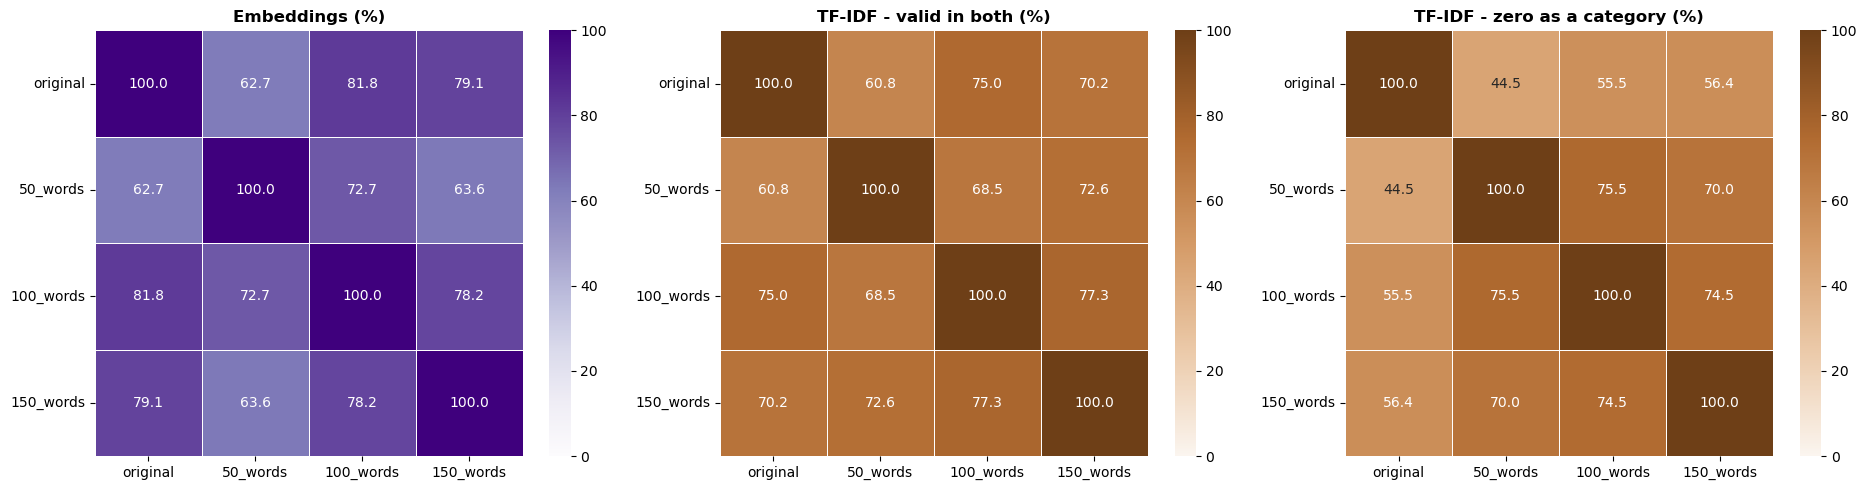

In [28]:
# ── Stability matrices between versions ──────────────────────────────────────
def stability_matrix(method: str, include_zero: bool = False) -> pd.DataFrame:
    """Percentage agreement between versions, with alignment by dataset_id."""
    mapping = {"embeddings": "dimension_embeddings", "tfidf": "dimension_tfidf"}
    if method not in mapping:
        raise ValueError(f"Invalid method: {method!r}. Use 'embeddings' or 'tfidf'.")
    col = mapping[method]
    versions = list(results_by_version)
    matrix = pd.DataFrame(index=versions, columns=versions, dtype=float)
    for v1 in versions:
        for v2 in versions:
            a = results_by_version[v1]["results"][["dataset_id", col]]
            b = results_by_version[v2]["results"][["dataset_id", col]]
            pair_ = a.merge(b, on="dataset_id", suffixes=("_1", "_2"), validate="one_to_one")
            x, y = pair_[f"{col}_1"], pair_[f"{col}_2"]
            if include_zero:
                x, y = x.fillna("Unclassified"), y.fillna("Unclassified")
                mask = pd.Series(True, index=pair_.index)
            else:
                mask = x.notna() & y.notna()
            matrix.loc[v1, v2] = (x[mask].to_numpy() == y[mask].to_numpy()).mean() * 100 if mask.any() else np.nan
    return matrix

stability_embeddings = stability_matrix("embeddings")
stability_tfidf_valid = stability_matrix("tfidf", include_zero=False)
stability_tfidf_with_zero = stability_matrix("tfidf", include_zero=True)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, mat, title_text, cmap in [
    (axes[0], stability_embeddings, "Embeddings", CMAP_EMB),
    (axes[1], stability_tfidf_valid, "TF-IDF - valid in both", CMAP_TFIDF),
    (axes[2], stability_tfidf_with_zero, "TF-IDF - zero as a category", CMAP_TFIDF),
]:
    sns.heatmap(mat, annot=True, fmt=".1f", cmap=cmap, vmin=0, vmax=100, ax=ax, linewidths=.5)
    ax.set_title(title_text + " (%)")
    format_x_labels(ax); horizontal_y_labels(ax)
plt.tight_layout(); plt.show()

**Rigorous interpretation of the matrices.**

The matrices quantify sensitivity to the versions tested, not accuracy. For TF-IDF, two readings are presented: dimensional agreement only on the cases valid in both versions, and overall agreement treating `Unclassified` as a category. The comparison should also consider the denominators and coverage. No universal 80% threshold is assumed, nor a monotonic relationship between the length of the anchors and stability.

### 7.4 Distribution of the classifications by method and version

This analysis shows how many datasets were assigned to each Smart City dimension, separately for each method and anchor version.

#### What we are trying to identify

**Balanced distributions** (each dimension receives a similar number of datasets) are compatible with anchors distinct enough to distribute the datasets across the 6 dimensions; balance is not, however, an objective in itself, because the portal may genuinely have more datasets in some dimensions.

**Excessive concentration** in one or two dimensions may indicate:
- Poorly discriminative anchors: one dimension is worded in a very generic way and "attracts" datasets from other dimensions;
- A real imbalance in the data: the municipality does have more datasets in a given dimension (e.g. much more Environment data than Governance data);
- Problems in the pre-processing: terms specific to one dimension dominate the TF-IDF vocabulary.

The comparison between Embeddings and TF-IDF in this distribution is revealing: if TF-IDF concentrates much more than the Embeddings, this suggests that the lexical representation is being dominated by terms from one or two dimensions, while the semantic representation distributes them in a more balanced way.


Distribution — Embeddings (each column sums to the total n):


anchor_version,original,50_words,100_words,150_words
dimension_embeddings,,,,
Smart Governance,27,17,29,22
Smart Society,1,1,0,1
Smart Mobility,27,23,23,33
Smart Environment,25,50,28,30
Smart Quality of Life,9,8,12,6
Smart Economy,21,11,18,18


Distribution — TF-IDF, including unclassified:


anchor_version,original,50_words,100_words,150_words
dimension_tfidf,,,,
Smart Governance,18,25,18,24
Smart Society,4,2,3,4
Smart Mobility,43,16,20,25
Smart Environment,28,11,18,19
Smart Quality of Life,7,10,9,7
Smart Economy,6,10,8,6
Unclassified,4,36,34,25


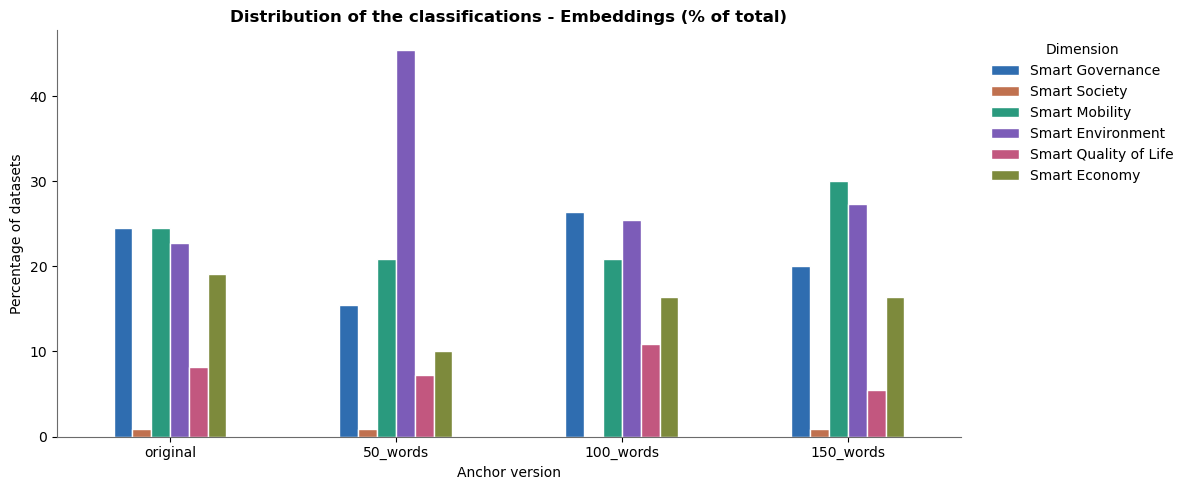

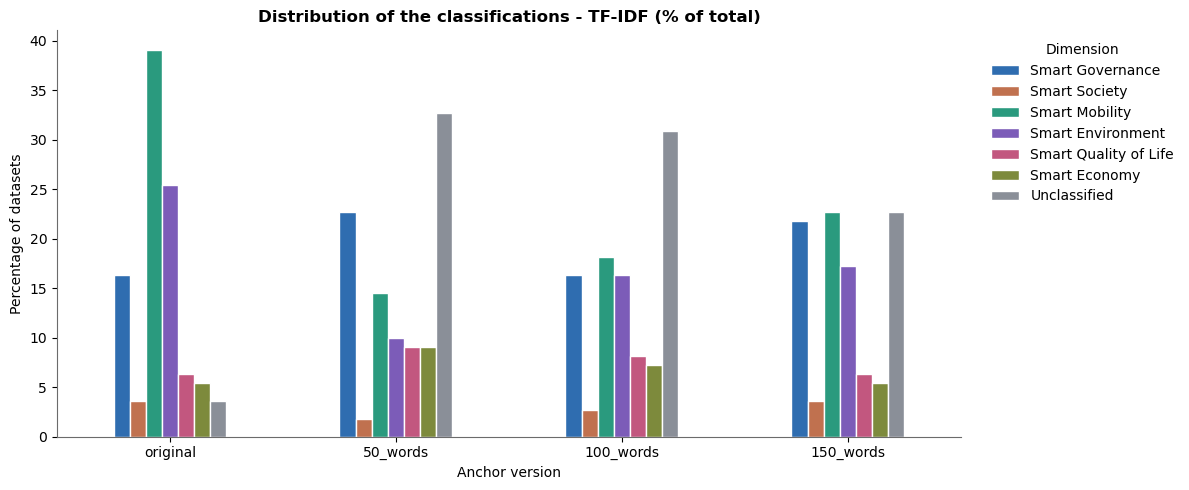

In [29]:
# ── Full distributions, including the absence of a TF-IDF classification ─────
VERSION_ORDER = list(ANCHOR_FILES.keys())
DIMENSION_ORDER = list(next(iter(results_by_version.values()))["scores_embeddings"].columns)

def distribution_table(column_name, include_zero=False):
    df = results_all_versions[["anchor_version", column_name]].copy()
    if include_zero:
        df[column_name] = df[column_name].fillna("Unclassified")
        order = DIMENSION_ORDER + ["Unclassified"]
    else:
        order = DIMENSION_ORDER
    tab = pd.crosstab(df[column_name], df["anchor_version"]).reindex(index=order, columns=VERSION_ORDER, fill_value=0)
    return tab.astype(int)

distribution_emb = distribution_table("dimension_embeddings")
distribution_tfidf = distribution_table("dimension_tfidf", include_zero=True)
print("Distribution — Embeddings (each column sums to the total n):"); display(distribution_emb)
print("Distribution — TF-IDF, including unclassified:"); display(distribution_tfidf)

for table, title_text in [(distribution_emb, "Embeddings"), (distribution_tfidf, "TF-IDF")]:
    dist_pct = table.div(table.sum(axis=0), axis=1).T * 100
    dist_colours = [NEUTRAL_COLOUR if c == "Unclassified" else CATEGORICAL_PALETTE[DIMENSION_ORDER.index(c) % len(CATEGORICAL_PALETTE)]
                  for c in dist_pct.columns]
    ax = dist_pct.plot(kind="bar", figsize=(12, 5), edgecolor="white", color=dist_colours)
    ax.set_title(f"Distribution of the classifications - {title_text} (% of total)")
    ax.set_xlabel("Anchor version"); ax.set_ylabel("Percentage of datasets")
    ax.legend(title="Dimension", bbox_to_anchor=(1.02, 1), loc="upper left")
    format_x_labels(ax)
    plt.tight_layout(); plt.show()

**Rigorous interpretation of the distribution.**

The frequencies describe the output of the classifier and not, on their own, the real thematic composition of the portal. The concentration in Mobility and Governance may reflect the corpus, the anchors, the model or the quality of the metadata. A balanced distribution is not a methodological objective. In TF-IDF, `Unclassified` is kept as a category and all percentages use the total number of datasets, making it possible to compare versions without hidden denominators.

#### 7.4.1 Weight of the document series in the assignments

Cross-tabulation, in the original version of the anchors, of the dimension assigned by each method with the series identified in 4.1.1. It supports the counts in Sections 4.8 and 5.1 of the dissertation (for example, the share of the Mobility assignments that belongs to each series).

In [30]:
# ── 7.4.1 Assigned dimension × document series (original version) ────────────
_r0 = results_by_version["original"]["results"].set_index("dataset_id")
_series = SERIES_BY_ID.reindex(_r0.index)
for _met, _lbl in [("embeddings", "Embeddings"), ("tfidf", "TF-IDF")]:
    _dim = _r0[f"dimension_{_met}"].fillna("Unclassified").str.replace("Smart ", "", regex=False)
    _ct = pd.crosstab(_dim, _series, margins=True, margins_name="Total")
    DISSERTATION_COUNTS[f"Dimension×series {_lbl}"] = _ct.reset_index()
    print(f"\n{_lbl} — original version: assigned dimension × document series")
    display(_ct)
_mob = _r0["dimension_embeddings"] == "Smart Mobility"
print("\nMobility assignments in the embeddings (original version), by series:")
display(_series[_mob].value_counts().rename("n").to_frame())
_mob_t = _r0["dimension_tfidf"] == "Smart Mobility"
print("Mobility assignments in TF-IDF (original version), by series:")
display(_series[_mob_t].value_counts().rename("n").to_frame())


Embeddings — original version: assigned dimension × document series


series,'Layer de geometria tipo…' layers,Outside the series,Points of interest,Records with 'PDM' in the name,Total
dimension_embeddings,,,,,
Economy,0,7,14,0,21
Environment,6,9,3,7,25
Governance,4,13,4,6,27
Mobility,14,5,4,4,27
Quality of Life,0,5,0,4,9
Society,0,0,1,0,1
Total,24,39,26,21,110



TF-IDF — original version: assigned dimension × document series


series,'Layer de geometria tipo…' layers,Outside the series,Points of interest,Records with 'PDM' in the name,Total
dimension_tfidf,,,,,
Economy,1,5,0,0,6
Environment,6,9,0,13,28
Governance,0,13,1,4,18
Mobility,10,8,22,3,43
Quality of Life,3,1,2,1,7
Society,0,3,1,0,4
Unclassified,4,0,0,0,4
Total,24,39,26,21,110



Mobility assignments in the embeddings (original version), by series:


,n
series,
'Layer de geometria tipo…' layers,14
Outside the series,5
Points of interest,4
Records with 'PDM' in the name,4


Mobility assignments in TF-IDF (original version), by series:


,n
series,
Points of interest,22
'Layer de geometria tipo…' layers,10
Outside the series,8
Records with 'PDM' in the name,3


### 7.5 Relative delta bands by version and method

The delta is the difference between the two highest scores. The labels “low”, “medium” and “high” correspond to the empirical tertiles of each method×version combination. They are relative ordinal bands, not probabilities or levels of accuracy. In TF-IDF, “null” means an absence of lexical overlap with all the anchors.

Confidence — Embeddings:


anchor_version,original,50_words,100_words,150_words
confidence_level,,,,
Null,0,0,0,0
Low,36,36,36,36
Medium,36,36,36,36
High,38,38,38,38


Confidence — TF-IDF:


anchor_version,original,50_words,100_words,150_words
confidence_level,,,,
Null,4,36,34,25
Low,35,25,25,28
Medium,35,24,25,28
High,36,25,26,29


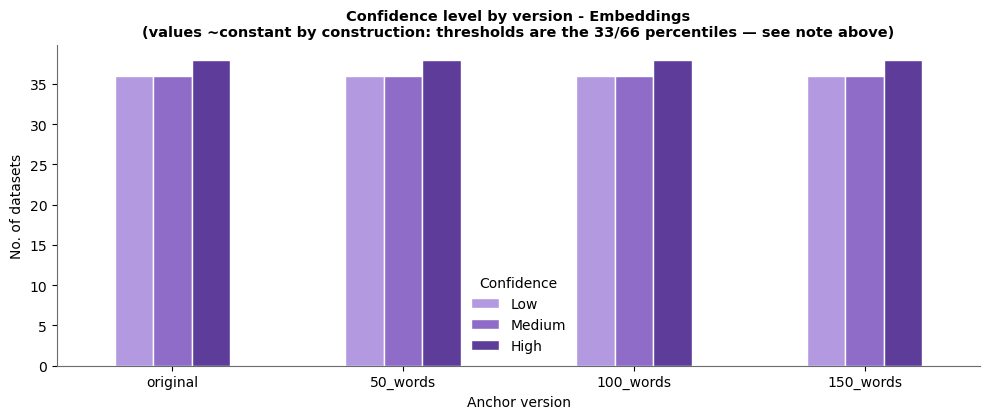

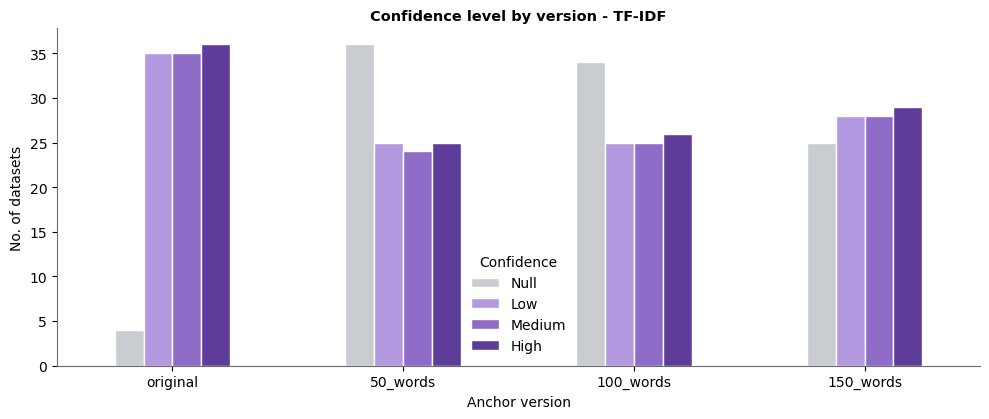

In [31]:
# ── Distribution of the confidence levels ─────────────────────────────────────
confidence_by_version = []

for version_name, obj in results_by_version.items():
    res = obj["results"]
    for col_real, method_name in [
        ("confidence_embeddings", "Embeddings"),
        ("confidence_tfidf",      "TF-IDF"),
    ]:
        counts = res[col_real].astype(str).str.strip().str.lower().value_counts()
        for level in ["null", "low", "medium", "high"]:
            confidence_by_version.append({
                "anchor_version" : version_name,
                "method"         : method_name,
                "confidence_level": level.capitalize(),
                "n_datasets"     : int(counts.get(level, 0)),
            })

confidence_by_version = pd.DataFrame(confidence_by_version)

# Pivot tables
for method_name in ["Embeddings", "TF-IDF"]:
    pivot = (
        confidence_by_version[confidence_by_version["method"] == method_name]
        .pivot_table(index="confidence_level", columns="anchor_version",
                     values="n_datasets", fill_value=0)
        .reindex(["Null", "Low", "Medium", "High"])
        .reindex(columns=VERSION_ORDER)   # logical order of the versions
        .fillna(0).astype(int)
    )
    print(f"Confidence — {method_name}:")
    display(pivot)

# ── Confidence charts ─────────────────────────────────────────────────────────
# NOTE: the Embeddings chart shows practically the SAME values in the 4
# versions — this is expected, not an error. The confidence thresholds are
# adaptive by percentile (33/66 — see Section 2.3), which guarantees, by
# mathematical construction, that ~33% of the datasets fall into "low", ~33% into
# "medium" and ~34% into "high" in ANY version. The TF-IDF chart does vary
# informatively between versions because it has a 4th category, "Null"
# (datasets without a classification), whose proportion is not fixed by percentile —
# it is this "Null" bar that carries the real information in this chart.
for col_real, method_name in [
    ("confidence_embeddings", "Embeddings"),
    ("confidence_tfidf",      "TF-IDF"),
]:
    conf_df = (
        results_all_versions
        .groupby(["anchor_version", col_real])
        .size()
        .reset_index(name="n")
        .pivot(index="anchor_version", columns=col_real, values="n")
        .reindex(index=VERSION_ORDER)     # logical order of the versions
        .reindex(columns=["null", "low", "medium", "high"], fill_value=0)
        .rename(columns={"null": "Null", "low": "Low", "medium": "Medium", "high": "High"})
        .fillna(0)
    )
    # Keep only columns that exist (avoids empty columns if there is no "null")
    conf_df = conf_df[[c for c in conf_df.columns if conf_df[c].sum() > 0]]
    colour_map = CONFIDENCE_COLOURS
    colours = [colour_map[c] for c in conf_df.columns]

    title_text = f"Confidence level by version - {method_name}"
    if method_name == "Embeddings":
        title_text += "\n(values ~constant by construction: thresholds are the 33/66 percentiles — see note above)"

    fig, ax = plt.subplots(figsize=(10, 4.3))
    conf_df.plot(kind="bar", ax=ax, color=colours, edgecolor="white")
    ax.set_title(title_text, fontsize=10.5)
    ax.set_xlabel("Anchor version")
    ax.set_ylabel("No. of datasets")
    format_x_labels(ax)
    ax.legend(title="Confidence")
    plt.tight_layout()
    plt.show()


**Rigorous interpretation of the delta bands.**

The almost constant distribution of the low, medium and high bands is a consequence of the percentiles used. The substantively variable information in TF-IDF is above all the number of null cases. To compare real separation between versions, the continuous deltas, the top-1/top-2 scores and the transitions of the same datasets between bands should be used.

### 7.6 Agreement matrices between Embeddings and TF-IDF

The agreement matrices cross the classifications of the two methods: the rows represent the dimension assigned by the Embeddings, and the columns represent the dimension assigned by TF-IDF. The values on the diagonal correspond to datasets on which the two methods agree.

#### How should the off-diagonal values be interpreted?

Each off-diagonal cell `(i, j)` represents datasets that the Embeddings classified in dimension `i` but TF-IDF classified in dimension `j`. These are the cases of disagreement. Systematic patterns of disagreement (e.g. the Embeddings systematically classify as "Mobility" what TF-IDF classifies as "Environment") may indicate:

1. **Semantic overlap between dimensions**: the two dimensions share vocabulary or concepts, and the two methods "choose different sides";
2. **Insufficiently distinct anchors**: the anchor texts of the two dimensions are similar enough for small differences in the text of the dataset or in the representation method to lead to different classifications;
3. **Real ambiguity of the dataset**: the dataset genuinely cuts across the two dimensions.

Off-diagonal datasets deserve priority in the manual review, because the two methods do not converge on the same dimension. Agreement on the diagonal is not equivalent to accuracy either.

Note: datasets without a TF-IDF classification (`score = 0`) are shown in a separate `Unclassified` column; the Embeddings always assign a dimension.


original: total n=110; TF-IDF valid=106; zero=4


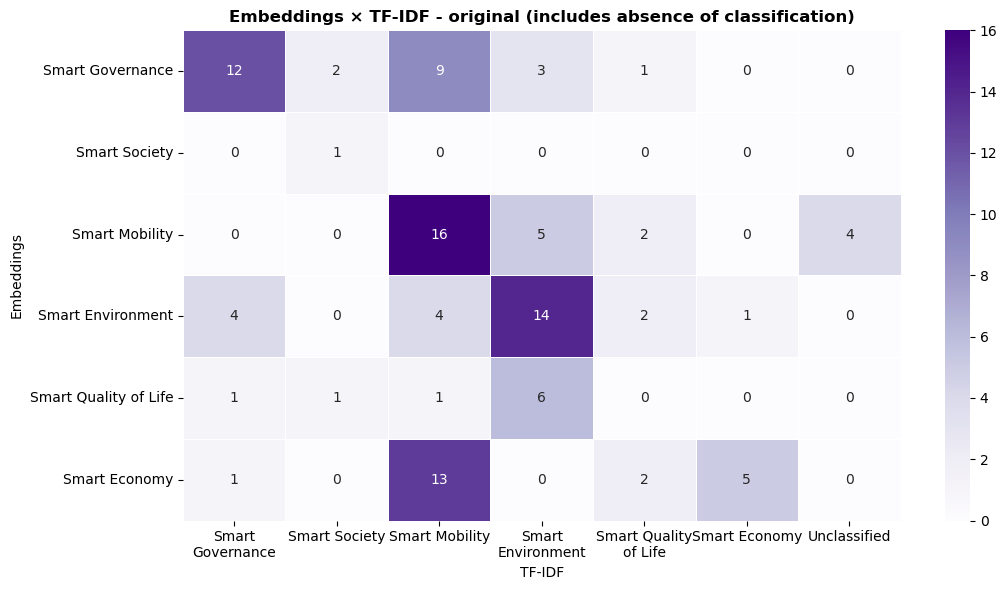

50_words: total n=110; TF-IDF valid=74; zero=36


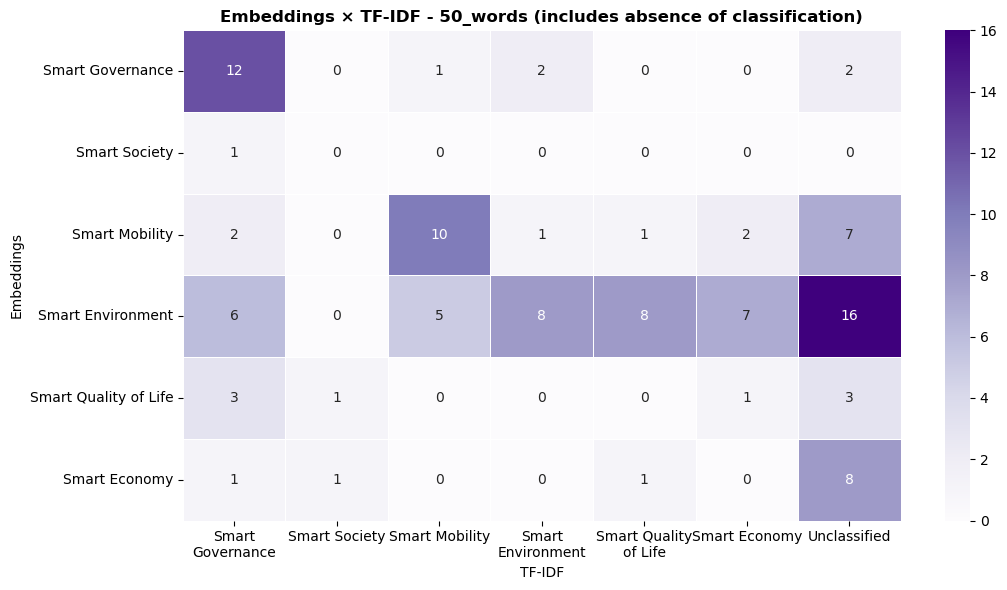

100_words: total n=110; TF-IDF valid=76; zero=34


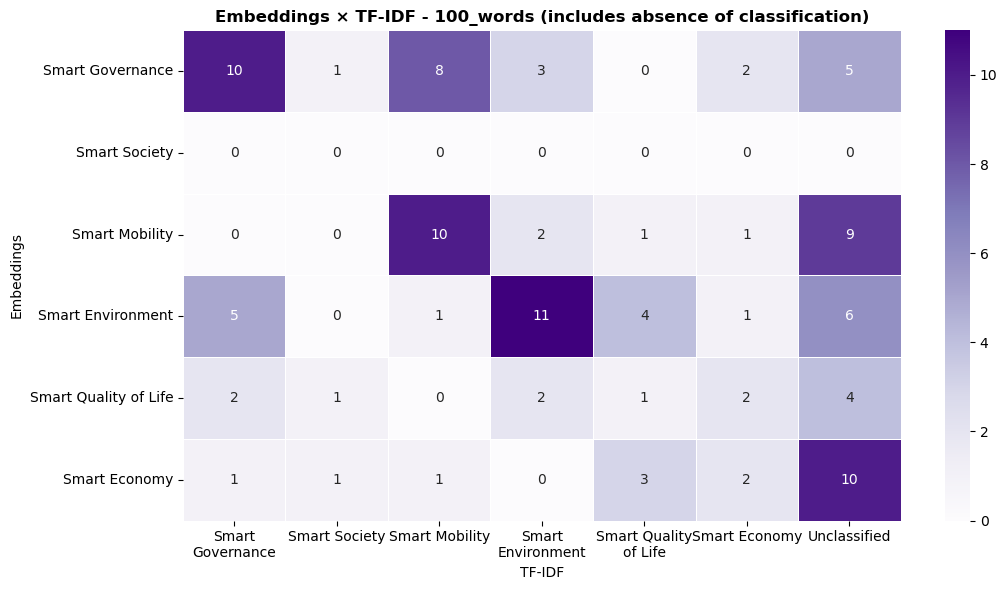

150_words: total n=110; TF-IDF valid=85; zero=25


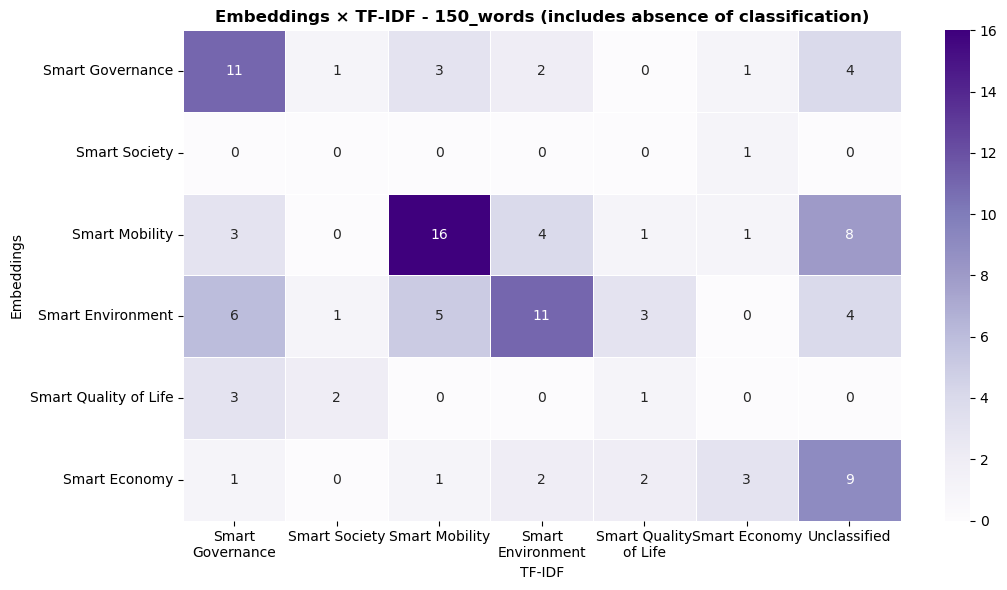

In [32]:
# ── Full and valid contingency matrices ──────────────────────────────────────
for version_name, obj in results_by_version.items():
    res = obj["results"].copy()
    dims = list(obj["scores_embeddings"].columns)
    res["dimension_tfidf_display"] = res["dimension_tfidf"].fillna("Unclassified")
    column_order = dims + ["Unclassified"]
    mat_total = pd.crosstab(res["dimension_embeddings"], res["dimension_tfidf_display"]).reindex(
        index=dims, columns=column_order, fill_value=0)
    n_valid = res["dimension_tfidf"].notna().sum()
    print(f"{version_name}: total n={len(res)}; TF-IDF valid={n_valid}; zero={len(res)-n_valid}")
    fig, ax = plt.subplots(figsize=(11, 6))
    sns.heatmap(mat_total, annot=True, fmt="d", cmap=CMAP_EMB, ax=ax, linewidths=.5)
    ax.set_title(f"Embeddings × TF-IDF - {version_name} (includes absence of classification)")
    ax.set_xlabel("TF-IDF"); ax.set_ylabel("Embeddings")
    format_x_labels(ax); horizontal_y_labels(ax)
    plt.tight_layout(); plt.show()

**Rigorous interpretation of the contingency matrices.**

The diagonal represents categorical agreement and the remaining values represent different combinations, without indicating which method is correct. The `Unclassified` column makes the limited coverage of TF-IDF visible. The matrices should be analysed together with the Kappa and the denominators. Recurring disagreements are priority candidates for human review, not proof of the superiority of a method.

### 7.7 Similarity profile with all dimensions

The classification assigns each dataset to the dimension with the highest score, but this does not, by itself,
reveal how differentiated that choice is from the other five dimensions. Two datasets may
both be classified as "Smart Mobility" with the same top-1 score, but one of them
may have that score clearly above all the other dimensions (unequivocal classification)
while the other has five practically tied scores (ambiguous classification, in which the
"victory" of the chosen dimension is minimal). The final classification alone does not distinguish
these two cases - both appear as "Smart Mobility, score X".

This section directly addresses that limitation by showing the **full score profile**, the cosine similarity coefficients with **all 6 dimensions simultaneously**, per dataset,
through four complementary elements:

**A) Heatmap per dataset (sample)**: a grid in which each row is a dataset and each column
a Smart City dimension; the colour represents the value of the score. It allows a quick visual reading:
a row with a single cell much darker than the others indicates clear separation;
a row with similar colours in all cells indicates ambiguity. The heatmap is produced for each of the four anchor versions. The sample of ~25
datasets is selected to include a mixture of clear and ambiguous cases (not just the
"best" examples), so that the heatmap is representative of the real variability of the
corpus, and not only of the cases most favourable to the method.

**B) Table with the 6 scores per dataset** (one per version and method): the same information as the heatmap in tabular form,
sortable and with the exact numerical values, for the datasets for which visual inspection of the
heatmap suggests a need for precise confirmation of the numbers.

**C) Aggregate separation margin**: as a complement to the visualisations per dataset, the
mean margin between the top-1 score and the mean of the other 5 scores is computed, aggregated by
anchor version and by method. This metric answers the question "on average, how clear is the
separation in this corpus?", serving as quantitative context for interpreting the
individual cases shown in the heatmap and in the table.



**D) Boxplot of the distribution of the scores and of the separation margin**: the three previous
visualisations show individual cases (heatmap, table) or only the aggregate mean/median
(part C). The boxplot complements them by showing the **full distribution** of the top-1 score,
the top-2 score and the separation margin, for **all the datasets** of each version (not
just the sample of 25 used in the heatmap) — including the dispersion (quartiles), the median and the
outliers. This makes it possible to answer questions that the mean alone does not reveal: is the separation
between dimensions consistent across the whole corpus, or is there great variability (some
very clear datasets and others very ambiguous)? The boxplot is built side by side for
Embeddings and TF-IDF and repeated for each anchor version, facilitating direct comparison between
methods and between versions.

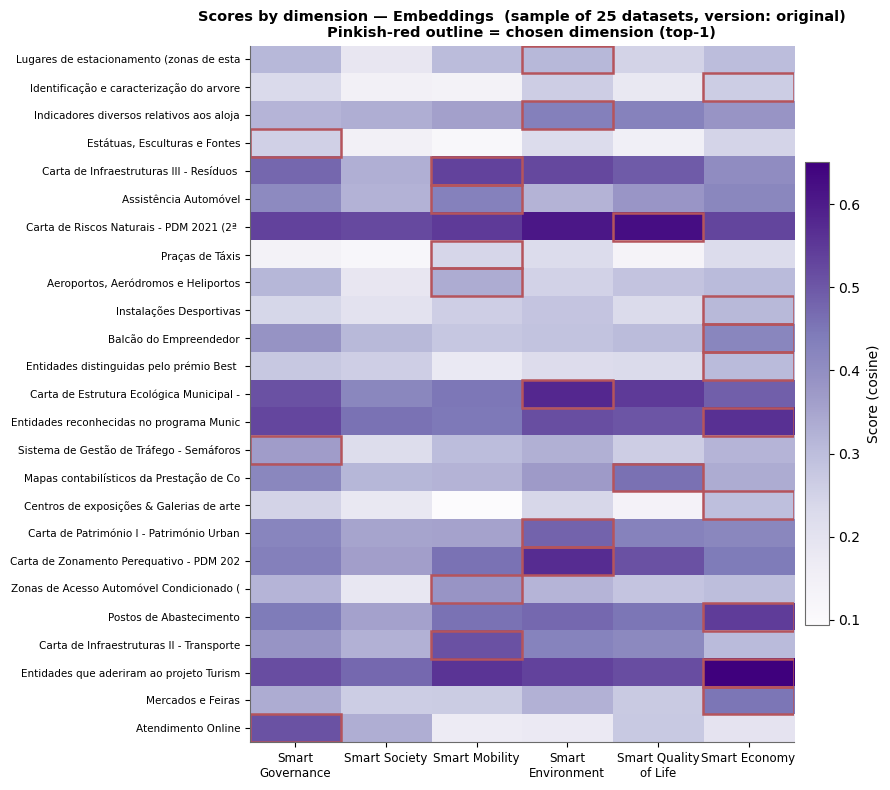


Embeddings — table of scores per dataset (version: original)


,dataset_id,dataset_title,Smart Governance,Smart Society,Smart Mobility,Smart Environment,Smart Quality of Life,Smart Economy,chosen_dimension,delta
0,e36c4036-c04b-43bd-a97a-8af6eaba3b6e,Lugares de estacionamento (zonas de estacionamento pago) - Zona Ocidental,0.3114,0.1866,0.3022,0.3117,0.2485,0.3009,Smart Environment,0.0004
1,7991ece6-0793-4702-ad23-570e76627a82,Identificação e caracterização do arvoredo do Município do Porto,0.2312,0.1468,0.1375,0.2618,0.1818,0.2636,Smart Economy,0.0018
2,efc78042-7d36-4656-803e-357bc3c6828e,Indicadores diversos relativos aos alojamentos no concelho do Porto (Resultados Definitivos Censos 2021),0.3188,0.3306,0.3599,0.4313,0.4268,0.3833,Smart Environment,0.0045
3,157807f3-b2f6-4044-9a3e-55e3648f8369,"Estátuas, Esculturas e Fontes",0.2552,0.1473,0.1111,0.2257,0.1532,0.2476,Smart Governance,0.0076
4,d605b309-3c77-4582-970b-3f323d8ccd21,"Carta de Infraestruturas III - Resíduos Sólidos Urbanos, Oleoduto, Gás e Telecomunicações - PDM 2021",0.4743,0.3286,0.5340,0.5247,0.4956,0.4042,Smart Mobility,0.0094
5,a2cb97cb-b203-4025-a4ec-6995b860fa9d,Assistência Automóvel,0.4101,0.3236,0.4302,0.3215,0.3814,0.4157,Smart Mobility,0.0145
6,d3977614-54d6-4e53-99a1-75a73afd8a9a,Carta de Riscos Naturais - PDM 2021 (2ª Alteração por Adaptação),0.5335,0.5236,0.5475,0.6088,0.6248,0.5285,Smart Quality of Life,0.0160
7,30fdce9e-83e3-4b27-8b3c-ad21a7d9040f,Praças de Táxis,0.1382,0.1153,0.2431,0.2240,0.1292,0.2250,Smart Mobility,0.0181
8,4e274c73-76f8-4905-b505-7ab8d5f23fa0,"Aeroportos, Aeródromos e Heliportos",0.3131,0.1859,0.3360,0.2521,0.2855,0.3056,Smart Mobility,0.0229
9,67e59f60-1f71-4059-bd78-523f9b7cb014,Instalações Desportivas,0.2406,0.2017,0.2600,0.2826,0.2301,0.3102,Smart Economy,0.0275


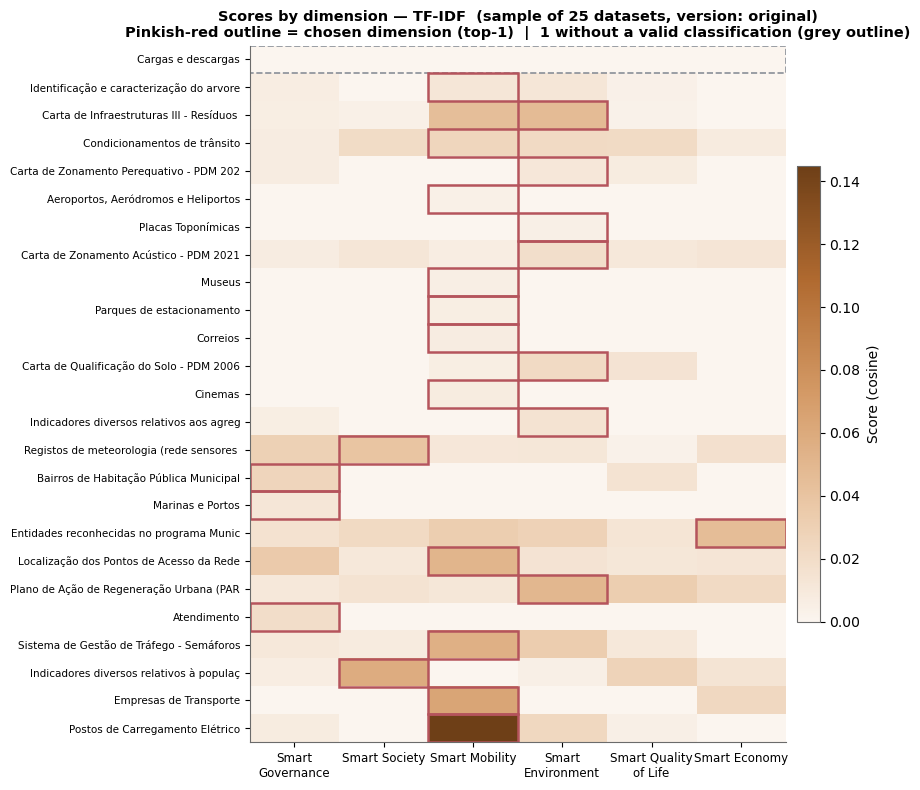


TF-IDF — table of scores per dataset (version: original)


,dataset_id,dataset_title,Smart Governance,Smart Society,Smart Mobility,Smart Environment,Smart Quality of Life,Smart Economy,chosen_dimension,delta
0,563cc44a-a778-45ac-ae21-0a6445e10e01,Cargas e descargas,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
1,7991ece6-0793-4702-ad23-570e76627a82,Identificação e caracterização do arvoredo do Município do Porto,0.0067,0.0000,0.0122,0.0121,0.0039,0.0000,Smart Mobility,0.0001
2,d605b309-3c77-4582-970b-3f323d8ccd21,"Carta de Infraestruturas III - Resíduos Sólidos Urbanos, Oleoduto, Gás e Telecomunicações - PDM 2021",0.0062,0.0044,0.0445,0.0465,0.0032,0.0000,Smart Environment,0.0019
3,ee4a4efe-b6f9-45e7-9b7b-0aeeca689dda,Condicionamentos de trânsito,0.0069,0.0207,0.0249,0.0218,0.0210,0.0081,Smart Mobility,0.0032
4,bcaeb7c7-1239-4526-b572-817cca7d46d9,Carta de Zonamento Perequativo - PDM 2021,0.0072,0.0000,0.0000,0.0109,0.0074,0.0000,Smart Environment,0.0035
5,4e274c73-76f8-4905-b505-7ab8d5f23fa0,"Aeroportos, Aeródromos e Heliportos",0.0000,0.0000,0.0042,0.0000,0.0000,0.0000,Smart Mobility,0.0042
6,edf049d4-19fd-4395-a54c-78d26bfb5c64,Placas Toponímicas,0.0000,0.0000,0.0000,0.0046,0.0000,0.0000,Smart Environment,0.0046
7,0322ed5c-ceae-4efb-8437-f78b40f9fc0f,Carta de Zonamento Acústico - PDM 2021,0.0072,0.0122,0.0062,0.0183,0.0104,0.0129,Smart Environment,0.0054
8,43a5d0fe-6938-4d98-ab6c-aeafbf8e38e3,Museus,0.0000,0.0000,0.0056,0.0000,0.0000,0.0000,Smart Mobility,0.0056
9,76ee1e86-2756-414a-a438-e942f17f1e88,Parques de estacionamento,0.0000,0.0000,0.0062,0.0000,0.0000,0.0000,Smart Mobility,0.0062


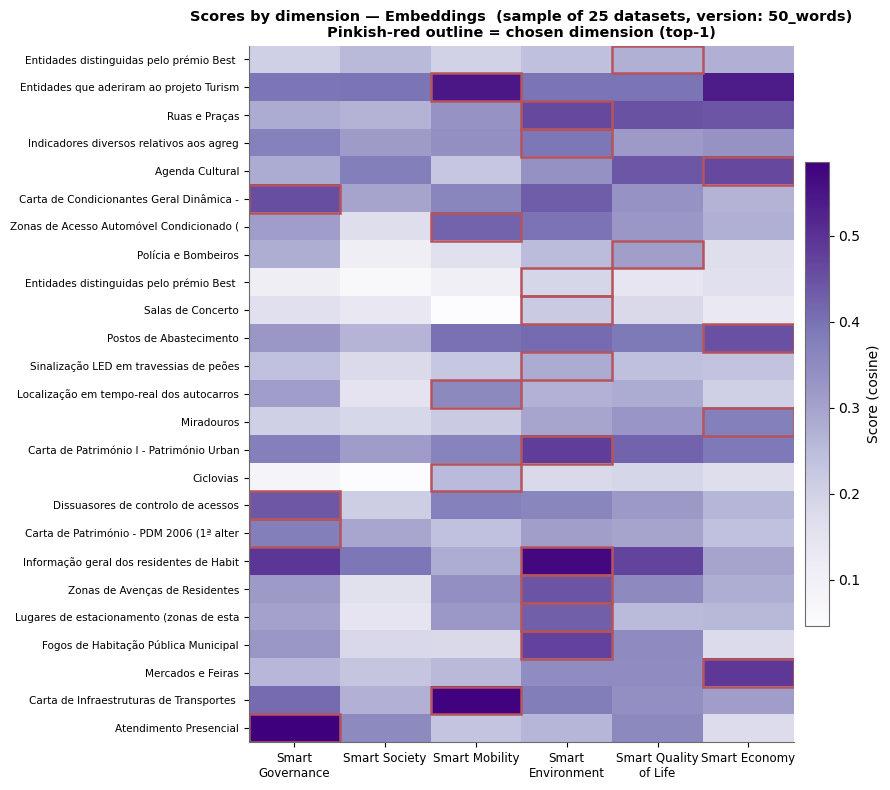


Embeddings — table of scores per dataset (version: 50_words)


,dataset_id,dataset_title,Smart Governance,Smart Society,Smart Mobility,Smart Environment,Smart Quality of Life,Smart Economy,chosen_dimension,delta
0,24b5cf01-5ae2-49ec-a38e-d4490d94f654,"Entidades distinguidas pelo prémio Best of Wine Tourism, pertencentes ao grupo Best of Club - Porto",0.2061,0.2545,0.1996,0.2419,0.2756,0.2737,Smart Quality of Life,0.0019
1,7074013f-28da-45b8-99bf-5677df9bb1ce,Entidades que aderiram ao projeto Turismo Industrial,0.3926,0.3948,0.5445,0.3958,0.3957,0.5367,Smart Mobility,0.0079
2,7391c6e4-5678-4817-9ca3-f03cc0251549,Ruas e Praças,0.2833,0.2672,0.3336,0.4628,0.4488,0.4430,Smart Environment,0.0140
3,bdc98601-2ce1-4769-8df7-a765c5e1d817,Indicadores diversos relativos aos agregados domésticos privados e institucionais no concelho do Porto (Resultados Definitivos Censos 2021),0.3728,0.3130,0.3411,0.3904,0.3158,0.3323,Smart Environment,0.0176
4,8f4316c7-aafe-488f-a8b0-5e721ae37637,Agenda Cultural,0.2837,0.3787,0.2270,0.3370,0.4423,0.4623,Smart Economy,0.0200
5,d4e25418-a180-4927-affd-5748f4c94811,Carta de Condicionantes Geral Dinâmica - PDM 2021,0.4545,0.2988,0.3605,0.4312,0.3315,0.2672,Smart Governance,0.0233
6,39381f0c-0018-4f79-ac72-aadde6f4d996,Zonas de Acesso Automóvel Condicionado (ZAAC) - implementado,0.3087,0.1680,0.4225,0.3966,0.3232,0.2749,Smart Mobility,0.0258
7,a7d1b91e-b525-4e73-a479-60d4dd46f729,Polícia e Bombeiros,0.2785,0.1071,0.1592,0.2498,0.3063,0.1679,Smart Quality of Life,0.0278
8,ad678248-a650-43af-a80e-c9adf5157db5,"Entidades distinguidas pelo prémio Best of Wine Tourism, GWC - Porto",0.1078,0.0645,0.1046,0.1900,0.1406,0.1602,Smart Environment,0.0298
9,2c8ffe2f-d34a-4fe2-a8f3-d9170ed59a34,Salas de Concerto,0.1596,0.1332,0.0465,0.2171,0.1830,0.1277,Smart Environment,0.0340


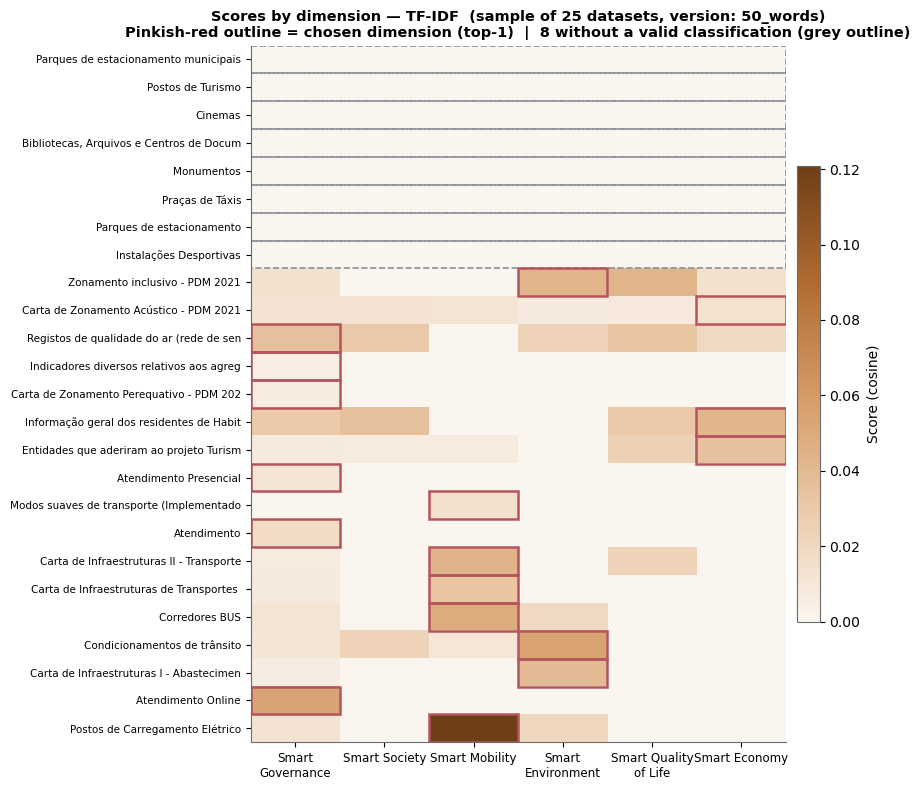


TF-IDF — table of scores per dataset (version: 50_words)


,dataset_id,dataset_title,Smart Governance,Smart Society,Smart Mobility,Smart Environment,Smart Quality of Life,Smart Economy,chosen_dimension,delta
0,37dc9216-0b42-4eb8-9817-7d85309e6def,Parques de estacionamento municipais,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
1,d229735e-4c7a-41e9-b7f3-d4a85d8c6bfe,Postos de Turismo,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
2,87b9c3c4-7cda-404a-8662-9f016383f15b,Cinemas,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
3,c829e8e4-4b82-4e91-a7ef-b9f7d557f14c,"Bibliotecas, Arquivos e Centros de Documentação",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
4,ea52029a-5d95-42ef-8a7e-518b86d74e9f,Monumentos,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
5,30fdce9e-83e3-4b27-8b3c-ad21a7d9040f,Praças de Táxis,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
6,76ee1e86-2756-414a-a438-e942f17f1e88,Parques de estacionamento,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
7,67e59f60-1f71-4059-bd78-523f9b7cb014,Instalações Desportivas,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
8,ae750547-4908-4189-b798-613397267932,Zonamento inclusivo - PDM 2021,0.0135,0.0000,0.0000,0.0428,0.0427,0.0142,Smart Environment,0.0002
9,0322ed5c-ceae-4efb-8437-f78b40f9fc0f,Carta de Zonamento Acústico - PDM 2021,0.0122,0.0119,0.0117,0.0080,0.0083,0.0129,Smart Economy,0.0007


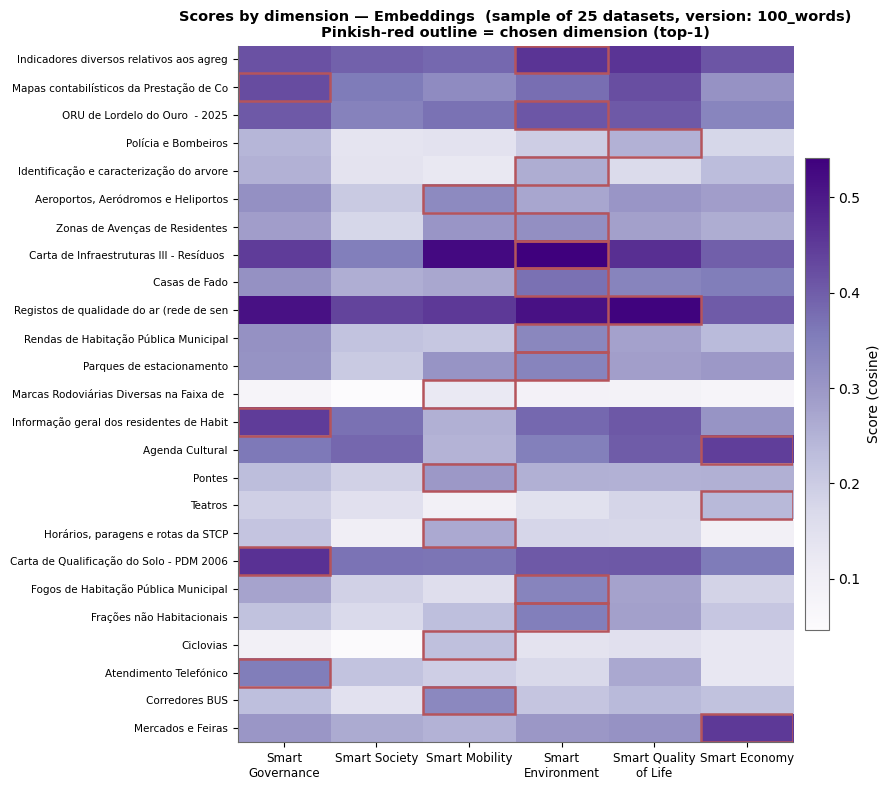


Embeddings — table of scores per dataset (version: 100_words)


,dataset_id,dataset_title,Smart Governance,Smart Society,Smart Mobility,Smart Environment,Smart Quality of Life,Smart Economy,chosen_dimension,delta
0,bdc98601-2ce1-4769-8df7-a765c5e1d817,Indicadores diversos relativos aos agregados domésticos privados e institucionais no concelho do Porto (Resultados Definitivos Censos 2021),0.4171,0.3927,0.3840,0.4602,0.4596,0.4114,Smart Environment,0.0006
1,7941698f-fde6-49bd-9b1f-e5c3e524fbaa,Mapas contabilísticos da Prestação de Contas do Município do Porto - desde 2020,0.4239,0.3560,0.3241,0.3755,0.4217,0.3097,Smart Governance,0.0022
2,fae824b5-028e-4baf-b99a-aea82c258cca,ORU de Lordelo do Ouro - 2025,0.4054,0.3442,0.3709,0.4100,0.4053,0.3371,Smart Environment,0.0046
3,a7d1b91e-b525-4e73-a479-60d4dd46f729,Polícia e Bombeiros,0.2449,0.1360,0.1420,0.1952,0.2524,0.1774,Smart Quality of Life,0.0076
4,7991ece6-0793-4702-ad23-570e76627a82,Identificação e caracterização do arvoredo do Município do Porto,0.2513,0.1409,0.1242,0.2595,0.1671,0.2317,Smart Environment,0.0082
5,4e274c73-76f8-4905-b505-7ab8d5f23fa0,"Aeroportos, Aeródromos e Heliportos",0.3151,0.2037,0.3280,0.2721,0.3024,0.2875,Smart Mobility,0.0129
6,6ae3a002-4db2-493c-a61f-ac08b19a1065,Zonas de Avenças de Residentes,0.2877,0.1767,0.3022,0.3164,0.2832,0.2606,Smart Environment,0.0142
7,d605b309-3c77-4582-970b-3f323d8ccd21,"Carta de Infraestruturas III - Resíduos Sólidos Urbanos, Oleoduto, Gás e Telecomunicações - PDM 2021",0.4487,0.3511,0.5258,0.5417,0.4673,0.3981,Smart Environment,0.0160
8,2b986d30-7f51-4a75-9347-e7219db022fc,Casas de Fado,0.3130,0.2587,0.2705,0.3726,0.3396,0.3534,Smart Environment,0.0192
9,fa51efff-f8d1-44aa-aad7-699271caba33,Registos de qualidade do ar (rede de sensores da Porto Digital),0.5139,0.4364,0.4526,0.5130,0.5341,0.4027,Smart Quality of Life,0.0203


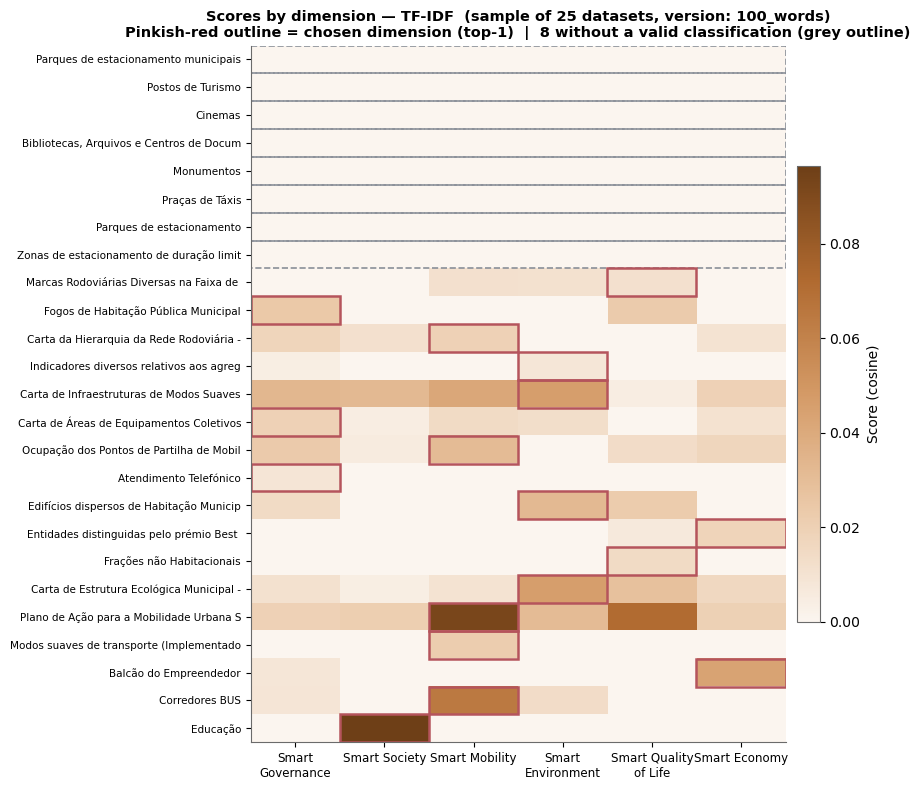


TF-IDF — table of scores per dataset (version: 100_words)


,dataset_id,dataset_title,Smart Governance,Smart Society,Smart Mobility,Smart Environment,Smart Quality of Life,Smart Economy,chosen_dimension,delta
0,37dc9216-0b42-4eb8-9817-7d85309e6def,Parques de estacionamento municipais,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
1,d229735e-4c7a-41e9-b7f3-d4a85d8c6bfe,Postos de Turismo,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
2,87b9c3c4-7cda-404a-8662-9f016383f15b,Cinemas,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
3,c829e8e4-4b82-4e91-a7ef-b9f7d557f14c,"Bibliotecas, Arquivos e Centros de Documentação",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
4,ea52029a-5d95-42ef-8a7e-518b86d74e9f,Monumentos,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
5,30fdce9e-83e3-4b27-8b3c-ad21a7d9040f,Praças de Táxis,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
6,76ee1e86-2756-414a-a438-e942f17f1e88,Parques de estacionamento,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
7,cd19a422-3631-497b-a792-6baaab7e210d,Zonas de estacionamento de duração limitada (ZEDL),0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
8,ce94dc9c-5f9b-4382-93a4-eb05b1300311,Marcas Rodoviárias Diversas na Faixa de Rodagem,0.0000,0.0000,0.0110,0.0107,0.0112,0.0000,Smart Quality of Life,0.0002
9,50ca9236-5abf-499b-a464-c18881cbf9b9,Fogos de Habitação Pública Municipal,0.0239,0.0000,0.0000,0.0000,0.0227,0.0000,Smart Governance,0.0012


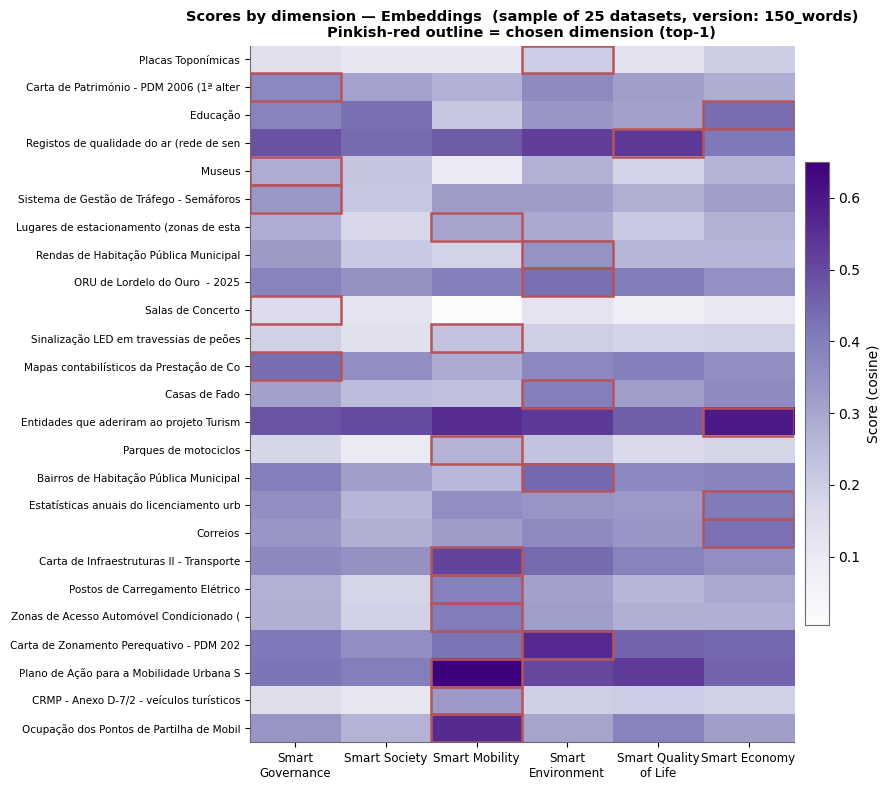


Embeddings — table of scores per dataset (version: 150_words)


,dataset_id,dataset_title,Smart Governance,Smart Society,Smart Mobility,Smart Environment,Smart Quality of Life,Smart Economy,chosen_dimension,delta
0,edf049d4-19fd-4395-a54c-78d26bfb5c64,Placas Toponímicas,0.1450,0.1150,0.1109,0.2018,0.1347,0.1989,Smart Environment,0.0029
1,4f5c5cc8-98cf-45d3-8326-95bbaec3f253,Carta de Património - PDM 2006 (1ª alteração),0.3750,0.3111,0.2726,0.3706,0.3164,0.2817,Smart Governance,0.0045
2,53cad240-48b9-4fc9-8a66-9f559037903d,Educação,0.3869,0.4284,0.2170,0.3383,0.3122,0.4345,Smart Economy,0.0061
3,fa51efff-f8d1-44aa-aad7-699271caba33,Registos de qualidade do ar (rede de sensores da Porto Digital),0.4866,0.4398,0.4678,0.5225,0.5314,0.4133,Smart Quality of Life,0.0089
4,43a5d0fe-6938-4d98-ab6c-aeafbf8e38e3,Museus,0.2844,0.2232,0.0981,0.2734,0.1835,0.2650,Smart Governance,0.0109
5,8c1d79b0-38c1-46de-b072-d4726bddb330,Sistema de Gestão de Tráfego - Semáforos,0.3353,0.2192,0.3234,0.3210,0.2763,0.3155,Smart Governance,0.0119
6,e36c4036-c04b-43bd-a97a-8af6eaba3b6e,Lugares de estacionamento (zonas de estacionamento pago) - Zona Ocidental,0.2864,0.1728,0.3030,0.2903,0.2088,0.2715,Smart Mobility,0.0128
7,4372e1f9-527b-4e78-8ee3-0e681eab4f5a,Rendas de Habitação Pública Municipal,0.3258,0.2133,0.1833,0.3472,0.2632,0.2601,Smart Environment,0.0214
8,fae824b5-028e-4baf-b99a-aea82c258cca,ORU de Lordelo do Ouro - 2025,0.3879,0.3517,0.3962,0.4321,0.4074,0.3545,Smart Environment,0.0247
9,2c8ffe2f-d34a-4fe2-a8f3-d9170ed59a34,Salas de Concerto,0.1537,0.1257,0.0043,0.1237,0.0796,0.1092,Smart Governance,0.0280


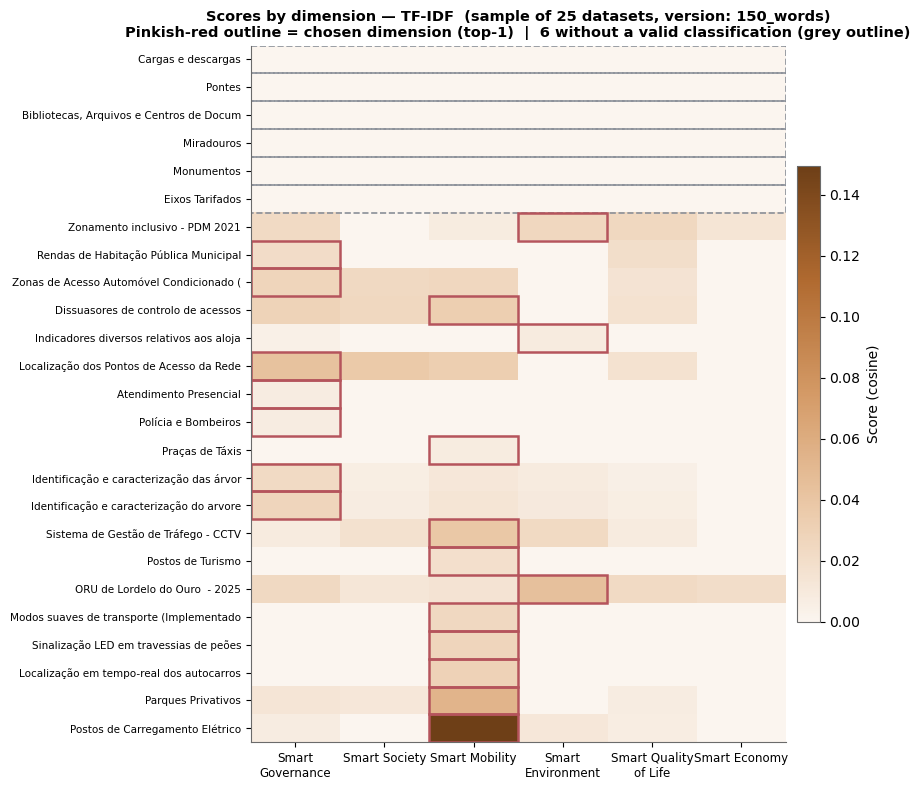


TF-IDF — table of scores per dataset (version: 150_words)


,dataset_id,dataset_title,Smart Governance,Smart Society,Smart Mobility,Smart Environment,Smart Quality of Life,Smart Economy,chosen_dimension,delta
0,563cc44a-a778-45ac-ae21-0a6445e10e01,Cargas e descargas,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
1,2ed9a072-0687-4151-9835-65f69d53d1a3,Pontes,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
2,c829e8e4-4b82-4e91-a7ef-b9f7d557f14c,"Bibliotecas, Arquivos e Centros de Documentação",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
3,11317990-0956-4829-95ea-6fcb40f704bc,Miradouros,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
4,ea52029a-5d95-42ef-8a7e-518b86d74e9f,Monumentos,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
5,8268905b-f234-4f74-883a-cdf049dac54e,Eixos Tarifados,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
6,ae750547-4908-4189-b798-613397267932,Zonamento inclusivo - PDM 2021,0.0225,0.0000,0.0080,0.0256,0.0251,0.0136,Smart Environment,0.0005
7,4372e1f9-527b-4e78-8ee3-0e681eab4f5a,Rendas de Habitação Pública Municipal,0.0208,0.0000,0.0000,0.0000,0.0195,0.0000,Smart Governance,0.0013
8,39381f0c-0018-4f79-ac72-aadde6f4d996,Zonas de Acesso Automóvel Condicionado (ZAAC) - implementado,0.0274,0.0236,0.0254,0.0000,0.0151,0.0000,Smart Governance,0.0020
9,ae46bb29-a647-4c57-bb79-64c6b48f2af5,Dissuasores de controlo de acessos,0.0289,0.0250,0.0324,0.0000,0.0160,0.0000,Smart Mobility,0.0034



Aggregate separation margin (score_top1 − mean of the other 5 scores):

  original:
    Embeddings — mean margin: 0.0984  |  median: 0.0918  |  std: 0.0399
    TF-IDF     — mean margin: 0.0199  |  median: 0.0141  |  std: 0.0195

  50_words:
    Embeddings — mean margin: 0.1324  |  median: 0.1201  |  std: 0.0539
    TF-IDF     — mean margin: 0.0194  |  median: 0.0139  |  std: 0.0221

  100_words:
    Embeddings — mean margin: 0.0902  |  median: 0.0828  |  std: 0.0366
    TF-IDF     — mean margin: 0.0167  |  median: 0.0141  |  std: 0.0181

  150_words:
    Embeddings — mean margin: 0.1004  |  median: 0.0919  |  std: 0.0424
    TF-IDF     — mean margin: 0.0183  |  median: 0.0149  |  std: 0.0198

Interpretation: a margin close to 0 indicates that several scores are similar
— the classification may be ambiguous. A high margin indicates clear separation.


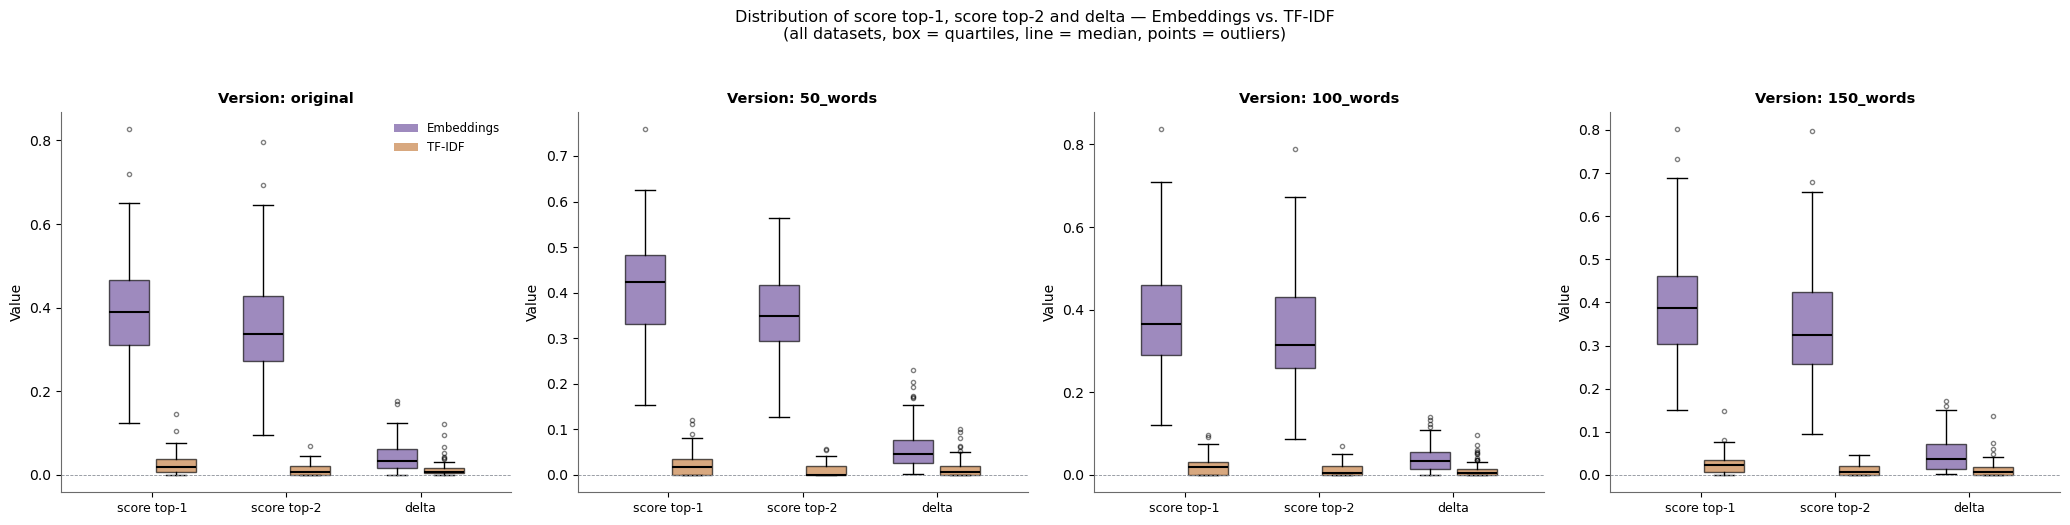


How to read this boxplot:
  - Narrow box high or low on the axis → consistently high/low scores across the whole corpus.
  - Wide box (much dispersion)        → large variability between datasets — some very
    clear, others very ambiguous.
  - 'delta' close to 0 with a narrow box → systematic ambiguity (not just a
    problem of a few isolated datasets, but a general pattern of the method/version).
  - Isolated points above/below the 'whiskers' → outliers: datasets with confidence much
    above or below the usual (see also Section 7.8, delta outliers on a log scale).


In [33]:
import matplotlib.colors as mcolors

VERSIONS   = list(results_by_version.keys())
N_VERSIONS = len(VERSIONS)
N_SAMPLE = 25  # no. of datasets to show in the heatmap/table per version



def select_representative_sample(res: pd.DataFrame, col_delta: str, n: int) -> pd.DataFrame:
    """
    Selects a sample of n datasets covering the spectrum of observed deltas
    (not only the most favourable cases), dividing the distribution into n groups
    by percentile and choosing one representative dataset from each group.
    Ensures that the sample includes both cases of clear separation and
    ambiguous cases, reflecting the real variability of the corpus.
    """
    res_valid = res.dropna(subset=[col_delta]).sort_values(col_delta).reset_index(drop=True)
    if len(res_valid) <= n:
        return res_valid
    indices = np.linspace(0, len(res_valid) - 1, n).round().astype(int)
    return res_valid.iloc[indices].reset_index(drop=True)


# ── A) and B) for each anchor version ─────────────────────────────────────────
for sample_version in VERSIONS:
    for method, col_delta, score_prefix in [
        ("Embeddings", "delta_embeddings", "score_emb_"),
        ("TF-IDF",     "delta_tfidf",      "score_tfidf_"),
    ]:
        res = results_by_version[sample_version]["results"]
        score_cols = [c for c in res.columns if c.startswith(score_prefix)]
        dims_ord   = [c.replace(score_prefix, "") for c in score_cols]

        sample = select_representative_sample(res, col_delta, N_SAMPLE)

        # ── A) Heatmap datasets × dimensions ─────────────────────────────────────
        matrix = sample[score_cols].values
        labels_y = sample["dataset_title"].astype(str).str.slice(0, 40).values

        # The outline follows the actual classification column (see get_classification),
        # not an argmax over the scores: rows with score=0 everywhere (no lexical overlap
        # in TF-IDF) have dimension_tfidf = None and therefore receive no outline.
        chosen_dim_col = f"dimension_{'embeddings' if method == 'Embeddings' else 'tfidf'}"
        sample_dimensions = sample[chosen_dim_col].values

        fig, ax = plt.subplots(figsize=(9, max(6, 0.32 * len(sample))))
        im = ax.imshow(matrix, cmap=CMAP_EMB if method == "Embeddings" else CMAP_TFIDF, aspect="auto")

        ax.set_xticks(range(len(dims_ord)))
        ax.set_xticklabels(dims_ord, fontsize=8.5)
        format_x_labels(ax)
        ax.set_yticks(range(len(sample)))
        ax.set_yticklabels(labels_y, fontsize=7.5)

        n_unclassified = 0
        for row_idx, chosen_dim in enumerate(sample_dimensions):
            if pd.isna(chosen_dim):
                # No valid classification: mark the whole row with a
                # dashed grey hatching instead of pretending there was a choice —
                # it visually communicates "no dimension was assigned here".
                ax.add_patch(plt.Rectangle(
                    (-0.5, row_idx - 0.5), len(dims_ord), 1,
                    fill=False, edgecolor=NEUTRAL_COLOUR, linewidth=1.2, linestyle="--",
                ))
                n_unclassified += 1
            else:
                top1_col_idx = dims_ord.index(chosen_dim)
                ax.add_patch(plt.Rectangle(
                    (top1_col_idx - 0.5, row_idx - 0.5), 1, 1,
                    fill=False, edgecolor=HIGHLIGHT_COLOUR, linewidth=1.8,
                ))

        fig.colorbar(im, ax=ax, label="Score (cosine)", fraction=0.04, pad=0.02)
        extra_legend = (f"  |  {n_unclassified} without a valid classification (grey outline)"
                         if n_unclassified > 0 else "")
        ax.set_title(f"Scores by dimension — {method}  (sample of {len(sample)} datasets, version: {sample_version})\n"
                    f"Pinkish-red outline = chosen dimension (top-1){extra_legend}", fontsize=10.5, fontweight="bold")
        plt.tight_layout()
        plt.show()

        # ── B) Table with the 6 scores per dataset ────────────────────────────────
        table = sample[["dataset_id", "dataset_title"] + score_cols].copy()
        table.columns = ["dataset_id", "dataset_title"] + dims_ord
        for d in dims_ord:
            table[d] = table[d].round(4)
        table["chosen_dimension"] = sample[f"dimension_{'embeddings' if method == 'Embeddings' else 'tfidf'}"].values
        table["delta"] = sample[col_delta].round(4).values

        print(f"\n{method} — table of scores per dataset (version: {sample_version})")
        display(table.reset_index(drop=True))


# ── C) Aggregate separation margin (score_top1 − mean of the others) ─────────
print("\nAggregate separation margin (score_top1 − mean of the other 5 scores):")
print("=" * 70)
for version in VERSIONS:
    res = results_by_version[version]["results"]
    score_cols_emb   = [c for c in res.columns if c.startswith("score_emb_")]
    score_cols_tfidf = [c for c in res.columns if c.startswith("score_tfidf_")]

    def margin(row, top1_col, score_cols):
        top1 = row[top1_col]
        others = [row[c] for c in score_cols if row[c] != top1]
        return top1 - (sum(others) / len(others)) if others else 0

    if score_cols_emb:
        m_emb = res.apply(lambda r: margin(r, "score_top1_embeddings", score_cols_emb), axis=1)
        m_tfidf = res.apply(lambda r: margin(r, "score_top1_tfidf", score_cols_tfidf), axis=1) if score_cols_tfidf else None

        print(f"\n  {version}:")
        print(f"    Embeddings — mean margin: {m_emb.mean():.4f}  |  median: {m_emb.median():.4f}  |  std: {m_emb.std():.4f}")
        if m_tfidf is not None:
            print(f"    TF-IDF     — mean margin: {m_tfidf.mean():.4f}  |  median: {m_tfidf.median():.4f}  |  std: {m_tfidf.std():.4f}")

print("\nInterpretation: a margin close to 0 indicates that several scores are similar")
print("— the classification may be ambiguous. A high margin indicates clear separation.")


# ── D) Boxplot of the distribution of the scores and of the separation margin ─
#
# Complements part C (which only shows mean/median/standard deviation as
# text) with a visualisation of the FULL distribution — quartiles, median and
# outliers — for ALL the datasets of each version, not just the sample of
# 25 used in the heatmap. Built side by side for Embeddings and TF-IDF, and
# repeated for each anchor version.
#
# Three quantities are compared in each boxplot:
#   - score_top1 : the score of the assigned dimension — the higher it is, the more
#                  "confident" the similarity found;
#   - score_top2 : the score of the second closest dimension — used as a
#                  reference to see whether score_top1 stands out from it;
#   - delta      : score_top1 − score_top2 — the separation margin itself,
#                  the central confidence measure used in the rest of the notebook.

fig, axes = plt.subplots(1, N_VERSIONS, figsize=(5.2 * N_VERSIONS, 5), sharey=False)
if N_VERSIONS == 1:
    axes = [axes]

for ax, version in zip(axes, VERSIONS):
    res = results_by_version[version]["results"]

    # Build a "long" DataFrame (one row per value) for the boxplot,
    # crossing method (Embeddings/TF-IDF) with quantity (top1/top2/delta).
    records = []
    for method, suf in [("Embeddings", "embeddings"), ("TF-IDF", "tfidf")]:
        for quantity, col in [
            ("score_top1", f"score_top1_{suf}"),
            ("score_top2", f"score_top2_{suf}"),
            ("delta",      f"delta_{suf}"),
        ]:
            for value_ in res[col].dropna().values:
                records.append({"method": method, "quantity": quantity, "value": value_})

    df_box = pd.DataFrame(records)

    # Grouped boxplot: positions side by side by quantity, colour by method
    quantities = ["score_top1", "score_top2", "delta"]
    methods   = ["Embeddings", "TF-IDF"]
    box_colours = {"Embeddings": EMB_COLOUR, "TF-IDF": TFIDF_COLOUR}

    width_chars = 0.35
    base_positions = np.arange(len(quantities))

    for j, method in enumerate(methods):
        method_data = [
            df_box.loc[(df_box["method"] == method) & (df_box["quantity"] == g), "value"].values
            for g in quantities
        ]
        offset = (-width_chars / 2) if j == 0 else (width_chars / 2)
        bp = ax.boxplot(
            method_data,
            positions=base_positions + offset,
            widths=width_chars * 0.85,
            patch_artist=True,
            showfliers=True,
            flierprops=dict(marker="o", markersize=3, alpha=0.5),
            medianprops=dict(color="black", linewidth=1.5),
        )
        for box in bp["boxes"]:
            box.set_facecolor(box_colours[method])
            box.set_alpha(0.65)

    ax.set_xticks(base_positions)
    ax.set_xticklabels(["score top-1", "score top-2", "delta"], fontsize=9)
    format_x_labels(ax)
    ax.set_ylabel("Value")
    ax.set_title(f"Version: {version}", fontsize=10.5)
    ax.axhline(0, color=NEUTRAL_COLOUR, linewidth=0.6, linestyle="--")

    # Manual legend (only once, in the first subplot)
    if version == VERSIONS[0]:
        handles = [plt.Rectangle((0, 0), 1, 1, facecolor=box_colours[m], alpha=0.65) for m in methods]
        ax.legend(handles, methods, fontsize=8.5, loc="upper right")

fig.suptitle(
    "Distribution of score top-1, score top-2 and delta — Embeddings vs. TF-IDF\n"
    "(all datasets, box = quartiles, line = median, points = outliers)",
    fontsize=11.5, y=1.04,
)
plt.tight_layout()
plt.show()

print("\nHow to read this boxplot:")
print("  - Narrow box high or low on the axis → consistently high/low scores across the whole corpus.")
print("  - Wide box (much dispersion)        → large variability between datasets — some very")
print("    clear, others very ambiguous.")
print("  - 'delta' close to 0 with a narrow box → systematic ambiguity (not just a")
print("    problem of a few isolated datasets, but a general pattern of the method/version).")
print("  - Isolated points above/below the 'whiskers' → outliers: datasets with confidence much")
print("    above or below the usual (see also Section 7.8, delta outliers on a log scale).")


**Analysis of the results (7.7 — Similarity profile with all dimensions).**

The Embeddings heatmap (part A) illustrates the continuous nature of this method: in each row, the six
dimensions keep intermediate scores, without the dimensions not chosen dropping to zero. The embeddings place
the dimensions at different distances in the vector space, but never «discard» them.

The TF-IDF heatmap (part A, second method) shows the opposite: most cells have a score close to zero, with
the highest values concentrated in a few dimensions. In the 50-word version, datasets such as «Parques de
estacionamento municipais», «Postos de Turismo» and «Cinemas» appear marked as «no valid
classification» (score = 0 in all six dimensions). The number of rows without a valid classification in the sample of 25 datasets varies with the version (1 in the original, 8 in the 50-word and 100-word versions and 6 in the 150-word version).

Part D (boxplots) quantifies the difference in scale between methods: the median top-1 score of the Embeddings
(about 0.37-0.42 in the four versions) is an order of magnitude higher than the median top-1 score of
TF-IDF (about 0.017-0.023, including null profiles). This is why the confidence thresholds
(Section 2.3) are computed separately for each method.

### 7.7.1 Shannon entropy — relative concentration of the scores

This section summarises the concentration of the score profile across the six dimensions. As the
embedding similarities may be negative and the scores are not probabilities, each
profile is shifted by its own minimum and normalised to sum to one. The Shannon
entropy of these **relative weights** is then divided by `ln(6)`, producing an index between
0 and 1: higher values correspond to relatively more uniform profiles and lower values
to greater concentration in one or a few dimensions.

The index is purely descriptive: it does not represent a probability of being correct, calibrated
uncertainty or validity of the assigned dimension. Interpretation should rely on the comparison
between versions and methods and on the observed distribution, not on universal thresholds.

In TF-IDF, a row with all scores equal to zero means an absence of lexical overlap,
not maximum ambiguity. These cases are therefore excluded from the calculation of the
entropy and counted separately as `n_no_lexical_evidence`. This separation prevents
versions with lower lexical coverage from showing artificially high entropy.


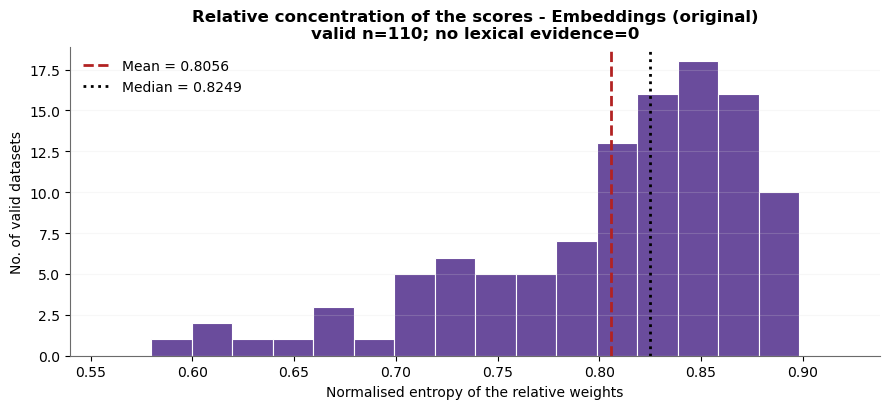

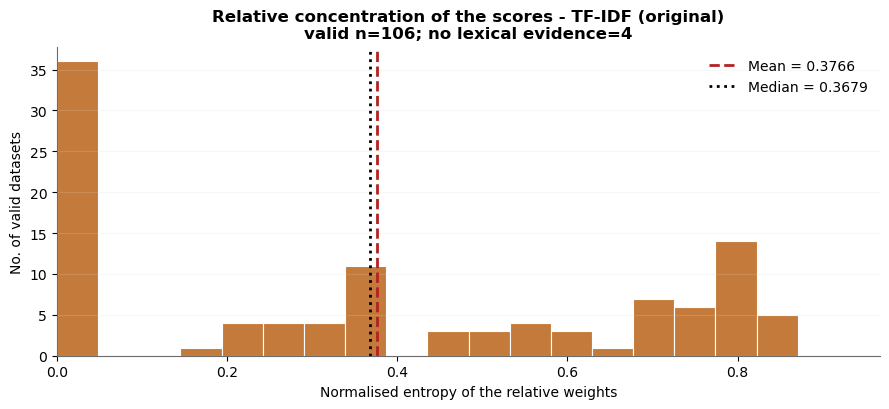

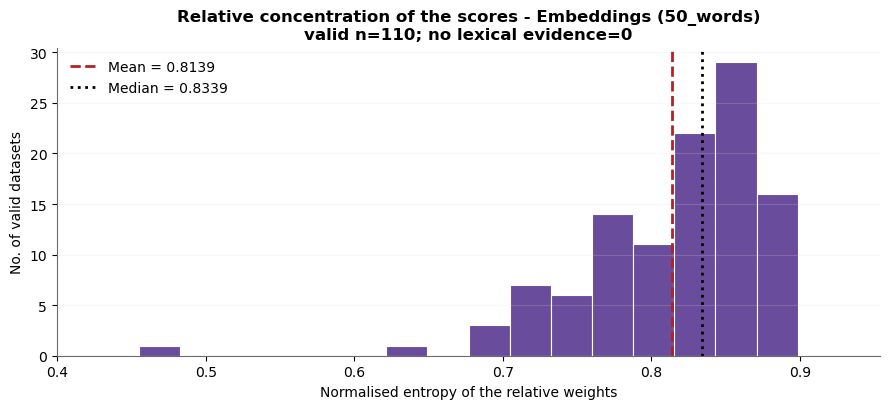

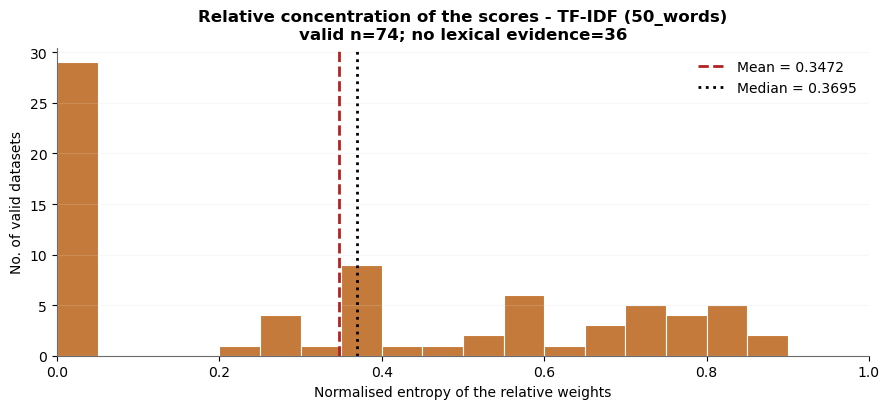

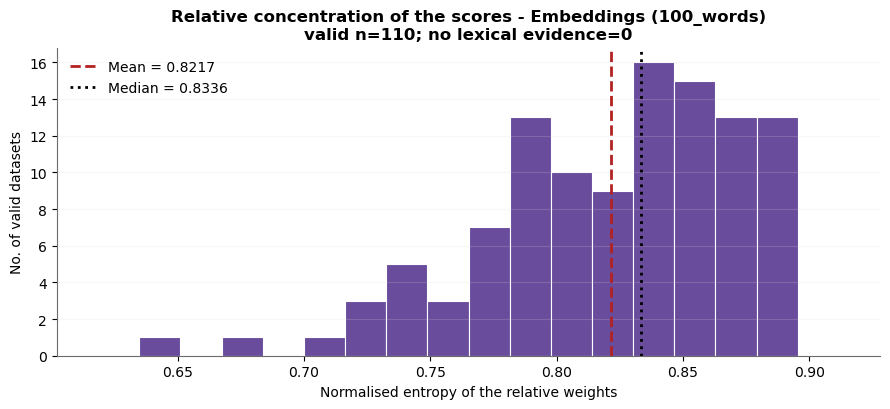

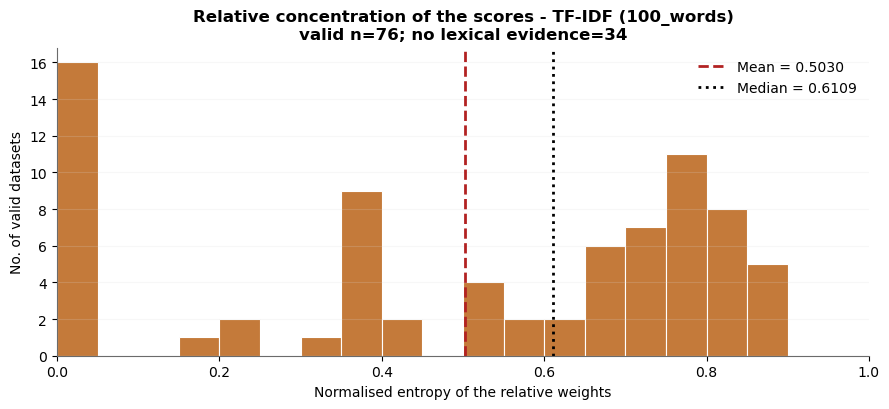

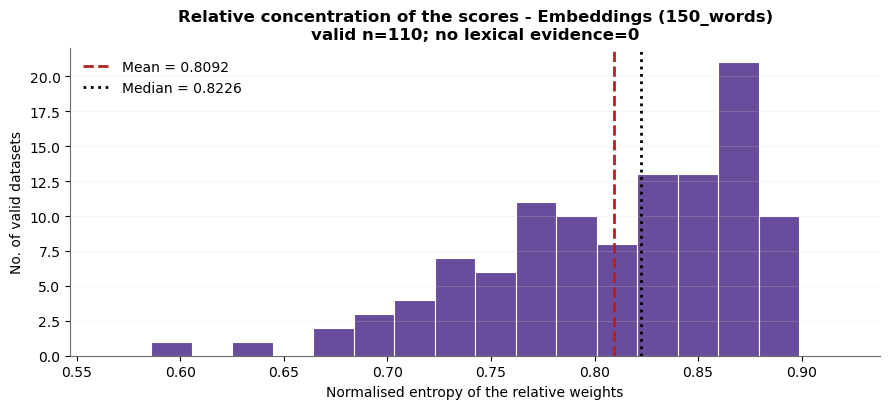

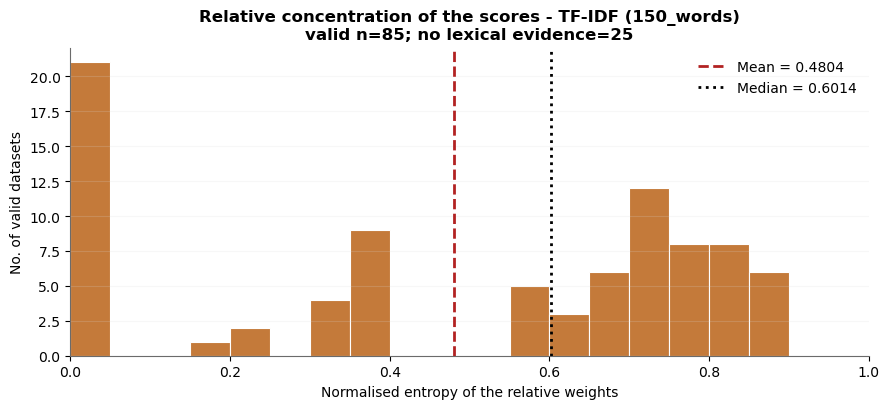

n_total  n_valid_entropy  n_no_lexical_evidence  \
version   method                                                        
original  Embeddings      110              110                      0   
          TF-IDF          110              106                      4   
50_words  Embeddings      110              110                      0   
          TF-IDF          110               74                     36   
100_words Embeddings      110              110                      0   
          TF-IDF          110               76                     34   
150_words Embeddings      110              110                      0   
          TF-IDF          110               85                     25   

                      n_non_finite  mean_normalised_entropy    median  \
version   method                                                        
original  Embeddings             0                 0.805586  0.824882   
          TF-IDF                 0                 0.376616  0.367883   
50_words  Embeddings             0                 0.813928  0.833916   
          TF-IDF                 0                 0.347227  0.369461   
100_words Embeddings             0                 0.821673  0.833593   
          TF-IDF                 0                 0.503012  0.610891   
150_words Embeddings             0                 0.809201  0.822580   
          TF-IDF                 0                 0.480362  0.601364   

                           p25       p75   minimum   maximum  
version   method                                              
original  Embeddings  0.775314  0.857829  0.585929  0.892016  
          TF-IDF      0.000000  0.723455  0.000000  0.841269  
50_words  Embeddings  0.781381  0.857729  0.463694  0.889951  
          TF-IDF      0.000000  0.660229  0.000000  0.884633  
100_words Embeddings  0.790173  0.859432  0.639882  0.890445  
          TF-IDF      0.303847  0.760035  0.000000  0.879807  
150_words Embeddings  0.774803  0.862667  0.591999  0.892705  
          TF-IDF      0.164553  0.756691  0.000000  0.897968

Note: fully zero TF-IDF profiles are reported separately and are not included in the entropy.
The relative weights are not calibrated classification probabilities.


In [34]:
entropy_summary = []

def relative_weights_rows(x):
    """Converts finite scores into relative weights by shifting to the minimum."""
    x = np.asarray(x, dtype=float)
    shifted = x - np.min(x, axis=1, keepdims=True)
    denominator = shifted.sum(axis=1, keepdims=True)
    rel_weights = np.divide(shifted, denominator, out=np.zeros_like(shifted), where=denominator > 0)
    constant_profiles = denominator.ravel() == 0
    rel_weights[constant_profiles] = 1.0 / x.shape[1]
    return rel_weights

def histogram_limits(values_, min_margin=0.01):
    values_ = np.asarray(values_, dtype=float)
    minimum, maximum = float(np.min(values_)), float(np.max(values_))
    score_span = maximum - minimum
    margin = max(min_margin, score_span * 0.15)
    lower_bound, upper_bound = max(0.0, minimum - margin), min(1.0, maximum + margin)
    if upper_bound - lower_bound < 0.02:
        centre = (lower_bound + upper_bound) / 2
        lower_bound, upper_bound = max(0.0, centre - 0.01), min(1.0, centre + 0.01)
    if upper_bound <= lower_bound:
        lower_bound, upper_bound = 0.98, 1.0
    return lower_bound, upper_bound

for version_name, obj in results_by_version.items():
    for method_name, scores_df in [("Embeddings", obj["scores_embeddings"]), ("TF-IDF", obj["scores_tfidf"])]:
        values_ = scores_df.to_numpy(dtype=float)
        n_total = len(values_)
        mask_finite = np.isfinite(values_).all(axis=1)
        n_non_finite = int((~mask_finite).sum())

        if method_name == "TF-IDF":
            # All scores equal to zero = absence of lexical evidence,
            # not an ambiguous distribution across dimensions.
            mask_no_evidence = mask_finite & np.isclose(values_, 0.0).all(axis=1)
        else:
            mask_no_evidence = np.zeros(n_total, dtype=bool)

        mask_valid = mask_finite & ~mask_no_evidence
        valid_values = values_[mask_valid]
        n_no_evidence = int(mask_no_evidence.sum())
        if len(valid_values) == 0:
            print(f"No valid profiles for entropy: {method_name} — {version_name}")
            continue

        rel_weights = relative_weights_rows(valid_values)
        h_raw = np.apply_along_axis(scipy_entropy, 1, rel_weights) / np.log(scores_df.shape[1])
        h = np.clip(h_raw.astype(float), 0.0, 1.0)
        h = h[np.isfinite(h)]
        if len(h) == 0:
            print(f"No finite entropy values: {method_name} — {version_name}")
            continue

        mean_value, median_value = float(np.mean(h)), float(np.median(h))
        p25, p75 = np.quantile(h, [0.25, 0.75])
        entropy_summary.append({
            "version": version_name,
            "method": method_name,
            "n_total": n_total,
            "n_valid_entropy": len(h),
            "n_no_lexical_evidence": n_no_evidence,
            "n_non_finite": n_non_finite,
            "mean_normalised_entropy": mean_value,
            "median": median_value,
            "p25": float(p25),
            "p75": float(p75),
            "minimum": float(np.min(h)),
            "maximum": float(np.max(h)),
        })

        lower_bound, upper_bound = histogram_limits(h)
        bins = np.linspace(lower_bound, upper_bound, 21)
        fig, ax = plt.subplots(figsize=(9, 4.2))
        ax.hist(h, bins=bins, color=EMB_COLOUR if method_name == "Embeddings" else TFIDF_COLOUR,
                edgecolor="white", linewidth=0.8)
        ax.axvline(mean_value, color="firebrick", linestyle="--", linewidth=2, label=f"Mean = {mean_value:.4f}")
        ax.axvline(median_value, color="black", linestyle=":", linewidth=2, label=f"Median = {median_value:.4f}")
        ax.set_xlim(lower_bound, upper_bound)
        ax.set_xlabel("Normalised entropy of the relative weights")
        ax.set_ylabel("No. of valid datasets")
        ax.set_title(f"Relative concentration of the scores - {method_name} ({version_name})\n"
                     f"valid n={len(h)}; no lexical evidence={n_no_evidence}")
        ax.legend(); ax.grid(axis="y", alpha=0.2)
        if np.ptp(h) < 1e-6:
            ax.text(0.5, 0.88, "Practically constant distribution", transform=ax.transAxes,
                    ha="center", bbox={"facecolor": "white", "edgecolor": "gray", "alpha": 0.9})
        plt.tight_layout(); plt.show()

entropy_summary_df = pd.DataFrame(entropy_summary)
display(entropy_summary_df.set_index(["version", "method"]))
print("Note: fully zero TF-IDF profiles are reported separately and are not included in the entropy.")
print("The relative weights are not calibrated classification probabilities.")


**Rigorous interpretation of the entropy.**

The normalised entropy summarises the relative concentration of the scores after shifting each profile by its own minimum and normalising the sum to 1. This transformation accepts negative similarities and is invariant to positive linear transformations, but the resulting weights are not calibrated probabilities. Values close to 1 indicate a relatively uniform profile; lower values indicate greater relative concentration. The histograms automatically zoom in on the observed range, so the limits of the horizontal axis may vary between method and version. Entropy remains an internal diagnostic, not a measure of accuracy or probabilistic uncertainty.

### 7.8 Cases with an extreme upper delta — 95th percentile

This section identifies the 5% of cases with the highest delta within each method and version. These are cases with a high relative separation between top-1 and top-2, not necessarily correct classifications. The logarithmic transformation is used only for visualisation.

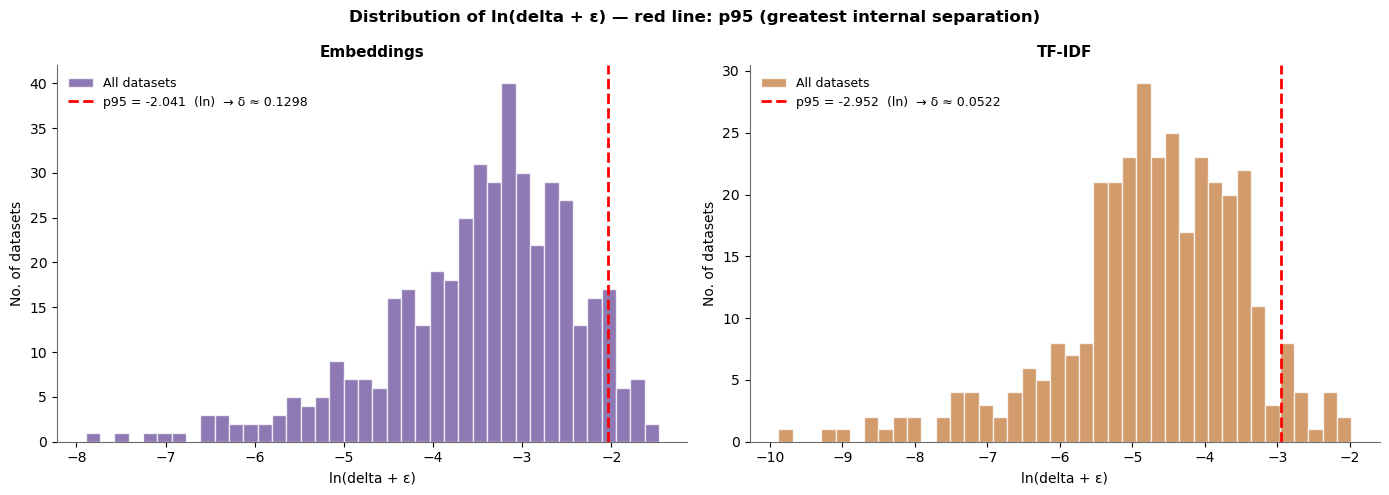


  Embeddings - datasets above the p95 of ln(delta)  (n=22)

  Distribution by dimension:
    Smart Mobility                        7 datasets (31.8%)
    Smart Governance                      6 datasets (27.3%)
    Smart Environment                     5 datasets (22.7%)
    Smart Economy                         4 datasets (18.2%)

  Distribution by anchor version:
    50_words              13 datasets
    150_words              5 datasets
    original               2 datasets
    100_words              2 datasets

  Top 10 with the largest delta (greatest internal top-1/top-2 separation):


,dataset_id,dataset_title,anchor_version,dimension_embeddings,delta_embeddings
0,a6d2764b-edc4-4895-a199-ff6ae74f31c8,Atendimento Presencial,50_words,Smart Governance,0.230806
1,a7ddf3b0-9d5f-4fa2-96b8-22db8aad862d,Carta de Infraestruturas de Modos Suaves - PDM 2021,50_words,Smart Mobility,0.203483
2,e27e9a1f-eed2-4988-b197-d69b5e32c965,Atendimento Online,50_words,Smart Governance,0.193474
3,2cce09d3-8f27-4f8b-b73b-fe41842dbe79,Frações não Habitacionais,50_words,Smart Environment,0.173210
4,9551fb05-8049-49c6-bb9a-ee8be9d5b4f1,Ocupação dos Pontos de Partilha de Mobilidade Suave (trotinetes e bicicletas) localizados no Município do Porto,150_words,Smart Mobility,0.171423
5,99b4ae0e-2722-4741-8940-8dec313e797a,Carta de Infraestruturas II - Transporte e Distribuição de Energia Elétrica - PDM 2021,50_words,Smart Mobility,0.170586
6,3b71d4c2-0752-47ba-8c57-3eaad7bdde82,Carta de Infraestruturas de Transportes Coletivos - PDM 2021,50_words,Smart Mobility,0.168167
7,079a7be5-0be2-48f7-a3d1-6835cacc8b74,Balcão do Empreendedor,50_words,Smart Economy,0.153591
8,b072ecd9-6b36-4902-baa4-c8bf3da4b86e,Edifícios dispersos de Habitação Municipal,50_words,Smart Environment,0.152511
9,35038c29-46b5-4404-ab85-651b2b6c2f7a,Corredores BUS,150_words,Smart Mobility,0.150345



  TF-IDF - datasets above the p95 of ln(delta)  (n=18)

  Distribution by dimension:
    Smart Mobility                       11 datasets (61.1%)
    Smart Governance                      3 datasets (16.7%)
    Smart Environment                     2 datasets (11.1%)
    Smart Society                         2 datasets (11.1%)

  Distribution by anchor version:
    50_words               6 datasets
    100_words              5 datasets
    original               4 datasets
    150_words              3 datasets

  Top 10 with the largest delta (greatest internal top-1/top-2 separation):


,dataset_id,dataset_title,anchor_version,dimension_tfidf,delta_tfidf
0,953e44d5-d43b-45f1-aa2f-75408b744df1,Postos de Carregamento Elétrico,150_words,Smart Mobility,0.137852
1,53cad240-48b9-4fc9-8a66-9f559037903d,Educação,100_words,Smart Society,0.096362
2,0663c4b8-ecc7-4c81-a26a-b6ee2bb63638,Carta de Infraestruturas I - Abastecimento de Água e Drenagem de Águas Residuais - PDM 2021,original,Smart Environment,0.095525
3,8c1d79b0-38c1-46de-b072-d4726bddb330,Sistema de Gestão de Tráfego - Semáforos,50_words,Smart Mobility,0.093479
4,e27e9a1f-eed2-4988-b197-d69b5e32c965,Atendimento Online,100_words,Smart Governance,0.072261
5,3b71d4c2-0752-47ba-8c57-3eaad7bdde82,Carta de Infraestruturas de Transportes Coletivos - PDM 2021,original,Smart Mobility,0.066049
6,70b22547-5c2a-41be-8b7e-4eebcf23d837,Atendimento ao Cidadão,50_words,Smart Governance,0.063128
7,9320b636-ef46-4200-9138-f7bf162d249b,Sistema de Gestão de Tráfego - CCTV,50_words,Smart Mobility,0.061359
8,a8dd5278-60f2-4d9a-ad46-7e29080fc374,Empresas de Transporte,100_words,Smart Mobility,0.055104
9,35038c29-46b5-4404-ab85-651b2b6c2f7a,Corredores BUS,original,Smart Mobility,0.052755



Interpretation: these cases show high internal separation between the first
and the second score. This does not prove the substantive accuracy of the assigned dimension
nor its stability across versions; it only identifies internally more separated cases.


In [35]:
EPS = 1e-6  # avoids ln(0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Distribution of ln(delta + ε) — red line: p95 (greatest internal separation)",
             fontsize=12, fontweight="bold")

outliers_by_version = {}

for ax, col_delta, col_dim, method, colour in [
    (axes[0], "delta_embeddings", "dimension_embeddings", "Embeddings", EMB_COLOUR),
    (axes[1], "delta_tfidf",      "dimension_tfidf",      "TF-IDF",     TFIDF_COLOUR),
]:
    # Gather all valid and strictly positive deltas from all versions
    all_items = results_all_versions.dropna(subset=[col_delta, col_dim]).copy()
    all_items = all_items[all_items[col_delta] > 0]   # exclude exact ties (delta=0)

    ln_delta = np.log(all_items[col_delta].values + EPS)
    p95      = np.percentile(ln_delta, 95)

    ax.hist(ln_delta, bins=40, color=colour, alpha=0.75, edgecolor="white", label="All datasets")
    ax.axvline(p95, color="red", linewidth=2, linestyle="--",
               label=f"p95 = {p95:.3f}  (ln)  → δ ≈ {np.exp(p95):.4f}")
    ax.set_xlabel("ln(delta + ε)", fontsize=10)
    ax.set_ylabel("No. of datasets", fontsize=10)
    ax.set_title(f"{method}", fontsize=11, fontweight="bold")
    ax.legend(fontsize=9)
    ax.spines[["top","right"]].set_visible(False)

    # Store the outliers
    mask_out = ln_delta >= p95
    outliers_by_version[method] = all_items[mask_out].copy()
    outliers_by_version[method]["ln_delta"] = ln_delta[mask_out]

plt.tight_layout()
plt.show()

# ── Which datasets are outliers and what are their dimensions? ────────────────
for method, col_dim in [("Embeddings", "dimension_embeddings"), ("TF-IDF", "dimension_tfidf")]:
    out = outliers_by_version[method]
    if out.empty:
        print(f"\n{method}: no outliers found.")
        continue

    print(f"\n{'='*70}")
    print(f"  {method} - datasets above the p95 of ln(delta)  (n={len(out)})")
    print(f"{'='*70}")

    # Distribution by dimension
    by_dim = out[col_dim].value_counts()
    print(f"\n  Distribution by dimension:")
    for dim, n in by_dim.items():
        print(f"    {dim:<35} {n:3d} datasets ({n/len(out)*100:.1f}%)")

    # Distribution by version
    print(f"\n  Distribution by anchor version:")
    by_version = out["anchor_version"].value_counts()
    for v, n in by_version.items():
        print(f"    {v:<20} {n:3d} datasets")

    # Top 10 with the largest delta
    print(f"\n  Top 10 with the largest delta (greatest internal top-1/top-2 separation):")
    col_d = "delta_embeddings" if method == "Embeddings" else "delta_tfidf"
    top10 = (out[["dataset_id","dataset_title","anchor_version", col_dim, col_d]]
             .sort_values(col_d, ascending=False)
             .drop_duplicates(subset=["dataset_id"])
             .head(10))
    display(top10.reset_index(drop=True))

print("\nInterpretation: these cases show high internal separation between the first")
print("and the second score. This does not prove the substantive accuracy of the assigned dimension")
print("nor its stability across versions; it only identifies internally more separated cases.")


**Rigorous interpretation of the cases above p95.**

An extreme delta indicates that the first dimension is more separated from the second on the internal scale of the method. It does not represent a probability of being correct and may occur in a systematically wrong classification. These cases are useful for auditing: a sample should be reviewed manually together with low-delta cases, making it possible to assess both apparently clear classifications and ambiguous cases.

### 7.9 Analysis of the datasets not classified by TF-IDF (score = 0)

TF-IDF assigns a score of 0 to a dataset when there is no lexical overlap between the tokens of the dataset (after pre-processing) and the tokens of any anchor. These datasets are left without a valid classification by the lexical method and are marked with `confidence = "null"`.

Understanding **why** these datasets have a score of 0 is important for two reasons:

1. **Methodological diagnostic**: it makes it possible to assess whether the problem lies in the pre-processing (overly aggressive stopwords that remove relevant tokens), in the anchors (the vocabulary of the anchors is too specific and does not cover the vocabulary of the datasets), or in the datasets themselves (descriptions that are too short or generic);

2. **Identification of datasets for enrichment**: datasets with a TF-IDF score of 0 but with a valid classification in the Embeddings indicate cases in which the semantic method works where the lexical one fails, typically datasets with technical vocabulary, acronyms or unconventional wording.

### The four possible causes

| Cause | What is observed in the text | Solution |
|-------|--------------------------|---------|
| **Empty original text** | `doc_text_embeddings` is also empty | Enrich the dataset in the portal |
| **All tokens are stopwords** | `doc_text_tfidf` empty, but `doc_text_embeddings` has content | Review the stopword list |
| **Insufficient vocabulary** | 1-2 tokens survive, but do not match | Extend the anchors with more vocabulary |
| **Vocabulary without overlap** | Several tokens survive, but they are very specific terms | Extend the anchors or the dataset |

This section shows **5 examples per version** of the real text of these datasets, both in the embeddings version (light cleaning) and in the TF-IDF version (rich cleaning), and produces an automatic diagnostic of the probable cause for each case.



In [36]:
N_EXAMPLES = 5

print("DATASETS WITH TF-IDF SCORE = 0 — CONCRETE EXAMPLES")
print("=" * 80)
print("(score=0 means a complete absence of lexical overlap with the anchors)\n")

for version, obj in results_by_version.items():
    res = obj["results"]
    nc  = res[res["score_top1_tfidf"] == 0].copy()

    print(f"{'─'*80}")
    print(f"  Version: {version}  |  Total unclassified: {len(nc)} / {len(res)} ({len(nc)/len(res)*100:.1f}%)")
    print(f"{'─'*80}")

    if nc.empty:
        print("  ✓ No unclassified dataset in this version.\n")
        continue

    # Join the original text of the datasets for analysis
    examples = nc.merge(
        datasets[["dataset_id", "title", "description",
                  "doc_text_embeddings", "doc_text_tfidf",
                  "n_words_embeddings", "n_words_tfidf"]],
        on="dataset_id", how="left", suffixes=("", "_ds")
    ).head(N_EXAMPLES)

    for _, row in examples.iterrows():
        name_ = str(row.get("dataset_title", row.get("title", "—")))
        desc_emb   = str(row.get("doc_text_embeddings", ""))
        desc_tfidf = str(row.get("doc_text_tfidf", ""))
        n_emb      = int(row.get("n_words_embeddings", 0))
        n_tfidf    = int(row.get("n_words_tfidf", 0))
        dim_emb    = str(row.get("dimension_embeddings", "—"))
        score_emb  = float(row.get("score_top1_embeddings", 0))

        print(f"\n  📄 Dataset: {name_}")
        print(f"     Dimension assigned by Embeddings: {dim_emb}  (score={score_emb:.4f})")
        print(f"     No. of words after light cleaning (emb) : {n_emb}")
        print(f"     No. of words after rich cleaning (tfidf): {n_tfidf}")
        print(f"     ── Embeddings text (first 300 chars):")
        print(f"        {desc_emb[:300]!r}")
        print(f"     ── TF-IDF text after pre-processing:")
        print(f"        {desc_tfidf[:300]!r}")

        # Automatic diagnostic
        if n_tfidf == 0:
            diag = "⚠️  Empty text after TF-IDF pre-processing — all the words were stopwords or short tokens."
        elif n_tfidf <= 3:
            diag = f"⚠️  Only {n_tfidf} token(s) left after pre-processing — very scarce vocabulary."
        else:
            diag = f"ℹ️  {n_tfidf} tokens left but no overlap with the terms of the anchors."
        print(f"     Diagnostic: {diag}")

    print()

# ── Aggregate summary: TF-IDF words in unclassified vs classified ─────────────
print("\n" + "="*80)
print("COMPARISON: No. of TF-IDF words — unclassified vs classified")
print("="*80)

for version, obj in results_by_version.items():
    res = obj["results"]
    # res already has its own n_words_tfidf — no need for a merge
    nc_npal = res.loc[res["score_top1_tfidf"] == 0, "n_words_tfidf"]
    cl_npal = res.loc[res["score_top1_tfidf"]  > 0, "n_words_tfidf"]

    med_nc = nc_npal.median() if len(nc_npal) > 0 else float("nan")
    med_cl = cl_npal.median() if len(cl_npal) > 0 else float("nan")
    print(f"  {version:<20}  unclassified: median={med_nc:.0f} words  |  classified: median={med_cl:.0f} words")

print("\nInterpretation: if the median of the unclassified is much lower,")
print("the main cause is the scarcity of vocabulary after pre-processing.")


DATASETS WITH TF-IDF SCORE = 0 — CONCRETE EXAMPLES
(score=0 means a complete absence of lexical overlap with the anchors)

────────────────────────────────────────────────────────────────────────────────
  Version: original  |  Total unclassified: 4 / 110 (3.6%)
────────────────────────────────────────────────────────────────────────────────

  📄 Dataset: Cargas e descargas
     Dimension assigned by Embeddings: Smart Mobility  (score=0.3132)
     No. of words after light cleaning (emb) : 22
     No. of words after rich cleaning (tfidf): 11
     ── Embeddings text (first 300 chars):
        'Cargas e descargas Layer de geometria tipo linha, que localiza e carateriza as marcações de cargas e descargas no Município do Porto.'
     ── TF-IDF text after pre-processing:
        'carga descarga layer geometria tipo linha localizar caraterizar marcacao carga descarga'
     Diagnostic: ℹ️  11 tokens left but no overlap with the terms of the anchors.

  📄 Dataset: Arruamentos Classificados para

**Analysis of the results (7.9 — Concrete examples of datasets without a TF-IDF classification).**

The examples illustrate two distinct causes for a TF-IDF score of 0:

1. **Sufficient vocabulary, but no overlap with the anchors.** In the original version, the four null
   cases — «Cargas e descargas», «Arruamentos Classificados para Condicionamentos», «Eixos Tarifados» and
   «Zona de Tomada e Largada de Passageiros» — keep between 11 and 17 terms after cleaning, but their
   technical vocabulary (for example, «marcação», «arruamento», «layer», «geometria») does not match the
   vocabulary of the anchors.
2. **Short, formulaic descriptions.** In the controlled versions, most null cases belong to
   series with a standardised description, above all the points of interest («Pontos de Interesse da Cidade do
   Porto relativos a…», for example «Teatros», «Cinemas», «Museus»), which are left with 5 to 11 terms after
   cleaning and depend almost only on the terms common to the editorial formula.

The distinction is relevant: the first case points to the lexical coverage of the anchors; the second to
the way the portal describes the records.

#### 7.9.1 Length of the texts without a TF-IDF classification and breakdown by series

Comparison of the number of terms after pre-processing between the records without a TF-IDF classification and the others, and breakdown of the records without a classification by document series (Section 4.3 of the dissertation).

In [37]:
# ── 7.9.1 Terms in the zero cases vs. the others; zero cases by series ─────────
_row_med, _row_ser = [], []
_nterms = datasets.set_index("dataset_id")["n_words_tfidf"]
for _v, _obj in results_by_version.items():
    _r = _obj["results"].set_index("dataset_id")
    _zero = _r["score_top1_tfidf"] == 0
    _row_med.append({"version": _v, "n_zero": int(_zero.sum()),
                     "median_terms_zero": float(_nterms.reindex(_r.index)[_zero.to_numpy()].median()),
                     "median_terms_others": float(_nterms.reindex(_r.index)[(~_zero).to_numpy()].median()),
                     "min_terms_zero": int(_nterms.reindex(_r.index)[_zero.to_numpy()].min()) if _zero.any() else None,
                     "max_terms_zero": int(_nterms.reindex(_r.index)[_zero.to_numpy()].max()) if _zero.any() else None})
    _cnt = SERIES_BY_ID.reindex(_r.index)[_zero.to_numpy()].value_counts()
    _row_ser.append({"version": _v, "n_zero": int(_zero.sum()), **_cnt.to_dict()})
zeros_terms = pd.DataFrame(_row_med)
zeros_series = pd.DataFrame(_row_ser).fillna(0)
zeros_series[zeros_series.columns[1:]] = zeros_series[zeros_series.columns[1:]].astype(int)
DISSERTATION_COUNTS["TF-IDF zeros - terms"] = zeros_terms
DISSERTATION_COUNTS["TF-IDF zeros - series"] = zeros_series
print("Number of terms (after pre-processing) in the records without a TF-IDF classification and in the others:")
display(zeros_terms)
print("Records without a TF-IDF classification, by document series:")
display(zeros_series)

Number of terms (after pre-processing) in the records without a TF-IDF classification and in the others:

,version,n_zero,median_terms_zero,median_terms_others,min_terms_zero,max_terms_zero
0,original,4,13.5,15.0,11,17
1,50_words,36,9.0,19.5,5,29
2,100_words,34,8.0,20.0,5,19
3,150_words,25,7.0,18.0,5,16


Records without a TF-IDF classification, by document series:


,version,n_zero,'Layer de geometria tipo…' layers,Points of interest,Records with 'PDM' in the name,Outside the series
0,original,4,4,0,0,0
1,50_words,36,12,21,2,1
2,100_words,34,11,21,0,2
3,150_words,25,4,20,0,1


### 7.10 Post-argmax classification: single-label, multi-label, transversal and indeterminate

Up to this point, each dataset has been classified by the **argmax** rule — the dimension with the highest similarity score is always assigned. This rule is simple, but **it always assigns a single label, even when the scores of the six dimensions are very close to one another**.

Two datasets with very different score profiles may receive exactly the same treatment:

```
Dataset A:  Mobility=0.84  Environment=0.79  Economy=0.43  ...  → "Smart Mobility"
Dataset B:  Mobility=0.55  Environment=0.54  Economy=0.53  ...  → "Smart Mobility"
```

(Illustrative values, not taken from the corpus.) In Dataset A, Mobility and Environment stand out from the others. In Dataset B, the first three dimensions are practically tied — the choice of the first depends on minimal differences and should not be taken as definitive.

This section adds a **post-argmax decision layer** (Section 3.5.1 of the dissertation) that distinguishes four situations:

| State | When it occurs | What it means |
|---|---|---|
| `single_label` | None of the following conditions | Top-1 kept without an automatic flag (does not imply that it is correct) |
| `multi_label_candidate` | At least one close alternative and a reduced margin | Top-1 and top-2 to be reviewed as a possible dual assignment |
| `transversal_candidate` | 3+ close dimensions or a profile with little dispersion | Sign of low discrimination; the candidates follow `n_close` |
| `indeterminate` | Metadata with fewer than 8 words or a weak maximum score | Insufficient textual evidence; review |

The rule is applied **to the four anchor versions and to the two methods**, like the other analyses in the chapter. Each combination of version and method has its own thresholds, because the distribution of the scores changes with the wording of the anchors and with the textual representation.

#### Metrics used in the decision

From the six similarity scores of each dataset, five auxiliary metrics are computed:

| Metric | Formula | Interpretation |
|---|---|---|
| `s1` | `max(scores)` | Strength of the best association |
| `margin_12` | `s1 − s2` | Margin between the 1st and the 2nd dimension (the delta) |
| `score_range` | `max − min` of the 6 scores | Range of the profile |
| `score_sd` | Standard deviation of the 6 scores | Alternative dispersion |
| `n_close` | No. of dimensions with score ≥ s1 − `delta_close`, **including the winner itself** | `n_close = 1`: no close alternative; `n_close ≥ 2`: at least one close alternative |

#### Empirical percentile thresholds

The thresholds **are not fixed values**: they are computed for each version and each method from the distribution observed in this corpus, excluding non-positive top-1 scores. They are empirical thresholds that depend on the corpus, the version and the method, not universal values:

| Threshold | Calculation | Meaning |
|---|---|---|
| `theta_low` | 5th percentile of `s1` (`PERCENTILE_WEAK_SCORE`) | At or below this value, the best score is considered weak → indeterminate |
| `delta_close` | 25th percentile of `margin_12` (`PERCENTILE_CLOSE_MARGIN`) | At or below this value, the 1st and the 2nd dimension are considered "close" |
| `range_low` | 25th percentile of `score_range` (`PERCENTILE_DIFFUSE_RANGE`) | Below this value, the six scores are considered "diffuse" → transversal |

The 5th percentile for `theta_low` flags, by construction, about 5% of the cases with the weakest maximum score. The 25th percentile for `delta_close` and `range_low` corresponds to the first quartile — the quarter of the datasets with the least separation between dimensions.

#### Decision logic (order of priority)

```
1. If the metadata have fewer than 8 words (MIN_WORDS) → indeterminate
2. If s1 = 0 OR s1 ≤ theta_low → indeterminate
3. If n_close ≥ 3 OR score_range < range_low → transversal_candidate
4. If n_close ≥ 2 AND margin_12 ≤ delta_close → multi_label_candidate
5. Otherwise → single_label
```

The order matters: the check for poor metadata and a weak score takes priority over transversality, which takes priority over multi-label. All states other than `single_label` receive `review_flag=True`. The rule is an exploratory triage mechanism for human review, not a validated classification.

#### Organisation of the section

| Subsection | Content |
|---|---|
| 7.10.1 | Score profiles and thresholds, by version and method |
| 7.10.2 | Distributions of the metrics with the thresholds marked |
| 7.10.3 | Application of the rule and distribution of the states by version and method |
| 7.10.4 | Visualisation of the states and agreement of state between methods |
| 7.10.5 | State of each dataset in the four versions |
| 7.10.6 | Cases for human review |
| 7.10.7 | Sensitivity of the rule to the parameters |
| 7.10.8 | Global review and candidate dimensions |
| 7.10.9 | Pairs of candidate dimensions and transversality by range |

#### 7.10.1 Score profiles and thresholds, by version and method

For each anchor version, the profile table is built (scores of the six dimensions and auxiliary metrics, for both methods) and the three percentile thresholds are computed, separately for Embeddings and TF-IDF.

In [38]:
# ── 7.10.1 Score profiles and empirical thresholds, by version and method ─────
VERSIONS_710 = list(results_by_version.keys())
METHODS_710 = [("emb", "Embeddings"), ("tfidf", "TF-IDF")]
STATE_ORDER = ["single_label", "multi_label_candidate", "transversal_candidate", "indeterminate"]


def compute_profile_metrics(df_res, score_cols, dims, suffix):
    """
    For each dataset, extracts the full profile of the similarity scores and
    computes the auxiliary metrics described in the introduction to this section.
    """
    matrix = df_res[score_cols].values   # shape: (n_datasets, n_dims)
    n      = len(df_res)

    # Sort the scores by row (descending) to extract top-1, top-2, top-3
    sorted_idx    = np.argsort(-matrix, axis=1)
    sorted_scores = np.take_along_axis(matrix, sorted_idx, axis=1)

    s1 = sorted_scores[:, 0]
    s2 = sorted_scores[:, 1]
    s3 = sorted_scores[:, 2] if matrix.shape[1] > 2 else s2

    top1_label = [dims[sorted_idx[i, 0]] for i in range(n)]
    top2_label = [dims[sorted_idx[i, 1]] for i in range(n)]
    top3_label = [dims[sorted_idx[i, 2]] for i in range(n)] if len(dims) > 2 else top2_label

    return pd.DataFrame({
        f"top1_label_{suffix}": top1_label,
        f"top1_score_{suffix}": s1,
        f"top2_label_{suffix}": top2_label,
        f"top2_score_{suffix}": s2,
        f"top3_label_{suffix}": top3_label,
        f"top3_score_{suffix}": s3,
        f"margin_12_{suffix}":  s1 - s2,
        f"margin_23_{suffix}":  s2 - s3,
        f"score_range_{suffix}": matrix.max(axis=1) - matrix.min(axis=1),
        f"score_sd_{suffix}":    matrix.std(axis=1),
    }, index=df_res.index)


def build_profile_table(res):
    """Working table of the post-argmax rule for one anchor version."""
    score_cols_emb   = sorted([c for c in res.columns if c.startswith("score_emb_")], key=dim_col_key)
    score_cols_tfidf = sorted([c for c in res.columns if c.startswith("score_tfidf_")], key=dim_col_key)
    dims = [c.replace("score_emb_", "") for c in score_cols_emb]
    table = pd.concat([
        res[["dataset_id", "dataset_title", "dataset_description",
             "n_words_embeddings", "n_words_tfidf"]],
        compute_profile_metrics(res, score_cols_emb,   dims, "emb"),
        compute_profile_metrics(res, score_cols_tfidf, dims, "tfidf"),
    ], axis=1)
    # The six scores of each method are kept in the table (needed for n_close)
    for col in score_cols_emb + score_cols_tfidf:
        table[col] = res[col].to_numpy()
    return table


def compute_thresholds(table, suffix):
    """Percentile thresholds, excluding non-positive top-1 scores (no signal)."""
    valid_mask = table[f"top1_score_{suffix}"] > 0
    return {
        "theta_low":   float(table.loc[valid_mask, f"top1_score_{suffix}"].quantile(PERCENTILE_WEAK_SCORE / 100)),
        "delta_close": float(table.loc[valid_mask, f"margin_12_{suffix}"].quantile(PERCENTILE_CLOSE_MARGIN / 100)),
        "range_low":   float(table.loc[valid_mask, f"score_range_{suffix}"].quantile(PERCENTILE_DIFFUSE_RANGE / 100)),
        "n_valid":   int(valid_mask.sum()),
    }


tables_710, thresholds_710 = {}, {}
for version in VERSIONS_710:
    tables_710[version] = build_profile_table(results_by_version[version]["results"])
    thresholds_710[version] = {suf: compute_thresholds(tables_710[version], suf) for suf, _ in METHODS_710}

post_argmax_thresholds_df = pd.DataFrame([
    {"version": version, "method": name_, **thresholds_710[version][suf],
     "percentile_theta_low": PERCENTILE_WEAK_SCORE,
     "percentile_delta_close": PERCENTILE_CLOSE_MARGIN,
     "percentile_range_low": PERCENTILE_DIFFUSE_RANGE}
    for version in VERSIONS_710 for suf, name_ in METHODS_710
])

print(f"Profile tables: {len(VERSIONS_710)} versions × {len(tables_710[VERSIONS_710[0]])} datasets")
print("\nEmpirical thresholds by version and method (n_valid = datasets with s1 > 0):")
display(post_argmax_thresholds_df.round(4))
print("The TF-IDF thresholds are lower than those of the Embeddings because the TF-IDF scores")
print("have a smaller magnitude; fixed thresholds are therefore not transferred between methods or versions.")

Profile tables: 4 versions × 110 datasets

Empirical thresholds by version and method (n_valid = datasets with s1 > 0):


,version,method,theta_low,delta_close,range_low,n_valid,percentile_theta_low,percentile_delta_close,percentile_range_low
0,original,Embeddings,0.2347,0.0161,0.1275,110,5,25,25
1,original,TF-IDF,0.0044,0.0052,0.0077,106,5,25,25
2,50_words,Embeddings,0.2759,0.0259,0.1706,110,5,25,25
3,50_words,TF-IDF,0.0072,0.0063,0.0172,74,5,25,25
4,100_words,Embeddings,0.2152,0.0142,0.1195,110,5,25,25
5,100_words,TF-IDF,0.0083,0.0043,0.0177,76,5,25,25
6,150_words,Embeddings,0.2170,0.0136,0.1247,110,5,25,25
7,150_words,TF-IDF,0.0071,0.0047,0.0158,85,5,25,25


The TF-IDF thresholds are lower than those of the Embeddings because the TF-IDF scores
have a smaller magnitude; fixed thresholds are therefore not transferred between methods or versions.


#### 7.10.2 Distributions of the metrics with the thresholds marked

For each version, the histograms show the distribution of the top-1 score, of the margin between the 1st and the 2nd dimension and of the range of the profile, with the corresponding threshold as a red dashed line. The shaded area corresponds to the values that fall below the threshold.

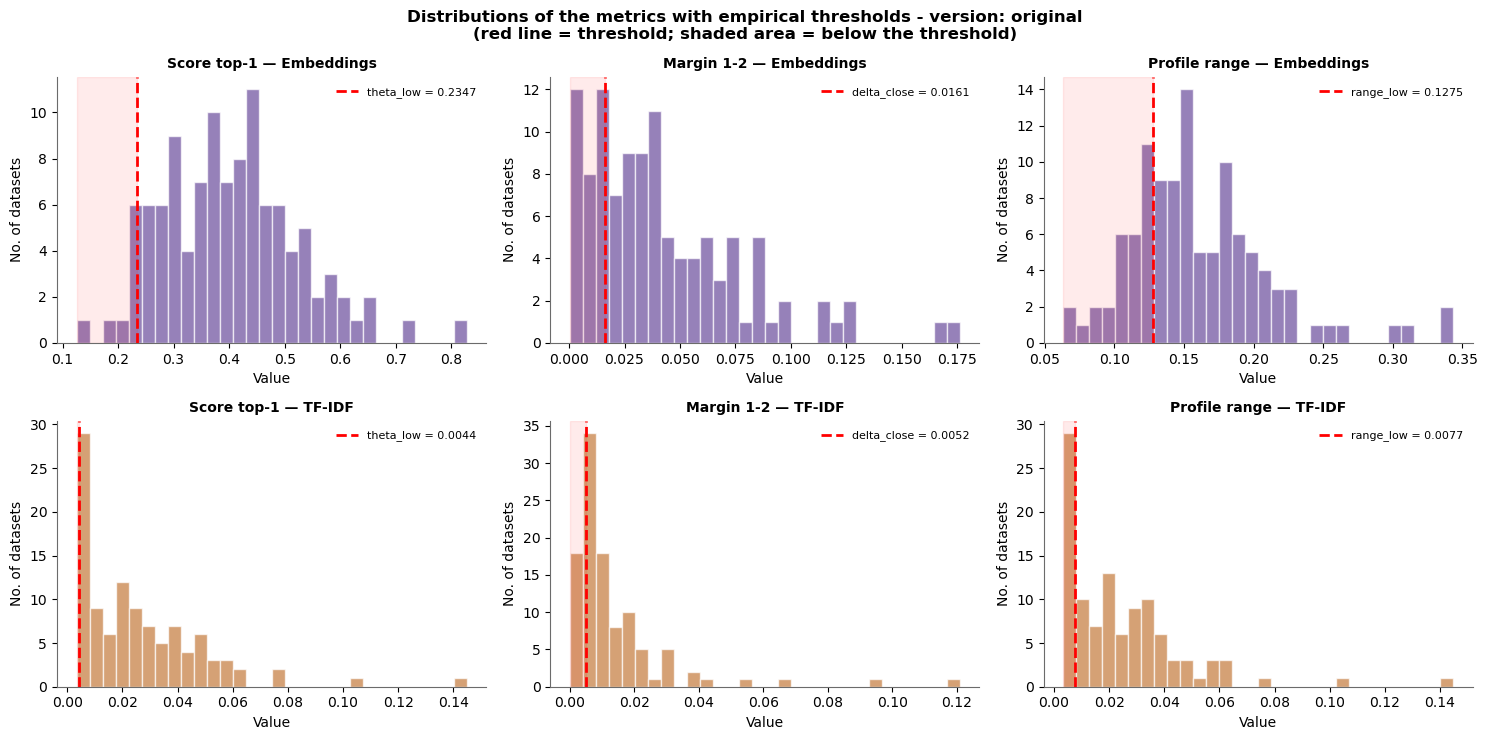

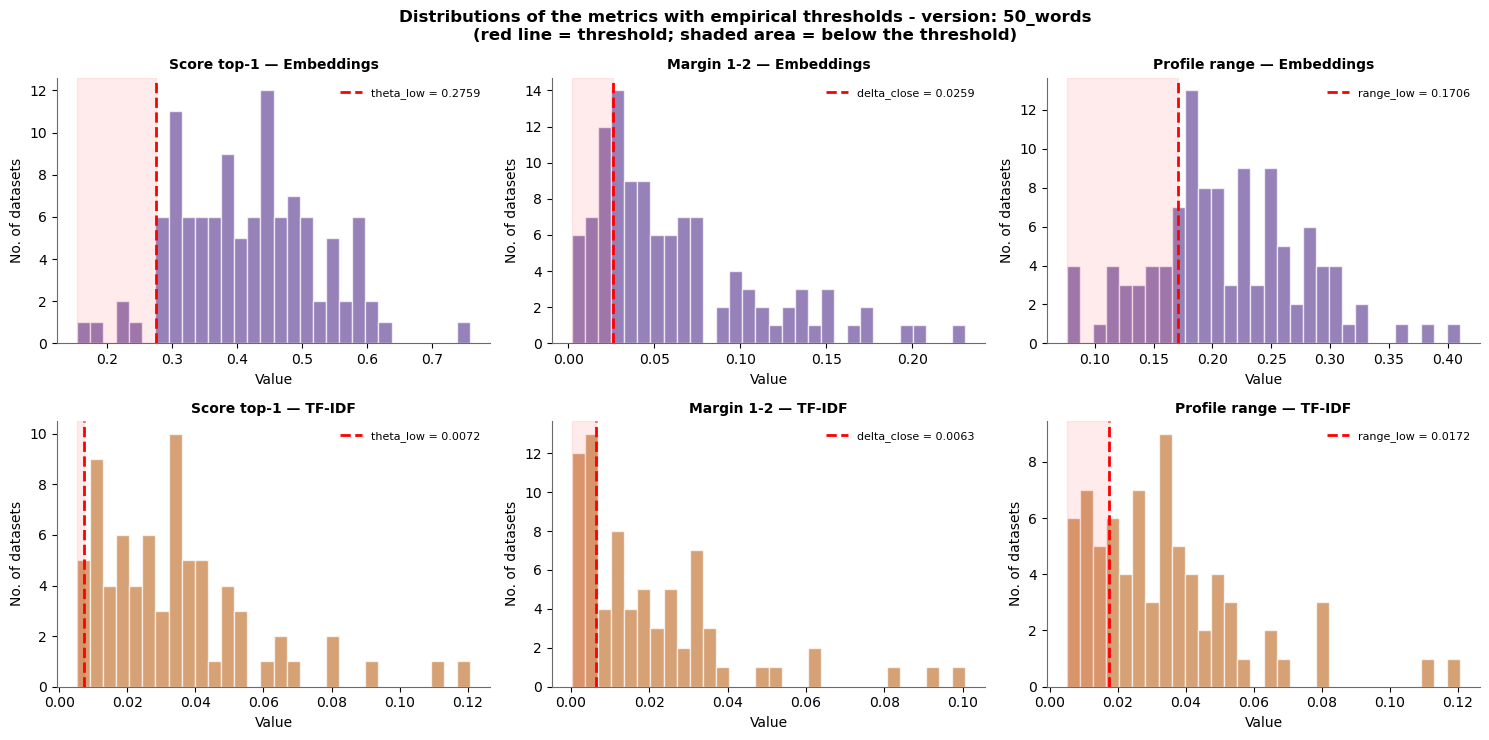

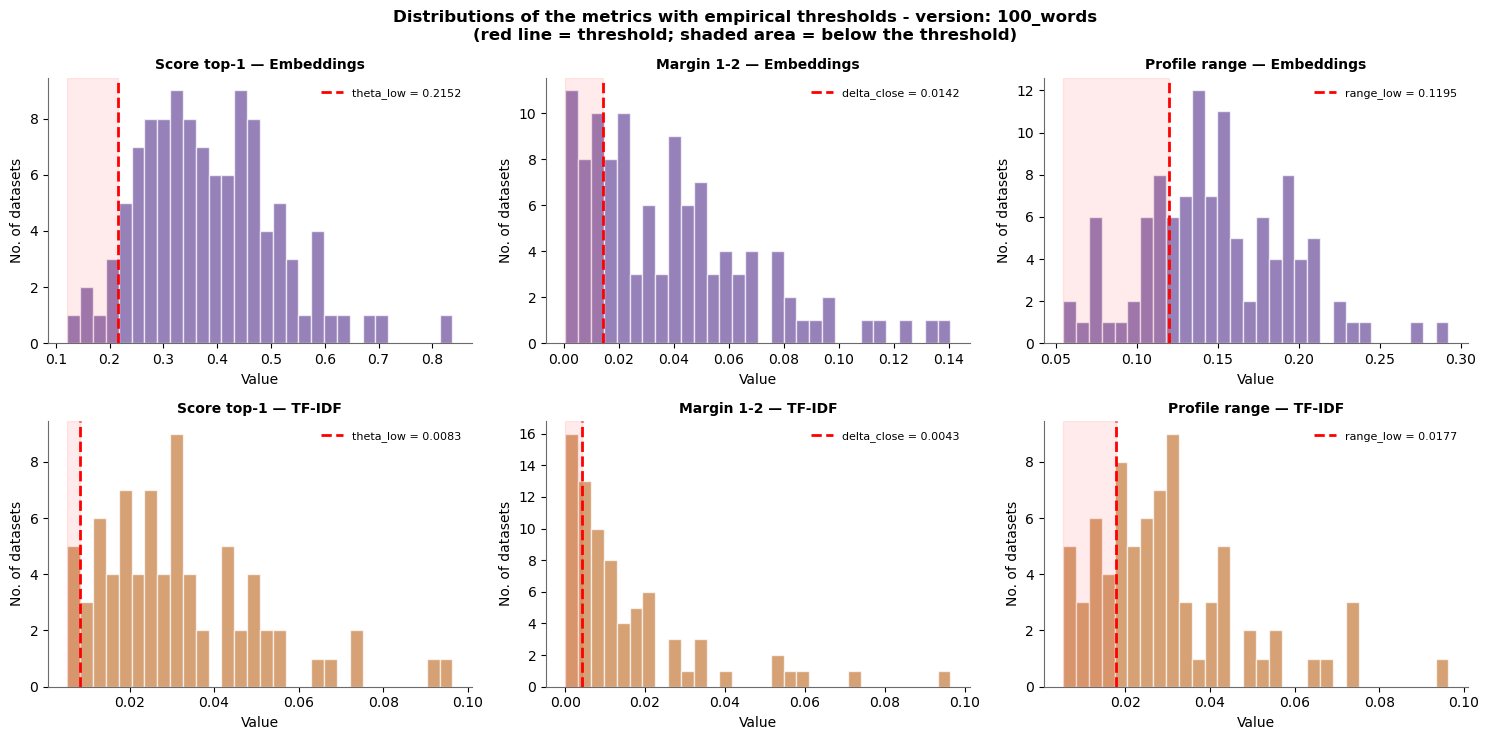

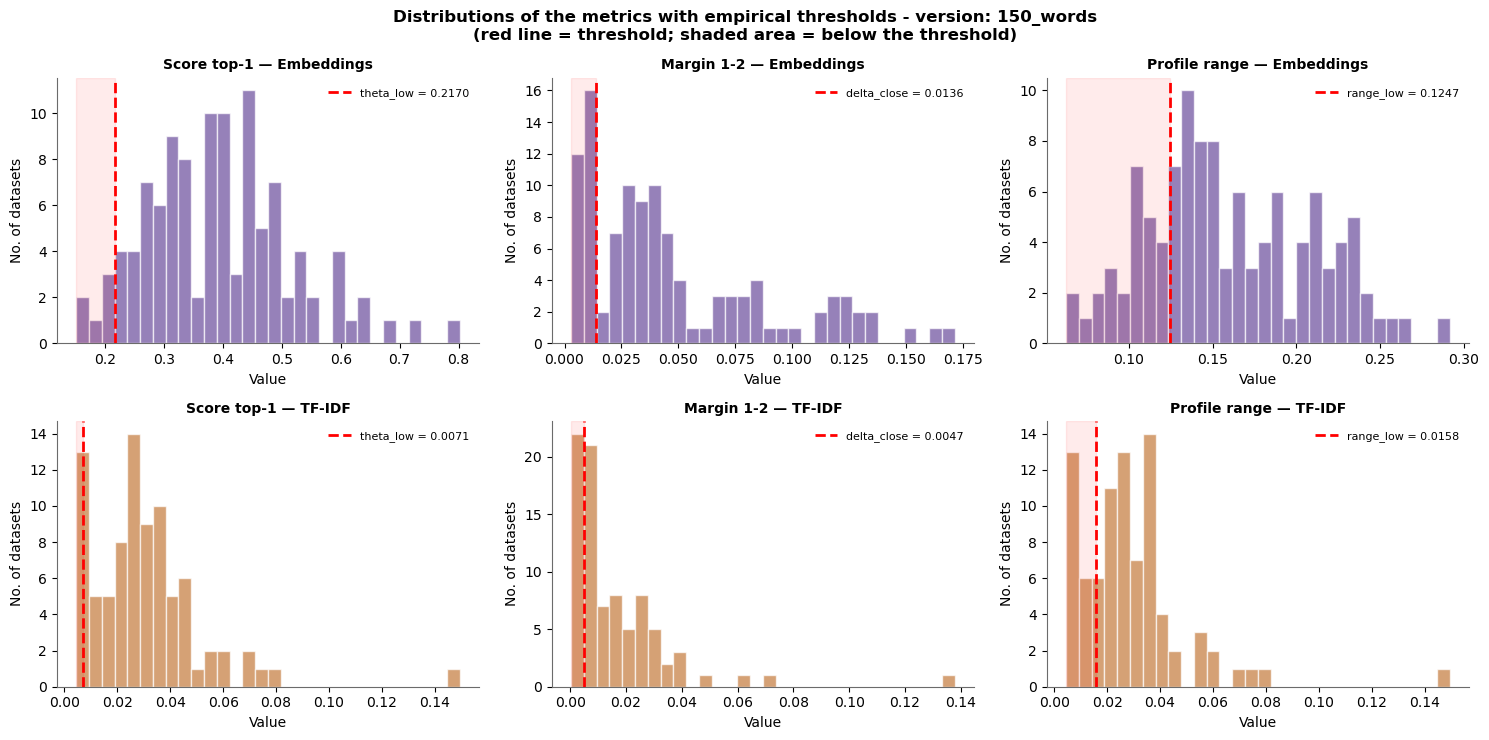

In [39]:
# ── 7.10.2 Distributions of the metrics with the thresholds marked (by version) ─
method_colours = {"emb": EMB_COLOUR, "tfidf": TFIDF_COLOUR}
plot_metrics = [("top1_score", "theta_low", "Score top-1"),
                 ("margin_12", "delta_close", "Margin 1-2"),
                 ("score_range", "range_low", "Profile range")]

for version in VERSIONS_710:
    tab = tables_710[version]
    fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
    fig.suptitle(f"Distributions of the metrics with empirical thresholds - version: {version}\n"
                 "(red line = threshold; shaded area = below the threshold)",
                 fontsize=12, fontweight="bold")
    for row_data, (suf, name_) in enumerate(METHODS_710):
        valid_mask = tab[f"top1_score_{suf}"] > 0
        for column_name, (met, lim, title_text) in enumerate(plot_metrics):
            ax = axes[row_data][column_name]
            data_rows = tab.loc[valid_mask, f"{met}_{suf}"]
            threshold = thresholds_710[version][suf][lim]
            ax.hist(data_rows, bins=30, color=method_colours[suf], alpha=0.7, edgecolor="white")
            ax.axvline(threshold, color="red", linewidth=2, linestyle="--", label=f"{lim} = {threshold:.4f}")
            ax.axvspan(data_rows.min(), threshold, alpha=0.08, color="red")
            ax.set_title(f"{title_text} — {name_}", fontsize=10, fontweight="bold")
            ax.set_xlabel("Value"); ax.set_ylabel("No. of datasets")
            ax.legend(fontsize=8)
            ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

#### 7.10.3 Application of the rule and distribution of the states

The rule is applied separately to each version and each method, with the thresholds of Section 7.10.1. The summary presents, for each combination, the number and percentage of datasets in each state and the proportion flagged for review. The second table brings the two methods together: at this stage, a dataset counts as flagged when at least one method assigns it a state other than `single_label`. Disagreement between two `single_label` states is added in the global review (7.10.8).

In [40]:
# ── 7.10.3 Application of the decision rule to the four versions ─────────────
#
# decision_rule applies the 5 rules in cascade (the order matters):
#   1. Poor metadata   → indeterminate
#   2. Weak score      → indeterminate
#   3. Diffuse profile → transversal_candidate
#   4. Two close dimensions → multi_label_candidate
#   5. Otherwise       → single_label
# It is applied separately for Embeddings and TF-IDF: the same dataset may have
# different states in the two methods.

def decision_rule(row, suffix, theta_low, delta_close, range_low):
    """
    Applies the post-argmax decision logic to one row of the table.
    Returns a dictionary with:
      - primary_label          : main dimension (or None)
      - secondary_labels       : list of secondary dimensions (or [])
      - candidate_labels       : all candidate dimensions considered
      - classification_status  : single_label / multi_label_candidate /
                                 transversal_candidate / indeterminate
      - review_flag            : True if the case requires human review
    """
    s1         = row[f"top1_score_{suffix}"]
    l1         = row[f"top1_label_{suffix}"]
    l2         = row[f"top2_label_{suffix}"]
    l3         = row[f"top3_label_{suffix}"]
    margin_12  = row[f"margin_12_{suffix}"]
    score_range= row[f"score_range_{suffix}"]
    n_words = row["n_words_embeddings"]   # same for both methods
    n_close    = row[f"n_close_{suffix}"]

    # Rule 1: insufficient metadata
    if n_words < MIN_WORDS:
        return {"primary_label": None, "secondary_labels": [],
                "candidate_labels": [], "review_flag": True,
                f"classification_status_{suffix}": "indeterminate",
                f"reason_{suffix}": "insufficient metadata"}

    # Rule 2: maximum score too low
    if s1 <= theta_low or s1 == 0:
        return {"primary_label": None, "secondary_labels": [],
                "candidate_labels": [l1] if s1 > 0 else [],
                "review_flag": True,
                f"classification_status_{suffix}": "indeterminate",
                f"reason_{suffix}": f"weak score (s1={s1:.4f} ≤ θ={theta_low:.4f})"}

    # Rule 3: diffuse profile — 3+ close dimensions OR low range
    if n_close >= 3 or score_range < range_low:
        return {"primary_label": None, "secondary_labels": [],
                "candidate_labels": [l1, l2, l3],
                "review_flag": True,
                f"classification_status_{suffix}": "transversal_candidate",
                f"reason_{suffix}": f"diffuse profile: n_close={n_close}; range={score_range:.4f}; threshold={range_low:.4f}"}

    # Rule 4: two close dimensions
    if n_close >= 2 and margin_12 <= delta_close:
        return {"primary_label": l1, "secondary_labels": [l2],
                "candidate_labels": [l1, l2],
                "review_flag": True,
                f"classification_status_{suffix}": "multi_label_candidate",
                f"reason_{suffix}": f"margin_12={margin_12:.4f} ≤ δ={delta_close:.4f}"}

    # Rule 5: single-label
    return {"primary_label": l1, "secondary_labels": [],
            "candidate_labels": [l1],
            "review_flag": False,
            f"classification_status_{suffix}": "single_label",
            f"reason_{suffix}": f"margin_12={margin_12:.4f} ≥ δ={delta_close:.4f}"}


def apply_rule(table, thresholds):
    """Computes n_close and applies decision_rule to the two methods of one version."""
    for suffix, _ in METHODS_710:
        score_cols_s = sorted([c for c in table.columns if c.startswith(f"score_{suffix}_")], key=dim_col_key)
        matrix = table[score_cols_s].to_numpy(dtype=float)
        s1_vec = matrix.max(axis=1)
        table[f"n_close_{suffix}"] = (
            matrix >= (s1_vec - thresholds[suffix]["delta_close"]).reshape(-1, 1)
        ).sum(axis=1)

    for suffix, _ in METHODS_710:
        lim = thresholds[suffix]
        decisions = table.apply(
            lambda row: decision_rule(row, suffix, lim["theta_low"], lim["delta_close"], lim["range_low"]),
            axis=1)
        decisions_df = pd.DataFrame(list(decisions))
        table[f"status_{suffix}"]     = decisions_df[f"classification_status_{suffix}"].values
        table[f"reason_{suffix}"]     = decisions_df[f"reason_{suffix}"].values
        table[f"primary_{suffix}"]    = decisions_df["primary_label"].values
        table[f"secondary_{suffix}"]  = decisions_df["secondary_labels"].apply(str).values
        table[f"candidates_{suffix}"] = decisions_df["candidate_labels"].apply(str).values
        table[f"review_{suffix}"]     = decisions_df["review_flag"].values
    return table


for version in VERSIONS_710:
    tables_710[version] = apply_rule(tables_710[version], thresholds_710[version])

# ── Summary by version and method ─────────────────────────────────────────────
rows_summary = []
for version in VERSIONS_710:
    tab, n = tables_710[version], len(tables_710[version])
    for suf, name_ in METHODS_710:
        cont = tab[f"status_{suf}"].value_counts().reindex(STATE_ORDER, fill_value=0)
        row_data = {"version": version, "method": name_, "n_datasets": n}
        for state in STATE_ORDER:
            row_data[f"n_{state}"] = int(cont[state])
            row_data[f"pct_{state}"] = round(cont[state] / n * 100, 1)
        row_data["n_review"] = int(tab[f"review_{suf}"].sum())
        row_data["pct_review"] = round(tab[f"review_{suf}"].mean() * 100, 1)
        rows_summary.append(row_data)
post_argmax_summary_df = pd.DataFrame(rows_summary)

post_argmax_version_summary_df = pd.DataFrame([{
    "version": version,
    "n_datasets": len(tab),
    "n_review_any_method": int((tab["review_emb"] | tab["review_tfidf"]).sum()),
    "pct_review_any_method": round((tab["review_emb"] | tab["review_tfidf"]).mean() * 100, 1),
    "n_review_both_methods": int((tab["review_emb"] & tab["review_tfidf"]).sum()),
    "pct_review_both_methods": round((tab["review_emb"] & tab["review_tfidf"]).mean() * 100, 1),
    "pct_same_state_methods": round((tab["status_emb"] == tab["status_tfidf"]).mean() * 100, 1),
} for version, tab in tables_710.items()])

print("Post-argmax states by version and method (n and %):")
display(post_argmax_summary_df.set_index(["version", "method"]))
print("Flagging for review combining the two methods:")
display(post_argmax_version_summary_df.set_index("version"))

Post-argmax states by version and method (n and %):


n_datasets  n_single_label  pct_single_label  \
version   method                                                     
original  Embeddings         110              60              54.5   
          TF-IDF             110              64              58.2   
50_words  Embeddings         110              61              55.5   
          TF-IDF             110              42              38.2   
100_words Embeddings         110              63              57.3   
          TF-IDF             110              43              39.1   
150_words Embeddings         110              67              60.9   
          TF-IDF             110              47              42.7   

                      n_multi_label_candidate  pct_multi_label_candidate  \
version   method                                                           
original  Embeddings                       15                       13.6   
          TF-IDF                            9                        8.2   
50_words  Embeddings                       15                       13.6   
          TF-IDF                           10                        9.1   
100_words Embeddings                       12                       10.9   
          TF-IDF                           13                       11.8   
150_words Embeddings                        8                        7.3   
          TF-IDF                           13                       11.8   

                      n_transversal_candidate  pct_transversal_candidate  \
version   method                                                           
original  Embeddings                       25                       22.7   
          TF-IDF                           23                       20.9   
50_words  Embeddings                       24                       21.8   
          TF-IDF                           14                       12.7   
100_words Embeddings                       25                       22.7   
          TF-IDF                           13                       11.8   
150_words Embeddings                       25                       22.7   
          TF-IDF                           18                       16.4   

                      n_indeterminate  pct_indeterminate  n_review  pct_review  
version   method                                                                
original  Embeddings               10                9.1        50        45.5  
          TF-IDF                   14               12.7        46        41.8  
50_words  Embeddings               10                9.1        49        44.5  
          TF-IDF                   44               40.0        68        61.8  
100_words Embeddings               10                9.1        47        42.7  
          TF-IDF                   41               37.3        67        60.9  
150_words Embeddings               10                9.1        43        39.1  
          TF-IDF                   32               29.1        63        57.3

Flagging for review combining the two methods:


,n_datasets,n_review_any_method,pct_review_any_method,n_review_both_methods,pct_review_both_methods,pct_same_state_methods
version,,,,,,
original,110,71,64.5,25,22.7,52.7
50_words,110,84,76.4,33,30.0,35.5
100_words,110,80,72.7,34,30.9,38.2
150_words,110,78,70.9,28,25.5,43.6


#### 7.10.4 Visualisation of the states and agreement of state between methods

The bar chart compares the distribution of the states across the four versions, separately for each method.

Next, the agreement between methods is presented in two ways:

1. **Summary table**: for each version and state, the number of datasets with that state in the Embeddings, in TF-IDF and in both methods at the same time. The Embeddings and TF-IDF columns correspond to the bars of the chart. In the `TOTAL` row, the «In both methods» column indicates how many datasets have the same state in both methods.
2. **Cross-tabulations (one per version)**: the rows are the state in the Embeddings and the columns the state in TF-IDF. The diagonal, outlined in black, brings together the datasets with the same state in both methods. The totals of each row and each column, in bold, are the values of the bar chart.

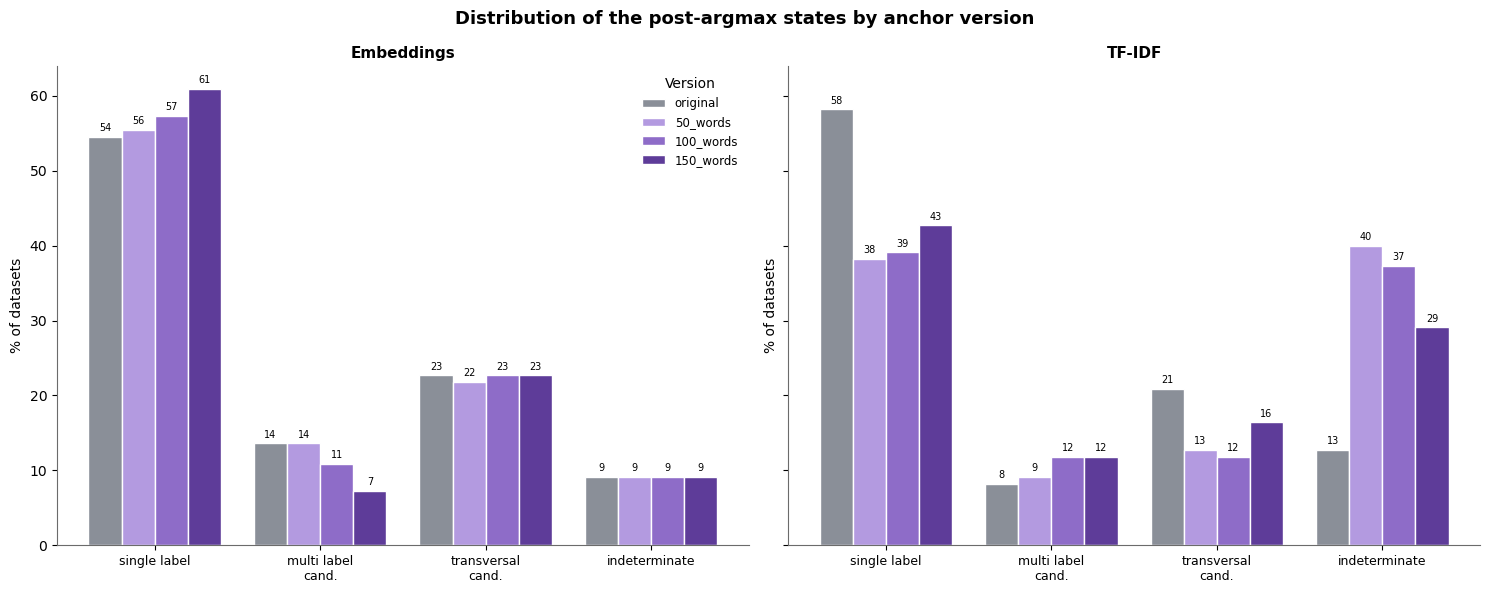

States by method and coincidence between methods (n = no. of datasets; % of the whole corpus).
In the TOTAL row, 'In both methods' = datasets with the SAME state in both methods.



Embeddings (n)  Embeddings (%)  TF-IDF (n)  \
version   state                                                       
original  single_label               60            54.5          64   
          multi_label                15            13.6           9   
          transversal                25            22.7          23   
          indeterminate              10             9.1          14   
          TOTAL                     110           100.0         110   
50_words  single_label               61            55.5          42   
          multi_label                15            13.6          10   
          transversal                24            21.8          14   
          indeterminate              10             9.1          44   
          TOTAL                     110           100.0         110   
100_words single_label               63            57.3          43   
          multi_label                12            10.9          13   
          transversal                25            22.7          13   
          indeterminate              10             9.1          41   
          TOTAL                     110           100.0         110   
150_words single_label               67            60.9          47   
          multi_label                 8             7.3          13   
          transversal                25            22.7          18   
          indeterminate              10             9.1          32   
          TOTAL                     110           100.0         110   

                         TF-IDF (%)  In both methods (n)  In both methods (%)  
version   state                                                                
original  single_label         58.2                   39                 35.5  
          multi_label           8.2                    5                  4.5  
          transversal          20.9                   10                  9.1  
          indeterminate        12.7                    4                  3.6  
          TOTAL               100.0                   58                 52.7  
50_words  single_label         38.2                   26                 23.6  
          multi_label           9.1                    2                  1.8  
          transversal          12.7                    3                  2.7  
          indeterminate        40.0                    8                  7.3  
          TOTAL               100.0                   39                 35.5  
100_words single_label         39.1                   30                 27.3  
          multi_label          11.8                    0                  0.0  
          transversal          11.8                    4                  3.6  
          indeterminate        37.3                    8                  7.3  
          TOTAL               100.0                   42                 38.2  
150_words single_label         42.7                   32                 29.1  
          multi_label          11.8                    4                  3.6  
          transversal          16.4                    5                  4.5  
          indeterminate        29.1                    7                  6.4  
          TOTAL               100.0                   48                 43.6

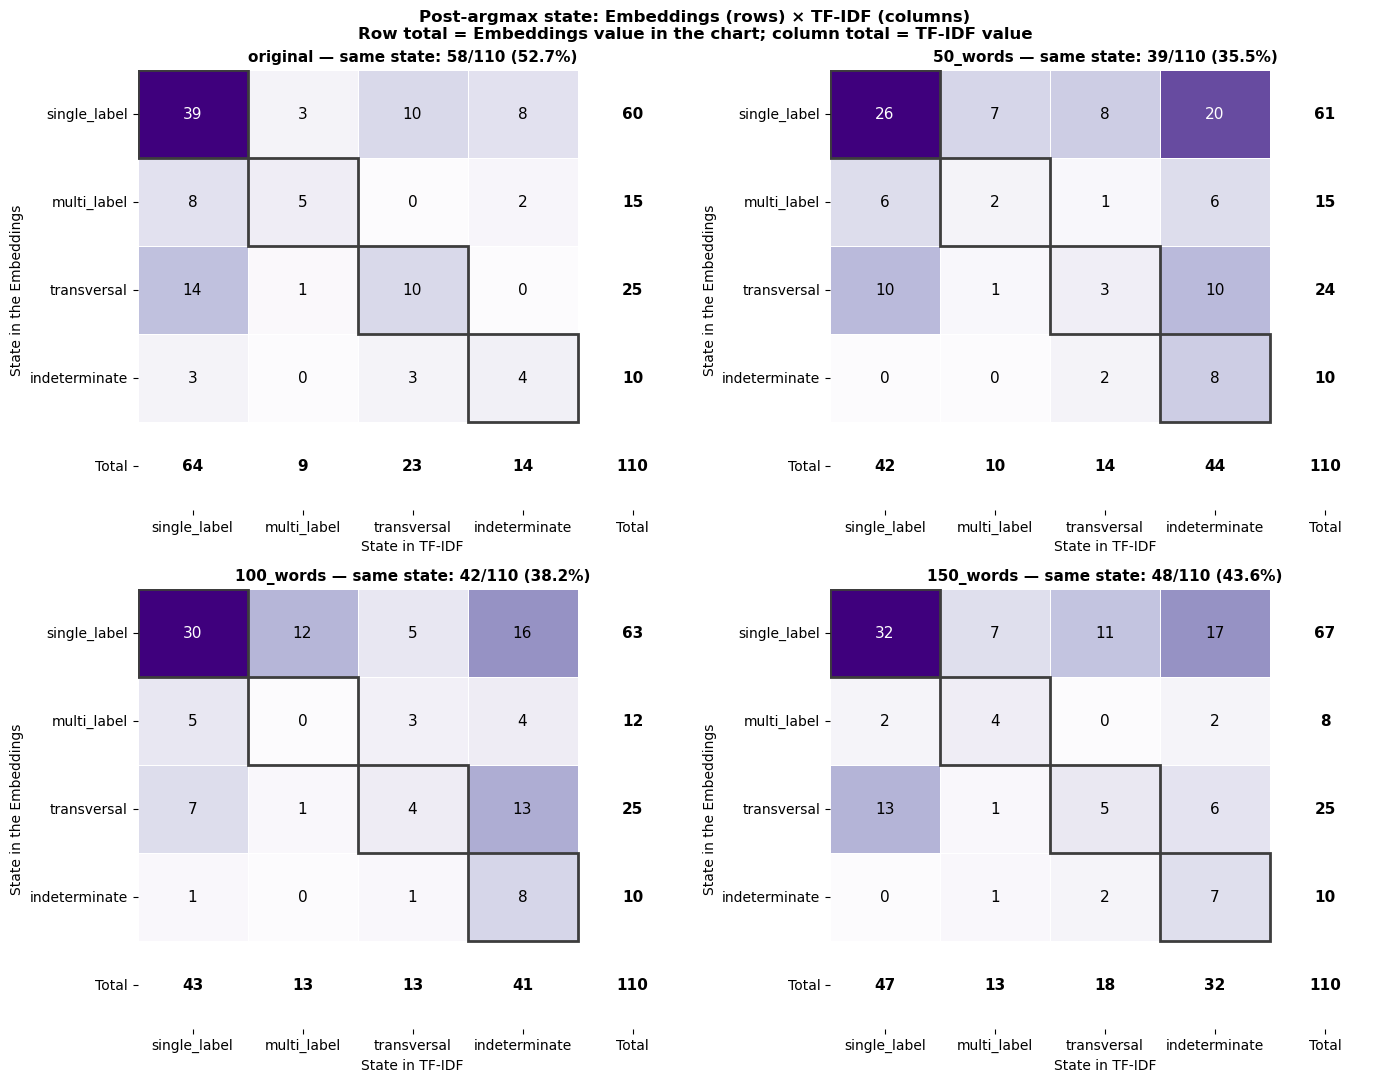

In [41]:
# ── 7.10.4 Visualisation of the states by version and agreement between methods ─
VERSION_COLOURS_710 = {v: VERSION_COLOURS.get(v, c) for v, c in zip(VERSIONS_710, CATEGORICAL_PALETTE)}

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
fig.suptitle("Distribution of the post-argmax states by anchor version",
             fontsize=13, fontweight="bold")
width_chars = 0.8 / len(VERSIONS_710)
x = np.arange(len(STATE_ORDER))
for ax, (suf, name_) in zip(axes, METHODS_710):
    sub = post_argmax_summary_df[post_argmax_summary_df["method"] == name_].set_index("version")
    for j, version in enumerate(VERSIONS_710):
        pct = [sub.loc[version, f"pct_{e}"] for e in STATE_ORDER]
        bar_items = ax.bar(x + (j - (len(VERSIONS_710) - 1) / 2) * width_chars, pct, width=width_chars,
                        color=VERSION_COLOURS_710[version], edgecolor="white", label=version)
        for b, p in zip(bar_items, pct):
            ax.text(b.get_x() + b.get_width() / 2, p + 0.5, f"{p:.0f}", ha="center", va="bottom", fontsize=7)
    ax.set_xticks(x)
    ax.set_xticklabels([e.replace("_", " ").replace("candidate", "cand.") for e in STATE_ORDER],
                       fontsize=9)
    format_x_labels(ax)
    ax.set_title(name_, fontsize=11, fontweight="bold")
    ax.set_ylabel("% of datasets")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(title="Version", fontsize=8.5)
plt.tight_layout()
plt.show()

# ── Agreement of STATE between Embeddings and TF-IDF, by version ─────────────
SHORT_NAMES = {"single_label": "single_label", "multi_label_candidate": "multi_label",
                "transversal_candidate": "transversal", "indeterminate": "indeterminate"}

# 1) Summary table: for each version and state, how many datasets have that state
#    in the Embeddings, in TF-IDF and in BOTH methods at the same time.
#    The "Embeddings" and "TF-IDF" columns are the values of the chart above.
rows_agr = []
for version, tab in tables_710.items():
    n = len(tab)
    for state in STATE_ORDER:
        n_emb = int((tab["status_emb"] == state).sum())
        n_tf = int((tab["status_tfidf"] == state).sum())
        n_both = int(((tab["status_emb"] == state) & (tab["status_tfidf"] == state)).sum())
        rows_agr.append({"version": version, "state": SHORT_NAMES[state],
                            "Embeddings (n)": n_emb, "Embeddings (%)": round(n_emb / n * 100, 1),
                            "TF-IDF (n)": n_tf, "TF-IDF (%)": round(n_tf / n * 100, 1),
                            "In both methods (n)": n_both})
    n_same = int((tab["status_emb"] == tab["status_tfidf"]).sum())
    rows_agr.append({"version": version, "state": "TOTAL",
                        "Embeddings (n)": n, "Embeddings (%)": 100.0,
                        "TF-IDF (n)": n, "TF-IDF (%)": 100.0,
                        "In both methods (n)": n_same})
state_agreement_df = pd.DataFrame(rows_agr)
state_agreement_df["In both methods (%)"] = (
    state_agreement_df["In both methods (n)"] / state_agreement_df["version"].map(
        {v: len(t) for v, t in tables_710.items()}) * 100).round(1)

print("States by method and coincidence between methods (n = no. of datasets; % of the whole corpus).")
print("In the TOTAL row, 'In both methods' = datasets with the SAME state in both methods.\n")
display(state_agreement_df.set_index(["version", "state"]))

# 2) Cross tables as heatmaps, one per version, with totals.
#    Rows = state in the Embeddings; columns = state in TF-IDF.
#    Diagonal (black outline) = same state in both methods.
tick_labels = [SHORT_NAMES[e] for e in STATE_ORDER]
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, (version, tab) in zip(axes.ravel(), tables_710.items()):
    cross = pd.crosstab(tab["status_emb"], tab["status_tfidf"]).reindex(
        index=STATE_ORDER, columns=STATE_ORDER, fill_value=0)
    cross.index, cross.columns = tick_labels, tick_labels
    cross["Total"] = cross.sum(axis=1)
    cross.loc["Total"] = cross.sum(axis=0)
    colour = cross.astype(float).copy()
    colour.loc["Total", :] = np.nan; colour.loc[:, "Total"] = np.nan   # totals without colour
    sns.heatmap(colour, annot=False, cmap=CMAP_EMB, cbar=False, ax=ax,
                linewidths=0.5, linecolor="white")
    vmax = colour.max().max()
    for r in range(cross.shape[0]):
        for c in range(cross.shape[1]):
            v = int(cross.iat[r, c])
            total = r == cross.shape[0] - 1 or c == cross.shape[1] - 1
            text_colour = "white" if (not total and v > 0.6 * vmax) else "black"
            ax.text(c + 0.5, r + 0.5, v, ha="center", va="center", color=text_colour,
                    fontsize=11, fontweight="bold" if total else "normal")
    for k in range(len(STATE_ORDER)):
        ax.add_patch(plt.Rectangle((k, k), 1, 1, fill=False, edgecolor=REF_COLOUR, linewidth=2))
    n_same = int(np.trace(cross.iloc[:-1, :-1].to_numpy()))
    ax.set_title(f"{version} — same state: {n_same}/{len(tab)} ({n_same / len(tab) * 100:.1f}%)",
                 fontsize=11, fontweight="bold")
    ax.set_xlabel("State in TF-IDF"); ax.set_ylabel("State in the Embeddings")
    format_x_labels(ax); horizontal_y_labels(ax)
fig.suptitle("Post-argmax state: Embeddings (rows) × TF-IDF (columns)\n"
             "Row total = Embeddings value in the chart; column total = TF-IDF value",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


#### 7.10.5 State of each dataset in the four versions

The percentages by version do not show whether it is always the same datasets that are flagged. This table records, for each dataset, the state assigned by each method in each version and the number of versions in which it was flagged for review (by at least one method). A dataset flagged in all four versions keeps that flag across the wordings tested; flagging in only one version indicates sensitivity to the wording. None of the cases confirms, on its own, substantive multidimensionality.

In [42]:
# ── 7.10.5 State of each dataset in each version ─────────────────────────────
ref_ids = tables_710[VERSIONS_710[0]][["dataset_id", "dataset_title"]].reset_index(drop=True)
post_argmax_states_ds = ref_ids.copy()
version_flag = {}
for version, tab in tables_710.items():
    t = tab.set_index("dataset_id").loc[ref_ids["dataset_id"]]   # alignment by dataset_id
    for suf, _ in METHODS_710:
        post_argmax_states_ds[f"status_{suf}_{version}"] = t[f"status_{suf}"].to_numpy()
    version_flag[version] = (t["review_emb"] | t["review_tfidf"]).to_numpy()

for suf, _ in METHODS_710:
    cols = [f"status_{suf}_{v}" for v in VERSIONS_710]
    post_argmax_states_ds[f"n_versions_review_{suf}"] = (post_argmax_states_ds[cols] != "single_label").sum(axis=1)
post_argmax_states_ds["n_versions_review_any_method"] = np.vstack(list(version_flag.values())).sum(axis=0)

n_v = len(VERSIONS_710)
dist_n_versions = (post_argmax_states_ds[["n_versions_review_emb", "n_versions_review_tfidf",
                                         "n_versions_review_any_method"]]
                  .apply(lambda s: s.value_counts().reindex(range(n_v + 1), fill_value=0)))
dist_n_versions.index.name = "n_versions_flagged"
print("Number of datasets by number of versions in which they were flagged for review:")
display(dist_n_versions)
total = len(post_argmax_states_ds)
n_all = int((post_argmax_states_ds["n_versions_review_any_method"] == n_v).sum())
n_none = int((post_argmax_states_ds["n_versions_review_any_method"] == 0).sum())
print(f"Flagged (≥1 method) in all {n_v} versions: {n_all}/{total} ({n_all / total * 100:.1f}%)")
print(f"Never flagged: {n_none}/{total} ({n_none / total * 100:.1f}%)")
display(post_argmax_states_ds.head(10))

Number of datasets by number of versions in which they were flagged for review:


,n_versions_review_emb,n_versions_review_tfidf,n_versions_review_any_method
n_versions_flagged,,,
0,33,22,8
1,20,20,15
2,22,14,14
3,15,20,22
4,20,34,51


Flagged (≥1 method) in all 4 versions: 51/110 (46.4%)
Never flagged: 8/110 (7.3%)


,dataset_id,dataset_title,status_emb_original,status_tfidf_original,status_emb_50_words,status_tfidf_50_words,status_emb_100_words,status_tfidf_100_words,status_emb_150_words,status_tfidf_150_words,n_versions_review_emb,n_versions_review_tfidf,n_versions_review_any_method
0,37dc9216-0b42-4eb8-9817-7d85309e6def,Parques de estacionamento municipais,single_label,transversal_candidate,single_label,indeterminate,single_label,indeterminate,single_label,transversal_candidate,0,4,4
1,d85836f9-e683-4be4-8b69-5260f5611be6,Parques Privativos,transversal_candidate,single_label,single_label,single_label,multi_label_candidate,single_label,multi_label_candidate,single_label,3,0,3
2,ee4a4efe-b6f9-45e7-9b7b-0aeeca689dda,Condicionamentos de trânsito,single_label,transversal_candidate,multi_label_candidate,single_label,single_label,single_label,single_label,multi_label_candidate,1,2,3
3,cb350387-ceb0-4aac-8a27-adfcf512a456,Condicionamentos não programados,transversal_candidate,single_label,transversal_candidate,indeterminate,transversal_candidate,indeterminate,transversal_candidate,transversal_candidate,4,3,4
4,563cc44a-a778-45ac-ae21-0a6445e10e01,Cargas e descargas,single_label,indeterminate,single_label,indeterminate,single_label,indeterminate,single_label,indeterminate,0,4,4
5,5275c986-592c-43f5-8f87-aabbd4e4f3a4,"Horários, paragens e rotas da STCP",single_label,single_label,single_label,transversal_candidate,single_label,single_label,single_label,single_label,0,1,1
6,15f22603-a216-492a-ab1c-40b1d8aa2f08,"Horários, paragens e rotas da Metro do Porto",single_label,single_label,single_label,transversal_candidate,single_label,single_label,single_label,single_label,0,1,1
7,fe566a21-9165-4d0d-ace9-e2e1286c3d1d,Atendimento Telefónico,indeterminate,indeterminate,indeterminate,indeterminate,indeterminate,indeterminate,indeterminate,indeterminate,4,4,4
8,a6d2764b-edc4-4895-a199-ff6ae74f31c8,Atendimento Presencial,indeterminate,indeterminate,indeterminate,indeterminate,indeterminate,indeterminate,indeterminate,indeterminate,4,4,4
9,e27e9a1f-eed2-4988-b197-d69b5e32c965,Atendimento Online,indeterminate,indeterminate,indeterminate,indeterminate,indeterminate,indeterminate,indeterminate,indeterminate,4,4,4


#### 7.10.6 Cases for human review

All states other than `single_label` have `review_flag=True`. Within each version, the review priority follows the order described in Section 3.5.1 of the dissertation:

1. discordant state between Embeddings and TF-IDF;
2. `indeterminate` in both methods;
3. `transversal_candidate` in both methods;
4. `multi_label_candidate` in both methods.

The final list brings the four versions together: each dataset appears once, sorted by the number of versions in which it was flagged and then by the highest priority it received. It is an automatic list for possible future review, not a measure of error. Human review of the datasets is not part of this study.

In [43]:
# ── 7.10.6 Cases for human review (four versions) ─────────────────────────────
def review_priority(row):
    if row["status_emb"] != row["status_tfidf"]: return 1
    if row["status_emb"] == "indeterminate"        : return 2
    if row["status_emb"] == "transversal_candidate": return 3
    return 4

reviews = []
for version, tab in tables_710.items():
    rv = tab[tab["review_emb"] | tab["review_tfidf"]].copy()
    rv["discordant_states"] = rv["status_emb"] != rv["status_tfidf"]
    rv["review_priority"] = rv.apply(review_priority, axis=1)
    rv.insert(0, "version", version)
    reviews.append(rv)
review_710_df = pd.concat(reviews, ignore_index=True)

print("Cases for review by version and priority (1 = discordant states between methods):")
display(pd.crosstab(review_710_df["version"], review_710_df["review_priority"], margins=True,
                    margins_name="Total").reindex(VERSIONS_710 + ["Total"]))

# Single list per dataset
review_list_df = (review_710_df.groupby(["dataset_id", "dataset_title"])
                    .agg(n_versions_flagged=("version", "nunique"),
                         highest_priority=("review_priority", "min"),
                         versions_flagged=("version", lambda s: ", ".join(v for v in VERSIONS_710 if v in set(s))))
                    .reset_index())
for suf, _ in METHODS_710:
    cols = [f"status_{suf}_{v}" for v in VERSIONS_710]
    review_list_df = review_list_df.merge(
        post_argmax_states_ds[["dataset_id"] + cols], on="dataset_id", how="left", validate="one_to_one")
review_list_df = review_list_df.sort_values(
    ["n_versions_flagged", "highest_priority", "dataset_title"],
    ascending=[False, True, True]).reset_index(drop=True)

print(f"\nDatasets flagged in at least one version: {len(review_list_df)} of {len(post_argmax_states_ds)}")
print("Fields to fill in during the manual review: human_primary_label, human_secondary_labels, human_status, human_notes")
display(review_list_df.head(20))

Cases for review by version and priority (1 = discordant states between methods):


review_priority,1,2,3,4,Total
version,,,,,
original,52,4,10,5,71
50_words,71,8,3,2,84
100_words,68,8,4,0,80
150_words,62,7,5,4,78
Total,253,27,22,11,313



Datasets flagged in at least one version: 102 of 110
Fields to fill in during the manual review: human_primary_label, human_secondary_labels, human_status, human_notes


,dataset_id,dataset_title,n_versions_flagged,highest_priority,versions_flagged,status_emb_original,status_emb_50_words,status_emb_100_words,status_emb_150_words,status_tfidf_original,status_tfidf_50_words,status_tfidf_100_words,status_tfidf_150_words
0,4e274c73-76f8-4905-b505-7ab8d5f23fa0,"Aeroportos, Aeródromos e Heliportos",4,1,"original, 50_words, 100_words, 150_words",single_label,single_label,multi_label_candidate,single_label,indeterminate,indeterminate,indeterminate,indeterminate
1,72308d0f-f93f-4c59-bbd6-3687523b5568,Arruamentos Classificados para Condicionamentos,4,1,"original, 50_words, 100_words, 150_words",single_label,multi_label_candidate,single_label,single_label,indeterminate,indeterminate,indeterminate,transversal_candidate
2,a2cb97cb-b203-4025-a4ec-6995b860fa9d,Assistência Automóvel,4,1,"original, 50_words, 100_words, 150_words",transversal_candidate,single_label,single_label,transversal_candidate,transversal_candidate,indeterminate,indeterminate,indeterminate
3,ce1766a2-e1b1-4168-95f3-5b653fad2697,Bairros de Habitação Pública Municipal,4,1,"original, 50_words, 100_words, 150_words",multi_label_candidate,single_label,single_label,single_label,single_label,multi_label_candidate,multi_label_candidate,multi_label_candidate
4,c829e8e4-4b82-4e91-a7ef-b9f7d557f14c,"Bibliotecas, Arquivos e Centros de Documentação",4,1,"original, 50_words, 100_words, 150_words",single_label,single_label,single_label,single_label,indeterminate,indeterminate,indeterminate,indeterminate
5,563cc44a-a778-45ac-ae21-0a6445e10e01,Cargas e descargas,4,1,"original, 50_words, 100_words, 150_words",single_label,single_label,single_label,single_label,indeterminate,indeterminate,indeterminate,indeterminate
6,7443ef22-5824-474f-aa5a-b51f412d1051,Carta da Estrutura Viária e Estacionamento - PDM 2021,4,1,"original, 50_words, 100_words, 150_words",multi_label_candidate,multi_label_candidate,transversal_candidate,transversal_candidate,single_label,single_label,transversal_candidate,single_label
7,d4e25418-a180-4927-affd-5748f4c94811,Carta de Condicionantes Geral Dinâmica - PDM 2021,4,1,"original, 50_words, 100_words, 150_words",multi_label_candidate,multi_label_candidate,transversal_candidate,transversal_candidate,single_label,transversal_candidate,single_label,transversal_candidate
8,4f5c5cc8-98cf-45d3-8326-95bbaec3f253,Carta de Património - PDM 2006 (1ª alteração),4,1,"original, 50_words, 100_words, 150_words",transversal_candidate,transversal_candidate,transversal_candidate,transversal_candidate,transversal_candidate,indeterminate,transversal_candidate,transversal_candidate
9,33f48226-6d90-4289-aaf5-a1277e89dc07,Carta de Património II - Património Arqueológico - PDM 2021,4,1,"original, 50_words, 100_words, 150_words",single_label,single_label,transversal_candidate,transversal_candidate,indeterminate,indeterminate,indeterminate,indeterminate


#### 7.10.7 Sensitivity of the rule to the parameters

The parameters of the rule (minimum number of words and percentiles) were fixed before the analysis and were not tuned to the results. To assess how much the results depend on them, **one parameter at a time** is varied, keeping the others at their baseline values, and the rule is repeated in each version:

| Parameter | Baseline value | Values tested |
|---|---|---|
| `MIN_WORDS` | 8 | 5, 10 |
| `PERCENTILE_WEAK_SCORE` | 5 | 10 |
| `PERCENTILE_CLOSE_MARGIN` | 25 | 20, 30 |
| `PERCENTILE_DIFFUSE_RANGE` | 25 | 20, 30 |

The cell uses a vectorised version of the rule. Before computing the sensitivity, it confirms that this version exactly reproduces the states obtained with `decision_rule` in all versions and methods; if it does not, execution stops.

In [44]:
# ── 7.10.7 Sensitivity of the post-argmax rule (one parameter at a time) ─────
def post_argmax_states(df, method, min_words, p_weak, p_margin, p_range):
    """Vectorised version of the rule in 7.10.3 (n_close includes the winning dimension)."""
    S = df[sorted((c for c in df.columns if c.startswith(f"score_{method}_")), key=dim_col_key)].to_numpy(dtype=float)
    ordered = -np.sort(-S, axis=1)
    s1, m12, amp = ordered[:, 0], ordered[:, 0] - ordered[:, 1], ordered[:, 0] - ordered[:, -1]
    ok = s1 > 0
    theta = np.percentile(s1[ok], p_weak)          # same method as pandas .quantile (linear)
    dclose = np.percentile(m12[ok], p_margin)
    rlow = np.percentile(amp[ok], p_range)
    n_close = (S >= (s1 - dclose)[:, None]).sum(axis=1)
    word_list = df["n_words_embeddings"].to_numpy()
    return np.select(
        [word_list < min_words, (s1 == 0) | (s1 <= theta), (n_close >= 3) | (amp < rlow), (n_close >= 2) & (m12 <= dclose)],
        ["indeterminate", "indeterminate", "transversal_candidate", "multi_label_candidate"],
        default="single_label")

BASE_710 = dict(min_words=MIN_WORDS, p_weak=PERCENTILE_WEAK_SCORE,
                p_margin=PERCENTILE_CLOSE_MARGIN, p_range=PERCENTILE_DIFFUSE_RANGE)

# 1) Does the vectorised version reproduce the states of 7.10.3?
for version, tab in tables_710.items():
    for suf, _ in METHODS_710:
        same = (post_argmax_states(tab, suf, **BASE_710) == tab[f"status_{suf}"].to_numpy()).mean()
        assert same == 1.0, f"The vectorised version does not reproduce 7.10.3 ({version}, {suf}) — do not use."
print("The vectorised version reproduces 100% of the states of 7.10.3 in all versions and methods.")

def sensitivity_summary(df, **kw):
    e, t = post_argmax_states(df, "emb", **kw), post_argmax_states(df, "tfidf", **kw)
    row_data = {}
    for name_, s in (("Emb", e), ("TF-IDF", t)):
        for k in STATE_ORDER:
            row_data[f"{name_} {k} (%)"] = round((s == k).mean() * 100, 1)
        row_data[f"{name_} review (%)"] = round((s != "single_label").mean() * 100, 1)
    row_data["Review by ≥1 method (%)"] = round(((e != "single_label") | (t != "single_label")).mean() * 100, 1)
    row_data["Same state in both methods (%)"] = round((e == t).mean() * 100, 1)
    return row_data

tests_710 = [("base configuration", {})]
tests_710 += [(f"MIN_WORDS={v}", {"min_words": v}) for v in (5, 10)]
tests_710 += [(f"PERCENTILE_WEAK_SCORE={v}", {"p_weak": v}) for v in (10,)]
tests_710 += [(f"PERCENTILE_CLOSE_MARGIN={v}", {"p_margin": v}) for v in (20, 30)]
tests_710 += [(f"PERCENTILE_DIFFUSE_RANGE={v}", {"p_range": v}) for v in (20, 30)]

post_argmax_sensitivity_df = pd.DataFrame([
    {"version": version, "test": name_, **sensitivity_summary(tab, **{**BASE_710, **alt})}
    for version, tab in tables_710.items() for name_, alt in tests_710
])

col = "Review by ≥1 method (%)"
print(f"\n{col} — test × version:")
display(post_argmax_sensitivity_df.pivot(index="test", columns="version", values=col)
        .reindex(index=[n for n, _ in tests_710], columns=VERSIONS_710))
for version in VERSIONS_710:
    s = post_argmax_sensitivity_df.loc[post_argmax_sensitivity_df["version"] == version, col]
    print(f"  {version:<14} range: {s.min():.1f}%–{s.max():.1f}% (base: {s.iloc[0]:.1f}%)")

The vectorised version reproduces 100% of the states of 7.10.3 in all versions and methods.



Review by ≥1 method (%) — test × version:


version,original,50_words,100_words,150_words
test,,,,
base configuration,64.5,76.4,72.7,70.9
MIN_WORDS=5,60.9,75.5,71.8,70.0
MIN_WORDS=10,65.5,76.4,73.6,71.8
PERCENTILE_WEAK_SCORE=10,66.4,76.4,72.7,70.9
PERCENTILE_CLOSE_MARGIN=20,61.8,73.6,70.0,67.3
PERCENTILE_CLOSE_MARGIN=30,66.4,76.4,75.5,73.6
PERCENTILE_DIFFUSE_RANGE=20,60.0,74.5,70.9,68.2
PERCENTILE_DIFFUSE_RANGE=30,70.0,77.3,75.5,71.8


  original       range: 60.0%–70.0% (base: 64.5%)
  50_words       range: 73.6%–77.3% (base: 76.4%)
  100_words      range: 70.0%–75.5% (base: 72.7%)
  150_words      range: 67.3%–73.6% (base: 70.9%)


**Analysis of the results (7.10 — Post-argmax classification in the four versions).**

In the Embeddings, the proportion of flagged datasets varies between 39.1% (150 words) and 45.5% (original), and the number of `indeterminate` cases is the same in the four versions (10 datasets, 9.1%). In TF-IDF, the variation is greater: 41.8% in the original version and between 57.3% and 61.8% in the others. This rise follows the increase in TF-IDF `indeterminate` cases (12.7% in the original version; 40.0%, 37.3% and 29.1% in the 50-, 100- and 150-word versions), consistent with the larger number of datasets without a positive TF-IDF score in those versions (Sections 6 and 7.9).

Combining the two methods, the proportion of datasets flagged by at least one of them is 64.5% (original), 76.4% (50 words), 72.7% (100 words) and 70.9% (150 words). As in Águeda, the original version is the one that flags the fewest cases and the one with the greatest coincidence of state between methods (52.7%, against 35.5%–43.6% in the others).

The table by dataset (7.10.5) shows that 51 of the 110 datasets are flagged in all four versions and 8 are never flagged; the remaining 51 are flagged in one to three versions.

In the sensitivity analysis (7.10.7), the proportion flagged by at least one method varies, within each version, over a range of 4 to 10 percentage points (original: 60.0%–70.0%; 50 words: 73.6%–77.3%; 100 words: 70.0%–75.5%; 150 words: 67.3%–73.6%). The parameters with the greatest effect are the percentiles of the margin and of the range. In all the variations tested, the original version remains the one that flags the fewest datasets and the 50-word version the one that flags the most.

**Rigorous interpretation of the post-argmax classification.**

The rule avoids automatically turning every `argmax` into a single classification. The states are operational flags, dependent on the empirical thresholds computed in each version and each method; they are neither validated classes nor estimates of error. Differences between versions indicate that the flagging depends on the wording of the anchors, but do not make it possible to conclude which of the versions is more correct. The cases flagged in all versions are the clearest candidates for manual review; confirming the states requires a sample annotated by experts.

#### 7.10.8 Global review and candidate dimensions

Adds, without changing the rule of 7.10.3 or its thresholds, the candidate dimensions of each method (dimensions within `delta_close` of the maximum score; an empty list in the `indeterminate` cases) and the global review, which adds to the flagging of each method the cases in which both assign `single_label` with different dimensions (*single-single* disagreement). This is the same definition used in the main notebook; here only the indicators needed for the following sections are computed.

In [45]:
# ── 7.10.8 Global review and candidate dimensions (core of the computation) ───
def candidate_dimensions(tab, suffix, delta_close):
    """List of dimensions within delta_close of the maximum score (n_close logic)."""
    cols = sorted((c for c in tab.columns if c.startswith(f"score_{suffix}_")), key=dim_col_key)
    dims = [c.replace(f"score_{suffix}_", "") for c in cols]
    S = tab[cols].to_numpy(dtype=float)
    s1 = S.max(axis=1)
    close_set = S >= (s1 - delta_close)[:, None]
    order = np.argsort(-S, axis=1)
    cand = [[dims[j] for j in order[i] if close_set[i, j]] for i in range(len(tab))]
    state = tab[f"status_{suffix}"].to_numpy()
    return [c if e != "indeterminate" else [] for c, e in zip(cand, state)]

rows_rg = []
for version, tab in tables_710.items():
    for suf, _ in METHODS_710:
        cand = candidate_dimensions(tab, suf, thresholds_710[version][suf]["delta_close"])
        tab[f"candidate_labels_{suf}"] = [str(c) for c in cand]
        tab[f"n_candidate_labels_{suf}"] = [len(c) for c in cand]
        ok = tab[f"status_{suf}"] != "indeterminate"
        assert (tab.loc[ok, f"n_candidate_labels_{suf}"] == tab.loc[ok, f"n_close_{suf}"]).all()
    tab["discordant_single"] = ((tab["status_tfidf"] == "single_label") & (tab["status_emb"] == "single_label")
                                & (tab["top1_label_tfidf"] != tab["top1_label_emb"]))
    tab["review_global"] = tab["review_tfidf"] | tab["review_emb"] | tab["discordant_single"]
    rows_rg.append({"version": version,
                      "pct_review_any_method": round((tab["review_emb"] | tab["review_tfidf"]).mean() * 100, 1),
                      "n_single_single_disagreement": int(tab["discordant_single"].sum()),
                      "pct_review_global": round(tab["review_global"].mean() * 100, 1)})
global_review_df = pd.DataFrame(rows_rg)
display(global_review_df)

,version,pct_review_any_method,n_single_single_disagreement,pct_review_global
0,original,64.5,18,80.9
1,50_words,76.4,12,87.3
2,100_words,72.7,11,82.7
3,150_words,70.9,9,79.1


#### 7.10.9 Pairs of candidate dimensions and transversality by range

In the original version of the embeddings: the most frequent pairs of dimensions among the profiles with exactly two candidates, the presence of Quality of Life among the candidates and the `transversal_candidate` cases assigned only because of the reduced range, with no alternative within `delta_close` (Section 4.5 of the dissertation).

In [46]:
# ── 7.10.9 Candidate dimensions (embeddings, original version) ───────────────
import ast
_t = tables_710["original"]
_state = _t["status_emb"]
_multi_transv = _state.isin(["multi_label_candidate", "transversal_candidate"])
_cand = _t["candidate_labels_emb"].apply(lambda s: ast.literal_eval(s) if isinstance(s, str) else list(s))
_short = lambda d: d.replace("Smart ", "")
_pairs = (_cand[_multi_transv & (_cand.apply(len) == 2)]
          .apply(lambda c: " + ".join(sorted(_short(x) for x in c))).value_counts().rename("n").to_frame())
_qv = int(_cand[_multi_transv].apply(lambda c: "Smart Quality of Life" in c).sum())
_range_only = int(((_state == "transversal_candidate") & (_t["n_close_emb"] == 1)).sum())
cand_summary = pd.DataFrame([
    {"indicator": "multi_label or transversal (embeddings, original)", "n": int(_multi_transv.sum())},
    {"indicator": "… with exactly two candidates", "n": int((_multi_transv & (_cand.apply(len) == 2)).sum())},
    {"indicator": "… with Quality of Life among the candidates", "n": _qv},
    {"indicator": "transversal only because of the range (n_close = 1)", "n": _range_only},
])
DISSERTATION_COUNTS["Candidates - summary"] = cand_summary
DISSERTATION_COUNTS["Candidates - pairs"] = _pairs.reset_index().rename(columns={"index": "pair"})
display(cand_summary)
print("Pairs of candidate dimensions (profiles with exactly two candidates):")
display(_pairs)

,indicator,n
0,"multi_label or transversal (embeddings, original)",40
1,… with exactly two candidates,24
2,… with Quality of Life among the candidates,12
3,transversal only because of the range (n_close = 1),13


Pairs of candidate dimensions (profiles with exactly two candidates):


,n
candidate_labels_emb,
Environment + Quality of Life,6
Governance + Quality of Life,5
Environment + Governance,4
Economy + Mobility,2
Environment + Mobility,2
Economy + Environment,2
Governance + Mobility,2
Economy + Governance,1


## 8. Datasets unstable across versions

A dataset is considered **unstable in the top-1** if the dimension with the highest score changes across anchor versions (original, 50, 100 and 150 words).

### Why analyse instability?

The stability of the predominant dimension under variations in the anchors describes the robustness of this summary. A change of top-1 does not, on its own, reveal error or substantive multidimensionality. It may have several explanations:

1. **Potential thematic overlap**: the dataset may address themes relevant to more than one dimension (for example, data on solar energy installed in public buildings may fit both "Environment" and "Governance"). In these cases, instability may reflect transversality, a hypothesis that these scores do not confirm on their own.

2. **Insufficient description**: the text of the dataset is too short or generic to support a stable predominant dimension. Different wordings of the anchors may change the relative scores. A more informative description could change the profile obtained.

3. **Semantic overlap between anchors**: the alternative wording of the anchors may introduce vocabulary that inadvertently brings two dimensions closer together, making the boundary between them less clear.

### How is instability measured?

For each dataset, the number of distinct dimensions assigned to it across the 4 versions is counted. A dataset with `n_distinct_dims = 1` is perfectly stable (always the same dimension); one with `n_distinct_dims = 4` changed dimension in every version, which shows strong sensitivity of the top-1 to the anchors tested.

The process is repeated separately for Embeddings and TF-IDF, which makes it possible to compare how the predominant dimension varies in each representation. The versions differ in wording, lexicon and detail, so this comparison does not isolate the effect of the number of words.

### Practical implications

The unstable datasets may be included in a triage list for possible future review. The information on *which* dimensions alternated (present in the columns `emb_original`, `emb_50_words`, etc.) shows between which dimensions the top-1 of each dataset oscillates in the versions tested.


In [47]:
# ── Dimensional stability and coverage stability, kept separate ──────────────
base = datasets[["dataset_id", "title"]].rename(columns={"title": "dataset_title"}).copy()
instability_df = base
for version, obj in results_by_version.items():
    tmp = obj["results"][["dataset_id", "dimension_embeddings", "dimension_tfidf"]].rename(columns={
        "dimension_embeddings": f"emb_{version}", "dimension_tfidf": f"tfidf_{version}"})
    instability_df = instability_df.merge(tmp, on="dataset_id", validate="one_to_one")

emb_cols = [f"emb_{v}" for v in results_by_version]
tf_cols = [f"tfidf_{v}" for v in results_by_version]

instability_df["n_distinct_dims_emb"] = instability_df[emb_cols].nunique(axis=1, dropna=True)
instability_df["unstable_emb"] = instability_df["n_distinct_dims_emb"] > 1
instability_df["n_versions_tfidf_valid"] = instability_df[tf_cols].notna().sum(axis=1)
instability_df["tfidf_coverage_stable"] = instability_df[tf_cols].notna().nunique(axis=1) == 1
instability_df["n_distinct_dims_tfidf_valid"] = instability_df[tf_cols].nunique(axis=1, dropna=True)
instability_df["unstable_tfidf_among_valid"] = instability_df["n_distinct_dims_tfidf_valid"] > 1
instability_df["tfidf_valid_all_versions"] = instability_df["n_versions_tfidf_valid"] == len(tf_cols)
instability_df["tfidf_zero_all_versions"] = instability_df["n_versions_tfidf_valid"] == 0

st_emb = (~instability_df["unstable_emb"]).mean() * 100
mask_tf_comparable = instability_df["tfidf_valid_all_versions"]
st_tf_valid = ((~instability_df.loc[mask_tf_comparable, "unstable_tfidf_among_valid"]).mean() * 100
                   if mask_tf_comparable.any() else np.nan)

print(f"Embeddings — same dimension in the four versions: {st_emb:.1f}% of the total")
print(f"TF-IDF — same dimension among datasets valid in the four versions: {st_tf_valid:.1f}% "
      f"(n={mask_tf_comparable.sum()})")
print(f"TF-IDF — stable classified/zero coverage: {instability_df['tfidf_coverage_stable'].mean()*100:.1f}%")
print(f"TF-IDF — zero in the four versions: {instability_df['tfidf_zero_all_versions'].sum()}")
display(instability_df.sort_values(["unstable_emb", "unstable_tfidf_among_valid"], ascending=False))

Embeddings — same dimension in the four versions: 52.7% of the total
TF-IDF — same dimension among datasets valid in the four versions: 52.8% (n=72)
TF-IDF — stable classified/zero coverage: 68.2%
TF-IDF — zero in the four versions: 3


,dataset_id,dataset_title,emb_original,tfidf_original,emb_50_words,tfidf_50_words,emb_100_words,tfidf_100_words,emb_150_words,tfidf_150_words,n_distinct_dims_emb,unstable_emb,n_versions_tfidf_valid,tfidf_coverage_stable,n_distinct_dims_tfidf_valid,unstable_tfidf_among_valid,tfidf_valid_all_versions,tfidf_zero_all_versions
2,ee4a4efe-b6f9-45e7-9b7b-0aeeca689dda,Condicionamentos de trânsito,Smart Mobility,Smart Mobility,Smart Environment,Smart Environment,Smart Mobility,Smart Environment,Smart Mobility,Smart Environment,2,True,4,True,2,True,True,False
3,cb350387-ceb0-4aac-8a27-adfcf512a456,Condicionamentos não programados,Smart Environment,Smart Environment,Smart Environment,None,Smart Quality of Life,None,Smart Environment,Smart Mobility,2,True,2,False,2,True,False,False
15,9b901624-d43a-49b9-9b35-fbc7acacaae0,Planta de Condicionantes Dinâmica - PDM 2006 (1ª alteração),Smart Governance,Smart Governance,Smart Governance,Smart Environment,Smart Governance,Smart Mobility,Smart Environment,Smart Governance,2,True,4,True,3,True,True,False
43,8b79d6bf-72b5-491a-97ba-2a8e524b4b91,Parques de motociclos,Smart Mobility,Smart Environment,Smart Environment,None,Smart Environment,None,Smart Mobility,Smart Mobility,2,True,2,False,2,True,False,False
57,26727aa5-7867-4d87-8ffc-962061ca2e25,Informação geral dos residentes de Habitação Pública Municipal,Smart Governance,Smart Society,Smart Environment,Smart Economy,Smart Governance,Smart Economy,Smart Governance,Smart Society,2,True,4,True,2,True,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
88,99b4ae0e-2722-4741-8940-8dec313e797a,Carta de Infraestruturas II - Transporte e Distribuição de Energia Elétrica - PDM 2021,Smart Mobility,Smart Mobility,Smart Mobility,Smart Mobility,Smart Mobility,Smart Mobility,Smart Mobility,Smart Mobility,1,False,4,True,1,False,True,False
90,3b71d4c2-0752-47ba-8c57-3eaad7bdde82,Carta de Infraestruturas de Transportes Coletivos - PDM 2021,Smart Mobility,Smart Mobility,Smart Mobility,Smart Mobility,Smart Mobility,Smart Mobility,Smart Mobility,Smart Mobility,1,False,4,True,1,False,True,False
97,4ca199c1-865b-4fbc-bb1e-b159b063366d,Indicadores diversos relativos aos edifícios no concelho do Porto (Resultados Definitivos Censos 2021),Smart Environment,Smart Environment,Smart Environment,Smart Environment,Smart Environment,Smart Environment,Smart Environment,Smart Environment,1,False,4,True,1,False,True,False
101,9551fb05-8049-49c6-bb9a-ee8be9d5b4f1,Ocupação dos Pontos de Partilha de Mobilidade Suave (trotinetes e bicicletas) localizados no Município do Porto,Smart Mobility,Smart Mobility,Smart Mobility,Smart Mobility,Smart Mobility,Smart Mobility,Smart Mobility,Smart Mobility,1,False,4,True,1,False,True,False


**Rigorous interpretation of the overall stability.**

In the embeddings, stability means keeping the same dimension in the four versions. In TF-IDF, the following are reported separately: dimensional stability among datasets classified in all four versions, stability of coverage and persistence of the absence of classification. This separation avoids treating `None → None` as evidence of thematic stability. None of these metrics measures accuracy.

## 9. Exploratory semantic clustering

Clustering looks for recurring structures in the embedding space of the datasets without using the anchor texts. It is independent of the anchors, but it is not independent of the embedding model or of the texts used in the semantic classification. It is therefore a complementary exploratory analysis, not an external validation of the taxonomy.

In [48]:
print("Computing embeddings for clustering...")
dataset_embeddings_cluster = model.encode(
    datasets["doc_text_embeddings"].tolist(),
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=True,
)
print(f"Embeddings: {dataset_embeddings_cluster.shape[0]} datasets × {dataset_embeddings_cluster.shape[1]} dims")

Computing embeddings for clustering...


Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Batches:  25%|██▌       | 1/4 [00:13<00:40, 13.53s/it]

Batches:  50%|█████     | 2/4 [00:20<00:18,  9.42s/it]

Batches:  75%|███████▌  | 3/4 [00:24<00:07,  7.12s/it]

Batches: 100%|██████████| 4/4 [00:25<00:00,  4.61s/it]

Batches: 100%|██████████| 4/4 [00:25<00:00,  6.31s/it]

Embeddings: 110 datasets × 384 dims


### 9.1 Most similar pairs of datasets

Before clustering, the cosine similarity matrix between the normalised embeddings of all datasets (n × n) is computed. Excluding the diagonal, the pairs are sorted by similarity, which makes it possible to identify related series, documentary variants or possible semantic duplicates in the catalogue.

In [49]:
# Similarity matrix between all datasets
sim_matrix = cosine_similarity(dataset_embeddings_cluster)
sim_df = pd.DataFrame(sim_matrix, index=datasets["title"], columns=datasets["title"])

print("Similarity matrix between datasets (sample):")
display(sim_df.head())

# Most similar pairs (excluding the diagonal)
pairs = []
for i, j in combinations(range(len(datasets)), 2):
    pairs.append({
        "dataset_id_1": str(datasets.loc[i, "dataset_id"]),
        "dataset_1"   : datasets.loc[i, "title"],
        "dataset_id_2": str(datasets.loc[j, "dataset_id"]),
        "dataset_2"   : datasets.loc[j, "title"],
        "similarity": float(sim_matrix[i, j]),
    })

pairs_df = pd.DataFrame(pairs).sort_values("similarity", ascending=False).reset_index(drop=True)
print("\nMost similar pairs of datasets:")
display(pairs_df.head(20))

Similarity matrix between datasets (sample):


title,Parques de estacionamento municipais,Parques Privativos,Condicionamentos de trânsito,Condicionamentos não programados,Cargas e descargas,"Horários, paragens e rotas da STCP","Horários, paragens e rotas da Metro do Porto",Atendimento Telefónico,Atendimento Presencial,Atendimento Online,Arruamentos Classificados para Condicionamentos,Carta da Estrutura Viária e Estacionamento - PDM 2021,Carta de Áreas de Equipamentos Coletivos - PDM 2021,Carta da Hierarquia da Rede Rodoviária - PDM 2006 (1ª alteração),Carta de Condicionantes Geral Dinâmica - PDM 2021,Planta de Condicionantes Dinâmica - PDM 2006 (1ª alteração),Assistência Automóvel,Plano de Ação para a Mobilidade Urbana Sustentável (PAMUS) - PEDU 2015,Plano de Ação Integrado para as Comunidades Desfavorecidas (PAICD) - PEDU 2015,Plano de Ação de Regeneração Urbana (PARU) - PEDU 2015,Placas Toponímicas,Teatros,"Bibliotecas, Arquivos e Centros de Documentação","Estátuas, Esculturas e Fontes",Museus,Cinemas,Ruas e Praças,"Casinos, Bingos e Salas de Diversão",Casas de Fado,Praias,Postos de Turismo,Pontes,Parques de estacionamento,Polícia e Bombeiros,Postos de Abastecimento,Miradouros,Salas de Concerto,"Aeroportos, Aeródromos e Heliportos",Educação,Agenda Cultural,Monumentos,Atendimento ao Cidadão,Empresas de Transporte,Parques de motociclos,Postos de Carregamento Elétrico,ORU de Lordelo do Ouro - 2025,Mapas contabilísticos da Prestação de Contas do Município do Porto - desde 2020,Modos suaves de transporte (Implementado),Marcas Rodoviárias Diversas na Faixa de Rodagem,Lugares de estacionamento (zonas de estacionamento pago) - Zona Ocidental,Indicadores diversos relativos aos alojamentos no concelho do Porto (Resultados Definitivos Censos 2021),Mercados e Feiras,Balcão do Empreendedor,Balanço Social,Atendimento,Correios,Zonas de Acesso Automóvel Condicionado (ZAAC) - implementado,Informação geral dos residentes de Habitação Pública Municipal,Rendas de Habitação Pública Municipal,Carta de Zonamento Acústico - PDM 2021,Carta de Riscos Naturais - PDM 2021 (2ª Alteração por Adaptação),Sinalização LED em travessias de peões,Praças de Táxis,Marinas e Portos,Fogos de Habitação Pública Municipal,Edifícios dispersos de Habitação Municipal,Bairros de Habitação Pública Municipal,"Entidades distinguidas pelo prémio Best of Wine Tourism, pertencentes ao grupo Best of Club - Porto","Entidades distinguidas pelo prémio Best of Wine Tourism, GWC - Porto",Carta de Perigosidade de Incêndio Florestal - PDM 2021,Carta de Qualificação do Solo - PDM 2021,Carta de Património I - Património Urbanístico e Arquitetónico e Património Natural - PDM 2021,Corredores BUS,Carta de Património II - Património Arqueológico - PDM 2021,Carta de Património - PDM 2006 (1ª alteração),Carta de Qualificação do Solo - PDM 2006 (1ª alteração),Estatísticas anuais do licenciamento urbanístico do Município do Porto - Desde 2010,Entidades que aderiram ao projeto Turismo Industrial,"Entidades reconhecidas no programa Municipal de Reconhecimento ""Confiança Porto"" - Alojamento Turístico",Eixos Tarifados,Instalações Desportivas,Frações não Habitacionais,Dissuasores de controlo de acessos,Carta de Zonamento Perequativo - PDM 2021,CRMP - Anexo D-7/2 - veículos turísticos superior a 9 lugares (paragens),Carta de Estrutura Ecológica Municipal - PDM 2021,Ciclovias,"Carta de Infraestruturas III - Resíduos Sólidos Urbanos, Oleoduto, Gás e Telecomunicações - PDM 2021",Carta de Infraestruturas II - Transporte e Distribuição de Energia Elétrica - PDM 2021,Carta de Infraestruturas I - Abastecimento de Água e Drenagem de Águas Residuais - PDM 2021,Carta de Infraestruturas de Transportes Coletivos - PDM 2021,Carta de Infraestruturas de Modos Suaves - PDM 2021,Registos de qualidade do ar (rede de sensores da Porto Digital),Indicadores diversos relativos aos agregados domésticos privados e institucionais no concelho do Porto (Resultados Definitivos Censos 2021),Identificação e caracterização do arvoredo do Município do Porto,Identificação e ca


Most similar pairs of datasets:


,dataset_id_1,dataset_1,dataset_id_2,dataset_2,similarity
0,efc78042-7d36-4656-803e-357bc3c6828e,Indicadores diversos relativos aos alojamentos no concelho do Porto (Resultados Definitivos Censos 2021),4ca199c1-865b-4fbc-bb1e-b159b063366d,Indicadores diversos relativos aos edifícios no concelho do Porto (Resultados Definitivos Censos 2021),0.925546
1,43a5d0fe-6938-4d98-ab6c-aeafbf8e38e3,Museus,42a13636-e5f1-47ff-b375-da2985dfe07b,Centros de exposições & Galerias de arte,0.917650
2,efc78042-7d36-4656-803e-357bc3c6828e,Indicadores diversos relativos aos alojamentos no concelho do Porto (Resultados Definitivos Censos 2021),602cb931-189b-4bdf-bc02-64c4f02614d4,Indicadores diversos relativos à população residente (Indivíduos) no concelho do Porto (Resultados Definitivos Censos 2021),0.915238
3,c868df31-ff25-4c40-b102-2499514bc0b5,Teatros,87b9c3c4-7cda-404a-8662-9f016383f15b,Cinemas,0.908958
4,7991ece6-0793-4702-ad23-570e76627a82,Identificação e caracterização do arvoredo do Município do Porto,8f676f73-13a2-4da9-ba7d-4be3f80af3a7,Identificação e caracterização das árvores classificadas no Município do Porto,0.906355
5,37dc9216-0b42-4eb8-9817-7d85309e6def,Parques de estacionamento municipais,76ee1e86-2756-414a-a438-e942f17f1e88,Parques de estacionamento,0.899862
6,efc78042-7d36-4656-803e-357bc3c6828e,Indicadores diversos relativos aos alojamentos no concelho do Porto (Resultados Definitivos Censos 2021),bdc98601-2ce1-4769-8df7-a765c5e1d817,Indicadores diversos relativos aos agregados domésticos privados e institucionais no concelho do Porto (Resultados Definitivos Censos 2021),0.895639
7,11317990-0956-4829-95ea-6fcb40f704bc,Miradouros,160e3b3d-f036-49b5-8efa-b5fb0b7456b7,Correios,0.894367
8,7391c6e4-5678-4817-9ca3-f03cc0251549,Ruas e Praças,160e3b3d-f036-49b5-8efa-b5fb0b7456b7,Correios,0.892007
9,37dc9216-0b42-4eb8-9817-7d85309e6def,Parques de estacionamento municipais,d85836f9-e683-4be4-8b69-5260f5611be6,Parques Privativos,0.891048


**Analysis of the results (9.1 — Most similar pairs of datasets / similarity matrix).**

Instead of visualising the full similarity matrix (110×110 = 12,100 pairs, too dense to
be visually interpretable), only the pairs with the highest semantic similarity are listed.
In Porto, these pairs correspond above all to records from the same document series: indicators from the
2021 Census, points of interest (for example, museums and theatres) and parking layers. This is a
descriptive indication that the embedding space brings similar records together; this proximity may
reflect both the theme and the repetition of descriptive formulas.

### 9.2 Exploratory choice of the number of clusters

The KMeans algorithm requires the number of clusters `k` to be specified in advance. To choose `k` on a sound basis, three metrics are computed for values of `k` between 2 and `MAX_K_CLUSTERS` (defined in the configuration):

| Metric | What it measures | How to interpret it |
|---------|-----------|-----------------|
| **Silhouette** | How well separated the clusters are — compares the intra-cluster distance with the distance to the nearest cluster | Value between -1 and 1; the higher the better; look for the maximum |
| **Davies-Bouldin** | Ratio between intra-cluster dispersion and inter-cluster separation | The lower the better; look for the minimum |
| **Calinski-Harabasz** | Inter-cluster variance divided by intra-cluster variance | The higher the better; look for the maximum |

### Why multiple metrics?

Each metric captures a different aspect of clustering quality and may point to different values of `k`. Using several metrics together reduces the risk of choosing `k` on the basis of a metric that systematically favours high or low values. The final value is chosen by **maximum silhouette** (by default), but it can be adjusted manually in the configuration (`K_CLUSTERS`) if the substantive interpretation justifies another value.

### Relationship with the 6 Smart City dimensions

It is interesting to check whether the "optimal" `k` according to the metrics coincides with 6 (the number of dimensions). Whether or not `k` coincides with six neither validates nor refutes the taxonomy: the clusters describe the structure of the metadata in the space of the model, whereas the ENTI dimensions are external references.


,k,silhouette,davies_bouldin,calinski_harabasz
0,2,0.210119,2.582017,14.982415
1,3,0.233828,2.241469,14.962613
2,4,0.252796,2.427824,13.112898
3,5,0.261366,2.231004,11.399431
4,6,0.257714,1.903564,10.489515
5,7,0.231057,2.136646,9.544876
6,8,0.246156,2.023562,8.801761
7,9,0.213794,2.186093,8.300435
8,10,0.150722,2.376192,7.784895


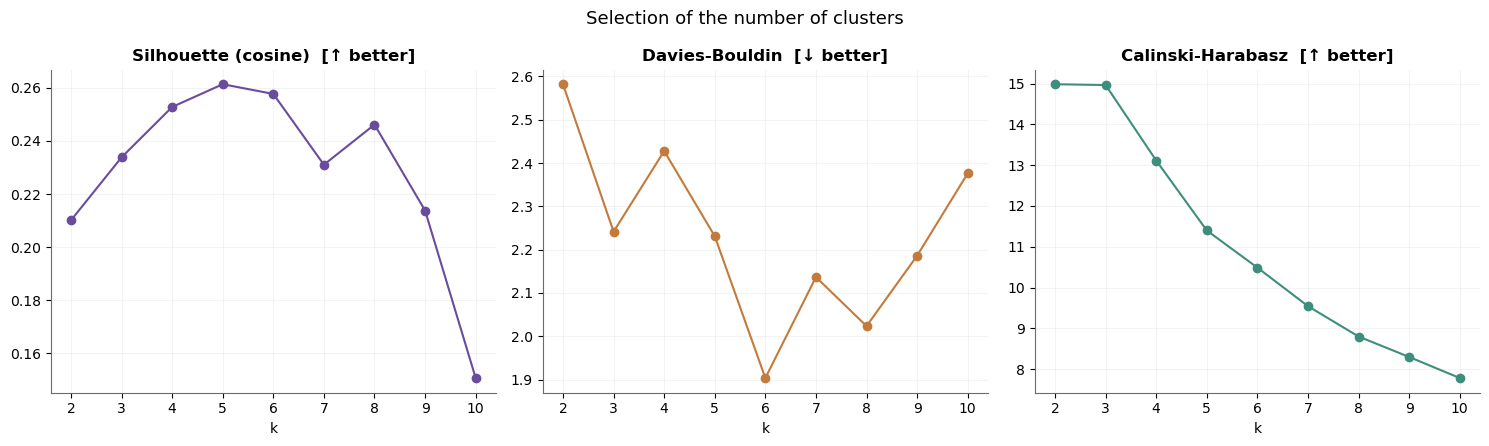

In [50]:
n     = len(datasets)
max_k = min(MAX_K_CLUSTERS, n - 1)

k_metrics = []

if max_k < 2:
    print("Dataset too small for clustering (n < 3).")
else:
    for k in range(2, max_k + 1):
        km     = KMeans(n_clusters=k, random_state=SEED, n_init=20)
        labels = km.fit_predict(dataset_embeddings_cluster)
        k_metrics.append({
            "k"                : k,
            "silhouette"       : silhouette_score(dataset_embeddings_cluster, labels, metric="cosine"),
            "davies_bouldin"   : davies_bouldin_score(dataset_embeddings_cluster, labels),
            "calinski_harabasz": calinski_harabasz_score(dataset_embeddings_cluster, labels),
        })

k_metrics_df = pd.DataFrame(k_metrics)
display(k_metrics_df)

if len(k_metrics_df) > 0:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    plot_metrics = [
        ("silhouette",        "Silhouette (cosine)", EMB_COLOUR,     "↑ better"),
        ("davies_bouldin",    "Davies-Bouldin",        TFIDF_COLOUR,   "↓ better"),
        ("calinski_harabasz", "Calinski-Harabasz",     "#3E8E7E",   "↑ better"),
    ]
    for ax, (col, title_text, colour, note) in zip(axes.flat, plot_metrics):
        ax.plot(k_metrics_df["k"], k_metrics_df[col], marker="o", color=colour)
        ax.set_title(f"{title_text}  [{note}]"); ax.set_xlabel("k"); ax.grid(True, alpha=0.3)
    plt.suptitle("Selection of the number of clusters", fontsize=13)
    plt.tight_layout(); plt.show()

**Rigorous interpretation of the selection of (k).**

The internal metrics help to choose an exploratory partition, but they do not determine the «true» number of themes. In Porto, the metrics point to different values: the *silhouette* is at its maximum at k = 5 (0.261), the Davies-Bouldin index is at its minimum at k = 6 (1.904) and the Calinski-Harabasz index is at its maximum at k = 2 (14.98). The rule defined in the configuration (maximum silhouette) was applied, which led to k = 5. The maximum value of the silhouette is low, indicating weak separation between groups. The selected solution (k = 5) neither validates nor invalidates an external taxonomy of six dimensions.

In [51]:
# Automatic choice: k with the highest silhouette.
# You can change K_CLUSTERS manually in section 1 if the substantive interpretation justifies another value.

if K_CLUSTERS is not None:
    K_FINAL = K_CLUSTERS
    print(f"K_FINAL set manually in the configuration: {K_FINAL}")
elif len(k_metrics_df) > 0:
    K_FINAL = int(k_metrics_df.sort_values("silhouette", ascending=False).iloc[0]["k"])
    print(f"K_FINAL chosen automatically by maximum silhouette: {K_FINAL}")
else:
    K_FINAL = 1
    print("K_FINAL = 1 (insufficient datasets for clustering)")

print(f"\n  K final: {K_FINAL}")

K_FINAL chosen automatically by maximum silhouette: 5

  K final: 5


### 9.3 Application of the final clustering
With the chosen value of `k`, the KMeans algorithm is applied to the embeddings of the datasets. KMeans groups the datasets so as to minimise the sum of the squared distances of each dataset to the centroid of its cluster.

`n_init=50` random restarts are used (instead of the default of 10) to reduce the probability of the algorithm converging to a local optimum. `random_state=SEED` ensures reproducibility.

For each dataset, the **cosine similarity to the centroid of its cluster** is computed - the higher it is, the more representative the dataset is of the central theme of its cluster. The datasets with the highest similarity to the centroid are the most "typical" of the cluster and are presented in a table of representatives.

**Why KMeans and not another algorithm (e.g. DBSCAN, hierarchical clustering)?** KMeans was
chosen for three practical reasons: (1) it scales well to the size of this corpus and is
computationally inexpensive, making it possible to test multiple values of k quickly in Section
9.2; (2) it produces approximately spherical clusters in the space of normalised embeddings,
which is compatible with the cosine similarity metric used consistently in the rest of the
notebook; (3) it is widely documented and interpretable - each cluster has an explicit centroid,
which makes possible the analysis of the "most representative datasets" (highest similarity to the centroid)
carried out in this section. `n_init=50` (instead of the default value) increases the robustness of the initialisation,
reducing the probability of the algorithm converging to a suboptimal local minimum.

In [52]:
datasets_clusters = datasets.copy()

if K_FINAL <= 1:
    datasets_clusters["semantic_cluster"]    = 0
    datasets_clusters["centroid_similarity"] = np.nan
else:
    kmeans_final = KMeans(n_clusters=K_FINAL, random_state=SEED, n_init=50)
    clusters     = kmeans_final.fit_predict(dataset_embeddings_cluster)
    datasets_clusters["semantic_cluster"] = clusters

    centroids    = kmeans_final.cluster_centers_
    sim_centroids = cosine_similarity(dataset_embeddings_cluster, centroids)
    datasets_clusters["centroid_similarity"] = [
        sim_centroids[i, clusters[i]] for i in range(len(clusters))
    ]

print(f"Clustering with K={K_FINAL} completed.")
print("\nDistribution of the datasets by cluster:")
display(datasets_clusters["semantic_cluster"].value_counts().sort_index().rename("n_datasets"))

# Most representative datasets of each cluster
representative = (
    datasets_clusters
    .sort_values(["semantic_cluster","centroid_similarity"], ascending=[True, False])
    .groupby("semantic_cluster")
    .head(5)
    [["semantic_cluster","dataset_id","title","description","centroid_similarity"]]
)
print("\nMost representative datasets by cluster:")
display(representative)

Clustering with K=5 completed.

Distribution of the datasets by cluster:


semantic_cluster
0    28
1    26
2     6
3    30
4    20
Name: n_datasets, dtype: int64


Most representative datasets by cluster:


,semantic_cluster,dataset_id,title,description,centroid_similarity
55,0,160e3b3d-f036-49b5-8efa-b5fb0b7456b7,Correios,Pontos de Interesse da Cidade do Porto relativos a Correios,0.917511
35,0,11317990-0956-4829-95ea-6fcb40f704bc,Miradouros,Pontos de Interesse da Cidade do Porto relativos Miradouros,0.885539
24,0,43a5d0fe-6938-4d98-ab6c-aeafbf8e38e3,Museus,Pontos de Interesse da Cidade do Porto relativos a Museus e Centros temáticos,0.874443
26,0,7391c6e4-5678-4817-9ca3-f03cc0251549,Ruas e Praças,Pontos de Interesse da Cidade do Porto relativos a ruas e praças,0.852157
30,0,d229735e-4c7a-41e9-b7f3-d4a85d8c6bfe,Postos de Turismo,Pontos de Interesse da Cidade do Porto relativos a postos de turismo,0.851039
85,1,a37a55c6-8b2d-4242-a062-b0f387df106d,Carta de Estrutura Ecológica Municipal - PDM 2021,Esta Carta pertence à Planta de Ordenamento do PDM 2021. Integra informação relativa à distribuição espacial das diferentes áreas e recursos que pelas suas ...,0.912550
14,1,d4e25418-a180-4927-affd-5748f4c94811,Carta de Condicionantes Geral Dinâmica - PDM 2021,Esta Carta pertence à Planta de Condicionantes do PDM 2021. Integra informação atualizada relativa à localização de áreas sujeitas a servidões administrativ...,0.890774
11,1,7443ef22-5824-474f-aa5a-b51f412d1051,Carta da Estrutura Viária e Estacionamento - PDM 2021,Esta Carta pertence à Planta de Ordenamento do PDM 2021. Integra informação relativa à representação dos canais rodoviários de acordo com o tipo de serviço ...,0.886386
83,1,bcaeb7c7-1239-4526-b572-817cca7d46d9,Carta de Zonamento Perequativo - PDM 2021,"Integra dados relativos à delimitação das unidades territoriais estabelecidas para efeitos de perequação da edificabilidade, bem como a identificação das ár...",0.871953
70,1,e6bff4b8-ebe8-4048-a3ca-6a1640da8293,Carta de Qualificação do Solo - PDM 2021,Esta Carta pertence à Planta de Ordenamento do PDM 2021. Integra dados relativos à delimitação das diferentes categorias e subcategorias estabelecidas para ...,0.847229


**Analysis of the results (9.3 — Application of the final clustering).**

With k = 5, KMeans produces five groups of unequal size: **Cluster 0 with 28 datasets (25.5%)**,
**Cluster 1 with 26 (23.6%)**, **Cluster 2 with 6 (5.5%)**, **Cluster 3 with 30 (27.3%)** and **Cluster 4 with
20 (18.2%)**. The most representative datasets suggest the following reading, to be confirmed with the terms of the
next cell: points of interest and tourism (Cluster 0), PDM maps (Cluster 1), citizen
services (Cluster 2), geographic layers of traffic, parking and active modes (Cluster 3) and
statistical indicators and public housing (Cluster 4). Several of these groups coincide with series with
standardised descriptions, so they may reflect both the theme and the cataloguing model.

#### 9.3.2 Composition of the clusters by document series

Cross-tabulation of the final clusters with the series identified in 4.1.1 (Section 4.6 of the dissertation).

In [53]:
# ── 9.3.2 Cluster × document series ──────────────────────────────────────────
_ct = pd.crosstab(datasets_clusters["semantic_cluster"],
                  SERIES_BY_ID.reindex(datasets_clusters["dataset_id"]).to_numpy(),
                  rownames=["cluster"], colnames=["series"], margins=True, margins_name="Total")
DISSERTATION_COUNTS["Cluster×series"] = _ct.reset_index()
display(_ct)

series,'Layer de geometria tipo…' layers,Outside the series,Points of interest,Records with 'PDM' in the name,Total
cluster,,,,,
0,0,3,25,0,28
1,0,5,0,21,26
2,0,5,1,0,6
3,24,6,0,0,30
4,0,20,0,0,20
Total,24,39,26,21,110


### 9.4 Representative terms by cluster

To interpret the clusters found lexically, TF-IDF is fitted to the texts of the datasets and, for each term, the mean weight **inside and outside each cluster** is compared. The terms with the greatest positive difference are the ones that best characterise, relatively, the vocabulary of the datasets in that group.

#### Important: TF-IDF is interpretative here, not classificatory

This is a completely different use from the TF-IDF used in Section 6. Here, datasets are not being compared with anchors; the most characteristic terms of each group discovered by the clustering are being extracted. The aim is only to help the human analyst understand what the datasets of each cluster have in common, giving it an interpretable name or label.

For example, if Cluster 0 has "via", "estrada", "percurso", "sinalização", "transporte" (road, route, signage, transport) as representative terms, it may be interpreted, as a hypothesis to be confirmed with the representative records, as close to the "Mobility" dimension, even though the clustering algorithm discovered it without any information about dimensions.


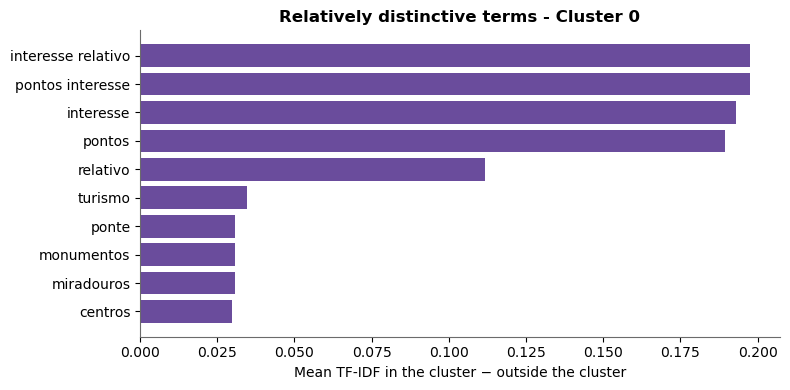

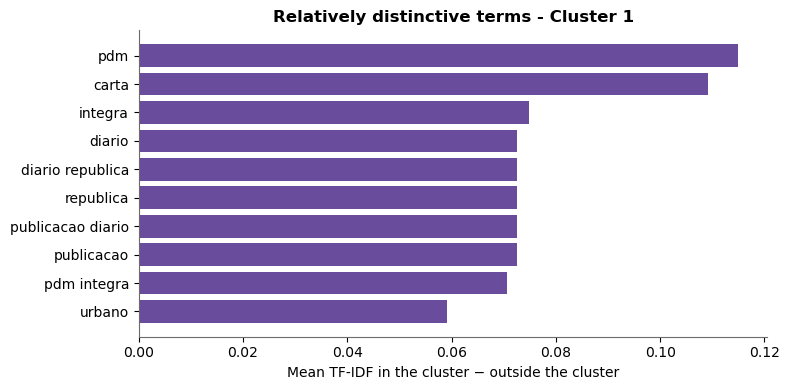

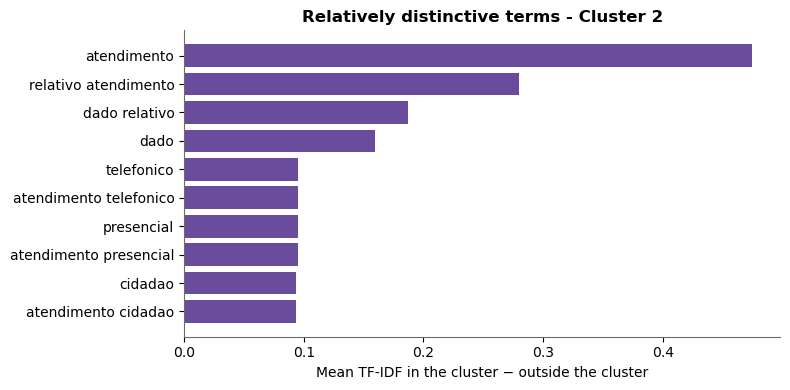

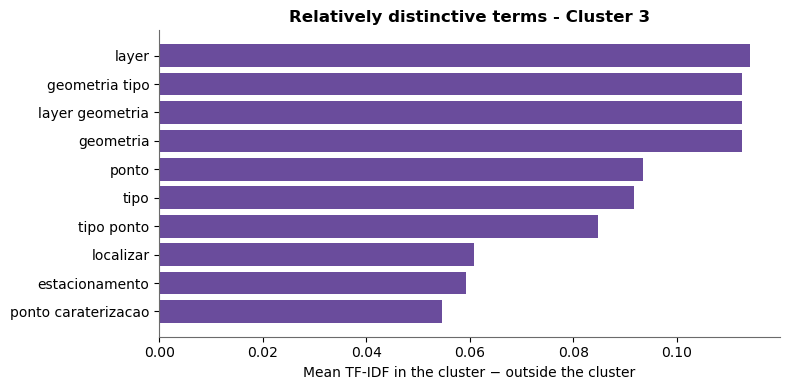

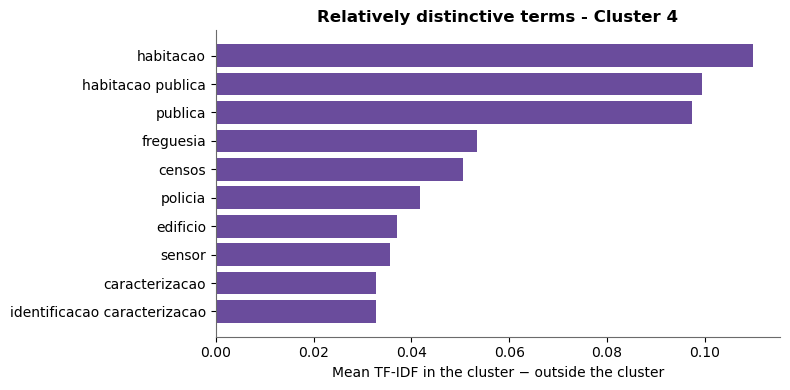

In [54]:
tfidf_cl = TfidfVectorizer(**TFIDF_CLUSTER_PARAMS, stop_words=list(STOPWORDS_TFIDF))
X_tfidf_cl = tfidf_cl.fit_transform(datasets_clusters["doc_text_tfidf"])
vocab_terms = np.array(tfidf_cl.get_feature_names_out())

terms_by_cluster = []
for cid in sorted(datasets_clusters["semantic_cluster"].unique()):
    idx = (datasets_clusters["semantic_cluster"] == cid).to_numpy()
    mean_in = np.asarray(X_tfidf_cl[idx].mean(axis=0)).ravel()
    mean_out = np.asarray(X_tfidf_cl[~idx].mean(axis=0)).ravel() if (~idx).any() else np.zeros_like(mean_in)
    distinctiveness = mean_in - mean_out
    top = distinctiveness.argsort()[::-1][:20]
    for term, m_in, m_out, dif in zip(vocab_terms[top], mean_in[top], mean_out[top], distinctiveness[top]):
        if dif > 0:
            terms_by_cluster.append({
                "semantic_cluster": cid, "term": term,
                "mean_tfidf_in_cluster": float(m_in), "mean_tfidf_outside": float(m_out),
                "mean_distinctiveness": float(dif),
            })
terms_by_cluster_df = pd.DataFrame(terms_by_cluster)

for cid in sorted(datasets_clusters["semantic_cluster"].unique()):
    subset = terms_by_cluster_df.query("semantic_cluster == @cid").head(10)
    if subset.empty: continue
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.barh(subset["term"][::-1], subset["mean_distinctiveness"][::-1], color=EMB_COLOUR)
    ax.set_xlabel("Mean TF-IDF in the cluster − outside the cluster")
    ax.set_title(f"Relatively distinctive terms - Cluster {cid}")
    plt.tight_layout(); plt.show()

**Rigorous interpretation of the cluster terms.**

The terms are sorted by the difference between the mean TF-IDF weight inside and outside each cluster. This measure is more informative than the internal frequency alone, but it remains descriptive and may contain redundant unigrams and bigrams. The thematic interpretation should be confirmed through the datasets closest to the centroid and through qualitative inspection.

### 9.5 Visualisation of the clusters with PCA

The embeddings have 384 dimensions and cannot be visualised directly. **Principal Component Analysis (PCA)** projects the embeddings onto 2 dimensions, preserving as much of the original variance as possible.

The variance explained by the first two principal components is indicated in the axis labels. If the explained variance is low (e.g. PC1 + PC2 < 30%), the projection loses a lot of information and the chart should be interpreted with caution: clusters that appear to overlap in 2D may be well separated in the original space.

#### The clustering was built in the original space

It is essential to stress that the clustering was built and evaluated in the original 384-dimensional space (with the cosine silhouette metric), not in the 2D projection. PCA is used only for visualisation, never to determine the clusters. The projection may distort distances and make clusters that are well defined in the original space appear to overlap.


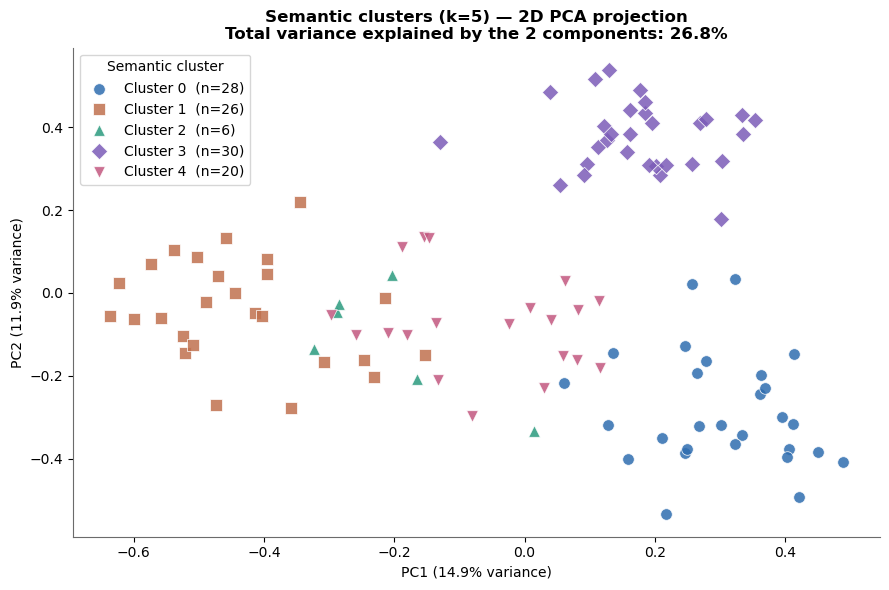

Note: the clustering was built in the original embedding space (384 dimensions), not in this 2D projection. PCA is only an auxiliary visualisation.
Caution: the 2 components shown explain only 26.8% of the total variance — the visual separation here is illustrative and may hide/distort part of the real 384-dimensional structure.


In [55]:
if len(datasets_clusters) >= 2:
    pca   = PCA(n_components=2, random_state=SEED)
    coords = pca.fit_transform(dataset_embeddings_cluster)
    datasets_clusters["pca_1"] = coords[:, 0]
    datasets_clusters["pca_2"] = coords[:, 1]

    var_exp = pca.explained_variance_ratio_ * 100
    var_total = var_exp[:2].sum()

    # Discrete legend — one entry per cluster, with explicit colour and count of
    # datasets (a continuous colour bar would not correspond to discrete clusters).
    cluster_ids = sorted(datasets_clusters["semantic_cluster"].unique())
    # Fixed colours and markers per cluster (sober palette + shape as secondary encoding)

    fig, ax = plt.subplots(figsize=(9, 6))
    for idx, cid in enumerate(cluster_ids):
        mask = datasets_clusters["semantic_cluster"] == cid
        n_points = mask.sum()
        ax.scatter(
            datasets_clusters.loc[mask, "pca_1"],
            datasets_clusters.loc[mask, "pca_2"],
            color=CATEGORICAL_PALETTE[idx % len(CATEGORICAL_PALETTE)], marker=MARKERS[idx % len(MARKERS)],
            alpha=0.85, s=70, edgecolors="white", linewidths=0.6,
            label=f"Cluster {cid}  (n={n_points})",
        )
    ax.legend(title="Semantic cluster", loc="best", frameon=True)
    ax.set_xlabel(f"PC1 ({var_exp[0]:.1f}% variance)")
    ax.set_ylabel(f"PC2 ({var_exp[1]:.1f}% variance)")
    ax.set_title(
        f"Semantic clusters (k={K_FINAL}) — 2D PCA projection\n"
        f"Total variance explained by the 2 components: {var_total:.1f}%"
    )
    plt.tight_layout(); plt.show()

    # Note: the variance explained by the first 2 components is
    # typically low (~30%) because the embedding space has 384
    # dimensions — the visual separation in 2D is only illustrative, NOT a
    # faithful representation of the full structure used by KMeans (which
    # operated on the original 384 dimensions, not on this projection).
    print(f"Note: the clustering was built in the original embedding space "
          f"(384 dimensions), not in this 2D projection. PCA is only an "
          f"auxiliary visualisation.")
    print(f"Caution: the 2 components shown explain only {var_total:.1f}% "
          f"of the total variance — the visual separation here is illustrative and "
          f"may hide/distort part of the real 384-dimensional structure.")


**Analysis of the results (9.5 — Visualisation of the clusters with PCA).**

The projection onto 2 principal components explains only **26.8% of the total variance** (14.9% + 11.9%).
The visual separation is therefore illustrative and partial: KMeans was applied in the full
384-dimensional space, not in this projection. Clusters 0 (points of interest), 1 (PDM maps) and 3
(traffic and parking) appear relatively far apart in the plane, whereas Cluster 2
(citizen services, 6 datasets) and Cluster 4 (indicators and housing) partially overlap other
groups. This overlap in the projection does not, on its own, make it possible to assess the quality of the clustering; the
internal metrics (Section 9.2) indicate weak separation (silhouette = 0.261).

## 10. Relationship between clusters and assigned dimensions

This section cross-references the results of the two approaches:
- The **semantic clusters** of Section 9 (discovered in an unsupervised way, without information about dimensions);
- The **assigned dimensions** of Sections 6 and 7 (based on similarity with the anchor texts).

The analysis is carried out for **all 4 anchor versions** (original, 50 words, 100 words,
150 words), making it possible to assess whether the correspondence between clusters and dimensions is robust
regardless of the wording of the anchors, or whether it varies with the length and vocabulary of the reference
texts. The clusters (Section 9) are fixed — built only once from the embeddings
of the datasets — and what changes between versions is only the Smart City dimension assigned to each dataset.

### Cluster × dimension matrices

For each cluster, the percentage of datasets in each Smart City dimension is computed (row normalisation). A row with 90% in a single column indicates that almost all the datasets in that cluster were classified in the same dimension — the cluster "corresponds" to that dimension. A row spread across several columns indicates a thematically mixed cluster.

If the clusters coincide with the dimensions, this constitutes descriptive evidence of a structural correspondence
between two organisations of the corpus — not a validation of the classification system or of the
taxonomy, because both depend on the same embedding model and may respond to the same
repeated vocabulary. Divergences may reveal groupings (for example, by document type
or description template) that the taxonomy does not capture.

**How to read the cross-tabulation (crosstab) that follows:** each cell shows the percentage of
datasets of a given cluster (row) that were classified in a given Smart City
dimension (column), by the method indicated. Normalisation is done by row (`normalize="index"`), that is, each row sums to 100%. This answers the question "within this cluster, how are the
assigned dimensions distributed?", instead of "within this dimension, how are
the clusters distributed?" (which would be the inverse question, normalised by column). The first formulation is
more natural in this context because the aim is to characterise each cluster found by its
composition in terms of the existing taxonomy.


  Anchor version: original


,dataset_id,title,semantic_cluster,dimension_embeddings,dimension_tfidf
0,37dc9216-0b42-4eb8-9817-7d85309e6def,Parques de estacionamento municipais,3,Smart Environment,Smart Environment
1,d85836f9-e683-4be4-8b69-5260f5611be6,Parques Privativos,3,Smart Environment,Smart Mobility
2,ee4a4efe-b6f9-45e7-9b7b-0aeeca689dda,Condicionamentos de trânsito,3,Smart Mobility,Smart Mobility
3,cb350387-ceb0-4aac-8a27-adfcf512a456,Condicionamentos não programados,3,Smart Environment,Smart Environment
4,563cc44a-a778-45ac-ae21-0a6445e10e01,Cargas e descargas,3,Smart Mobility,None


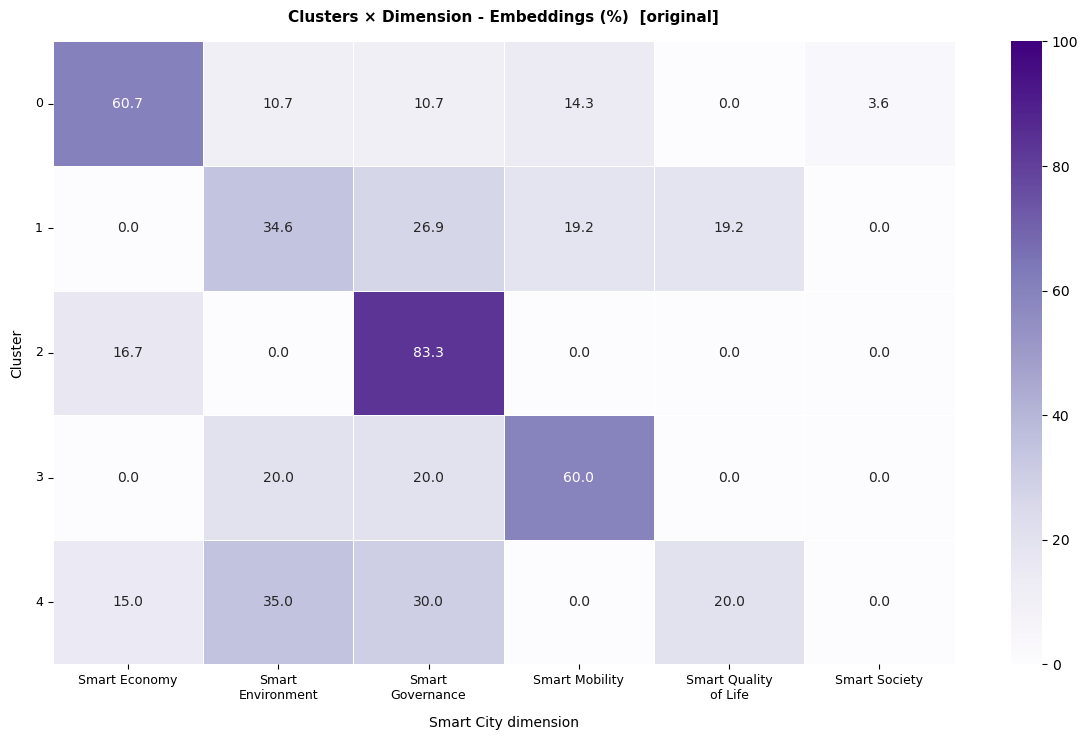

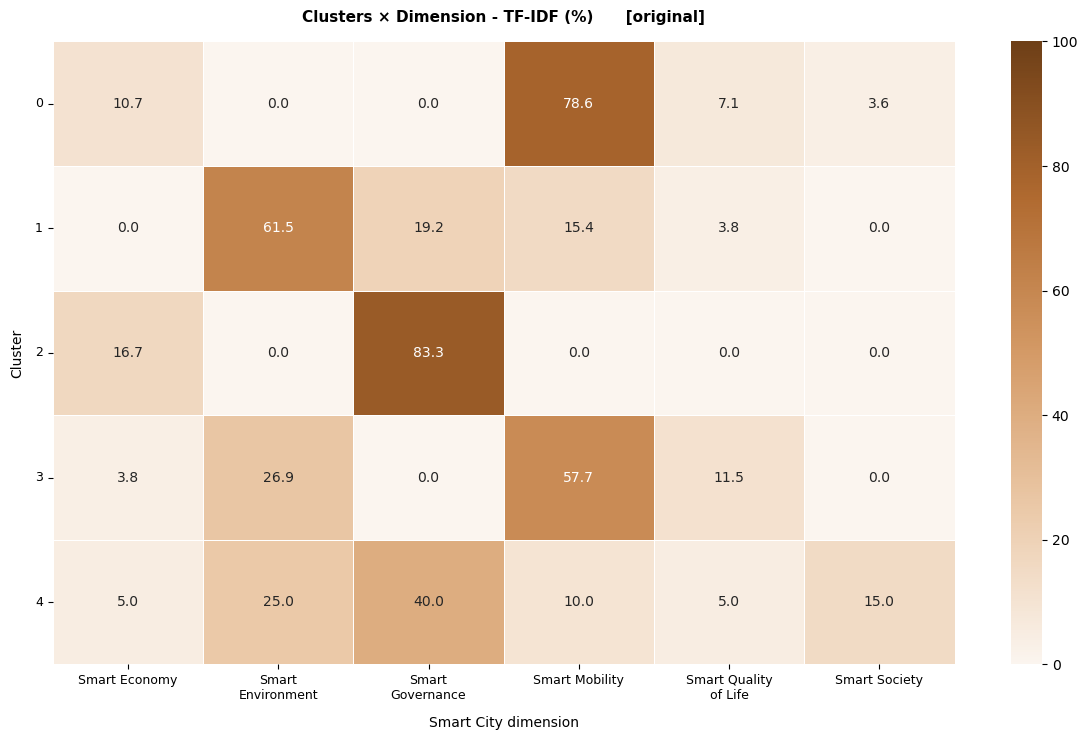


  Anchor version: 50_words


,dataset_id,title,semantic_cluster,dimension_embeddings,dimension_tfidf
0,37dc9216-0b42-4eb8-9817-7d85309e6def,Parques de estacionamento municipais,3,Smart Environment,None
1,d85836f9-e683-4be4-8b69-5260f5611be6,Parques Privativos,3,Smart Environment,Smart Mobility
2,ee4a4efe-b6f9-45e7-9b7b-0aeeca689dda,Condicionamentos de trânsito,3,Smart Environment,Smart Environment
3,cb350387-ceb0-4aac-8a27-adfcf512a456,Condicionamentos não programados,3,Smart Environment,None
4,563cc44a-a778-45ac-ae21-0a6445e10e01,Cargas e descargas,3,Smart Mobility,None


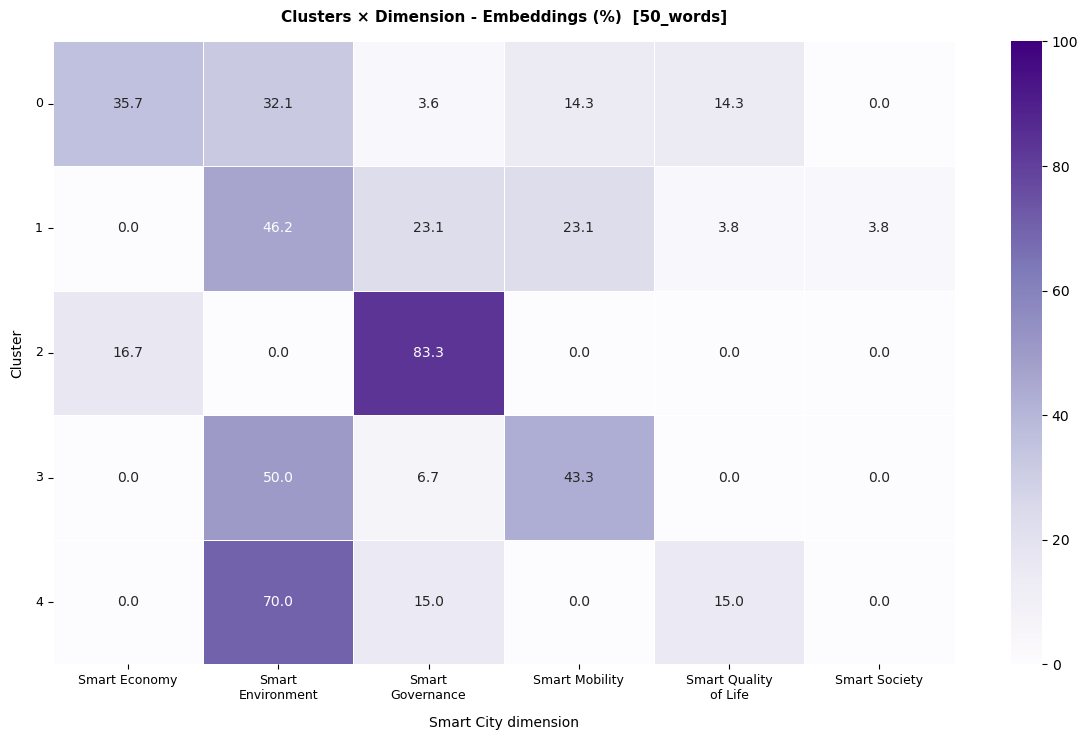

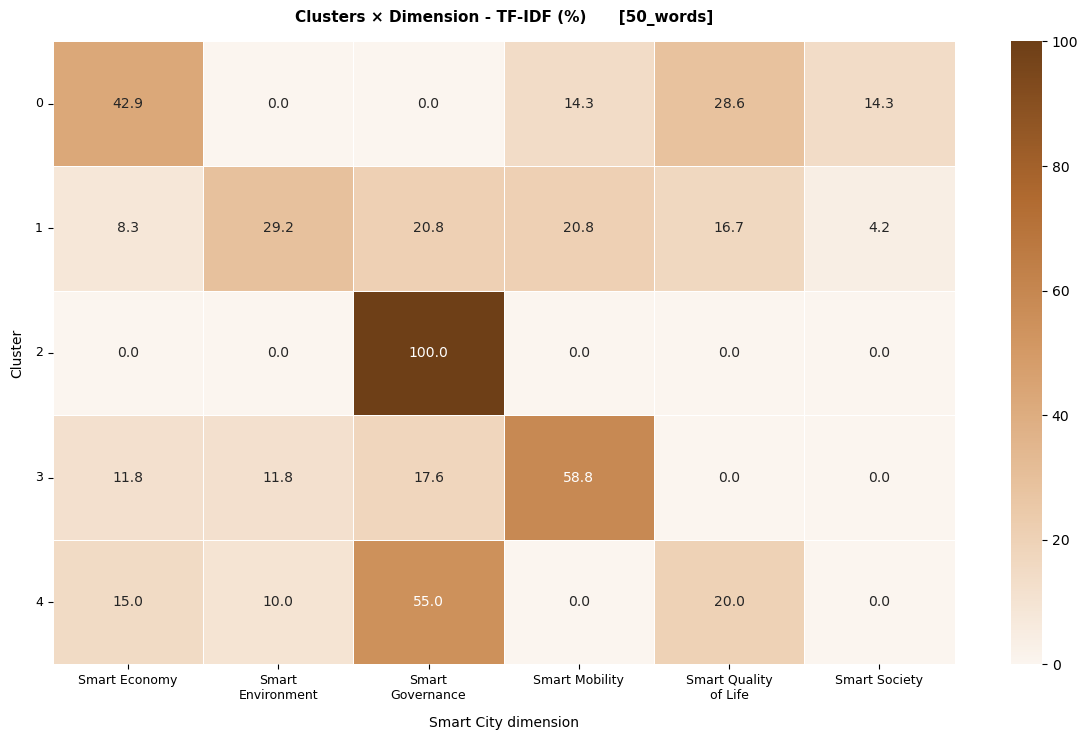


  Anchor version: 100_words


,dataset_id,title,semantic_cluster,dimension_embeddings,dimension_tfidf
0,37dc9216-0b42-4eb8-9817-7d85309e6def,Parques de estacionamento municipais,3,Smart Environment,None
1,d85836f9-e683-4be4-8b69-5260f5611be6,Parques Privativos,3,Smart Governance,Smart Mobility
2,ee4a4efe-b6f9-45e7-9b7b-0aeeca689dda,Condicionamentos de trânsito,3,Smart Mobility,Smart Environment
3,cb350387-ceb0-4aac-8a27-adfcf512a456,Condicionamentos não programados,3,Smart Quality of Life,None
4,563cc44a-a778-45ac-ae21-0a6445e10e01,Cargas e descargas,3,Smart Mobility,None


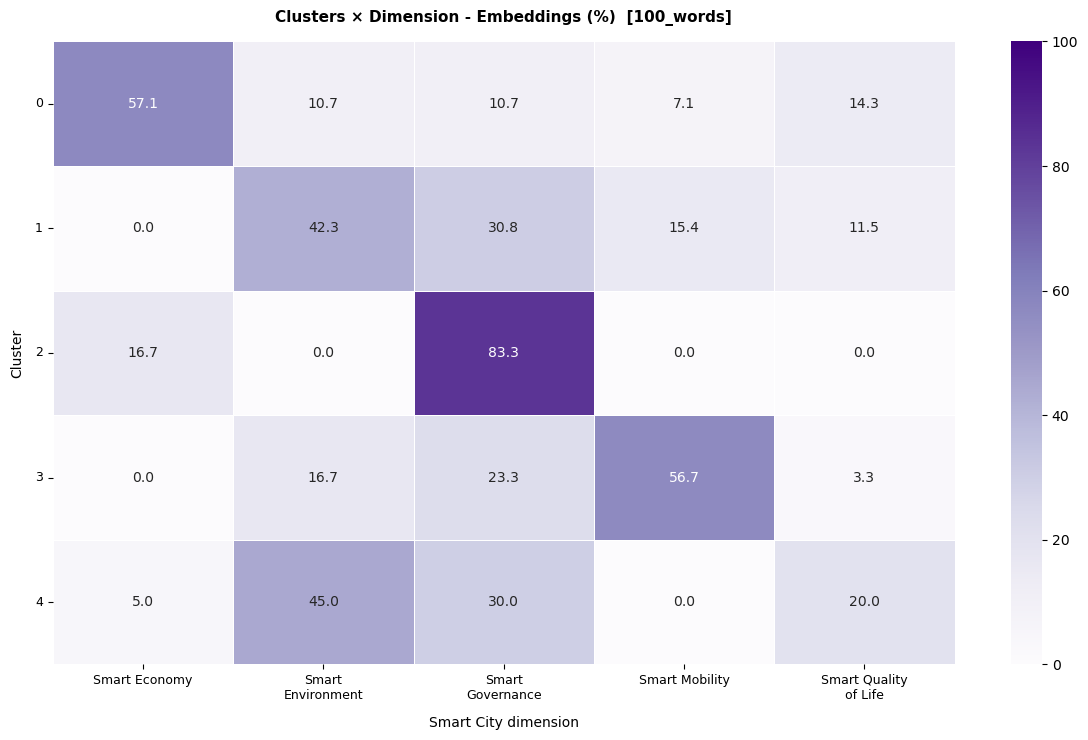

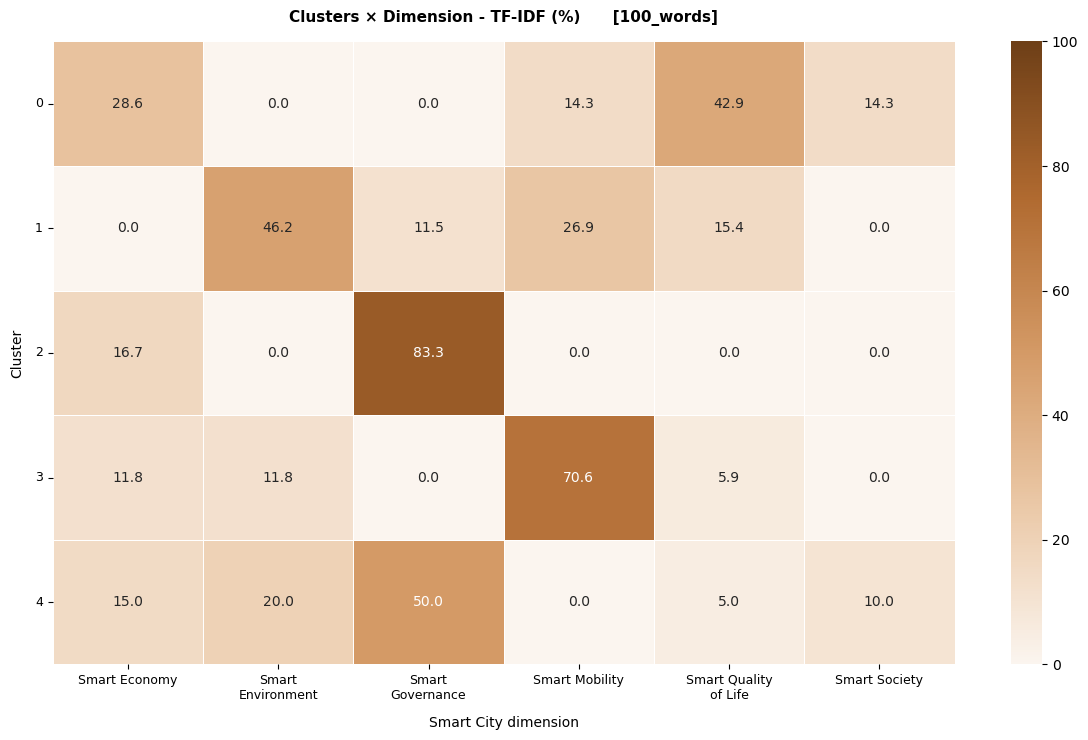


  Anchor version: 150_words


,dataset_id,title,semantic_cluster,dimension_embeddings,dimension_tfidf
0,37dc9216-0b42-4eb8-9817-7d85309e6def,Parques de estacionamento municipais,3,Smart Environment,Smart Mobility
1,d85836f9-e683-4be4-8b69-5260f5611be6,Parques Privativos,3,Smart Environment,Smart Mobility
2,ee4a4efe-b6f9-45e7-9b7b-0aeeca689dda,Condicionamentos de trânsito,3,Smart Mobility,Smart Environment
3,cb350387-ceb0-4aac-8a27-adfcf512a456,Condicionamentos não programados,3,Smart Environment,Smart Mobility
4,563cc44a-a778-45ac-ae21-0a6445e10e01,Cargas e descargas,3,Smart Mobility,None


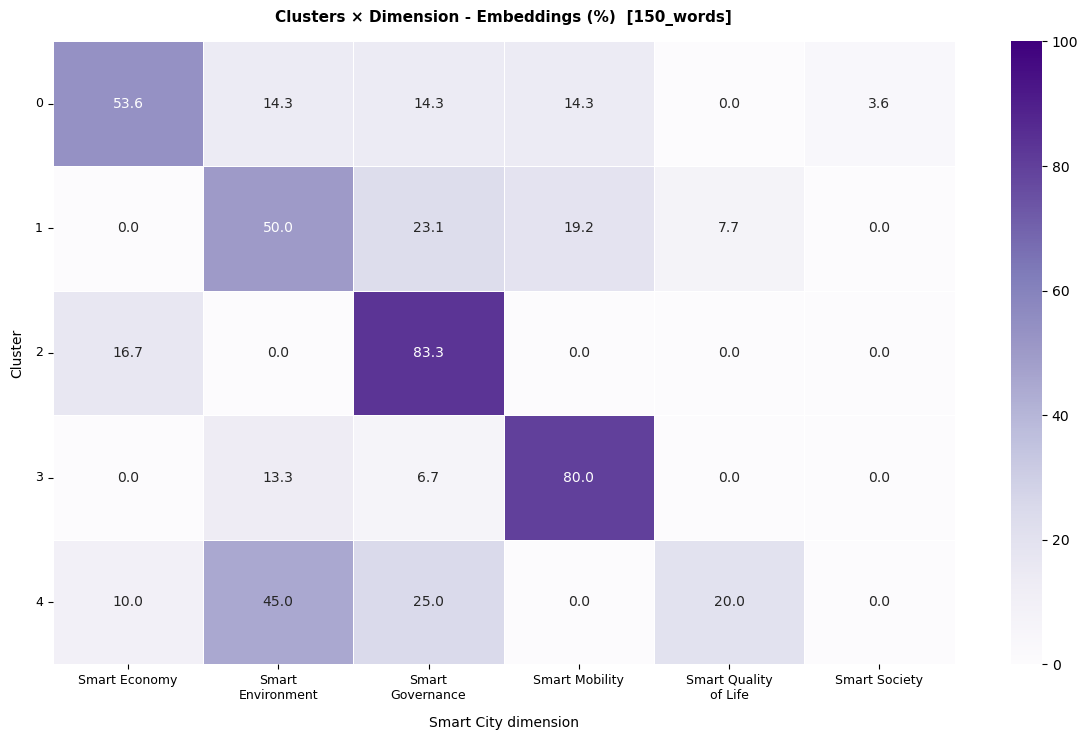

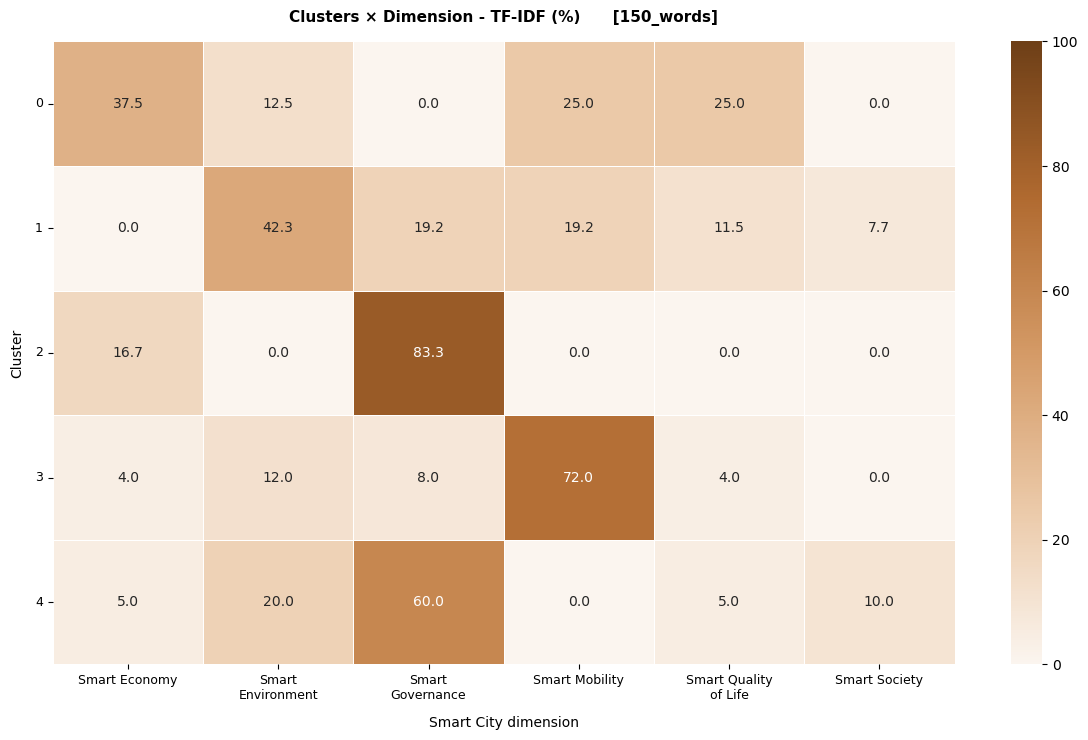


datasets_clusters: added the dimensions of the 4 anchor versions.


In [56]:
# ── Cluster × dimension matrices for ALL anchor versions ─────────────────────
# For each anchor version, we join the dimensions assigned by Embeddings
# and TF-IDF to the clusters DataFrame and produce two heatmaps (one per method).
# This makes it possible to see whether the correspondence between clusters and dimensions is robust
# regardless of the anchor version used, or whether it varies between versions.

for version, obj in results_by_version.items():
    class_v = obj["results"][["dataset_id", "dimension_embeddings", "dimension_tfidf"]]

    # Join to the clusters — suffixes to avoid conflicts if we iterate several times
    dc_v = datasets_clusters[["dataset_id", "title", "semantic_cluster"]].merge(
        class_v, on="dataset_id", how="left", validate="one_to_one"
    )

    print(f"\n{'='*70}")
    print(f"  Anchor version: {version}")
    print(f"{'='*70}")
    display(dc_v[["dataset_id", "title", "semantic_cluster",
                   "dimension_embeddings", "dimension_tfidf"]].head())

    for col, title_text, cmap in [
        ("dimension_embeddings",
         f"Clusters × Dimension - Embeddings (%)  [{version}]", CMAP_EMB),
        ("dimension_tfidf",
         f"Clusters × Dimension - TF-IDF (%)      [{version}]", CMAP_TFIDF),
    ]:
        valid = dc_v.dropna(subset=[col])
        if valid.empty:
            print(f"  No valid data for {col} in version {version}")
            continue
        mat = pd.crosstab(valid["semantic_cluster"], valid[col],
                          normalize="index") * 100
        n_rows = len(mat)
        fig, ax = plt.subplots(figsize=(12, max(4.5, 1.5 * n_rows)))
        sns.heatmap(mat, annot=True, fmt=".1f", cmap=cmap,
                    vmin=0, vmax=100, ax=ax, linewidths=0.5,
                    annot_kws={"size": 10})
        ax.set_title(title_text, fontsize=11, fontweight="bold", pad=14)
        ax.set_xlabel("Smart City dimension", labelpad=10)
        ax.set_ylabel("Cluster", labelpad=8)
        # Dimension labels slanted (45°) for legibility
        ax.tick_params(axis="x", labelsize=9); format_x_labels(ax)
        ax.tick_params(axis="y", labelsize=9); horizontal_y_labels(ax)
        plt.tight_layout()
        plt.show()

# Add to datasets_clusters the dimensions assigned in EACH version
# (columns dimension_embeddings_<version> and dimension_tfidf_<version>), for export.
for version, obj in results_by_version.items():
    dims_v = obj["results"][["dataset_id", "dimension_embeddings", "dimension_tfidf"]].rename(columns={
        "dimension_embeddings": f"dimension_embeddings_{version}",
        "dimension_tfidf": f"dimension_tfidf_{version}",
    })
    # Removes columns of the same version if they already exist (avoids duplication on re-execution)
    datasets_clusters = datasets_clusters.drop(
        columns=[c for c in dims_v.columns if c != "dataset_id" and c in datasets_clusters.columns])
    datasets_clusters = datasets_clusters.merge(dims_v, on="dataset_id", how="left", validate="one_to_one")
print(f"\ndatasets_clusters: added the dimensions of the {len(results_by_version)} anchor versions.")


### 10.1 Executive summary

In [57]:
# ── Automatic descriptive summary ─────────────────────────────────────────────
print("=" * 72); print("DESCRIPTIVE SUMMARY — DOES NOT CONSTITUTE A VALIDATION OF ACCURACY"); print("=" * 72)
print(f"Datasets: {len(datasets)} | versions: {len(results_by_version)} | dimensions: "
      f"{len(next(iter(results_by_version.values()))['scores_embeddings'].columns)}")

st_emb = (~instability_df["unstable_emb"]).mean() * 100
mask_tf = instability_df["tfidf_valid_all_versions"]
st_tf = ((~instability_df.loc[mask_tf, "unstable_tfidf_among_valid"]).mean() * 100
          if mask_tf.any() else np.nan)
print(f"\nEmbeddings — same dimension in the four versions: {st_emb:.1f}% (n={len(instability_df)})")
print(f"TF-IDF — same dimension among valid cases in the four versions: {st_tf:.1f}% (n={mask_tf.sum()})")
print(f"TF-IDF — stable coverage: {instability_df['tfidf_coverage_stable'].mean()*100:.1f}%")

for method, agreement_col in [("Embeddings", "agreement_emb_%"), ("TF-IDF — valid", "agreement_tfidf_valid_%")]:
    best_row = pairwise_comparison_df.loc[pairwise_comparison_df[agreement_col].idxmax()]
    worst_row = pairwise_comparison_df.loc[pairwise_comparison_df[agreement_col].idxmin()]
    print(f"\n{method}: highest agreement {best_row['version_1']} × {best_row['version_2']} = {best_row[agreement_col]:.1f}%")
    print(f"{method}: lowest agreement {worst_row['version_1']} × {worst_row['version_2']} = {worst_row[agreement_col]:.1f}%")

print(f"\nExploratory clustering: k={K_FINAL}")
for cid, n_ds in datasets_clusters["semantic_cluster"].value_counts().sort_index().items():
    terms = terms_by_cluster_df.query("semantic_cluster == @cid")["term"].head(6).tolist()
    print(f"Cluster {cid}: n={n_ds}; relatively distinctive terms: {', '.join(terms) or '—'}")
print("\nNote: stability, agreement and clustering describe internal consistency; they do not measure correctness.")

DESCRIPTIVE SUMMARY — DOES NOT CONSTITUTE A VALIDATION OF ACCURACY
Datasets: 110 | versions: 4 | dimensions: 6

Embeddings — same dimension in the four versions: 52.7% (n=110)
TF-IDF — same dimension among valid cases in the four versions: 52.8% (n=72)
TF-IDF — stable coverage: 68.2%

Embeddings: highest agreement original × 100_words = 81.8%
Embeddings: lowest agreement original × 50_words = 62.7%

TF-IDF — valid: highest agreement 100_words × 150_words = 77.3%
TF-IDF — valid: lowest agreement original × 50_words = 60.8%

Exploratory clustering: k=5
Cluster 0: n=28; relatively distinctive terms: interesse relativo, pontos interesse, interesse, pontos, relativo, turismo
Cluster 1: n=26; relatively distinctive terms: pdm, carta, integra, diario, diario republica, republica
Cluster 2: n=6; relatively distinctive terms: atendimento, relativo atendimento, dado relativo, dado, telefonico, atendimento telefonico
Cluster 3: n=30; relatively distinctive terms: layer, geometria tipo, layer geom

**Reading the summary.**

The summary presents separately the dimensional stability of the embeddings, the TF-IDF stability in the classifiable subset and the stability of lexical coverage. A difference between methods does not demonstrate superiority without external validation. The best and worst pairs describe only the versions tested. The clusters are exploratory and the terms presented are relatively distinctive, not validated labels.

### 10.2 Agreement between clusters and dimensions: Embeddings vs. TF-IDF

The two previous heatmaps show, separately, which dimension each cluster is
most associated with according to each method. The next cell cross-references this information
explicitly: it identifies the dominant dimension of each cluster in each method and
flags the cases in which **the two methods assign the same cluster to different
dimensions** - a structural disagreement, not just dataset-by-dataset (the cluster may be
internally coherent, but the two methods associate it with different Smart City dimensions).

In [58]:
# ── Dominant distributions by cluster with explicit denominators ─────────────
cluster_summaries = []
for version, obj in results_by_version.items():
    class_v = obj["results"][["dataset_id", "dimension_embeddings", "dimension_tfidf"]]
    dc_v = datasets_clusters[["dataset_id", "semantic_cluster"]].merge(
        class_v, on="dataset_id", validate="one_to_one")
    for cid, sub in dc_v.groupby("semantic_cluster", sort=True):
        emb_counts = sub["dimension_embeddings"].value_counts()
        tf_counts = sub["dimension_tfidf"].value_counts()
        de = emb_counts.index[0] if len(emb_counts) else None
        dt = tf_counts.index[0] if len(tf_counts) else None
        n_tf = int(sub["dimension_tfidf"].notna().sum())
        tie_emb = len(emb_counts) > 1 and emb_counts.iloc[0] == emb_counts.iloc[1]
        tie_tf = len(tf_counts) > 1 and tf_counts.iloc[0] == tf_counts.iloc[1]
        cluster_summaries.append({
            "version": version, "cluster": cid, "n_total": len(sub),
            "n_tfidf_valid": n_tf, "n_tfidf_zero": len(sub) - n_tf,
            "dominant_emb": de, "pct_emb_total": emb_counts.iloc[0] / len(sub) * 100 if len(emb_counts) else np.nan,
            "tie_emb": tie_emb,
            "dominant_tfidf": dt,
            "pct_tfidf_valid": tf_counts.iloc[0] / n_tf * 100 if n_tf and len(tf_counts) else np.nan,
            "pct_tfidf_total": tf_counts.iloc[0] / len(sub) * 100 if len(tf_counts) else np.nan,
            "tie_tfidf": tie_tf,
            "dominants_match": de == dt and not tie_emb and not tie_tf,
        })

cluster_dim_summary_df = pd.DataFrame(cluster_summaries)
display(cluster_dim_summary_df)
print("The coincidence of the modal categories is an aggregate synthesis and is not equivalent")
print("to dataset-by-dataset agreement or to a substantive validation of the label.")

,version,cluster,n_total,n_tfidf_valid,n_tfidf_zero,dominant_emb,pct_emb_total,tie_emb,dominant_tfidf,pct_tfidf_valid,pct_tfidf_total,tie_tfidf,dominants_match
0,original,0,28,28,0,Smart Economy,60.714286,False,Smart Mobility,78.571429,78.571429,False,False
1,original,1,26,26,0,Smart Environment,34.615385,False,Smart Environment,61.538462,61.538462,False,True
2,original,2,6,6,0,Smart Governance,83.333333,False,Smart Governance,83.333333,83.333333,False,True
3,original,3,30,26,4,Smart Mobility,60.000000,False,Smart Mobility,57.692308,50.000000,False,True
4,original,4,20,20,0,Smart Environment,35.000000,False,Smart Governance,40.000000,40.000000,False,False
5,50_words,0,28,7,21,Smart Economy,35.714286,False,Smart Economy,42.857143,10.714286,False,True
6,50_words,1,26,24,2,Smart Environment,46.153846,False,Smart Environment,29.166667,26.923077,False,True
7,50_words,2,6,6,0,Smart Governance,83.333333,False,Smart Governance,100.000000,100.000000,False,True
8,50_words,3,30,17,13,Smart Environment,50.000000,False,Smart Mobility,58.823529,33.333333,False,False
9,50_words,4,20,20,0,Smart Environment,70.000000,False,Smart Governance,55.000000,55.000000,False,False


The coincidence of the modal categories is an aggregate synthesis and is not equivalent
to dataset-by-dataset agreement or to a substantive validation of the label.


**Rigorous interpretation of the cluster–dimension relationship.**

The repetition of a modal category in all four versions constitutes evidence of a recurring aggregate pattern under the conditions tested. It does not mean that all the datasets in the cluster have that dimension, nor that the four versions are independent runs. TF-IDF percentages are presented over valid cases and over the total. The variation of the modal dimension in some clusters is compatible with conceptual overlap between dimensions, but it may also reflect the model, the anchors, the choice of (k) and the quality of the metadata. Confirmation requires manual review.

## 11. Export of the results

The results are exported to an Excel file with multiple sheets, one per component of the analysis (Section 3.6 of the dissertation). The technical checks (execution environment and token limit) are saved separately, in `outputs/porto/01_pre_chunking/checks/`.

### Exported sheets

| Sheet | Content | Section |
|-------|---------|---|
| `Summary by version` | Agreement metrics and delta bands by anchor version | 6 |
| `Relative thresholds` | Thresholds of the relative delta bands (p33/p66) by version and method | 6 |
| `Pairwise comparison` | Agreement and kappa between each pair of versions | 7.3 |
| `Res_<version>` (4 sheets) | Scores, top-1, top-2, delta and band of each dataset, by version | 6 |
| `Instability` | Dimension assigned in each version and instability indicators | 8 |
| `Clusters` | Cluster, similarity to the centroid, PCA coordinates and dimension assigned in each version | 9, 10 |
| `Terms by cluster` | Relatively distinctive terms of each cluster | 9.4 |
| `Cluster-dimension` | Modal dimension by cluster, version and method, with denominators | 10.2 |
| `Post-argmax summary` | States by version and method; flagging combining the two methods | 7.10.3 |
| `Post-argmax thresholds` | theta_low, delta_close and range_low by version and method | 7.10.1 |
| `Post-argmax_<version>` (4 sheets) | Metrics, state and reason for each dataset, by version | 7.10.3 |
| `Post-argmax by dataset` | State of each dataset in each version and method; no. of versions flagged | 7.10.5 |
| `Post-argmax review` | Single list of datasets for human review, in order of priority | 7.10.6 |
| `Post-argmax sensitivity` | Results with each parameter of the rule changed, by version | 7.10.7 |

In [59]:
# ── Export — auditable Excel file with multiple sheets ───────────────────────
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils.dataframe import dataframe_to_rows

def style_header(ws, row=1, bg="1F4E79", fg="FFFFFF"):
    for cell in ws[row]:
        cell.font = Font(bold=True, color=fg, name="Arial", size=10)
        cell.fill = PatternFill("solid", start_color=bg)
        cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

def write_df(ws, df, header_bg="1F4E79"):
    safe_df = df.copy()
    for col in safe_df.select_dtypes(include="object"):
        # Prevents metadata text starting with =,+,-,@ from being interpreted as a formula.
        safe_df[col] = safe_df[col].map(lambda x: "'" + x if isinstance(x, str) and x.startswith(("=", "+", "-", "@")) else x)
    for row in dataframe_to_rows(safe_df, index=False, header=True):
        ws.append(row)
    style_header(ws, bg=header_bg)
    ws.freeze_panes = "A2"
    ws.auto_filter.ref = ws.dimensions
    for col_cells in ws.columns:
        max_len = max((len(str(c.value)) if c.value is not None else 0) for c in col_cells)
        ws.column_dimensions[col_cells[0].column_letter].width = min(max_len + 3, 50)

wb = openpyxl.Workbook()
ws = wb.active; ws.title = "Summary by version"; write_df(ws, version_summary)

thresholds_df = pd.DataFrame([{
    "anchor_version": version, **obj["thresholds"],
    "percentile_high": DELTA_PERCENTILE_HIGH, "percentile_medium": DELTA_PERCENTILE_MEDIUM,
    "note": "Relative delta bands; they are not probabilities of being correct",
} for version, obj in results_by_version.items()])
write_df(wb.create_sheet("Relative thresholds"), thresholds_df, "375623")
write_df(wb.create_sheet("Pairwise comparison"), pairwise_comparison_df)

for version, obj in results_by_version.items():
    write_df(wb.create_sheet(f"Res_{version}"[:31]), obj["results"])

write_df(wb.create_sheet("Instability"), instability_df, "7B2C2C")

write_df(wb.create_sheet("Clusters"), datasets_clusters, "4A235A")
write_df(wb.create_sheet("Terms by cluster"), terms_by_cluster_df, "4A235A")
write_df(wb.create_sheet("Cluster-dimension"), cluster_dim_summary_df, "4A235A")
# Post-argmax rule (Section 7.10) — four versions
write_df(wb.create_sheet("Post-argmax summary"), post_argmax_summary_df.merge(
    post_argmax_version_summary_df, on=["version", "n_datasets"], how="left"), "7D6608")
write_df(wb.create_sheet("Post-argmax thresholds"), post_argmax_thresholds_df, "7D6608")
for version, tab in tables_710.items():
    write_df(wb.create_sheet(f"Post-argmax_{version}"[:31]), tab, "7D6608")
write_df(wb.create_sheet("Post-argmax by dataset"), post_argmax_states_ds, "7D6608")
write_df(wb.create_sheet("Post-argmax review"), review_list_df, "7D6608")
write_df(wb.create_sheet("Post-argmax sensitivity"), post_argmax_sensitivity_df, "7D6608")

wb.save(OUT_EXCEL)

# Structural check of the saved file.
check = openpyxl.load_workbook(OUT_EXCEL, read_only=True, data_only=False)
try:
    if "Summary by version" not in check.sheetnames:
        raise RuntimeError("The sheet 'Summary by version' was not created.")
    if check["Summary by version"].max_row != len(version_summary) + 1:
        raise RuntimeError("Unexpected number of rows in the sheet 'Summary by version'.")
finally:
    check.close()
print(f"Excel file exported and validated: {OUT_EXCEL}")
print(f"Sheets: {wb.sheetnames}")
# Traceability of the run and protection against comparisons with old files.
MANIFEST = save_manifest(
    OUT_EXCEL, {"porto_tabela_mae_datasets.csv": DATASETS_CSV,
                **{p.name: p for p in ANCHOR_FILES.values()}},
    MODEL_NAME, MODEL_REVISION, "128_direct_historical",
    PROJECT_DIR / "notebooks" / "porto" / "smart_cities_porto_01_pre_chunking.ipynb", int(model.max_seq_length), SEED,
)
print(f"Run manifest: {MANIFEST}")

Excel file exported and validated: C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\outputs\porto\01_pre_chunking\results_smart_cities_porto.xlsx
Sheets: ['Summary by version', 'Relative thresholds', 'Pairwise comparison', 'Res_original', 'Res_50_words', 'Res_100_words', 'Res_150_words', 'Instability', 'Clusters', 'Terms by cluster', 'Cluster-dimension', 'Post-argmax summary', 'Post-argmax thresholds', 'Post-argmax_original', 'Post-argmax_50_words', 'Post-argmax_100_words', 'Post-argmax_150_words', 'Post-argmax by dataset', 'Post-argmax review', 'Post-argmax sensitivity']


Run manifest: C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\outputs\porto\01_pre_chunking\run_manifest.json


### 11.2 Complementary analyses

**Note.** This notebook corresponds to the alternative configuration «run prior to the truncation correction (direct encoding, 128-token limit)». The analyses and counts of sections 4.1.1, 7.4.1, 7.9.1, 7.10.8, 7.10.9, 9.3.2, 11.2 and 11.3 were added to keep the same structure as the main notebook and describe this configuration; the values reported in Chapters 4 and 5 of the dissertation are those of the main notebook. From this configuration, the dissertation uses only the indicators of section 11.4 (Appendix B) and the comparison with the official results (section 11.1 of notebook 03).

In [60]:
# ── 11.2 Complementary analyses (series, consensus profile, cases and kappa CI) ──
import numpy as np, pandas as pd, re
from sklearn.metrics import cohen_kappa_score

VERS = list(results_by_version.keys())                     # original, 50, 100, 150
RES = {v: results_by_version[v]["results"].set_index("dataset_id") for v in VERS}
ids = RES[VERS[0]].index
name_ = RES[VERS[0]]["dataset_title"].fillna("")
desc = RES[VERS[0]]["dataset_description"].fillna("").str.strip()

# (a) Document series (criteria of Section 4.1)
if SUFFIX == "agueda":
    SERIES = {
        "Traffic counts": name_.str.contains("contagem", case=False) | desc.str.contains("contagem", case=False),
        "PDM": name_.str.contains("PDM|plano diretor", case=False) | desc.str.contains("PDM|plano diretor", case=False),
    }
else:
    SERIES = {
        "Points of interest": desc.str.lower().str.startswith("pontos de interesse"),
        "«Layer de geometria tipo…» layers": desc.str.startswith("Layer de geometria tipo"),
        "Records with «PDM» in the name": name_.str.contains("PDM"),
    }
in_series = pd.concat(SERIES.values(), axis=1).any(axis=1)
series_df = pd.DataFrame([{"serie": k, "n": int(m.sum()), "pct_corpus": round(100 * m.mean(), 1)} for k, m in SERIES.items()]
                         + [{"serie": "Outside the series", "n": int((~in_series).sum()), "pct_corpus": round(100 * (~in_series).mean(), 1)}])

# (b) Embeddings × TF-IDF agreement by series (valid cases)
groups = dict(SERIES); groups["Outside the series"] = ~in_series
agr_series = []
for v in VERS:
    r = RES[v]
    for g, m in groups.items():
        sub = r[m.to_numpy()]; val = sub["dimension_tfidf"].notna()
        agr_series.append({"version": v, "group": g, "n": len(sub), "valid_tfidf": int(val.sum()),
                            "agreement_valid_%": round(100 * (sub.loc[val, "dimension_embeddings"] == sub.loc[val, "dimension_tfidf"]).mean(), 1) if val.any() else np.nan})
agr_series_df = pd.DataFrame(agr_series)

# (c) Consensus profile: modal dimension across the eight conditions (2 methods × 4 versions)
COND = pd.DataFrame({f"{met}_{v}": RES[v].loc[ids, f"dimension_{met}"] for v in VERS for met in ["embeddings", "tfidf"]})
def modal(row):
    c = row.dropna().value_counts()
    if c.empty: return pd.Series({"modal_dimension": "Unclassified", "modal_freq": 0, "n_valid_conditions": 0})
    unique_mode = len(c) == 1 or c.iloc[0] > c.iloc[1]
    return pd.Series({"modal_dimension": c.index[0] if unique_mode else "Tie", "modal_freq": int(c.iloc[0]), "n_valid_conditions": int(c.sum())})
profile = COND.apply(modal, axis=1)
profile.insert(0, "dataset_title", RES[VERS[0]].loc[ids, "dataset_title"].values)
profile["in_series"] = in_series.to_numpy()

DIMS = ["Smart Governance", "Smart Society", "Smart Mobility", "Smart Environment",
        "Smart Quality of Life", "Smart Economy"]
emb0 = RES[VERS[0]].loc[ids, "dimension_embeddings"]
rows_data = []
for dim in DIMS + ["Tie"]:
    rows_data.append({
        "dimension": dim,
        "emb_original_all_%": round(100 * (emb0 == dim).mean(), 1) if dim != "Tie" else np.nan,
        "emb_original_without_series_%": round(100 * (emb0[~in_series.to_numpy()] == dim).mean(), 1) if dim != "Tie" else np.nan,
        "modal_8_all_%": round(100 * (profile["modal_dimension"] == dim).mean(), 1),
        "modal_8_without_series_%": round(100 * (profile.loc[~profile["in_series"], "modal_dimension"] == dim).mean(), 1),
    })
consensus_df = pd.DataFrame(rows_data)
consensus_summary = pd.DataFrame([{
    "n_datasets": len(profile), "n_outside_series": int((~profile["in_series"]).sum()),
    "modal_in_>=6_of_8": int((profile["modal_freq"] >= 6).sum()),
    "modal_in_>=5_of_8": int((profile["modal_freq"] >= 5).sum()),
    "modal_in_<=3_of_8": int((profile["modal_freq"] <= 3).sum()),
    "ties": int((profile["modal_dimension"] == "Tie").sum()),
}])

# (d) Illustrative cases (assignments in the eight conditions)
CASES = {"agueda": ["Ponto de carregamento de veículos elétricos", "Contentores RSU", "Postos de Vigia",
                    "Espaços de atividades económicas - PDM 12 Ordenamento", "Ramsar"],
         "porto": ["Corredores BUS", "Atendimento Presencial", "Teatros",
                   "Registos de qualidade do ar (rede de sensores da Porto Digital)", "Fogos de Habitação Pública Municipal"]}[SUFFIX]
cases_df = COND.copy(); cases_df.insert(0, "dataset_title", RES[VERS[0]].loc[ids, "dataset_title"].values)
cases_df = cases_df[cases_df["dataset_title"].isin(CASES)].merge(profile[["modal_dimension", "modal_freq"]], left_index=True, right_index=True)

# (e) 95% confidence intervals of kappa (percentile bootstrap, 2000 resamples)
rng = np.random.default_rng(SEED)
ci = []
for v in VERS:
    r = RES[v]; val = r["dimension_tfidf"].notna()
    e = r.loc[val, "dimension_embeddings"].to_numpy(); t = r.loc[val, "dimension_tfidf"].to_numpy(); n = len(e)
    boot = [cohen_kappa_score(e[i], t[i]) for i in (rng.integers(0, n, n) for _ in range(2000))]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    ci.append({"version": v, "n_valid": n, "kappa": round(cohen_kappa_score(e, t), 3), "ci95_low": round(lo, 3), "ci95_high": round(hi, 3)})
kappa_ci_df = pd.DataFrame(ci)

# (f) TF-IDF terms shared with the anchors (check of the cases discussed in Sections 4.3 and 4.8)
target = desc.str.lower().str.startswith("pontos de interesse") if SUFFIX == "porto" else name_.str.contains("Postos de Vigia")
dt = datasets.set_index("dataset_id").loc[ids, "doc_text_tfidf"]
terms = []
for v in VERS:
    anc = anchors_by_version[v]
    vocab = {dd: set(tt.split()) for dd, tt in zip(anc["dimension"], anc["text_tfidf"])}
    for did, txt in dt[target.to_numpy()].items():
        for dd, s in vocab.items():
            common = sorted(set(txt.split()) & s)
            if common: terms.append({"version": v, "dataset_title": RES[v].loc[did, "dataset_title"], "dimension": dd, "shared_terms": ", ".join(common)})
terms_df = pd.DataFrame(terms)

OUT_COMP = OUTPUT_DIR / f"complementary_analyses_{SUFFIX}.xlsx"
with pd.ExcelWriter(OUT_COMP) as xw:
    series_df.to_excel(xw, sheet_name="Series", index=False)
    agr_series_df.to_excel(xw, sheet_name="Agreement by series", index=False)
    consensus_df.to_excel(xw, sheet_name="Consensus profile", index=False)
    consensus_summary.to_excel(xw, sheet_name="Consensus - summary", index=False)
    profile.to_excel(xw, sheet_name="Consensus by dataset")
    cases_df.to_excel(xw, sheet_name="Illustrative cases")
    kappa_ci_df.to_excel(xw, sheet_name="Kappa CI", index=False)
    terms_df.to_excel(xw, sheet_name="Shared terms", index=False)
print(f"Saved: {OUT_COMP}")
display(series_df); display(consensus_df); display(consensus_summary); display(kappa_ci_df)


Saved: C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\outputs\porto\01_pre_chunking\complementary_analyses_porto.xlsx


,serie,n,pct_corpus
0,Points of interest,26,23.6
1,«Layer de geometria tipo…» layers,24,21.8
2,Records with «PDM» in the name,21,19.1
3,Outside the series,39,35.5


,dimension,emb_original_all_%,emb_original_without_series_%,modal_8_all_%,modal_8_without_series_%
0,Smart Governance,24.5,33.3,20.9,35.9
1,Smart Society,0.9,0.0,0.9,0.0
2,Smart Mobility,24.5,12.8,24.5,12.8
3,Smart Environment,22.7,23.1,25.5,23.1
4,Smart Quality of Life,8.2,12.8,4.5,7.7
5,Smart Economy,19.1,17.9,14.5,12.8
6,Tie,NaN,NaN,9.1,7.7


,n_datasets,n_outside_series,modal_in_>=6_of_8,modal_in_>=5_of_8,modal_in_<=3_of_8,ties
0,110,39,40,57,15,10


,version,n_valid,kappa,ci95_low,ci95_high
0,original,106,0.307,0.196,0.427
1,50_words,74,0.258,0.134,0.381
2,100_words,76,0.296,0.158,0.431
3,150_words,85,0.344,0.216,0.473


### 11.3 Complementary counts and export

Composition of the stable core (same dimension in the eight conditions: two methods × four versions) and cross-tabulation of the consensus profile with the document series (Section 4.8 of the dissertation). At the end, all the counts in this section and in sections 4.1.1, 7.4.1, 7.9.1, 7.10.9 and 9.3.2 are exported to `dissertation_counts_<municipality>.xlsx`.

In [61]:
# ── 11.3 Stable core, consensus × series and export ──────────────────────────
_core = profile[profile["modal_freq"] == 8]
core_tab = _core["modal_dimension"].str.replace("Smart ", "", regex=False).value_counts().rename("n").to_frame()
print(f"Stable core (same dimension in the 8 conditions): {len(_core)} datasets ({100*len(_core)/len(profile):.1f}%)")
display(core_tab)
display(_core[["dataset_title", "modal_dimension"]].sort_values("modal_dimension"))
_cons_series = pd.crosstab(profile["modal_dimension"].str.replace("Smart ", "", regex=False),
                          SERIES_BY_ID.reindex(profile.index).to_numpy(),
                          rownames=["modal dimension"], colnames=["series"], margins=True, margins_name="Total")
print("Consensus profile (modal dimension in the 8 conditions) × document series:")
display(_cons_series)
DISSERTATION_COUNTS["Stable core"] = core_tab.reset_index().rename(columns={"index": "dimension"})
DISSERTATION_COUNTS["Stable core - list"] = _core[["dataset_title", "modal_dimension"]].reset_index()
DISSERTATION_COUNTS["Consensus×series"] = _cons_series.reset_index()

_dest = OUTPUT_DIR / f"dissertation_counts_{SUFFIX}.xlsx"
with pd.ExcelWriter(_dest) as _w:
    for _sheet_name, _df in DISSERTATION_COUNTS.items():
        _df.to_excel(_w, sheet_name=_sheet_name[:31], index=False)
print(f"Exported: {_dest}")

Stable core (same dimension in the 8 conditions): 16 datasets (14.5%)


,n
modal_dimension,
Mobility,8
Governance,5
Environment,3


,dataset_title,modal_dimension
dataset_id,,
fae824b5-028e-4baf-b99a-aea82c258cca,ORU de Lordelo do Ouro - 2025,Smart Environment
b072ecd9-6b36-4902-baa4-c8bf3da4b86e,Edifícios dispersos de Habitação Municipal,Smart Environment
4ca199c1-865b-4fbc-bb1e-b159b063366d,Indicadores diversos relativos aos edifícios no concelho do Porto (Resultados Definitivos Censos 2021),Smart Environment
fe566a21-9165-4d0d-ace9-e2e1286c3d1d,Atendimento Telefónico,Smart Governance
a6d2764b-edc4-4895-a199-ff6ae74f31c8,Atendimento Presencial,Smart Governance
e27e9a1f-eed2-4988-b197-d69b5e32c965,Atendimento Online,Smart Governance
70b22547-5c2a-41be-8b7e-4eebcf23d837,Atendimento ao Cidadão,Smart Governance
56cb5535-c0db-4a61-8cc5-90465be0d94c,Atendimento,Smart Governance
5275c986-592c-43f5-8f87-aabbd4e4f3a4,"Horários, paragens e rotas da STCP",Smart Mobility


Consensus profile (modal dimension in the 8 conditions) × document series:


series,'Layer de geometria tipo…' layers,Outside the series,Points of interest,Records with 'PDM' in the name,Total
modal dimension,,,,,
Economy,1,5,10,0,16
Environment,4,9,4,11,28
Governance,0,14,4,5,23
Mobility,15,5,4,3,27
Quality of Life,0,3,1,1,5
Society,0,0,1,0,1
Tie,4,3,2,1,10
Total,24,39,26,21,110


Exported: C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\outputs\porto\01_pre_chunking\dissertation_counts_porto.xlsx


### 11.4 Appendix B indicators

Embedding indicators used in Tables B.1 and B.2 of the dissertation to compare the three strategies for representing long texts (truncated encoding, segmentation with a 128-token limit and a 512-token limit). Each notebook computes the indicators of its own configuration; the dataset-by-dataset comparison with the official configuration is given in section 11.1 of notebook 03.

In [62]:
# ── 11.4 Appendix B indicators (configuration of this notebook) ───────────────
from sklearn.metrics import cohen_kappa_score
_dims = pd.concat({v: o["results"].set_index("dataset_id")["dimension_embeddings"]
                   for v, o in results_by_version.items()}, axis=1)
_stab = round(100 * (_dims.nunique(axis=1) == 1).mean(), 1)
_row = []
for _v, _tab in tables_710.items():
    _r = results_by_version[_v]["results"]; _val = _r["dimension_tfidf"].notna()
    _row.append({"version": _v,
                 "agreement_emb_tfidf_valid_%": round(100 * (_r.loc[_val, "dimension_embeddings"] == _r.loc[_val, "dimension_tfidf"]).mean(), 1),
                 "kappa_emb_tfidf": round(cohen_kappa_score(_r.loc[_val, "dimension_embeddings"], _r.loc[_val, "dimension_tfidf"]), 3),
                 "median_range_scores_emb": round(float(_tab["score_range_emb"].median()), 3),
                 "review_any_method_%": round(100 * (_tab["review_emb"] | _tab["review_tfidf"]).mean(), 1),
                 "global_review_%": round(100 * _tab["review_global"].mean(), 1)})
appB_indicators = pd.DataFrame(_row)
_overall = pd.DataFrame([{"indicator": "Same dimension in the 4 versions, embeddings (%)", "value": _stab},
                       {"indicator": "Number of clusters (k)", "value": K_FINAL}])
display(_overall); display(appB_indicators)
_dest = OUTPUT_DIR / f"appendixB_indicators_{SUFFIX}.xlsx"
with pd.ExcelWriter(_dest) as _w:
    _overall.to_excel(_w, sheet_name="General", index=False)
    appB_indicators.to_excel(_w, sheet_name="By version", index=False)
print(f"Exported: {_dest}")

,indicator,value
0,"Same dimension in the 4 versions, embeddings (%)",52.7
1,Number of clusters (k),5.0


,version,agreement_emb_tfidf_valid_%,kappa_emb_tfidf,median_range_scores_emb,review_any_method_%,global_review_%
0,original,45.3,0.307,0.150,64.5,80.9
1,50_words,40.5,0.258,0.204,76.4,87.3
2,100_words,44.7,0.296,0.146,72.7,82.7
3,150_words,49.4,0.344,0.149,70.9,79.1


Exported: C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\outputs\porto\01_pre_chunking\appendixB_indicators_porto.xlsx


## 12. Methodological conclusion

This notebook compares two textual representation strategies applied to the alignment between municipal metadata and six Smart City dimensions defined *a priori*. The embeddings capture proximity in the semantic space of the model; TF-IDF measures weighted lexical overlap after a specific normalisation pipeline. The results describe coverage, internal separation of the scores, agreement between methods, sensitivity to the anchor versions and the exploratory structure of the corpus.

The two pipelines are kept separate because they correspond to different representational assumptions. This option is theoretically justified, but its effect could only be quantified through an ablation analysis. TF-IDF is treated as a lexical *baseline* and its zero-score cases are reported as an absence of classification, not as dimensional disagreement.

The stability analysis distinguishes changes of dimension from changes in TF-IDF coverage. The clustering is independent of the anchors, but shares the texts and the embedding model with the semantic classification, so it constitutes complementary exploratory evidence and not external validation.

### Limitations

- There is no reference set annotated by human experts (gold standard); accuracy, precision, recall and F1 are not estimated.
- The delta bands and the post-argmax thresholds are empirical and relative to this corpus, to the anchor version and to the method; the sensitivity of the rule to the parameters is described in Section 7.10.7.
- The classification depends on the model, the pre-processing, the anchor texts and the quality of the metadata.
- Datasets may be multidimensional, whereas the `argmax` initially produces a single label.
- The analysis refers to the municipality and the anchor versions studied; generalisation requires application to other municipalities.
- The clustering solution depends on the geometry of the embeddings and on the choice of (k); it does not directly validate the external taxonomy.

Consequently, the results should be framed as evidence of internal consistency and exploratory patterns. Substantive validation requires a sample annotated by experts, ideally with an assessment of inter-rater agreement and a comparison of the automatic classifications with that reference standard.

## 13. Technical and conceptual references

- Calinski, T., & Harabasz, J. (1974). A dendrite method for cluster analysis. *Communications in Statistics, 3*(1), 1–27.
- Cohen, J. (1960). A coefficient of agreement for nominal scales. *Educational and Psychological Measurement, 20*(1), 37–46. https://doi.org/10.1177/001316446002000104
- Davies, D. L., & Bouldin, D. W. (1979). A cluster separation measure. *IEEE Transactions on Pattern Analysis and Machine Intelligence, PAMI-1*(2), 224–227. https://doi.org/10.1109/TPAMI.1979.4766909
- Giffinger, R., Fertner, C., Kramar, H., Kalasek, R., Pichler-Milanović, N., & Meijers, E. (2007). *Smart cities: Ranking of European medium-sized cities*. Vienna University of Technology.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Reimers, N., & Gurevych, I. (2019). Sentence-BERT: Sentence embeddings using Siamese BERT-networks. In *Proceedings of EMNLP-IJCNLP 2019* (pp. 3982–3992). https://doi.org/10.18653/v1/D19-1410
- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7
- Salton, G., & Buckley, C. (1988). Term-weighting approaches in automatic text retrieval. *Information Processing & Management, 24*(5), 513–523. https://doi.org/10.1016/0306-4573(88)90021-0
- Shannon, C. E. (1948). A mathematical theory of communication. *Bell System Technical Journal, 27*, 379–423, 623–656.